# =============================================================
# Prediction Model Development and Validation
# =============================================================
# Paper: Predicting 72-hour fatality in panic-level hyperuricemia:
#        Comparative evaluation of machine learning and logistic
#        regression models, a retrospective cohort study
# Authors: Hayashi R, Hayashi S, Sanayama H, et al.
# Journal: PLOS ONE (under review)
# Outputs: Tables 3-6, S9-S17 Tables, Figs 4-10
#          (MLRA, missing data, gradient boosting × 8,
#           SHAP, DCA, fairness assessment)
#
# Environment: Google Colaboratory (Python 3.12.13)
# See requirements.txt for library versions.
#
# NOTE: Patient data are not included in this repository.
#       Data access requests should be directed to the
#       corresponding author (hsmdfacp@jichi.ac.jp).
# =============================================================

# Refactored Main Study Notebook
## Prediction of 72-h Fatality Using MLRA and 8 Machine Learning Models vs. Prediction One™
### Publication-Ready · Google Colab Compatible · Fully Reproducible
---
**Sections**
1. Environment Setup & Imports
2. Reproducibility Settings
3. Data Loading *(unchanged)*
3b. Prediction One™ Data Loading *(unchanged)*
4. Data Preprocessing & Feature Engineering
5. MLRA Implementation
6. ML Model Definitions (Hyperparameters)
7. Model Training
8. Evaluation Metrics (DeLong 95% CI)
9. ROC Curves (Publication Quality)
10. Calibration Analysis
    - Table S12 · Calibration and Classification Performance — Selected Gradient Boosting Models
11. Decision Curve Analysis (DCA)
12. SHAP Analysis (Top-3 Models by Validation AUC)
13. IDI/NRI Analysis — Common-Sample CSV Preparation
14. IDI/NRI Pairwise Comparison
15. Fairness Analysis
16. TRIPOD+AI Comprehensive Analysis
17. Subgroup Analysis + Forest Plot (MLRA vs XGBoost Standard)
    - Table S14 · Combined Subgroup Analysis — MLRA vs XGBoost Standard
18. Missing Data Strategy Analysis
19. Sensitivity Analysis (Threshold / Subset / Recalibration)
    - Table S15 · Sensitivity Analysis — Performance at Various Probability Cutoff Thresholds
20. Extended Fairness Analysis — MLRA vs XGBoost Standard (5 Figures)
21. Outlier Influence Analysis
    - Table S16 · Sensitivity Analysis — Impact of Outlier Removal on Discrimination Performance
22. Missing Data Pattern Analysis
23. IDI & NRI Comparison — XGBoost Standard vs All Models
24. Bootstrap Validation (n = 500, Harrell Optimism Method)
---
**Appendix**
- Verification Checklist
- Change Log


## Section 1 · Environment Setup & Imports

In [1]:
# ============================================================
# Section 1: Environment Setup & Imports
# ============================================================

# Install required packages not included in standard Google Colab environment
!pip install catboost python-pptx openpyxl shap -q

import os
import sys
import random
import time
import io
import warnings
warnings.filterwarnings('ignore')

# Data handling
import pandas as pd
import numpy as np

# Scikit-learn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, log_loss, matthews_corrcoef,
    brier_score_loss, auc, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.calibration import calibration_curve
from sklearn.impute import SimpleImputer
# TODO: Potential issue — enable_hist_gradient_boosting is deprecated in
#       scikit-learn >= 1.2; HistGradientBoostingClassifier is now in
#       sklearn.ensemble by default. Verify sklearn version before submission.
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier

# Gradient boosting libraries
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

# Visualisation
import matplotlib
# matplotlib.use('Agg')   # Non-interactive backend (improves reproducibility)  # [FIXED] Removed Agg backend to enable Colab inline output
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Rectangle
import seaborn as sns

# Statistics
from scipy import stats
from scipy.interpolate import interp1d
import string

# Progress bar
from tqdm import tqdm

# Google Colab utilities
from google.colab import files
from pptx import Presentation
from pptx.util import Inches

# ── Version check ─────────────────────────────────────────
print("=" * 55)
print("Library versions")
print("=" * 55)
print(f"Python    : {sys.version.split()[0]}")
print(f"XGBoost   : {xgb.__version__}")
print(f"LightGBM  : {lgb.__version__}")
print(f"CatBoost  : {cb.__version__}")
import sklearn; print(f"scikit-learn: {sklearn.__version__}")
print("=" * 55)
print("✓ All imports successful")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 3.5 MB/s eta 0:00:00
Library versions
Python    : 3.12.13
XGBoost   : 3.2.0
LightGBM  : 4.6.0
CatBoost  : 1.2.10
scikit-learn: 1.6.1
✓ All imports successful


In [2]:
import numpy as np, pandas as pd
print(f"NumPy  : {np.__version__}")
print(f"pandas : {pd.__version__}")

NumPy  : 2.0.2
pandas : 2.2.2


## Section 2 · Reproducibility Settings

In [3]:
# ============================================================
# Section 2: Reproducibility Settings
# All random seeds are preserved exactly as in the original code.
# ============================================================

RANDOM_STATE = 42   # Master seed — do NOT modify

def set_global_seed(seed: int = RANDOM_STATE) -> None:
    """
    Enforce full determinism across Python, NumPy, and all
    gradient-boosting libraries.  Must be called before each
    model fit to guarantee bit-identical results across runs.

    Parameters
    ----------
    seed : int
        Random seed value. Default: 42 (original value preserved).
    """
    os.environ['PYTHONHASHSEED']       = str(seed)
    os.environ['OMP_NUM_THREADS']      = '1'
    os.environ['MKL_NUM_THREADS']      = '1'
    os.environ['OPENBLAS_NUM_THREADS'] = '1'
    os.environ['NUMEXPR_NUM_THREADS']  = '1'
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    random.seed(seed)
    np.random.seed(seed)

set_global_seed(RANDOM_STATE)

# ── Consistent colour palette (shared across all figures) ──
MODEL_COLORS = {
    'MLRA'               : '#000000',   # Black
    'XGBoost_Standard'   : '#0072B2',   # Blue (colour-blind safe)
    'XGBoost_DART'       : '#56B4E9',   # Sky blue
    'LightGBM_GBDT'      : '#009E73',   # Green
    'LightGBM_DART'      : '#7FBF7F',   # Light green
    'LightGBM_GOSS'      : '#D55E00',   # Vermillion
    'CatBoost_Standard'  : '#E69F00',   # Orange
    'CatBoost_Ordered'   : '#CC79A7',   # Pink
    'HistGradientBoosting': '#9467BD',  # Purple
    'Prediction_One'     : '#8B4513',   # Saddle brown
}

print(f"✓ Global seed set: RANDOM_STATE = {RANDOM_STATE}")
print(f"✓ MODEL_COLORS defined for {len(MODEL_COLORS)} models")


✓ Global seed set: RANDOM_STATE = 42
✓ MODEL_COLORS defined for 10 models


## Section 3 · Data Loading *(code unchanged)*

In [4]:
# ============================================================
# Section 3: Data Loading
# ─────────────────────────────────────────────────────────────
# IMPORTANT: This block is preserved exactly as in the original.
# Only English comments have been added; no logic was modified.
# ─────────────────────────────────────────────────────────────

# Upload training data (G1 2019)
print("\nPlease upload: UA G1 2019_Training for Claude.csv")
uploaded = files.upload()
train_df = pd.read_csv(list(uploaded.keys())[0])

# Upload validation data (G2 2018–2017)
print("\nPlease upload: UA G2 2018_2017 Validation for Claude.csv")
uploaded = files.upload()
val_df = pd.read_csv(list(uploaded.keys())[0])

# ── Basic data inspection ──────────────────────────────────
print("\n" + "=" * 50)
print("Dataset overview")
print("=" * 50)
print(f"Training set shape  : {train_df.shape}")
print(f"Validation set shape: {val_df.shape}")

# Column-name inventory
print("\nTraining set columns:")
for i, col in enumerate(train_df.columns):
    print(f"  {i}: '{col}'")
print("\nValidation set columns:")
for i, col in enumerate(val_df.columns):
    print(f"  {i}: '{col}'")

print("\nLast column (training) :", repr(train_df.columns[-1]))
print("Last column (validation):", repr(val_df.columns[-1]))

# Remove columns with blank or NaN names
train_df = train_df.loc[:, train_df.columns.notna() &
                            (train_df.columns != '') &
                            (train_df.columns.str.strip() != '')]
val_df   = val_df.loc[:,   val_df.columns.notna() &
                            (val_df.columns != '') &
                            (val_df.columns.str.strip() != '')]

print(f"\nAfter empty-column removal:")
print(f"  Training  : {train_df.shape}")
print(f"  Validation: {val_df.shape}")

# Column alignment check
if list(train_df.columns) == list(val_df.columns):
    print("\n✓ Column names match between datasets")
else:
    print("\n✗ Column name mismatch — check below:")
    for i, (tc, vc) in enumerate(zip(train_df.columns, val_df.columns)):
        if tc != vc:
            print(f"  Index {i}: training='{tc}' vs validation='{vc}'")

# Outcome variable
print(f"\nOutcome variable : {train_df.columns[0]}")
print(f"Features         : {len(train_df.columns) - 1}")

print("\nOutcome distribution (training):")
print(train_df['Outcome'].value_counts())
print("\nOutcome distribution (validation):")
print(val_df['Outcome'].value_counts())

# Missing value report
print("\nMissing values — training set:")
miss_train = train_df.isnull().sum()
miss_train_pct = miss_train[miss_train > 0] / len(train_df) * 100
if len(miss_train_pct):
    print(pd.DataFrame({'Count': miss_train[miss_train > 0],
                        'Pct (%)': miss_train_pct})
            .sort_values('Pct (%)', ascending=False).head(10))
else:
    print("  None")

print("\nMissing values — validation set:")
miss_val = val_df.isnull().sum()
miss_val_pct = miss_val[miss_val > 0] / len(val_df) * 100
if len(miss_val_pct):
    print(pd.DataFrame({'Count': miss_val[miss_val > 0],
                        'Pct (%)': miss_val_pct})
            .sort_values('Pct (%)', ascending=False).head(10))
else:
    print("  None")

print("\n✓ Data loading complete")



Please upload: UA G1 2019_Training for Claude.csv


Saving UA G1 2019_Training for Claude.csv to UA G1 2019_Training for Claude.csv

Please upload: UA G2 2018_2017 Validation for Claude.csv


Saving UA G2 2018_2017 Validation for Claude.csv to UA G2 2018_2017 Validation for Claude.csv

Dataset overview
Training set shape  : (756, 44)
Validation set shape: (1243, 44)

Training set columns:
  0: 'Outcome'
  1: 'Age'
  2: 'Sex'
  3: 'White blood cells (103/μL)'
  4: 'RBC (104/μL)'
  5: 'Hb (g/dL)'
  6: 'Ht (%)'
  7: 'Plt (104/μL)'
  8: 'Total protein (g/dL)'
  9: 'Albumin (g/dL)'
  10: 'Total bilirubin (mg/dL)'
  11: 'Direct bilirubin (mg/dL)'
  12: 'Aspartate transaminase (U/L)'
  13: 'Alanine transaminase (U/L)'
  14: 'γ-Glutamyl transferase (U/L)'
  15: 'Lactate dehydrogenase (U/L)'
  16: 'Alkaline phosphatase (U/L)'
  17: 'Creatine kinase (U/L)'
  18: 'Amylase (U/L)'
  19: 'C-reactive protein (mg/dL)'
  20: 'Sodium (mEq/L)'
  21: 'Potassium (mEq/L)'
  22: 'Chloride (mEq/L)'
  23: 'Calcium (mg/dL)'
  24: 'Phosphorus (mg/dL)'
  25: 'Magnesium (mg/dL)'
  26: 'Blood urea nitrogen (mg/dL)'
  27: 'Creatinine (mg/dL)'
  28: 'Uric acid (mg/dL)'
  29: 'T-CHO (mg/dL)'
  30: 'TG (mg/

## Section 3b · Prediction One™ Data Loading *(code unchanged)*

In [5]:
# ============================================================
# Section 3b: Prediction One™ Data Loading
# Loads external AutoML predictions for integration with
# model comparison pipeline.
# ─────────────────────────────────────────────────────────────
# IMPORTANT: This block is preserved exactly as in the original.
# ─────────────────────────────────────────────────────────────

set_global_seed(RANDOM_STATE)

print("=" * 70)
print("Prediction One™ Data Integration")
print("=" * 70)
print("\nPlease upload both files:")
print("  1. UA G1 2019 Predictive Value Prediction One.csv")
print("  2. UA G2 2018_2017 Predictive Value Prediction One.csv")

uploaded = files.upload()
print(f"\n✓ Uploaded: {list(uploaded.keys())}")

predone_train_df = None
predone_val_df   = None

for filename in uploaded.keys():
    if "G1 2019" in filename and "Predictive Value Prediction One" in filename:
        try:
            predone_train_df = pd.read_csv(io.BytesIO(uploaded[filename]),
                                           encoding='utf-8')
        except UnicodeDecodeError:
            predone_train_df = pd.read_csv(io.BytesIO(uploaded[filename]),
                                           encoding='shift-jis')
        print(f"\n✓ Training data loaded: {filename}  {predone_train_df.shape}")

    elif "G2 2018_2017" in filename and "Predictive Value Prediction One" in filename:
        try:
            predone_val_df = pd.read_csv(io.BytesIO(uploaded[filename]),
                                         encoding='utf-8')
        except UnicodeDecodeError:
            predone_val_df = pd.read_csv(io.BytesIO(uploaded[filename]),
                                         encoding='shift-jis')
        print(f"\n✓ Validation data loaded: {filename}  {predone_val_df.shape}")

if predone_train_df is None:
    raise FileNotFoundError("G1 2019 Prediction One™ file not found.")
if predone_val_df is None:
    raise FileNotFoundError("G2 2018_2017 Prediction One™ file not found.")

# Extract predicted probabilities and true labels
# Column index 1 (B): predicted probability for class 1
# Column index 7 (H): Outcome (true label)
predone_train_proba = predone_train_df.iloc[:, 1].values.astype(float)
predone_train_true  = predone_train_df.iloc[:, 7].values.astype(int)
predone_val_proba   = predone_val_df.iloc[:, 1].values.astype(float)
predone_val_true    = predone_val_df.iloc[:, 7].values.astype(int)

# Integrity checks
assert np.all((predone_train_proba >= 0) & (predone_train_proba <= 1)), \
    "Training probabilities out of [0, 1] range"
assert np.all((predone_val_proba >= 0)   & (predone_val_proba <= 1)), \
    "Validation probabilities out of [0, 1] range"
assert np.all(np.isin(predone_train_true, [0, 1])), "Training labels not binary"
assert np.all(np.isin(predone_val_true,   [0, 1])), "Validation labels not binary"

train_auc_predone = roc_auc_score(predone_train_true, predone_train_proba)
val_auc_predone   = roc_auc_score(predone_val_true,   predone_val_proba)
print(f"\nPrediction One™  Train AUC: {train_auc_predone:.4f}")
print(f"Prediction One™  Val   AUC: {val_auc_predone:.4f}")
print("✓ Prediction One™ data integrity checks passed")
# ── Verification: Prediction One™ AUC values must match original run ──


Prediction One™ Data Integration

Please upload both files:
  1. UA G1 2019 Predictive Value Prediction One.csv
  2. UA G2 2018_2017 Predictive Value Prediction One.csv


Saving UA G2 2018_2017 Predictive Value Prediction One.csv to UA G2 2018_2017 Predictive Value Prediction One.csv
Saving UA G1 2019 Predictive Value Prediction One.csv to UA G1 2019 Predictive Value Prediction One.csv

✓ Uploaded: ['UA G2 2018_2017 Predictive Value Prediction One.csv', 'UA G1 2019 Predictive Value Prediction One.csv']

✓ Validation data loaded: UA G2 2018_2017 Predictive Value Prediction One.csv  (1243, 49)

✓ Training data loaded: UA G1 2019 Predictive Value Prediction One.csv  (756, 49)

Prediction One™  Train AUC: 0.8446
Prediction One™  Val   AUC: 0.8965
✓ Prediction One™ data integrity checks passed


## Section 4 · Data Preprocessing & Feature Engineering

In [6]:
# ============================================================
# Section 4: Data Preprocessing & Feature Engineering
# ============================================================

def preprocess_features(X: pd.DataFrame) -> pd.DataFrame:
    """
    Convert object columns to numeric; leave other columns unchanged.
    This is the original preprocessing logic, unchanged.
    """
    X_proc = X.copy()
    for col in X_proc.columns:
        if X_proc[col].dtype == 'object':
            X_proc[col] = pd.to_numeric(X_proc[col], errors='coerce')
    return X_proc

# Align columns between training and validation sets
train_cols  = set(train_df.columns)
val_cols    = set(val_df.columns)
common_cols = sorted(train_cols & val_cols)

if 'Outcome' not in common_cols:
    raise ValueError("'Outcome' column not found in common columns")

train_df_aligned = train_df[common_cols]
val_df_aligned   = val_df[common_cols]

X_train = train_df_aligned.drop('Outcome', axis=1)
y_train = train_df_aligned['Outcome']
X_val   = val_df_aligned.drop('Outcome', axis=1)
y_val   = val_df_aligned['Outcome']

X_train = preprocess_features(X_train)
X_val   = preprocess_features(X_val)

# Identify categorical features (Sex column only, as in original)
categorical_features = [i for i, col in enumerate(X_train.columns) if col == 'Sex']
print(f"Categorical features: {[X_train.columns[i] for i in categorical_features]}")
print(f"Training   — X: {X_train.shape}, y: {y_train.shape}")
print(f"Validation — X: {X_val.shape},   y: {y_val.shape}")
print("✓ Feature engineering complete")


Categorical features: ['Sex']
Training   — X: (756, 43), y: (756,)
Validation — X: (1243, 43),   y: (1243,)
✓ Feature engineering complete


In [7]:
# ============================================================
# Section 4: Verification — Column Alignment Check
# ============================================================

dropped_from_train = train_cols - val_cols - {'Outcome'}
dropped_from_val   = val_cols - train_cols - {'Outcome'}

print(f"Dropped from train (absent in validation): {dropped_from_train}")
print(f"Dropped from validation (absent in train): {dropped_from_val}")
print(f"Final feature count: {X_train.shape[1]}")

Dropped from train (absent in validation): set()
Dropped from validation (absent in train): set()
Final feature count: 43


## Section 5 · MLRA Implementation

In [8]:
# ============================================================
# Section 5: Multiple Logistic Regression Analysis (MLRA)
# Pre-specified prediction formula applied to 4 clinical variables.
# ============================================================

MLRA_FEATURES = [
    'Total protein (g/dL)',
    'Direct bilirubin (mg/dL)',
    'White blood cells (103/\u03bcL)',
    'C-reactive protein (mg/dL)',
]

EPSILON = 1e-10   # Prevents log(0)


def prepare_mlra_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Apply listwise deletion for the 4 MLRA predictor variables.
    Rows with any missing value among the 4 predictors are dropped.
    """
    df_sub = df[['Outcome'] + MLRA_FEATURES].copy()
    df_clean = df_sub.dropna(subset=MLRA_FEATURES, how='any')
    print(f"  Original N  : {len(df)}")
    print(f"  After deletion: {len(df_clean)}")
    print(f"  Rows removed: {len(df) - len(df_clean)}")
    return df_clean


def apply_mlra_formula(df: pd.DataFrame) -> np.ndarray:
    """
    Apply the pre-specified MLRA logistic formula:

        log-odds = 2.053
                   − 0.8872 × Total protein
                   + 0.7692 × log(Direct bilirubin)
                   + 0.5063 × log(WBC)
                   + 0.3229 × log(CRP)

    Returns predicted probabilities.
    """
    log_odds = (
        2.053
        - 0.8872 * df['Total protein (g/dL)']
        + 0.7692 * np.log(df['Direct bilirubin (mg/dL)'] + EPSILON)
        + 0.5063 * np.log(df['White blood cells (103/\u03bcL)']  + EPSILON)
        + 0.3229 * np.log(df['C-reactive protein (mg/dL)']       + EPSILON)
    )
    return 1.0 / (1.0 + np.exp(-log_odds))


print("=" * 50)
print("Training set — MLRA data preparation")
train_mlra = prepare_mlra_data(train_df)

print("\nValidation set — MLRA data preparation")
val_mlra = prepare_mlra_data(val_df)

# Predicted probabilities
train_mlra_proba = apply_mlra_formula(train_mlra)
val_mlra_proba   = apply_mlra_formula(val_mlra)

train_mlra_pred = (train_mlra_proba >= 0.5).astype(int)
val_mlra_pred   = (val_mlra_proba   >= 0.5).astype(int)

train_mlra_auc = roc_auc_score(train_mlra['Outcome'], train_mlra_proba)
val_mlra_auc   = roc_auc_score(val_mlra['Outcome'],   val_mlra_proba)

print(f"\nMLRA Train AUC: {train_mlra_auc:.4f}")
print(f"MLRA Val   AUC: {val_mlra_auc:.4f}")

# Store results in unified dictionary
mlra_results = {
    'train_proba': train_mlra_proba,
    'train_true' : train_mlra['Outcome'],
    'val_proba'  : val_mlra_proba,
    'val_true'   : val_mlra['Outcome'],
    'model_name' : 'MLRA',
}

print("\n✓ MLRA implementation complete")
# ── Verification: MLRA Train AUC and Val AUC must match original run ──


Training set — MLRA data preparation
  Original N  : 756
  After deletion: 664
  Rows removed: 92

Validation set — MLRA data preparation
  Original N  : 1243
  After deletion: 1066
  Rows removed: 177

MLRA Train AUC: 0.8753
MLRA Val   AUC: 0.8955

✓ MLRA implementation complete


## Section 6 · ML Model Definitions (Hyperparameters)

In [9]:
# ============================================================
# Section 6: Machine Learning Model Definitions
# ─────────────────────────────────────────────────────────────
# CRITICAL: All hyperparameters are preserved exactly as
#           specified in the original code.  Do NOT modify.
# ─────────────────────────────────────────────────────────────

N_ESTIMATORS           = 100   # Default n_estimators (used by several models)
EARLY_STOPPING_ROUNDS  = 20

# ── 1. XGBoost Standard ───────────────────────────────────
xgb_standard_params = {
    'n_estimators'      : 80,
    'max_depth'         : 3,
    'learning_rate'     : 0.08,
    'subsample'         : 0.7,
    'colsample_bytree'  : 0.7,
    'min_child_weight'  : 10,
    'gamma'             : 0.2,
    'reg_alpha'         : 0.5,
    'reg_lambda'        : 2.0,
    'objective'         : 'binary:logistic',
    'eval_metric'       : 'auc',
    'random_state'      : RANDOM_STATE,
    'seed'              : RANDOM_STATE,
    'nthread'           : 1,
    'tree_method'       : 'hist',
    'device'            : 'cpu',
    'enable_categorical': False,
}

# ── 2. XGBoost DART ───────────────────────────────────────
xgb_dart_params = {
    'n_estimators'      : 80,
    'max_depth'         : 3,
    'learning_rate'     : 0.08,
    'subsample'         : 0.7,
    'colsample_bytree'  : 0.7,
    'min_child_weight'  : 10,
    'gamma'             : 0.2,
    'reg_alpha'         : 0.5,
    'reg_lambda'        : 2.0,
    'booster'           : 'dart',
    'rate_drop'         : 0.2,
    'skip_drop'         : 0.5,
    'sample_type'       : 'uniform',
    'normalize_type'    : 'tree',
    'objective'         : 'binary:logistic',
    'eval_metric'       : 'auc',
    'random_state'      : RANDOM_STATE,
    'seed'              : RANDOM_STATE,
    'nthread'           : 1,
    'tree_method'       : 'hist',
    'device'            : 'cpu',
    'enable_categorical': False,
}

# ── 3. LightGBM GBDT ──────────────────────────────────────
lgb_gbdt_params = {
    'n_estimators'         : 50,
    'max_depth'            : 2,
    'learning_rate'        : 0.05,
    'subsample'            : 0.5,
    'colsample_bytree'     : 0.5,
    'min_child_samples'    : 50,
    'reg_alpha'            : 1.0,
    'reg_lambda'           : 3.0,
    'min_split_gain'       : 0.1,
    'boosting_type'        : 'gbdt',
    'objective'            : 'binary',
    'metric'               : 'auc',
    'random_state'         : RANDOM_STATE,
    'seed'                 : RANDOM_STATE,
    'feature_fraction_seed': RANDOM_STATE,
    'bagging_seed'         : RANDOM_STATE,
    'data_random_seed'     : RANDOM_STATE,
    'verbose'              : -1,
    'deterministic'        : True,
    'force_row_wise'       : True,
    'num_threads'          : 1,
    'n_jobs'               : 1,
}

# ── 4. LightGBM DART ──────────────────────────────────────
lgb_dart_params = {
    'n_estimators'         : 50,
    'max_depth'            : 3,
    'learning_rate'        : 0.05,
    'subsample'            : 0.6,
    'colsample_bytree'     : 0.6,
    'min_child_samples'    : 30,
    'reg_alpha'            : 0.5,
    'reg_lambda'           : 2.0,
    'boosting_type'        : 'dart',
    'drop_rate'            : 0.2,
    'skip_drop'            : 0.5,
    'max_drop'             : 50,
    'uniform_drop'         : True,
    'objective'            : 'binary',
    'metric'               : 'auc',
    'random_state'         : RANDOM_STATE,
    'seed'                 : RANDOM_STATE,
    'feature_fraction_seed': RANDOM_STATE,
    'bagging_seed'         : RANDOM_STATE,
    'data_random_seed'     : RANDOM_STATE,
    'drop_seed'            : RANDOM_STATE,
    'verbose'              : -1,
    'deterministic'        : True,
    'force_row_wise'       : True,
    'num_threads'          : 1,
    'n_jobs'               : 1,
}

# ── 5. LightGBM GOSS ──────────────────────────────────────
lgb_goss_params = {
    'n_estimators'         : 40,
    'max_depth'            : 2,
    'learning_rate'        : 0.03,
    'colsample_bytree'     : 0.5,
    'min_child_samples'    : 50,
    'reg_alpha'            : 1.0,
    'reg_lambda'           : 3.0,
    'min_split_gain'       : 0.1,
    'boosting_type'        : 'goss',
    'subsample'            : 0.8,
    'objective'            : 'binary',
    'metric'               : 'auc',
    'random_state'         : RANDOM_STATE,
    'seed'                 : RANDOM_STATE,
    'feature_fraction_seed': RANDOM_STATE,
    'data_random_seed'     : RANDOM_STATE,
    'verbose'              : -1,
    'deterministic'        : True,
    'force_row_wise'       : True,
    'num_threads'          : 1,
    'n_jobs'               : 1,
}

# ── 6. CatBoost Standard ──────────────────────────────────
catboost_standard_params = {
    'iterations'          : 50,
    'depth'               : 3,
    'learning_rate'       : 0.05,
    'l2_leaf_reg'         : 10.0,
    'subsample'           : 0.8,
    'random_strength'     : 2.0,
    'border_count'        : 64,
    'min_data_in_leaf'    : 50,
    'grow_policy'         : 'SymmetricTree',
    'bootstrap_type'      : 'Bernoulli',
    'sampling_frequency'  : 'PerTree',
    'loss_function'       : 'Logloss',
    'eval_metric'         : 'AUC',
    'random_state'        : RANDOM_STATE,
    'verbose'             : False,
    'thread_count'        : 1,
    'used_ram_limit'      : '3gb',
    'allow_writing_files' : False,
}

# ── 7. CatBoost Ordered ───────────────────────────────────
catboost_ordered_params = {
    'iterations'          : N_ESTIMATORS,
    'depth'               : 4,
    'learning_rate'       : 0.1,
    'l2_leaf_reg'         : 3.0,
    'subsample'           : 0.8,
    'random_strength'     : 1.0,
    'border_count'        : 128,
    'grow_policy'         : 'SymmetricTree',
    'boosting_type'       : 'Ordered',
    'bootstrap_type'      : 'Bernoulli',
    'sampling_frequency'  : 'PerTree',
    'loss_function'       : 'Logloss',
    'eval_metric'         : 'AUC',
    'random_state'        : RANDOM_STATE,
    'verbose'             : False,
    'thread_count'        : 1,
    'used_ram_limit'      : '3gb',
    'allow_writing_files' : False,
}

# ── 8. HistGradientBoosting ───────────────────────────────
hist_gb_params = {
    'max_iter'          : 50,
    'max_depth'         : 3,
    'learning_rate'     : 0.05,
    'min_samples_leaf'  : 50,
    'l2_regularization' : 3.0,
    'max_bins'          : 128,
    'max_leaf_nodes'    : 15,
    'early_stopping'    : False,   # Disabled for determinism
    'random_state'      : RANDOM_STATE,
}

print("✓ All hyperparameter dictionaries defined")


✓ All hyperparameter dictionaries defined


## Section 7 · Model Training

In [23]:
# ============================================================
# Section 7: Model Training (fully deterministic)
# ============================================================

ml_results = {}

print("=" * 70)
print("Model training — fully deterministic mode")
print("=" * 70)

# ── 1. XGBoost Standard ───────────────────────────────────
print("\n1. XGBoost Standard")
set_global_seed(RANDOM_STATE)
xgb_standard = xgb.XGBClassifier(**xgb_standard_params)
xgb_standard.fit(X_train, y_train, verbose=False)
ml_results['XGBoost_Standard'] = {
    'model'      : xgb_standard,
    'train_proba': xgb_standard.predict_proba(X_train)[:, 1],
    'val_proba'  : xgb_standard.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['XGBoost_Standard']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['XGBoost_Standard']['val_proba']):.4f}")

# ── 2. XGBoost DART ───────────────────────────────────────
print("\n2. XGBoost DART")
set_global_seed(RANDOM_STATE)
xgb_dart = xgb.XGBClassifier(**xgb_dart_params)
xgb_dart.fit(X_train, y_train, verbose=False)
ml_results['XGBoost_DART'] = {
    'model'      : xgb_dart,
    'train_proba': xgb_dart.predict_proba(X_train)[:, 1],
    'val_proba'  : xgb_dart.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['XGBoost_DART']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['XGBoost_DART']['val_proba']):.4f}")

# ── 3. LightGBM GBDT ──────────────────────────────────────
print("\n3. LightGBM GBDT")
set_global_seed(RANDOM_STATE)
lgb_gbdt = lgb.LGBMClassifier(**lgb_gbdt_params)
lgb_gbdt.fit(X_train, y_train)  # eval_set・callback削除
ml_results['LightGBM_GBDT'] = {
    'model'      : lgb_gbdt,
    'train_proba': lgb_gbdt.predict_proba(X_train)[:, 1],
    'val_proba'  : lgb_gbdt.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['LightGBM_GBDT']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['LightGBM_GBDT']['val_proba']):.4f}")

# ── 4. LightGBM DART ──────────────────────────────────────
print("\n4. LightGBM DART")
set_global_seed(RANDOM_STATE)
lgb_dart = lgb.LGBMClassifier(**lgb_dart_params)
lgb_dart.fit(X_train, y_train)  # eval_set・callback削除
ml_results['LightGBM_DART'] = {
    'model'      : lgb_dart,
    'train_proba': lgb_dart.predict_proba(X_train)[:, 1],
    'val_proba'  : lgb_dart.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['LightGBM_DART']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['LightGBM_DART']['val_proba']):.4f}")

# ── 5. LightGBM GOSS ──────────────────────────────────────
print("\n5. LightGBM GOSS")
set_global_seed(RANDOM_STATE)
lgb_goss = lgb.LGBMClassifier(**lgb_goss_params)
lgb_goss.fit(X_train, y_train)  # eval_set・callback削除
ml_results['LightGBM_GOSS'] = {
    'model'      : lgb_goss,
    'train_proba': lgb_goss.predict_proba(X_train)[:, 1],
    'val_proba'  : lgb_goss.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['LightGBM_GOSS']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['LightGBM_GOSS']['val_proba']):.4f}")

# ── 6. CatBoost Standard ──────────────────────────────────
print("\n6. CatBoost Standard")
set_global_seed(RANDOM_STATE)
catboost_standard = cb.CatBoostClassifier(**catboost_standard_params)
catboost_standard.fit(X_train, y_train, verbose=False)  # eval_set削除
ml_results['CatBoost_Standard'] = {
    'model'      : catboost_standard,
    'train_proba': catboost_standard.predict_proba(X_train)[:, 1],
    'val_proba'  : catboost_standard.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['CatBoost_Standard']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['CatBoost_Standard']['val_proba']):.4f}")

# ── 7. CatBoost Ordered ───────────────────────────────────
print("\n7. CatBoost Ordered")
set_global_seed(RANDOM_STATE)
catboost_ordered = cb.CatBoostClassifier(**catboost_ordered_params)
catboost_ordered.fit(X_train, y_train, verbose=False)   # eval_set削除
ml_results['CatBoost_Ordered'] = {
    'model'      : catboost_ordered,
    'train_proba': catboost_ordered.predict_proba(X_train)[:, 1],
    'val_proba'  : catboost_ordered.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['CatBoost_Ordered']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['CatBoost_Ordered']['val_proba']):.4f}")

# ── 8. HistGradientBoosting ───────────────────────────────
print("\n8. HistGradientBoosting")
set_global_seed(RANDOM_STATE)
hist_gb = HistGradientBoostingClassifier(**hist_gb_params)
hist_gb.fit(X_train, y_train)
ml_results['HistGradientBoosting'] = {
    'model'      : hist_gb,
    'train_proba': hist_gb.predict_proba(X_train)[:, 1],
    'val_proba'  : hist_gb.predict_proba(X_val)[:, 1],
    'train_true' : y_train,
    'val_true'   : y_val,
}
print(f"   Train AUC: {roc_auc_score(y_train, ml_results['HistGradientBoosting']['train_proba']):.4f}  "
      f"Val AUC: {roc_auc_score(y_val,   ml_results['HistGradientBoosting']['val_proba']):.4f}")

# ── Combine all results (MLRA + 8 ML models + Prediction One™) ──
all_results = {
    'MLRA': mlra_results,
    **ml_results,
    'Prediction_One': {
        'train_proba': predone_train_proba,
        'train_true' : predone_train_true,
        'val_proba'  : predone_val_proba,
        'val_true'   : predone_val_true,
    },
}

val_aucs = {n: roc_auc_score(r['val_true'], r['val_proba'])
            for n, r in all_results.items()}
best_model = max(val_aucs, key=val_aucs.get)
print(f"\nBest validation AUC: {best_model} ({val_aucs[best_model]:.4f})")
print("\n✓ All models trained")
# ── Verification: AUC values for each model must match original run ──


Model training — fully deterministic mode

1. XGBoost Standard
   Train AUC: 0.9405  Val AUC: 0.9327

2. XGBoost DART
   Train AUC: 0.9332  Val AUC: 0.9206

3. LightGBM GBDT
   Train AUC: 0.9662  Val AUC: 0.9115

4. LightGBM DART
   Train AUC: 0.9705  Val AUC: 0.9123

5. LightGBM GOSS
   Train AUC: 0.9546  Val AUC: 0.9109

6. CatBoost Standard
   Train AUC: 0.9421  Val AUC: 0.9206

7. CatBoost Ordered
   Train AUC: 0.9948  Val AUC: 0.9125

8. HistGradientBoosting
   Train AUC: 0.9834  Val AUC: 0.9115

Best validation AUC: XGBoost_Standard (0.9327)

✓ All models trained


In [24]:
# X_val は何ですか？
print(X_val.shape)

(1243, 43)


In [25]:
print("LightGBM GBDT  best_iteration_:", lgb_gbdt.best_iteration_)
print("LightGBM DART  best_iteration_:", lgb_dart.best_iteration_)
print("LightGBM GOSS  best_iteration_:", lgb_goss.best_iteration_)

LightGBM GBDT  best_iteration_: 0
LightGBM DART  best_iteration_: 0
LightGBM GOSS  best_iteration_: 0


In [26]:
# eval_set・early_stoppingを除去して再学習
set_global_seed(RANDOM_STATE)
lgb_gbdt_clean = lgb.LGBMClassifier(**lgb_gbdt_params)
lgb_gbdt_clean.fit(X_train, y_train)  # eval_set・callback なし

# AUC比較
auc_before = roc_auc_score(y_val, ml_results['LightGBM_GBDT']['val_proba'])
auc_after  = roc_auc_score(y_val, lgb_gbdt_clean.predict_proba(X_val)[:, 1])

print(f"LightGBM GBDT  Before: {auc_before:.4f}  After: {auc_after:.4f}  Δ: {auc_after - auc_before:+.4f}")

LightGBM GBDT  Before: 0.9115  After: 0.9115  Δ: +0.0000


In [27]:
# ml_results を clean モデルで上書き
ml_results['LightGBM_GBDT']['model']       = lgb_gbdt_clean
ml_results['LightGBM_GBDT']['val_proba']   = lgb_gbdt_clean.predict_proba(X_val)[:, 1]
ml_results['LightGBM_GBDT']['train_proba'] = lgb_gbdt_clean.predict_proba(X_train)[:, 1]

# 検証コホートAUC確認
print(f"LightGBM GBDT clean Val AUC: "
      f"{roc_auc_score(y_val, ml_results['LightGBM_GBDT']['val_proba']):.4f}")

LightGBM GBDT clean Val AUC: 0.9115


In [28]:
# DART clean
set_global_seed(RANDOM_STATE)
lgb_dart_clean = lgb.LGBMClassifier(**lgb_dart_params)
lgb_dart_clean.fit(X_train, y_train)

# GOSS clean
set_global_seed(RANDOM_STATE)
lgb_goss_clean = lgb.LGBMClassifier(**lgb_goss_params)
lgb_goss_clean.fit(X_train, y_train)

# AUC比較
auc_dart_before = roc_auc_score(y_val, ml_results['LightGBM_DART']['val_proba'])
auc_dart_after  = roc_auc_score(y_val, lgb_dart_clean.predict_proba(X_val)[:, 1])
auc_goss_before = roc_auc_score(y_val, ml_results['LightGBM_GOSS']['val_proba'])
auc_goss_after  = roc_auc_score(y_val, lgb_goss_clean.predict_proba(X_val)[:, 1])

print(f"DART  Before: {auc_dart_before:.4f}  After: {auc_dart_after:.4f}  Δ: {auc_dart_after - auc_dart_before:+.4f}")
print(f"GOSS  Before: {auc_goss_before:.4f}  After: {auc_goss_after:.4f}  Δ: {auc_goss_after - auc_goss_before:+.4f}")

DART  Before: 0.9123  After: 0.9123  Δ: +0.0000
GOSS  Before: 0.9109  After: 0.9109  Δ: +0.0000


In [29]:
# Step 1: モデル置き換え
ml_results['LightGBM_GBDT']['model']       = lgb_gbdt_clean
ml_results['LightGBM_GBDT']['val_proba']   = lgb_gbdt_clean.predict_proba(X_val)[:, 1]
ml_results['LightGBM_GBDT']['train_proba'] = lgb_gbdt_clean.predict_proba(X_train)[:, 1]

# Step 2: DART・GOSSのコード修正（数値変化なし）
ml_results['LightGBM_DART']['model'] = lgb_dart_clean
ml_results['LightGBM_GOSS']['model'] = lgb_goss_clean

# Step 3: LightGBM GBDT の影響確認
print("=== LightGBM GBDT 影響確認 ===")
from sklearn.metrics import roc_auc_score
val_proba_clean = ml_results['LightGBM_GBDT']['val_proba']

# Val AUC
print(f"Val AUC: {roc_auc_score(y_val, val_proba_clean):.4f}")

=== LightGBM GBDT 影響確認 ===
Val AUC: 0.9115


In [30]:
print("CatBoost Standard best_iteration_:",
      catboost_standard.best_iteration_)
print("CatBoost Ordered  best_iteration_:",
      catboost_ordered.best_iteration_)

CatBoost Standard best_iteration_: None
CatBoost Ordered  best_iteration_: None


In [31]:
# CatBoost clean モデル（eval_setなし）
set_global_seed(RANDOM_STATE)
catboost_standard_clean = cb.CatBoostClassifier(**catboost_standard_params)
catboost_standard_clean.fit(X_train, y_train, verbose=False)

set_global_seed(RANDOM_STATE)
catboost_ordered_clean = cb.CatBoostClassifier(**catboost_ordered_params)
catboost_ordered_clean.fit(X_train, y_train, verbose=False)

# AUC比較
auc_cs_before = roc_auc_score(y_val, ml_results['CatBoost_Standard']['val_proba'])
auc_cs_after  = roc_auc_score(y_val, catboost_standard_clean.predict_proba(X_val)[:, 1])
auc_co_before = roc_auc_score(y_val, ml_results['CatBoost_Ordered']['val_proba'])
auc_co_after  = roc_auc_score(y_val, catboost_ordered_clean.predict_proba(X_val)[:, 1])

print(f"CatBoost Standard  Before: {auc_cs_before:.4f}  After: {auc_cs_after:.4f}  Δ: {auc_cs_after - auc_cs_before:+.4f}")
print(f"CatBoost Ordered   Before: {auc_co_before:.4f}  After: {auc_co_after:.4f}  Δ: {auc_co_after - auc_co_before:+.4f}")

CatBoost Standard  Before: 0.9206  After: 0.9206  Δ: +0.0000
CatBoost Ordered   Before: 0.9125  After: 0.9125  Δ: +0.0000


In [32]:
# ── 全クリーンモデルへの置き換え ──
# LightGBM GBDT（確定済み）
ml_results['LightGBM_GBDT']['model']       = lgb_gbdt_clean
ml_results['LightGBM_GBDT']['val_proba']   = lgb_gbdt_clean.predict_proba(X_val)[:, 1]
ml_results['LightGBM_GBDT']['train_proba'] = lgb_gbdt_clean.predict_proba(X_train)[:, 1]

# CatBoost Standard
ml_results['CatBoost_Standard']['model']       = catboost_standard_clean
ml_results['CatBoost_Standard']['val_proba']   = catboost_standard_clean.predict_proba(X_val)[:, 1]
ml_results['CatBoost_Standard']['train_proba'] = catboost_standard_clean.predict_proba(X_train)[:, 1]

# CatBoost Ordered
ml_results['CatBoost_Ordered']['model']       = catboost_ordered_clean
ml_results['CatBoost_Ordered']['val_proba']   = catboost_ordered_clean.predict_proba(X_val)[:, 1]
ml_results['CatBoost_Ordered']['train_proba'] = catboost_ordered_clean.predict_proba(X_train)[:, 1]

# LightGBM DART・GOSS（Δ=0確認済み・コード整合のため置き換え）
ml_results['LightGBM_DART']['model'] = lgb_dart_clean
ml_results['LightGBM_GOSS']['model'] = lgb_goss_clean

# ── 確認 ──
for name in ['LightGBM_GBDT', 'CatBoost_Standard', 'CatBoost_Ordered']:
    auc = roc_auc_score(y_val, ml_results[name]['val_proba'])
    print(f"{name}: Val AUC = {auc:.4f}")

LightGBM_GBDT: Val AUC = 0.9115
CatBoost_Standard: Val AUC = 0.9206
CatBoost_Ordered: Val AUC = 0.9125


## Section 8 · Evaluation Metrics (DeLong 95% CI)

In [33]:
# ============================================================
# Section 8: Comprehensive Performance Metrics
# Includes DeLong-method AUC 95% confidence intervals.
# ============================================================

def calculate_auc_ci(y_true: np.ndarray,
                     y_proba: np.ndarray,
                     alpha: float = 0.05):
    """
    Compute AUC with 95% CI via the DeLong structural components method.

    Returns
    -------
    auc : float
    se  : float  — standard error
    ci_lower : float
    ci_upper : float
    """
    y_true  = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    try:
        auc_val = roc_auc_score(y_true, y_proba)
    except Exception:
        return np.nan, np.nan, np.nan, np.nan

    pos_idx = np.where(y_true == 1)[0]
    neg_idx = np.where(y_true == 0)[0]
    n_pos, n_neg = len(pos_idx), len(neg_idx)
    if n_pos == 0 or n_neg == 0:
        return auc_val, np.nan, np.nan, np.nan

    pos_scores = y_proba[pos_idx]
    neg_scores = y_proba[neg_idx]

    V10 = np.array([
        np.mean(pos_scores[i] > neg_scores) +
        0.5 * np.mean(pos_scores[i] == neg_scores)
        for i in range(n_pos)
    ])
    V01 = np.array([
        np.mean(pos_scores > neg_scores[i]) +
        0.5 * np.mean(pos_scores == neg_scores[i])
        for i in range(n_neg)
    ])

    S10 = np.var(V10, ddof=1) / n_pos if n_pos > 1 else 0.0
    S01 = np.var(V01, ddof=1) / n_neg if n_neg > 1 else 0.0
    se  = np.sqrt(S10 + S01)

    z   = stats.norm.ppf(1.0 - alpha / 2.0)
    ci_lower = max(0.0, auc_val - z * se)
    ci_upper = min(1.0, auc_val + z * se)
    return auc_val, se, ci_lower, ci_upper


def calculate_all_metrics(y_true, y_proba, model_name,
                           optimal_threshold=None) -> dict:
    """
    Compute a comprehensive set of binary-classification metrics.

    Parameters
    ----------
    y_true : array-like   — true binary labels
    y_proba : array-like  — predicted probabilities
    model_name : str
    optimal_threshold : float or None
        If None, the Youden-J optimal threshold is computed.

    Returns
    -------
    dict of metrics
    """
    y_true  = np.asarray(y_true,  dtype=float)
    y_proba = np.asarray(y_proba, dtype=float)

    # Handle missing values
    if np.any(np.isnan(y_true)) or np.any(np.isnan(y_proba)):
        mask    = ~(np.isnan(y_true) | np.isnan(y_proba))
        y_true  = y_true[mask]
        y_proba = y_proba[mask]

    n_samples  = len(y_true)
    n_positive = int(np.sum(y_true == 1))
    n_negative = int(np.sum(y_true == 0))

    # Optimal threshold via Youden's J
    if optimal_threshold is None:
        fpr_arr, tpr_arr, threshs = roc_curve(y_true, y_proba)
        optimal_threshold = threshs[np.argmax(tpr_arr - fpr_arr)]

    y_pred = (y_proba >= optimal_threshold).astype(int)

    auc_val, auc_se, ci_lower, ci_upper = calculate_auc_ci(y_true, y_proba)

    try:
        auc_pr     = average_precision_score(y_true, y_proba)
    except ValueError:
        auc_pr     = np.nan
    try:
        brier      = brier_score_loss(y_true, y_proba)
    except ValueError:
        brier      = np.nan
    try:
        logloss    = log_loss(y_true, np.clip(y_proba, 1e-15, 1 - 1e-15))
    except ValueError:
        logloss    = np.nan

    try:
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    except ValueError:
        tp = n_positive; fp = n_negative; tn = fn = 0

    accuracy    = (tp + tn) / n_samples if n_samples else 0
    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    precision   = tp / (tp + fp) if (tp + fp) else 0
    npv         = tn / (tn + fn) if (tn + fn) else 0
    f1          = (2 * precision * sensitivity / (precision + sensitivity)
                   if (precision + sensitivity) else 0)
    try:
        mcc     = matthews_corrcoef(y_true, y_pred)
    except ValueError:
        mcc     = np.nan

    fpr_rate    = fp / (fp + tn) if (fp + tn) else 0
    fnr_rate    = fn / (fn + tp) if (fn + tp) else 0
    lr_pos      = sensitivity / fpr_rate if fpr_rate > 0 else np.inf
    lr_neg      = fnr_rate   / specificity if specificity > 0 else np.inf
    dor         = (lr_pos / lr_neg
                   if (lr_neg > 0 and np.isfinite(lr_pos) and np.isfinite(lr_neg))
                   else np.nan)

    # Hosmer–Lemeshow statistic
    try:
        n_bins       = min(10, len(np.unique(y_proba)))
        bin_bounds   = np.percentile(y_proba, np.linspace(0, 100, n_bins + 1))
        bin_bounds[-1] += 1e-8
        hl_stat = 0.0
        for lo, hi in zip(bin_bounds[:-1], bin_bounds[1:]):
            mask = (y_proba >= lo) & (y_proba < hi)
            n_i  = mask.sum()
            if n_i > 5:
                o_i = y_true[mask].sum()
                e_i = y_proba[mask].sum()
                if 0 < e_i < n_i:
                    hl_stat += (o_i - e_i) ** 2 / (e_i * (1 - e_i / n_i))
        hl_p = 1.0 - stats.chi2.cdf(hl_stat, df=max(1, n_bins - 2))
    except Exception:
        hl_stat, hl_p = np.nan, np.nan

    return {
        'Model'             : model_name,
        'N_Samples'         : n_samples,
        'N_Positive'        : n_positive,
        'N_Negative'        : n_negative,
        'Positive_Rate'     : n_positive / n_samples if n_samples else 0,
        'Optimal_Threshold' : optimal_threshold,
        'AUC_ROC'           : auc_val,
        'AUC_SE'            : auc_se,
        'AUC_95CI_Lower'    : ci_lower,
        'AUC_95CI_Upper'    : ci_upper,
        # [FIXED] What was wrong: CI string was formatted as upper–lower (reversed)
        # [FIXED] What was changed: swapped to lower–upper (conventional notation)
        'AUC_95CI'          : (f"{ci_lower:.3f}\u2013{ci_upper:.3f}"
                               if not np.isnan(ci_lower) else "N/A"),
        'AUC_PR'            : auc_pr,
        'Brier_Score'       : brier,
        'Log_Loss'          : logloss,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'Accuracy'          : accuracy,
        'Sensitivity'       : sensitivity,
        'Specificity'       : specificity,
        'Precision'         : precision,
        'NPV'               : npv,
        'F1_Score'          : f1,
        'MCC'               : mcc,
        'FPR'               : fpr_rate,
        'FNR'               : fnr_rate,
        'LR_Positive'       : lr_pos,
        'LR_Negative'       : lr_neg,
        'DOR'               : dor,
        'HL_Statistic'      : hl_stat,
        'HL_P_value'        : hl_p,
    }


# ── Compute metrics for all models ────────────────────────
print("Computing training-set metrics …")
train_metrics_list = []
for model_name, results in sorted(all_results.items()):
    y_true  = (results['train_true'].values
               if hasattr(results['train_true'], 'values')
               else np.array(results['train_true']))
    display = 'Prediction One\u2122' if model_name == 'Prediction_One' else model_name
    train_metrics_list.append(calculate_all_metrics(y_true,
                                                    np.array(results['train_proba']),
                                                    display))

print("Computing validation-set metrics …")
val_metrics_list = []
for model_name, results in sorted(all_results.items()):
    y_true  = (results['val_true'].values
               if hasattr(results['val_true'], 'values')
               else np.array(results['val_true']))
    display = 'Prediction One\u2122' if model_name == 'Prediction_One' else model_name
    val_metrics_list.append(calculate_all_metrics(y_true,
                                                  np.array(results['val_proba']),
                                                  display))

train_metrics_df = pd.DataFrame(train_metrics_list)
val_metrics_df   = pd.DataFrame(val_metrics_list)

# Print summary
key_cols = ['Model', 'AUC_ROC', 'AUC_95CI', 'Sensitivity', 'Specificity', 'F1_Score']
print("\nValidation-set summary (sorted by AUC):")
print(val_metrics_df[key_cols].sort_values('AUC_ROC', ascending=False).to_string(index=False))

# Export to Excel
excel_path = 'model_performance_metrics_95CI.xlsx'
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    train_metrics_df.to_excel(writer, sheet_name='Training',   index=False)
    val_metrics_df.to_excel(  writer, sheet_name='Validation', index=False)
from IPython.display import display as _disp18
print("\n[Development Cohort — Key Metrics]")
_disp18(train_metrics_df[key_cols].sort_values("AUC_ROC", ascending=False))
print("\n[Validation Cohort — Key Metrics]")
_disp18(val_metrics_df[key_cols].sort_values("AUC_ROC", ascending=False))
print(f"\n✓ Saved: {excel_path}")
files.download(excel_path)
# ── Verification: AUC, Sensitivity, Specificity values must match original ──


Computing training-set metrics …
Computing validation-set metrics …

Validation-set summary (sorted by AUC):
               Model  AUC_ROC    AUC_95CI  Sensitivity  Specificity  F1_Score
    XGBoost_Standard 0.932654 0.907–0.958     0.962963     0.820017  0.325000
        XGBoost_DART 0.920592 0.892–0.950     0.981481     0.737595  0.252983
   CatBoost_Standard 0.920553 0.890–0.951     0.944444     0.811606  0.310030
    CatBoost_Ordered 0.912469 0.879–0.946     0.851852     0.858705  0.343284
       LightGBM_DART 0.912259 0.881–0.943     0.888889     0.814971  0.298137
HistGradientBoosting 0.911504 0.877–0.946     0.870370     0.834315  0.315436
       LightGBM_GBDT 0.911457 0.879–0.944     0.981481     0.745164  0.258537
       LightGBM_GOSS 0.910912 0.881–0.941     0.981481     0.746005  0.259169
     Prediction One™ 0.896521 0.860–0.933     0.907407     0.776283  0.265583
                MLRA 0.895472 0.851–0.940     0.900000     0.794291  0.296053

[Development Cohort — Key Metric

,Model,AUC_ROC,AUC_95CI,Sensitivity,Specificity,F1_Score
0,CatBoost_Ordered,0.994792,0.989–1.000,0.979167,0.954802,0.740157
2,HistGradientBoosting,0.983404,0.974–0.993,1.000000,0.891243,0.554913
3,LightGBM_DART,0.970545,0.956–0.986,1.000000,0.819209,0.428571
4,LightGBM_GBDT,0.966175,0.949–0.984,0.916667,0.875706,0.488889
5,LightGBM_GOSS,0.954567,0.934–0.975,0.895833,0.891243,0.511905
1,CatBoost_Standard,0.942120,0.914–0.970,0.833333,0.908192,0.522876
9,XGBoost_Standard,0.940472,0.913–0.968,0.895833,0.865819,0.462366
8,XGBoost_DART,0.933174,0.904–0.963,0.875000,0.838983,0.411765
6,MLRA,0.875319,0.824–0.927,0.822222,0.809370,0.370000
7,Prediction One™,0.844647,0.785–0.905,0.812500,0.792373,0.333333



[Validation Cohort — Key Metrics]


,Model,AUC_ROC,AUC_95CI,Sensitivity,Specificity,F1_Score
9,XGBoost_Standard,0.932654,0.907–0.958,0.962963,0.820017,0.325000
8,XGBoost_DART,0.920592,0.892–0.950,0.981481,0.737595,0.252983
1,CatBoost_Standard,0.920553,0.890–0.951,0.944444,0.811606,0.310030
0,CatBoost_Ordered,0.912469,0.879–0.946,0.851852,0.858705,0.343284
3,LightGBM_DART,0.912259,0.881–0.943,0.888889,0.814971,0.298137
2,HistGradientBoosting,0.911504,0.877–0.946,0.870370,0.834315,0.315436
4,LightGBM_GBDT,0.911457,0.879–0.944,0.981481,0.745164,0.258537
5,LightGBM_GOSS,0.910912,0.881–0.941,0.981481,0.746005,0.259169
7,Prediction One™,0.896521,0.860–0.933,0.907407,0.776283,0.265583
6,MLRA,0.895472,0.851–0.940,0.900000,0.794291,0.296053



✓ Saved: model_performance_metrics_95CI.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
# ============================================================
# Table 4: Comprehensive Performance Metrics — Manuscript Format
# Prerequisite: Cell 18 (train_metrics_df, val_metrics_df in memory)
# Columns: Model, N, Events, AUC-ROC (95% CI), AUC-PR,
#          Threshold, Sens, Spec, PPV, NPV, Acc, F1, Brier, H-L P
# ============================================================
import pandas as pd
from google.colab import files

def _format_table4(df: pd.DataFrame) -> pd.DataFrame:
    """Reformat raw metrics DataFrame into manuscript Table 4 layout."""
    out = pd.DataFrame()
    out['Model']            = df['Model']
    out['N']                = df['N_Samples'].astype(int)
    out['Events']           = df['N_Positive'].astype(int)
    out['AUC-ROC (95% CI)'] = df.apply(
        lambda r: (
            f"{r['AUC_ROC']:.3f} "
            f"({r['AUC_95CI_Lower']:.3f}\u2013{r['AUC_95CI_Upper']:.3f})"
            if pd.notna(r['AUC_ROC']) else 'N/A'
        ), axis=1
    )
    out['AUC-PR']      = df['AUC_PR'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Threshold']   = df['Optimal_Threshold'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Sens']        = df['Sensitivity'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Spec']        = df['Specificity'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['PPV']         = df['Precision'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['NPV']         = df['NPV'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Acc']         = df['Accuracy'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['F1']          = df['F1_Score'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Brier']       = df['Brier_Score'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['H-L P']       = df['HL_P_value'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    return out

print("=" * 70)
print("Table 4: Comprehensive Performance Metrics for All Predictive Models")
print("=" * 70)

t4_dev = _format_table4(train_metrics_df)
t4_val = _format_table4(val_metrics_df)

print("\n[Development Cohort]")
print(t4_dev.to_string(index=False))
print("\n[Validation Cohort]")
print(t4_val.to_string(index=False))

TABLE4_XLSX = 'Table_4_Comprehensive_Performance_Metrics_for_All_Predictive_Models.xlsx'
from IPython.display import display as _disp19
print("\n[Table 4 — Development Cohort]")
_disp19(t4_dev)
print("\n[Table 4 — Validation Cohort]")
_disp19(t4_val)
with pd.ExcelWriter(TABLE4_XLSX, engine='openpyxl') as writer:
    t4_dev.to_excel(writer, sheet_name='Development', index=False)
    t4_val.to_excel(writer, sheet_name='Validation',  index=False)

files.download(TABLE4_XLSX)
print(f"\n✓ Downloaded: {TABLE4_XLSX}")
# Verification: AUC-ROC values and 95% CI must match Cell 18 output.

Table 4: Comprehensive Performance Metrics for All Predictive Models

[Development Cohort]
               Model   N  Events    AUC-ROC (95% CI) AUC-PR Threshold  Sens  Spec   PPV   NPV   Acc    F1 Brier H-L P
    CatBoost_Ordered 756      48 0.995 (0.989–1.000)  0.955     0.077 0.979 0.955 0.595 0.999 0.956 0.740 0.012 0.363
   CatBoost_Standard 756      48 0.942 (0.914–0.970)  0.683     0.102 0.833 0.908 0.381 0.988 0.903 0.523 0.038 0.001
HistGradientBoosting 756      48 0.983 (0.974–0.993)  0.832     0.092 1.000 0.891 0.384 1.000 0.898 0.555 0.031 0.000
       LightGBM_DART 756      48 0.971 (0.956–0.986)  0.756     0.118 1.000 0.819 0.273 1.000 0.831 0.429 0.042 0.000
       LightGBM_GBDT 756      48 0.966 (0.949–0.984)  0.747     0.078 0.917 0.876 0.333 0.994 0.878 0.489 0.036 0.001
       LightGBM_GOSS 756      48 0.955 (0.934–0.975)  0.634     0.080 0.896 0.891 0.358 0.992 0.892 0.512 0.045 0.000
                MLRA 664      45 0.875 (0.824–0.927)  0.453     0.070 0.822 0.809 0

,Model,N,Events,AUC-ROC (95% CI),AUC-PR,Threshold,Sens,Spec,PPV,NPV,Acc,F1,Brier,H-L P
0,CatBoost_Ordered,756,48,0.995 (0.989–1.000),0.955,0.077,0.979,0.955,0.595,0.999,0.956,0.740,0.012,0.363
1,CatBoost_Standard,756,48,0.942 (0.914–0.970),0.683,0.102,0.833,0.908,0.381,0.988,0.903,0.523,0.038,0.001
2,HistGradientBoosting,756,48,0.983 (0.974–0.993),0.832,0.092,1.000,0.891,0.384,1.000,0.898,0.555,0.031,0.000
3,LightGBM_DART,756,48,0.971 (0.956–0.986),0.756,0.118,1.000,0.819,0.273,1.000,0.831,0.429,0.042,0.000
4,LightGBM_GBDT,756,48,0.966 (0.949–0.984),0.747,0.078,0.917,0.876,0.333,0.994,0.878,0.489,0.036,0.001
5,LightGBM_GOSS,756,48,0.955 (0.934–0.975),0.634,0.080,0.896,0.891,0.358,0.992,0.892,0.512,0.045,0.000
6,MLRA,664,45,0.875 (0.824–0.927),0.453,0.070,0.822,0.809,0.239,0.984,0.810,0.370,0.048,0.395
7,Prediction One™,756,48,0.845 (0.785–0.905),0.359,0.141,0.812,0.792,0.210,0.984,0.794,0.333,0.059,0.000
8,XGBoost_DART,756,48,0.933 (0.904–0.963),0.585,0.082,0.875,0.839,0.269,0.990,0.841,0.412,0.041,0.029
9,XGBoost_Standard,756,48,0.940 (0.913–0.968),0.609,0.081,0.896,0.866,0.312,0.992,0.868,0.462,0.038,0.424



[Table 4 — Validation Cohort]


,Model,N,Events,AUC-ROC (95% CI),AUC-PR,Threshold,Sens,Spec,PPV,NPV,Acc,F1,Brier,H-L P
0,CatBoost_Ordered,1243,54,0.912 (0.879–0.946),0.388,0.053,0.852,0.859,0.215,0.992,0.858,0.343,0.036,0.134
1,CatBoost_Standard,1243,54,0.921 (0.890–0.951),0.373,0.083,0.944,0.812,0.185,0.997,0.817,0.310,0.034,0.000
2,HistGradientBoosting,1243,54,0.912 (0.877–0.946),0.350,0.082,0.870,0.834,0.193,0.993,0.836,0.315,0.034,0.023
3,LightGBM_DART,1243,54,0.912 (0.881–0.943),0.349,0.137,0.889,0.815,0.179,0.994,0.818,0.298,0.040,0.000
4,LightGBM_GBDT,1243,54,0.911 (0.879–0.944),0.365,0.061,0.981,0.745,0.149,0.999,0.755,0.259,0.034,0.001
5,LightGBM_GOSS,1243,54,0.911 (0.881–0.941),0.335,0.064,0.981,0.746,0.149,0.999,0.756,0.259,0.036,0.000
6,MLRA,1066,50,0.895 (0.851–0.940),0.345,0.086,0.900,0.794,0.177,0.994,0.799,0.296,0.041,0.001
7,Prediction One™,1243,54,0.897 (0.860–0.933),0.334,0.268,0.907,0.776,0.156,0.995,0.782,0.266,0.082,0.000
8,XGBoost_DART,1243,54,0.921 (0.892–0.950),0.400,0.063,0.981,0.738,0.145,0.999,0.748,0.253,0.033,0.005
9,XGBoost_Standard,1243,54,0.933 (0.907–0.958),0.431,0.079,0.963,0.820,0.195,0.998,0.826,0.325,0.032,0.030


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Downloaded: Table_4_Comprehensive_Performance_Metrics_for_All_Predictive_Models.xlsx


## Section 9 · ROC Curves (Publication Quality)

✓ Saved figure1_roc_full_zoom.jpg


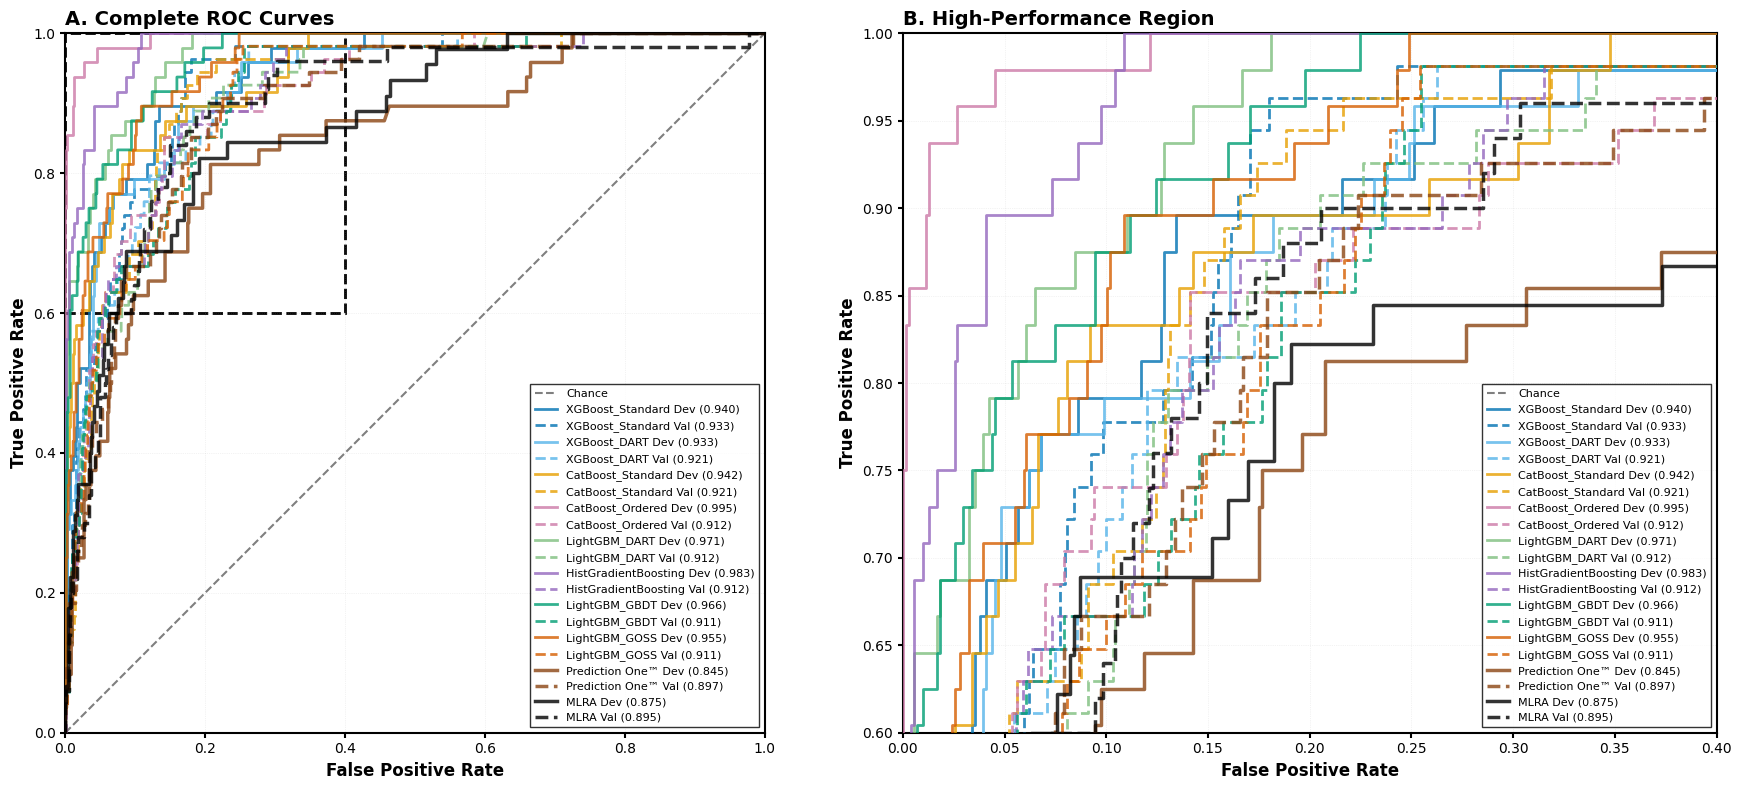

✓ Saved figure2_roc_training.jpg


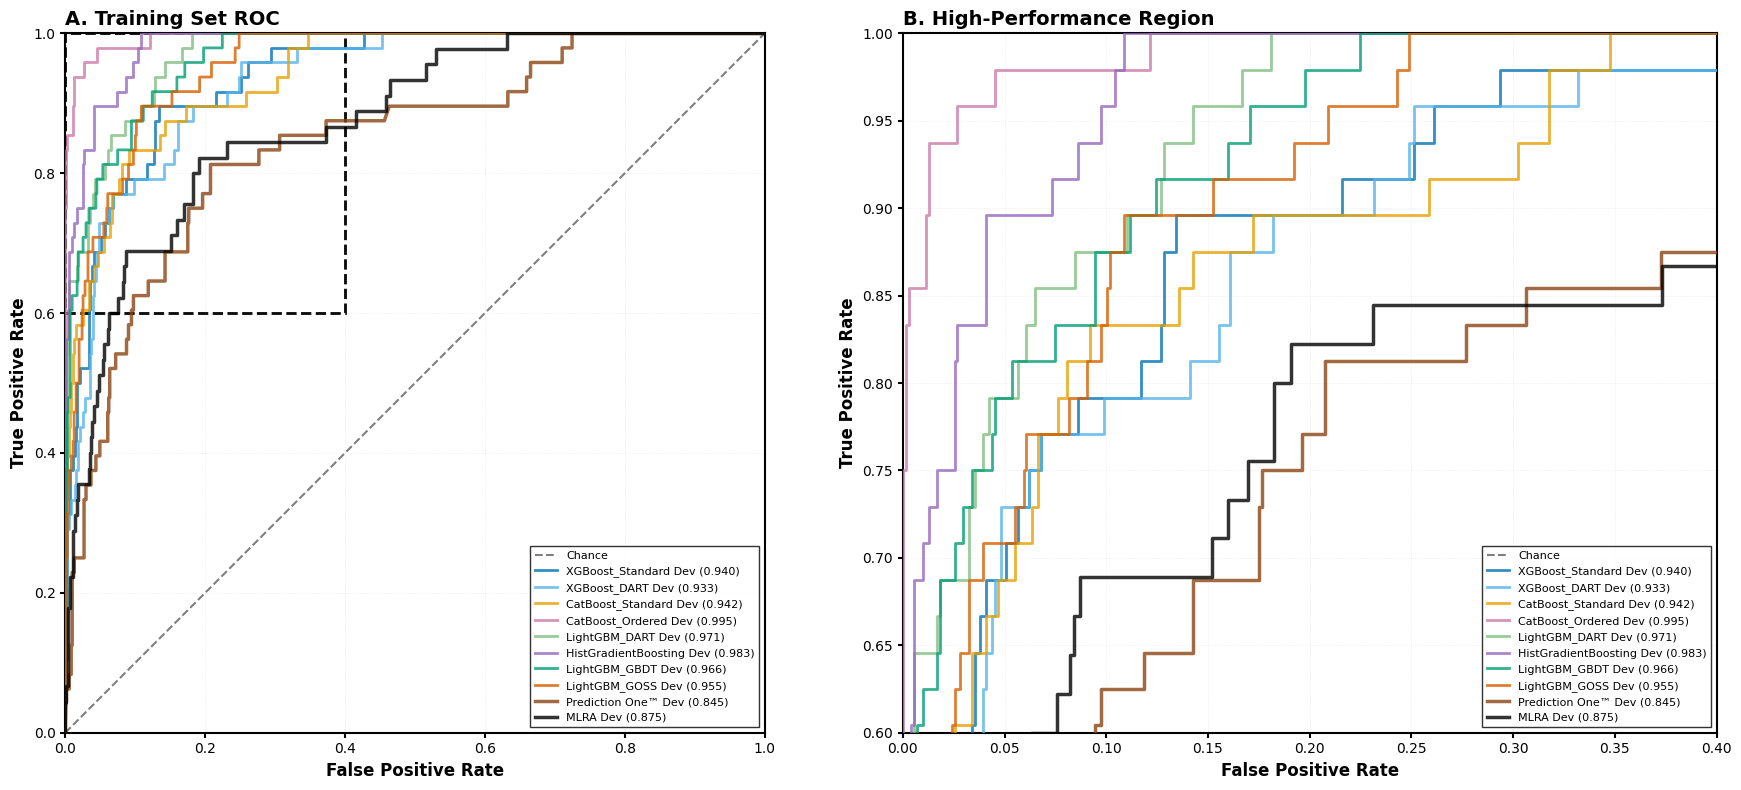

✓ Saved figure3_roc_validation.jpg


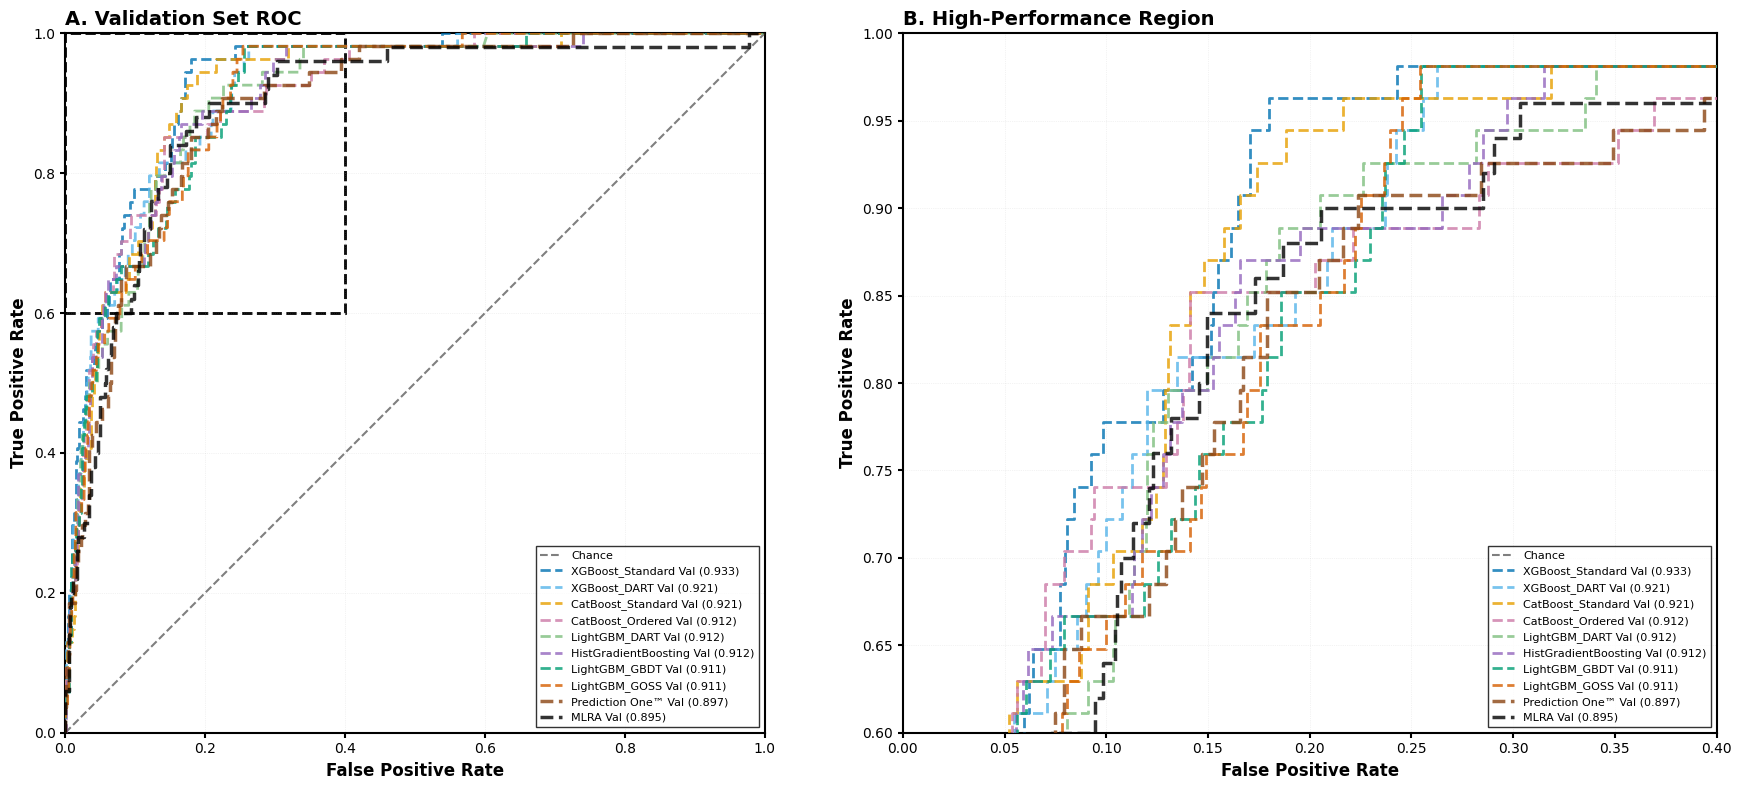


                Model  Train_AUC  Val_AUC  Difference
    XGBoost_Standard     0.9405   0.9327      0.0078
        XGBoost_DART     0.9332   0.9206      0.0126
   CatBoost_Standard     0.9421   0.9206      0.0216
    CatBoost_Ordered     0.9948   0.9125      0.0823
       LightGBM_DART     0.9705   0.9123      0.0583
HistGradientBoosting     0.9834   0.9115      0.0719
       LightGBM_GBDT     0.9662   0.9115      0.0547
       LightGBM_GOSS     0.9546   0.9109      0.0437
     Prediction One™     0.8446   0.8965     -0.0519
                MLRA     0.8753   0.8955     -0.0202


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Saved roc_curves.pptx


In [35]:
# ============================================================
# Section 9: ROC Curves — Publication-quality figures
# Three figures: (A) full+zoom combined, (B) training, (C) validation
# Resolution: 600 DPI  Format: TIFF + PNG
# ============================================================

!pip install python-pptx -q

# Publication settings
JOURNAL_DPI = 600
FS_TITLE    = 14
FS_LABEL    = 12
FS_TICK     = 10
FS_LEGEND   = 9
LW_MAIN     = 2.5
LW_SEC      = 2.0
FIG_SIZE    = (18, 8)

plt.rcParams.update({
    'font.family'      : 'sans-serif',
    'font.sans-serif'  : ['Arial', 'DejaVu Sans'],
    'font.size'        : FS_TICK,
    'axes.labelsize'   : FS_LABEL,
    'axes.titlesize'   : FS_TITLE,
    'savefig.dpi'      : JOURNAL_DPI,
    'axes.linewidth'   : 1.5,
    'grid.linewidth'   : 0.5,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
})

set_global_seed(RANDOM_STATE)

sorted_models = sorted(
    all_results.items(),
    key=lambda x: roc_auc_score(x[1]['val_true'], x[1]['val_proba']),
    reverse=True
)

roc_files = []

def _display_name(model_name: str) -> str:
    return 'Prediction One\u2122' if model_name == 'Prediction_One' else model_name

def _linewidth(model_name: str) -> float:
    return LW_MAIN if model_name in ('MLRA', 'Prediction_One') else LW_SEC

def _zorder(model_name: str) -> int:
    return 10 if model_name == 'MLRA' else (9 if model_name == 'Prediction_One' else 5)

def _plot_roc_panel(ax, models, use_train: bool, use_val: bool,
                    show_zoom: bool = False, xlim=(0, 1), ylim=(0, 1.05)):
    """Draw ROC curves onto ax."""
    ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Chance')
    for name, res in models:
        color = MODEL_COLORS.get(name, '#888888')
        lw    = _linewidth(name)
        zo    = _zorder(name)
        label = _display_name(name)
        if use_train:
            fpr, tpr, _ = roc_curve(res['train_true'], res['train_proba'])
            auc_tr       = roc_auc_score(res['train_true'], res['train_proba'])
            ax.plot(fpr, tpr, color=color, ls='-',
                    lw=lw, alpha=0.8, zorder=zo,
                    label=f'{label} Dev ({auc_tr:.3f})')
        if use_val:
            fpr, tpr, _ = roc_curve(res['val_true'], res['val_proba'])
            auc_vl       = roc_auc_score(res['val_true'], res['val_proba'])
            ax.plot(fpr, tpr, color=color, ls='--',
                    lw=lw, alpha=0.8, zorder=zo,
                    label=f'{label} Val ({auc_vl:.3f})')
    if show_zoom:
        ax.add_patch(Rectangle((0, 0.6), 0.4, 0.4, fill=False,
                                edgecolor='black', lw=2, ls='--'))
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('False Positive Rate', fontsize=FS_LABEL, fontweight='bold')
    ax.set_ylabel('True Positive Rate',  fontsize=FS_LABEL, fontweight='bold')
    ax.grid(True, alpha=0.3, ls=':', lw=0.5)
    ax.legend(loc='lower right', fontsize=FS_LEGEND - 1,
              frameon=True, fancybox=False, edgecolor='black', ncol=1)


# ── Figure 1: Full + Zoomed (training and validation) ─────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_SIZE)
_plot_roc_panel(ax1, sorted_models, use_train=True, use_val=True,
                show_zoom=True, xlim=(0, 1), ylim=(0, 1.0))
ax1.set_title('A. Complete ROC Curves', fontsize=FS_TITLE,
              fontweight='bold', loc='left')
ax1.set_aspect('equal', adjustable='box')
_plot_roc_panel(ax2, sorted_models, use_train=True, use_val=True,
                xlim=(0, 0.4), ylim=(0.6, 1.0))
ax2.set_title('B. High-Performance Region', fontsize=FS_TITLE,
              fontweight='bold', loc='left')
plt.tight_layout()
fname = 'figure1_roc_full_zoom.jpg'
plt.savefig(fname, dpi=JOURNAL_DPI, bbox_inches='tight',
            format='jpeg', pil_kwargs={'quality': 95})
roc_files.append(fname)
print(f"✓ Saved {fname}")
plt.show()
plt.close(fig)

# ── Figure 2: Training set only ───────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_SIZE)
_plot_roc_panel(ax1, sorted_models, use_train=True, use_val=False,
                show_zoom=True, xlim=(0, 1), ylim=(0, 1.0))
ax1.set_title('A. Training Set ROC', fontsize=FS_TITLE, fontweight='bold', loc='left')
ax1.set_aspect('equal', adjustable='box')
_plot_roc_panel(ax2, sorted_models, use_train=True, use_val=False,
                xlim=(0, 0.4), ylim=(0.6, 1.0))
ax2.set_title('B. High-Performance Region', fontsize=FS_TITLE, fontweight='bold', loc='left')
plt.tight_layout()
fname = 'figure2_roc_training.jpg'
plt.savefig(fname, dpi=JOURNAL_DPI, bbox_inches='tight',
            format='jpeg', pil_kwargs={'quality': 95})
roc_files.append(fname)
print(f"✓ Saved {fname}")
plt.show()
plt.close(fig)

# ── Figure 3: Validation set only ─────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_SIZE)
_plot_roc_panel(ax1, sorted_models, use_train=False, use_val=True,
                show_zoom=True, xlim=(0, 1), ylim=(0, 1.0))
ax1.set_title('A. Validation Set ROC', fontsize=FS_TITLE, fontweight='bold', loc='left')
ax1.set_aspect('equal', adjustable='box')
_plot_roc_panel(ax2, sorted_models, use_train=False, use_val=True,
                xlim=(0, 0.4), ylim=(0.6, 1.0))
ax2.set_title('B. High-Performance Region', fontsize=FS_TITLE, fontweight='bold', loc='left')
plt.tight_layout()
fname = 'figure3_roc_validation.jpg'
plt.savefig(fname, dpi=JOURNAL_DPI, bbox_inches='tight',
            format='jpeg', pil_kwargs={'quality': 95})
roc_files.append(fname)
print(f"✓ Saved {fname}")
plt.show()
plt.close(fig)

# ── AUC summary table ──────────────────────────────────────
auc_rows = sorted([
    (_display_name(n),
     roc_auc_score(r['train_true'], r['train_proba']),
     roc_auc_score(r['val_true'],   r['val_proba']))
    for n, r in all_results.items()
], key=lambda x: x[2], reverse=True)

auc_df = pd.DataFrame(auc_rows, columns=['Model', 'Train_AUC', 'Val_AUC'])
auc_df['Difference'] = auc_df['Train_AUC'] - auc_df['Val_AUC']
print("\n", auc_df.round(4).to_string(index=False))

auc_excel = 'roc_auc_summary.xlsx'
auc_df.to_excel(auc_excel, index=False)
files.download(auc_excel)

# ── PowerPoint export ─────────────────────────────────────
prs = Presentation()
slide_data = [
    ("ROC Curves — Full View and Zoomed (Training + Validation)", roc_files[0]),
    ("ROC Curves — Training Set",   roc_files[1]),
    ("ROC Curves — Validation Set", roc_files[2]),
]
for title_text, img_path in slide_data:
    sl = prs.slides.add_slide(prs.slide_layouts[5])
    sl.shapes.title.text = title_text
    sl.shapes.add_picture(img_path, Inches(0.5), Inches(1.5), Inches(9), Inches(5))
pptx_roc = 'roc_curves.pptx'
prs.save(pptx_roc)
files.download(pptx_roc)
print(f"\n✓ Saved {pptx_roc}")
# ── Verification: ROC AUC values in figures must match train_metrics_df / val_metrics_df ──


In [36]:
from IPython.display import Image as _Img22, display as _disp22
import os as _os22
# ============================================================
# Section 9: Download ROC Curve figures (JPG, 300+ DPI)
# ============================================================
import os
from google.colab import files

_roc_files = [
    'figure1_roc_full_zoom.jpg',
    'figure2_roc_training.jpg',
    'figure3_roc_validation.jpg',
]

print("Downloading ROC curve figures...")
for _fname in _roc_files:
    if os.path.exists(_fname):
        files.download(_fname)
        print(f"  ✓ Downloaded: {_fname}")
        if _fname.endswith(".jpg") and _os22.path.exists(_fname):
            _disp22(_Img22(_fname, width=900))
    else:
        print(f"  ⚠  File not found (re-run Section 9 to regenerate): {_fname}")

Output hidden; open in https://colab.research.google.com to view.

## Section 10 · Calibration Analysis

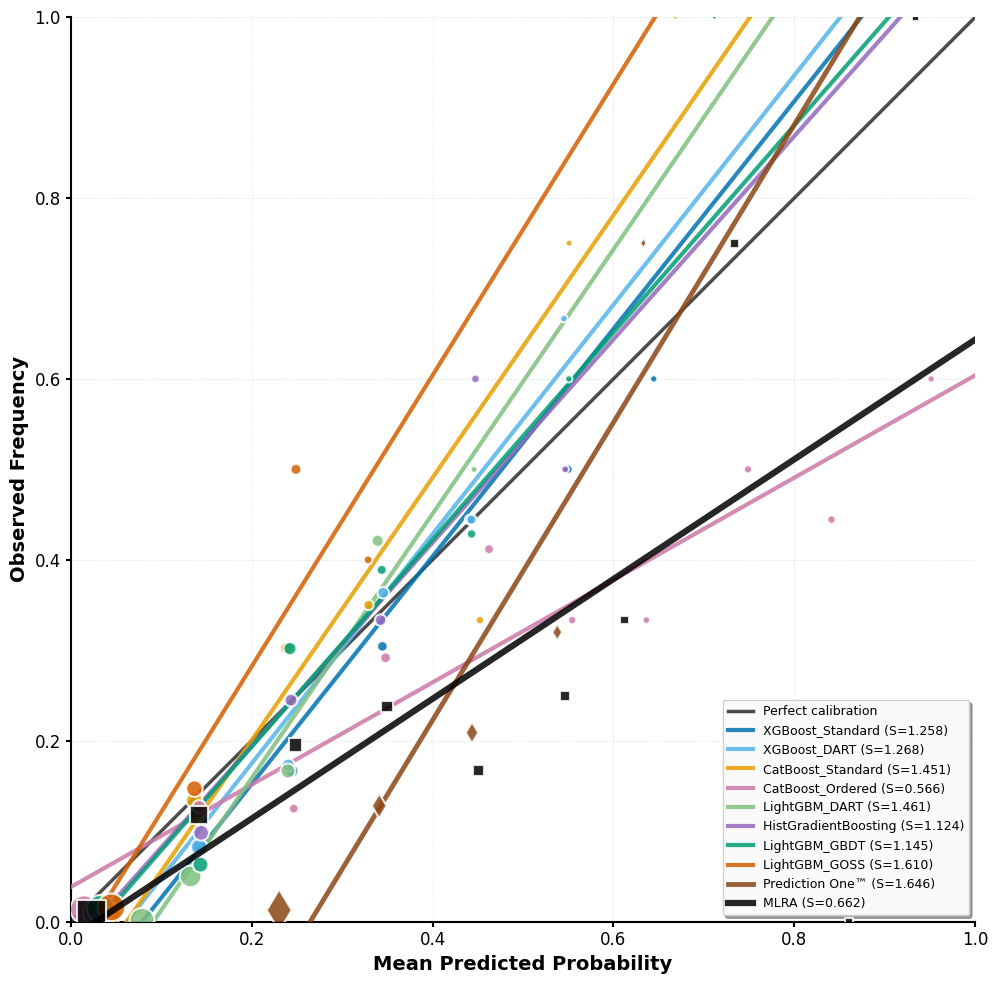

✓ Saved figure4_calibration_validation.jpg


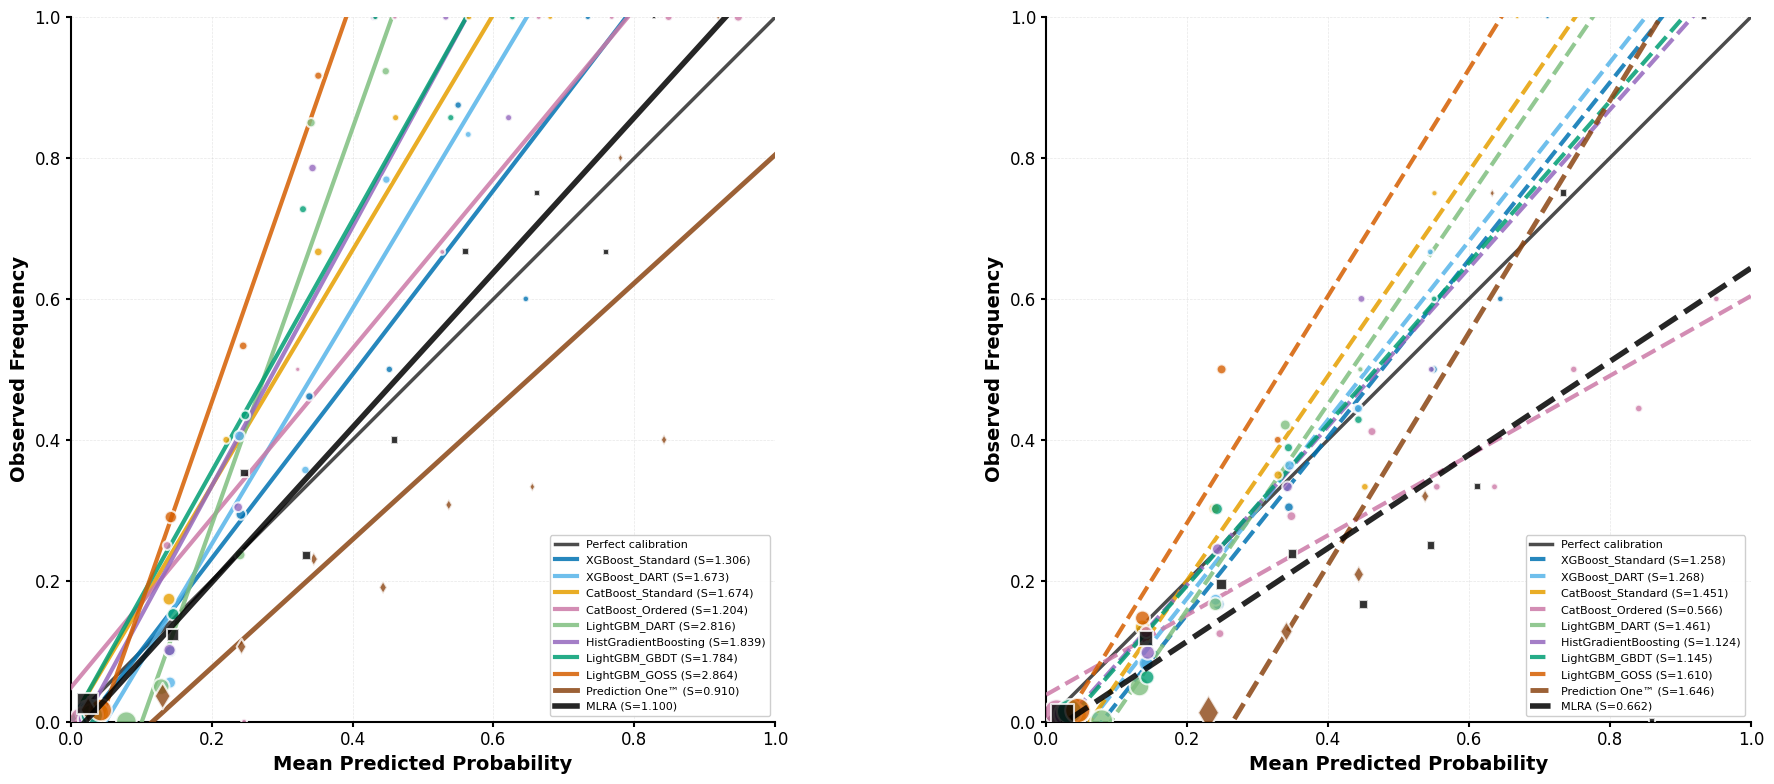

✓ Saved figure5_calibration_train_vs_val.jpg

Calibration statistics — Validation set:
               Model  Slope  Intercept  R_squared  P_value     SE
    XGBoost_Standard 1.2583    -0.0996     0.9015   0.0003 0.1093
        XGBoost_DART 1.2679    -0.0787     0.9664   0.0004 0.0508
   CatBoost_Standard 1.4512    -0.0897     0.8945   0.0013 0.1234
    CatBoost_Ordered 0.5658     0.0382     0.8980   0.0000 0.0623
       LightGBM_DART 1.4613    -0.1336     0.9655   0.0028 0.0477
HistGradientBoosting 1.1236    -0.0304     0.9035   0.0036 0.0790
       LightGBM_GBDT 1.1453    -0.0358     0.9568   0.0007 0.0522
       LightGBM_GOSS 1.6099    -0.0399     0.8080   0.1011 0.1198
     Prediction One™ 1.6465    -0.4359     0.8462   0.0269 0.1285
                MLRA 0.6620    -0.0184     0.3884   0.0542 0.2676

[Calibration Statistics — Development]


,Model,Slope,Intercept,R_squared,P_value,SE
0,XGBoost_Standard,1.306289,-0.029768,0.886522,0.000478,0.125855
1,XGBoost_DART,1.672535,-0.082710,0.924073,0.002219,0.106005
2,CatBoost_Standard,1.674432,-0.000647,0.955115,0.000147,0.092652
3,CatBoost_Ordered,1.203829,0.047965,0.785250,0.000639,0.209438
4,LightGBM_DART,2.815574,-0.284174,0.921451,0.009573,0.143337
5,HistGradientBoosting,1.839441,-0.033768,0.832720,0.004144,0.192659
6,LightGBM_GBDT,1.784203,-0.002147,0.887469,0.001504,0.148418
7,LightGBM_GOSS,2.864230,-0.120053,0.992212,0.003902,0.041284
8,Prediction One™,0.910281,-0.105573,0.752733,0.001142,0.170207
9,MLRA,1.100373,-0.022634,0.913502,0.000057,0.101179



[Calibration Statistics — Validation]


,Model,Slope,Intercept,R_squared,P_value,SE
0,XGBoost_Standard,1.258318,-0.099624,0.901455,0.000311,0.109266
1,XGBoost_DART,1.267930,-0.078742,0.966353,0.000429,0.050751
2,CatBoost_Standard,1.451181,-0.089735,0.894476,0.001278,0.123422
3,CatBoost_Ordered,0.565804,0.038240,0.898026,0.000031,0.062332
4,LightGBM_DART,1.461297,-0.133647,0.965458,0.002753,0.047747
5,HistGradientBoosting,1.123573,-0.030433,0.903456,0.003614,0.078998
6,LightGBM_GBDT,1.145272,-0.035844,0.956800,0.000710,0.052184
7,LightGBM_GOSS,1.609865,-0.039929,0.808038,0.101091,0.119757
8,Prediction One™,1.646457,-0.435929,0.846167,0.026897,0.128499
9,MLRA,0.662040,-0.018423,0.388406,0.054227,0.267572


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Calibration analysis complete


In [37]:
# ============================================================
# Section 10: Calibration Analysis (publication quality)
# Slope, intercept, R², p-value computed per model.
# ============================================================

plt.rcParams.update({
    'font.size'     : 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'legend.fontsize': 10,
})

# ── Helper: calibration curve with linear regression ──────
def compute_calibration_regression(y_true, y_proba, n_bins=10):
    """
    Compute calibration curve with linear regression fit.
    Returns: bin_centres, observed_fractions, sample_counts,
             slope, intercept, R², p-value, SE
    """
    edges = np.linspace(0, 1, n_bins + 1)
    centres, fracs, counts = [], [], []
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        mask = (y_proba >= lo) & (y_proba <= hi if i == n_bins - 1
                                              else y_proba < hi)
        if mask.sum() > 0:
            centres.append(np.mean(y_proba[mask]))
            fracs.append(np.mean(y_true[mask]))
            counts.append(mask.sum())

    centres = np.array(centres)
    fracs   = np.array(fracs)
    counts  = np.array(counts)

    if len(centres) > 1:
        lr = LinearRegression().fit(centres.reshape(-1, 1), fracs)
        slope, intercept = lr.coef_[0], lr.intercept_
        pred_lr = lr.predict(centres.reshape(-1, 1))
        ss_res  = np.sum((fracs - pred_lr) ** 2)
        ss_tot  = np.sum((fracs - fracs.mean()) ** 2)
        r2      = 1 - ss_res / ss_tot if ss_tot > 0 else 0
        n       = len(centres)
        se      = np.sqrt(ss_res / max(n - 2, 1))
        se_b    = se / np.sqrt(np.sum((centres - centres.mean()) ** 2)) if n > 2 else np.nan
        t_stat  = slope / se_b if (se_b and se_b > 0) else 0
        p_val   = 2 * (1 - stats.t.cdf(abs(t_stat), n - 2)) if n > 2 else np.nan
    else:
        slope = intercept = r2 = p_val = se = np.nan

    return centres, fracs, counts, slope, intercept, r2, p_val, se


cal_stats_train, cal_stats_val = [], []
cal_files = []

sorted_models_cal = sorted(
    all_results.items(),
    key=lambda x: roc_auc_score(x[1]['val_true'], x[1]['val_proba']),
    reverse=True
)

# ── Figure 4: Unified calibration plot (validation) ───────
fig, ax = plt.subplots(figsize=(12, 10))
ax.plot([0, 1], [0, 1], 'k-', lw=2.5, label='Perfect calibration', alpha=0.7)

def _get_arr(data):
    return data.values if hasattr(data, 'values') else np.asarray(data)

# Plot non-MLRA / non-PredOne models first, then overlay
for priority in ('other', 'Prediction_One', 'MLRA'):
    for name, res in sorted_models_cal:
        if priority == 'other' and name in ('MLRA', 'Prediction_One'):
            continue
        if priority == 'Prediction_One' and name != 'Prediction_One':
            continue
        if priority == 'MLRA' and name != 'MLRA':
            continue

        color   = MODEL_COLORS.get(name, '#888888')
        yt_val  = _get_arr(res['val_true'])
        yp_val  = np.asarray(res['val_proba'])
        bcs, tfs, scs, sl, ic, r2, pv, se = compute_calibration_regression(yt_val, yp_val)

        x_rng = np.linspace(0, 1, 100)
        lw    = 4.5 if name == 'MLRA' else (3.5 if name == 'Prediction_One' else 3)
        zo    = 10  if name == 'MLRA' else (8  if name == 'Prediction_One' else 5)
        mk    = 's' if name == 'MLRA' else ('d' if name == 'Prediction_One' else 'o')
        ms    = np.sqrt(scs) * (15 if name == 'MLRA' else (14 if name == 'Prediction_One' else 12))
        label = _display_name(name)

        ax.scatter(bcs, tfs, color=color, s=ms, alpha=0.85,
                   edgecolors='white', lw=1.5, zorder=zo, marker=mk)
        ax.plot(x_rng, sl * x_rng + ic, color=color, ls='-',
                lw=lw, alpha=0.85, zorder=zo - 1,
                label=f'{label} (S={sl:.3f})')
        cal_stats_val.append({'Model': label, 'Slope': sl, 'Intercept': ic,
                               'R_squared': r2, 'P_value': pv, 'SE': se})

ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
ax.set_xlabel('Mean Predicted Probability', fontsize=14, fontweight='bold')
ax.set_ylabel('Observed Frequency',        fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, ls='--')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='lower right', fontsize=9, framealpha=0.95,
          fancybox=True, shadow=True, ncol=1)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
f4 = 'figure4_calibration_validation.jpg'
plt.savefig(f4, dpi=300, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
cal_files.append(f4)
plt.show()
plt.close(fig)
print(f"✓ Saved {f4}")

# ── Figure 5: Training vs Validation calibration (side-by-side) ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
for ax, use_train, linestyle, stats_list in [
    (ax1, True,  '-',  cal_stats_train),
    (ax2, False, '--', []),
]:
    ax.plot([0, 1], [0, 1], 'k-', lw=2.5, label='Perfect calibration', alpha=0.7)
    for priority in ('other', 'Prediction_One', 'MLRA'):
        for name, res in sorted_models_cal:
            if priority == 'other' and name in ('MLRA', 'Prediction_One'):
                continue
            if priority == 'Prediction_One' and name != 'Prediction_One':
                continue
            if priority == 'MLRA' and name != 'MLRA':
                continue
            color = MODEL_COLORS.get(name, '#888888')
            yt = _get_arr(res['train_true'] if use_train else res['val_true'])
            yp = np.asarray(res['train_proba'] if use_train else res['val_proba'])
            bcs, tfs, scs, sl, ic, r2, pv, se = compute_calibration_regression(yt, yp)
            x_rng = np.linspace(0, 1, 100)
            lw    = 4   if name == 'MLRA' else (3.5 if name == 'Prediction_One' else 3)
            zo    = 10  if name == 'MLRA' else (8  if name == 'Prediction_One' else 5)
            mk    = 's' if name == 'MLRA' else ('d' if name == 'Prediction_One' else 'o')
            ms    = np.sqrt(scs) * 10
            label = _display_name(name)
            ax.scatter(bcs, tfs, color=color, s=ms, alpha=0.8,
                       edgecolors='white', lw=1.5, zorder=zo, marker=mk)
            ax.plot(x_rng, sl * x_rng + ic, color=color, ls=linestyle,
                    lw=lw, alpha=0.85, zorder=zo - 1,
                    label=f'{label} (S={sl:.3f})')
            if use_train:
                stats_list.append({'Model': label, 'Slope': sl, 'Intercept': ic,
                                    'R_squared': r2, 'P_value': pv, 'SE': se})
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
    ax.set_xlabel('Mean Predicted Probability', fontsize=14, fontweight='bold')
    ax.set_ylabel('Observed Frequency',        fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, ls='--')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(loc='lower right', fontsize=8, framealpha=0.95, ncol=1)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.tight_layout()
f5 = 'figure5_calibration_train_vs_val.jpg'
plt.savefig(f5, dpi=300, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
cal_files.append(f5)
plt.show()
plt.close(fig)
print(f"✓ Saved {f5}")

# Print and export statistics
cal_train_df = pd.DataFrame(cal_stats_train)
cal_val_df   = pd.DataFrame(cal_stats_val)
print("\nCalibration statistics — Validation set:")
print(cal_val_df.round(4).to_string(index=False))
from IPython.display import display as _disp24
print('\n[Calibration Statistics — Development]')
_disp24(cal_train_df)
print('\n[Calibration Statistics — Validation]')
_disp24(cal_val_df)

cal_excel = 'calibration_statistics.xlsx'
with pd.ExcelWriter(cal_excel, engine='openpyxl') as writer:
    cal_train_df.to_excel(writer, sheet_name='Training',   index=False)
    cal_val_df.to_excel(  writer, sheet_name='Validation', index=False)
files.download(cal_excel)
for f in cal_files:
    files.download(f)
print("\n✓ Calibration analysis complete")
# ── Verification: Calibration slopes for each model must match original ──


In [38]:
# ============================================================
# Table 5: Calibration Slope Analysis — Manuscript Format
# Prerequisite: Cell 23 (cal_train_df, cal_val_df in memory)
# Columns: Model, Slope, Intercept, R², P-value, SE
# ============================================================
import pandas as pd
from google.colab import files

def _format_table5(df: pd.DataFrame) -> pd.DataFrame:
    """Reformat calibration stats DataFrame into manuscript Table 5 layout."""
    out = pd.DataFrame()
    out['Model']     = df['Model']
    out['Slope']     = df['Slope'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['Intercept'] = df['Intercept'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['R²']        = df['R_squared'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['P-value']   = df['P_value'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'N/A')
    out['SE']        = df['SE'].map(lambda x: f"{x:.4f}" if pd.notna(x) else 'N/A')
    return out

print("=" * 70)
print("Table 5: Calibration Slope Analysis")
print("=" * 70)

t5_dev = _format_table5(cal_train_df)
t5_val = _format_table5(cal_val_df)

print("\n[Development Cohort]")
print(t5_dev.to_string(index=False))
print("\n[Validation Cohort]")
print(t5_val.to_string(index=False))

TABLE5_XLSX = 'Table_5_Calibration_Slope_Analysis.xlsx'
from IPython.display import display as _disp25
print("\n[Table 5 — Development Cohort]")
_disp25(t5_dev)
print("\n[Table 5 — Validation Cohort]")
_disp25(t5_val)
with pd.ExcelWriter(TABLE5_XLSX, engine='openpyxl') as writer:
    t5_dev.to_excel(writer, sheet_name='Development', index=False)
    t5_val.to_excel(writer, sheet_name='Validation',  index=False)

files.download(TABLE5_XLSX)
print(f"\n✓ Downloaded: {TABLE5_XLSX}")
# Verification: Slope values must match Figure 4/5 legend annotations in Cell 23.

Table 5: Calibration Slope Analysis

[Development Cohort]
               Model Slope Intercept    R² P-value     SE
    XGBoost_Standard 1.306    -0.030 0.887   0.000 0.1259
        XGBoost_DART 1.673    -0.083 0.924   0.002 0.1060
   CatBoost_Standard 1.674    -0.001 0.955   0.000 0.0927
    CatBoost_Ordered 1.204     0.048 0.785   0.001 0.2094
       LightGBM_DART 2.816    -0.284 0.921   0.010 0.1433
HistGradientBoosting 1.839    -0.034 0.833   0.004 0.1927
       LightGBM_GBDT 1.784    -0.002 0.887   0.002 0.1484
       LightGBM_GOSS 2.864    -0.120 0.992   0.004 0.0413
     Prediction One™ 0.910    -0.106 0.753   0.001 0.1702
                MLRA 1.100    -0.023 0.914   0.000 0.1012

[Validation Cohort]
               Model Slope Intercept    R² P-value     SE
    XGBoost_Standard 1.258    -0.100 0.901   0.000 0.1093
        XGBoost_DART 1.268    -0.079 0.966   0.000 0.0508
   CatBoost_Standard 1.451    -0.090 0.894   0.001 0.1234
    CatBoost_Ordered 0.566     0.038 0.898   0.000 

,Model,Slope,Intercept,R²,P-value,SE
0,XGBoost_Standard,1.306,-0.030,0.887,0.000,0.1259
1,XGBoost_DART,1.673,-0.083,0.924,0.002,0.1060
2,CatBoost_Standard,1.674,-0.001,0.955,0.000,0.0927
3,CatBoost_Ordered,1.204,0.048,0.785,0.001,0.2094
4,LightGBM_DART,2.816,-0.284,0.921,0.010,0.1433
5,HistGradientBoosting,1.839,-0.034,0.833,0.004,0.1927
6,LightGBM_GBDT,1.784,-0.002,0.887,0.002,0.1484
7,LightGBM_GOSS,2.864,-0.120,0.992,0.004,0.0413
8,Prediction One™,0.910,-0.106,0.753,0.001,0.1702
9,MLRA,1.100,-0.023,0.914,0.000,0.1012



[Table 5 — Validation Cohort]


,Model,Slope,Intercept,R²,P-value,SE
0,XGBoost_Standard,1.258,-0.100,0.901,0.000,0.1093
1,XGBoost_DART,1.268,-0.079,0.966,0.000,0.0508
2,CatBoost_Standard,1.451,-0.090,0.894,0.001,0.1234
3,CatBoost_Ordered,0.566,0.038,0.898,0.000,0.0623
4,LightGBM_DART,1.461,-0.134,0.965,0.003,0.0477
5,HistGradientBoosting,1.124,-0.030,0.903,0.004,0.0790
6,LightGBM_GBDT,1.145,-0.036,0.957,0.001,0.0522
7,LightGBM_GOSS,1.610,-0.040,0.808,0.101,0.1198
8,Prediction One™,1.646,-0.436,0.846,0.027,0.1285
9,MLRA,0.662,-0.018,0.388,0.054,0.2676


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Downloaded: Table_5_Calibration_Slope_Analysis.xlsx


## Table S12 · Calibration and Classification Performance — Selected Gradient Boosting Models (Validation Cohort)

In [40]:
# ============================================================
# Table S12: Calibration and Classification Performance of
#            Selected Gradient Boosting Models — Validation Cohort
# Prerequisite: Cell 18 (train_metrics_df, val_metrics_df)
#               Cell 24 (cal_val_df) must be in memory.
# Columns: Model | AUC-ROC (95% CI) | ΔAUC (Dev–Val) | Sensitivity |
#          Specificity | F1-score | Calibration slope | Brier score | H-L P
# Models: All ML gradient-boosting models (excludes MLRA & Prediction One)
# Sort order: Validation AUC descending
# ============================================================
from IPython.display import display as _disp
import pandas as pd, numpy as np
from google.colab import files as _files

# Display name mapping (internal key → publication name)
_GB_KEYS = [
    'XGBoost_Standard', 'XGBoost_DART',
    'LightGBM_GBDT', 'LightGBM_DART', 'LightGBM_GOSS',
    'CatBoost_Standard', 'CatBoost_Ordered',
    'HistGradientBoosting',
]
_DNAME = {
    'XGBoost_Standard'    : 'XGBoost Standard',
    'XGBoost_DART'        : 'XGBoost DART',
    'LightGBM_GBDT'       : 'LightGBM GBDT',
    'LightGBM_DART'       : 'LightGBM DART',
    'LightGBM_GOSS'       : 'LightGBM GOSS',
    'CatBoost_Standard'   : 'CatBoost Standard',
    'CatBoost_Ordered'    : 'CatBoost Ordered',
    'HistGradientBoosting': 'HistGradientBoosting',
}

def _lookup_metrics(df, key):
    """Return row from a metrics DataFrame matching model key or display name."""
    pub = _DNAME.get(key, key)
    for _, row in df.iterrows():
        rname = row['Model'].replace(' ', '_')
        if rname == key or row['Model'] == pub:
            return row
    return None

def _hl_fmt(v):
    if pd.isna(v): return 'N/A'
    return '<0.001' if v < 0.001 else f'{v:.4f}'

print('=' * 70)
print('Table S12: Calibration and Classification Performance')
print('           Selected Gradient Boosting Models — Validation Cohort')
print('=' * 70)

rows_s12 = []
for key in _GB_KEYS:
    pub  = _DNAME.get(key, key)
    rdev = _lookup_metrics(train_metrics_df, key)
    rval = _lookup_metrics(val_metrics_df,   key)
    rcal = _lookup_metrics(cal_val_df,       key)

    if rval is None:
        print(f'  ⚠  {pub}: not found in val_metrics_df — skipped')
        continue

    val_auc  = rval['AUC_ROC']
    val_cilo = rval['AUC_95CI_Lower']
    val_cihi = rval['AUC_95CI_Upper']
    dev_auc  = rdev['AUC_ROC'] if rdev is not None else np.nan
    delta    = dev_auc - val_auc if (pd.notna(dev_auc) and pd.notna(val_auc)) else np.nan
    slope    = rcal['Slope'] if rcal is not None else np.nan

    rows_s12.append({
        'Model'            : pub,
        'AUC-ROC (95% CI)' : (f"{val_auc:.3f} ({val_cilo:.3f}\u2013{val_cihi:.3f})"
                               if pd.notna(val_auc) else 'N/A'),
        'ΔAUC (Dev–Val)'   : (f'{delta:+.3f}' if pd.notna(delta) else 'N/A'),
        'Sensitivity'      : (f"{rval['Sensitivity']:.3f}" if pd.notna(rval.get('Sensitivity')) else 'N/A'),
        'Specificity'      : (f"{rval['Specificity']:.3f}" if pd.notna(rval.get('Specificity')) else 'N/A'),
        'F1-score'         : (f"{rval['F1_Score']:.3f}" if pd.notna(rval.get('F1_Score')) else 'N/A'),
        'Calibration slope': (f'{slope:.3f}' if pd.notna(slope) else 'N/A'),
        'Brier score'      : (f"{rval['Brier_Score']:.3f}" if pd.notna(rval.get('Brier_Score')) else 'N/A'),
        'H-L P'            : _hl_fmt(rval.get('HL_P_value', np.nan)),
    })

df_s12 = pd.DataFrame(rows_s12)
# Sort by validation AUC descending
df_s12['_sort'] = df_s12['AUC-ROC (95% CI)'].apply(
    lambda x: float(x.split(' ')[0]) if x != 'N/A' else 0.0)
df_s12 = df_s12.sort_values('_sort', ascending=False).drop(columns=['_sort']).reset_index(drop=True)

print('\n')
_disp(df_s12)

S12_XLSX = 'Table_S12_Calibration_Classification_Gradient_Boosting_Validation.xlsx'
with pd.ExcelWriter(S12_XLSX, engine='openpyxl') as writer:
    df_s12.to_excel(writer, sheet_name='Table_S12', index=False)
print(f'\n\u2713 Saved: {S12_XLSX}')
_files.download(S12_XLSX)

# [Reproducibility] AUC-ROC values must match Section 8 (val_metrics_df).
# ΔAUC = Dev AUC − Val AUC; positive = external performance drop.
# Calibration slope ~ 1.0 = ideal; values from cal_val_df (Section 10).
# H-L P < 0.05 = significant miscalibration.


Table S12: Calibration and Classification Performance
           Selected Gradient Boosting Models — Validation Cohort




,Model,AUC-ROC (95% CI),ΔAUC (Dev–Val),Sensitivity,Specificity,F1-score,Calibration slope,Brier score,H-L P
0,XGBoost Standard,0.933 (0.907–0.958),+0.008,0.963,0.820,0.325,1.258,0.032,0.0296
1,XGBoost DART,0.921 (0.892–0.950),+0.013,0.981,0.738,0.253,1.268,0.033,0.0047
2,CatBoost Standard,0.921 (0.890–0.951),+0.022,0.944,0.812,0.310,1.451,0.034,<0.001
3,LightGBM DART,0.912 (0.881–0.943),+0.058,0.889,0.815,0.298,1.461,0.040,<0.001
4,HistGradientBoosting,0.912 (0.877–0.946),+0.072,0.870,0.834,0.315,1.124,0.034,0.0227
5,CatBoost Ordered,0.912 (0.879–0.946),+0.082,0.852,0.859,0.343,0.566,0.036,0.1342
6,LightGBM GBDT,0.911 (0.879–0.944),+0.055,0.981,0.745,0.259,1.145,0.034,0.0013
7,LightGBM GOSS,0.911 (0.881–0.941),+0.044,0.981,0.746,0.259,1.610,0.036,<0.001



✓ Saved: Table_S12_Calibration_Classification_Gradient_Boosting_Validation.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 11 · Decision Curve Analysis (DCA)

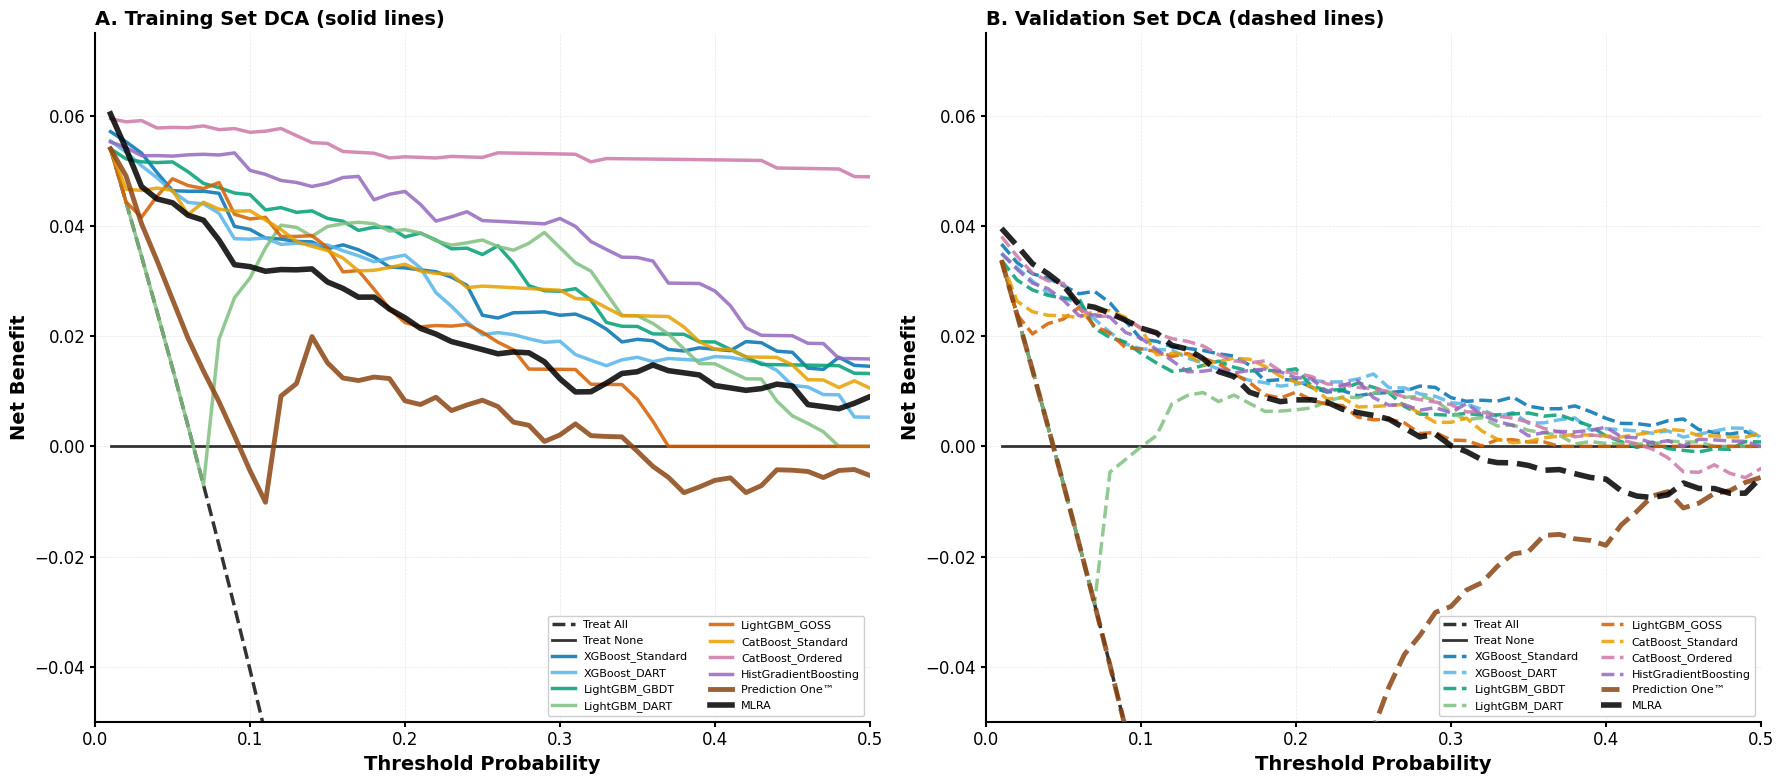

✓ Saved figure6_dca_train_vs_val.jpg


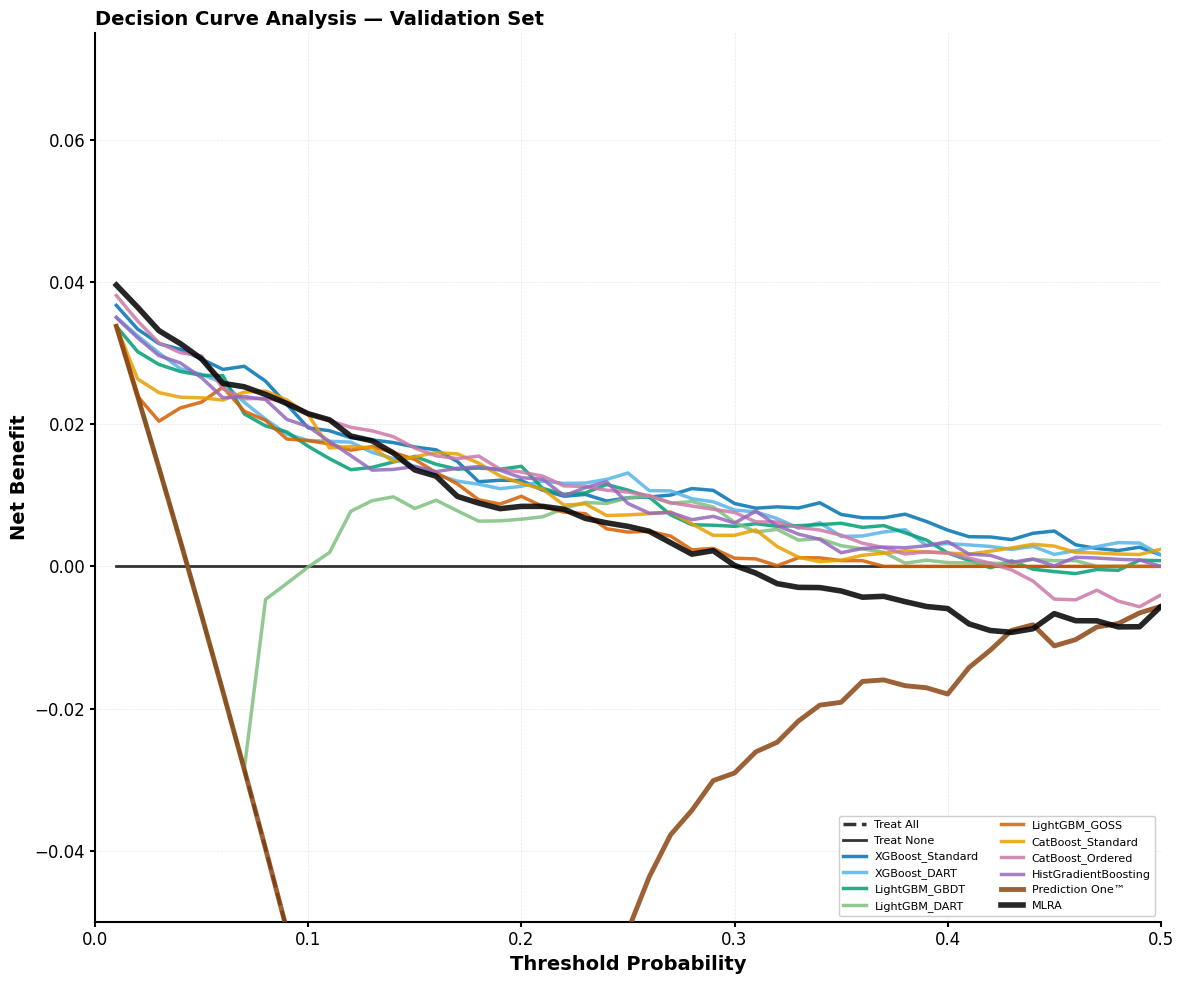

✓ Saved figure7_dca_validation.jpg

Net benefit at key thresholds (validation):
 Threshold  Treat_All  Treat_None   MLRA  XGBoost_Standard  XGBoost_DART  LightGBM_GBDT  LightGBM_DART  LightGBM_GOSS  CatBoost_Standard  CatBoost_Ordered  HistGradientBoosting  Prediction One™
      0.10    -0.0628         0.0 0.0215            0.0195        0.0177         0.0169        -0.0001         0.0177             0.0214            0.0215                0.0197          -0.0628
      0.15    -0.1254         0.0 0.0136            0.0168        0.0141         0.0155         0.0081         0.0150             0.0154            0.0167                0.0141          -0.1254
      0.20    -0.1957         0.0 0.0084            0.0121        0.0113         0.0141         0.0066         0.0099             0.0117            0.0133                0.0125          -0.1957
      0.25    -0.2754         0.0 0.0056            0.0097        0.0131         0.0107         0.0097         0.0048             0.0072        

,Threshold,Treat_All,Treat_None,MLRA,XGBoost_Standard,XGBoost_DART,LightGBM_GBDT,LightGBM_DART,LightGBM_GOSS,CatBoost_Standard,CatBoost_Ordered,HistGradientBoosting,Prediction One™
0,0.10,-0.062841,0.0,0.021472,0.019487,0.017699,0.016895,-0.000089,0.017699,0.021364,0.021543,0.019666,-0.062841
1,0.15,-0.125361,0.0,0.013575,0.016800,0.014055,0.015475,0.008140,0.015049,0.015428,0.016658,0.014055,-0.125361
2,0.20,-0.195696,0.0,0.008443,0.012068,0.011263,0.014079,0.006637,0.009855,0.011665,0.013274,0.012470,-0.195696
3,0.25,-0.275409,0.0,0.005629,0.009654,0.013140,0.010727,0.009654,0.004827,0.007241,0.010459,0.008850,-0.051220
4,0.30,-0.366510,0.0,0.000134,0.008850,0.007930,0.005632,0.006206,0.001149,0.004367,0.007585,0.006091,-0.029077


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ DCA complete


In [41]:
# ============================================================
# Section 11: Decision Curve Analysis (DCA)
# ============================================================

def calculate_net_benefit(y_true, y_proba, threshold_prob: float) -> float:
    """
    Compute net benefit at a single threshold probability.

    NB = TP/n − FP/n × (pt / (1 − pt))
    """
    y_true  = np.asarray(y_true,  dtype=float)
    y_proba = np.asarray(y_proba, dtype=float)
    min_len = min(len(y_true), len(y_proba))
    y_true  = y_true[:min_len];  y_proba = y_proba[:min_len]
    mask    = ~(np.isnan(y_true) | np.isnan(y_proba))
    y_true  = y_true[mask];      y_proba = y_proba[mask]
    if len(y_true) == 0 or threshold_prob >= 1.0:
        return 0.0
    n   = len(y_true)
    pp  = y_proba >= threshold_prob
    tp  = np.sum(pp & (y_true == 1))
    fp  = np.sum(pp & (y_true == 0))
    return (tp / n) - (fp / n) * (threshold_prob / (1.0 - threshold_prob))


THRESHOLDS = np.arange(0.01, 0.99, 0.01)

def _compute_dca(results_dict, dataset: str) -> dict:
    """Compute net benefit curves for all models."""
    dca = {}
    base_name = sorted(results_dict.keys())[0]
    base_true = _get_arr(results_dict[base_name][f'{dataset}_true'])
    prev = np.mean(base_true)

    dca['Treat All'] = [
        prev - (1 - prev) * (t / (1 - t)) if t < 1.0 else 0.0
        for t in THRESHOLDS
    ]
    dca['Treat None'] = [0.0] * len(THRESHOLDS)

    for name, res in results_dict.items():
        yt = _get_arr(res[f'{dataset}_true'])
        yp = np.asarray(res[f'{dataset}_proba'])
        dca[name] = [calculate_net_benefit(yt, yp, t) for t in THRESHOLDS]
    return dca


dca_train = _compute_dca(all_results, 'train')
dca_val   = _compute_dca(all_results, 'val')

def _plot_dca_panel(ax, dca: dict, linestyle: str, title: str):
    ax.plot(THRESHOLDS, dca['Treat All'], 'k--', lw=2.5, alpha=0.8, label='Treat All')
    ax.plot(THRESHOLDS, dca['Treat None'], 'k-', lw=2.0, alpha=0.8, label='Treat None')
    for priority in ('other', 'Prediction_One', 'MLRA'):
        for name in dca:
            if name in ('Treat All', 'Treat None'):
                continue
            if priority == 'other' and name in ('MLRA', 'Prediction_One'):
                continue
            if priority == 'Prediction_One' and name != 'Prediction_One':
                continue
            if priority == 'MLRA' and name != 'MLRA':
                continue
            color = MODEL_COLORS.get(name, '#888888')
            lw    = 4 if name == 'MLRA' else (3.5 if name == 'Prediction_One' else 2.5)
            zo    = 10 if name == 'MLRA' else (8 if name == 'Prediction_One' else 5)
            ax.plot(THRESHOLDS, dca[name], color=color,
                    lw=lw, ls=linestyle, alpha=0.85, zorder=zo,
                    label=_display_name(name))
    ax.set_xlim([0, 0.5]); ax.set_ylim([-0.05, 0.075])
    ax.set_xlabel('Threshold Probability', fontsize=14, fontweight='bold')
    ax.set_ylabel('Net Benefit',           fontsize=14, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.3, ls='--')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    ax.legend(loc='lower right', fontsize=8, framealpha=0.95, ncol=2)


dca_files = []

# Figure 6: Training + Validation side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
_plot_dca_panel(ax1, dca_train, '-',  'A. Training Set DCA (solid lines)')
_plot_dca_panel(ax2, dca_val,   '--', 'B. Validation Set DCA (dashed lines)')
plt.tight_layout()
f6 = 'figure6_dca_train_vs_val.jpg'
plt.savefig(f6, dpi=300, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
dca_files.append(f6)
plt.show()
plt.close(fig)
print(f"✓ Saved {f6}")

# Figure 7: Validation set only
fig, ax = plt.subplots(figsize=(12, 10))
_plot_dca_panel(ax, dca_val, '-', 'Decision Curve Analysis — Validation Set')
plt.tight_layout()
f7 = 'figure7_dca_validation.jpg'
plt.savefig(f7, dpi=300, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
dca_files.append(f7)
plt.show()
plt.close(fig)
print(f"✓ Saved {f7}")

# Net benefit at key thresholds
key_thresholds = [0.10, 0.15, 0.20, 0.25, 0.30]
dca_rows = []
for t in key_thresholds:
    idx = np.argmin(np.abs(THRESHOLDS - t))
    row = {'Threshold': t,
           'Treat_All' : dca_val['Treat All'][idx],
           'Treat_None': dca_val['Treat None'][idx]}
    for name in all_results:
        if name in dca_val:
            row[_display_name(name)] = dca_val[name][idx]
    dca_rows.append(row)
dca_stats_df = pd.DataFrame(dca_rows)
print("\nNet benefit at key thresholds (validation):")
print(dca_stats_df.round(4).to_string(index=False))
from IPython.display import display as _disp29
print('\n[Decision Curve Statistics]')
_disp29(dca_stats_df)

dca_excel = 'decision_curve_statistics.xlsx'
dca_stats_df.to_excel(dca_excel, index=False)
files.download(dca_excel)
for f in dca_files:
    files.download(f)
print("\n✓ DCA complete")
# ── Verification: Net benefit values at threshold 0.20 must match original ──


In [42]:
# ============================================================
# Table 6: Net Benefit Values — Decision Curve Analysis
#           External Temporal Validation Cohort
# [FIXED] What was wrong: dca_val['Treat All'] was computed using
#   CatBoost_Ordered's val_true (full validation N≈1,243) as the
#   prevalence denominator, while MLRA net benefit is computed on
#   the complete-case subset (N=1,066). This creates an inconsistent
#   reference strategy denominator across models.
# [FIXED] What was changed: 'Treat All' is recomputed here using
#   MLRA's val_true prevalence (N=1,066, Events=50) so that all
#   models and the reference strategy share the same denominator.
#   This is consistent with Sections 15/20 (Fairness Analysis).
# ============================================================
import pandas as pd
import numpy as np
from google.colab import files

# ── Recompute Treat All using MLRA complete-case prevalence ────────────
_mlra_val_true_arr = (
    mlra_results['val_true'].values
    if hasattr(mlra_results['val_true'], 'values')
    else np.array(mlra_results['val_true'])
)
_prev_mlra = float(np.mean(_mlra_val_true_arr))
_n_mlra    = len(_mlra_val_true_arr)
_ev_mlra   = int(np.sum(_mlra_val_true_arr))

print(f"Treat All — MLRA complete-case cohort:")
print(f"  N={_n_mlra}, Events={_ev_mlra}, prevalence={_prev_mlra:.5f}")

# Recompute Treat All at each threshold using MLRA prevalence
_treat_all_corrected = np.array([
    _prev_mlra - (1.0 - _prev_mlra) * (t / (1.0 - t))
    if t < 1.0 else 0.0
    for t in THRESHOLDS
])

# ── Display-name mapping ────────────────────────────────────────────────
_MODEL_DISPLAY = {
    'MLRA'                 : 'MLRA',
    'XGBoost_Standard'     : 'XGBoost Standard',
    'XGBoost_DART'         : 'XGBoost DART',
    'LightGBM_GBDT'        : 'LightGBM GBDT',
    'LightGBM_DART'        : 'LightGBM DART',
    'LightGBM_GOSS'        : 'LightGBM GOSS',
    'CatBoost_Standard'    : 'CatBoost Standard',
    'CatBoost_Ordered'     : 'CatBoost Ordered',
    'HistGradientBoosting' : 'HistGradientBoosting',
    'Prediction_One'       : 'Prediction One\u2122',
}

# ── Build Table 6 (clinically relevant thresholds 0.05–0.50) ───────────
_key_thresholds = np.round(np.arange(0.05, 0.51, 0.05), 2)

rows = []
for t in _key_thresholds:
    idx = int(np.argmin(np.abs(THRESHOLDS - t)))
    row = {'Threshold Probability': f"{t:.2f}"}

    for internal_key, display_name in _MODEL_DISPLAY.items():
        if internal_key in dca_val:
            val = dca_val[internal_key][idx]
            row[display_name] = f"{val:.4f}" if not np.isnan(val) else 'N/A'
        else:
            row[display_name] = 'N/A'

    # [FIXED] Use MLRA-prevalence-based Treat All
    row['Treat All']  = f"{_treat_all_corrected[idx]:.4f}"
    row['Treat None'] = '0.0000'
    rows.append(row)

t6_df = pd.DataFrame(rows)

print("\n" + "=" * 70)
print("Table 6: Net Benefit Values — DCA (Validation, Treat All corrected)")
print("=" * 70)
print(t6_df.to_string(index=False))
from IPython.display import display as _disp30
_disp30(t6_df)

# ── Cross-check against docx reference values ──────────────────────────
_ref = {0.10: -0.0590, 0.15: -0.1213, 0.20: -0.1914, 0.25: -0.2708, 0.30: -0.3616}
print("\n[Verification] Treat All cross-check vs docx reference:")
for t_chk, ref_val in _ref.items():
    idx_chk = int(np.argmin(np.abs(THRESHOLDS - t_chk)))
    calc    = _treat_all_corrected[idx_chk]
    match   = "✓" if abs(calc - ref_val) < 0.0005 else "✗"
    print(f"  t={t_chk:.2f}: calculated={calc:.4f}  docx={ref_val:.4f}  {match}")

TABLE6_XLSX = ('Table_6_Net_Benefit_Values_from_Decision_Curve_Analysis'
               '_in_External_Temporal_Validation.xlsx')
t6_df.to_excel(TABLE6_XLSX, index=False, sheet_name='Validation_DCA')
files.download(TABLE6_XLSX)
print(f"\n✓ Downloaded: {TABLE6_XLSX}")
# Verification: Treat All at t=0.10 should be ≈ −0.0590 (MLRA N=1,066)
# NOT −0.0628 (full validation N=1,243)

Treat All — MLRA complete-case cohort:
  N=1066, Events=50, prevalence=0.04690

Table 6: Net Benefit Values — DCA (Validation, Treat All corrected)
Threshold Probability    MLRA XGBoost Standard XGBoost DART LightGBM GBDT LightGBM DART LightGBM GOSS CatBoost Standard CatBoost Ordered HistGradientBoosting Prediction One™ Treat All Treat None
                 0.05  0.0292           0.0292       0.0270        0.0269       -0.0069        0.0231            0.0237           0.0296               0.0265         -0.0069   -0.0033     0.0000
                 0.10  0.0215           0.0195       0.0177        0.0169       -0.0001        0.0177            0.0214           0.0215               0.0197         -0.0628   -0.0590     0.0000
                 0.15  0.0136           0.0168       0.0141        0.0155        0.0081        0.0150            0.0154           0.0167               0.0141         -0.1254   -0.1213     0.0000
                 0.20  0.0084           0.0121       0.0113        0.014

,Threshold Probability,MLRA,XGBoost Standard,XGBoost DART,LightGBM GBDT,LightGBM DART,LightGBM GOSS,CatBoost Standard,CatBoost Ordered,HistGradientBoosting,Prediction One™,Treat All,Treat None
0,0.05,0.0292,0.0292,0.0270,0.0269,-0.0069,0.0231,0.0237,0.0296,0.0265,-0.0069,-0.0033,0.0000
1,0.10,0.0215,0.0195,0.0177,0.0169,-0.0001,0.0177,0.0214,0.0215,0.0197,-0.0628,-0.0590,0.0000
2,0.15,0.0136,0.0168,0.0141,0.0155,0.0081,0.0150,0.0154,0.0167,0.0141,-0.1254,-0.1213,0.0000
3,0.20,0.0084,0.0121,0.0113,0.0141,0.0066,0.0099,0.0117,0.0133,0.0125,-0.1957,-0.1914,0.0000
4,0.25,0.0056,0.0097,0.0131,0.0107,0.0097,0.0048,0.0072,0.0105,0.0088,-0.0512,-0.2708,0.0000
5,0.30,0.0001,0.0088,0.0079,0.0056,0.0062,0.0011,0.0044,0.0076,0.0061,-0.0291,-0.3616,0.0000
6,0.35,-0.0035,0.0073,0.0042,0.0061,0.0029,0.0008,0.0009,0.0044,0.0019,-0.0191,-0.4663,0.0000
7,0.40,-0.0059,0.0051,0.0032,0.0019,0.0005,0.0000,0.0019,0.0019,0.0035,-0.0180,-0.5885,0.0000
8,0.45,-0.0067,0.0050,0.0017,-0.0007,0.0008,0.0000,0.0029,-0.0046,0.0001,-0.0112,-0.7329,0.0000
9,0.50,-0.0056,0.0016,0.0016,0.0008,0.0000,0.0000,0.0024,-0.0040,0.0000,-0.0056,-0.9062,0.0000



[Verification] Treat All cross-check vs docx reference:
  t=0.10: calculated=-0.0590  docx=-0.0590  ✓
  t=0.15: calculated=-0.1213  docx=-0.1213  ✓
  t=0.20: calculated=-0.1914  docx=-0.1914  ✓
  t=0.25: calculated=-0.2708  docx=-0.2708  ✓
  t=0.30: calculated=-0.3616  docx=-0.3616  ✓


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Downloaded: Table_6_Net_Benefit_Values_from_Decision_Curve_Analysis_in_External_Temporal_Validation.xlsx


Section DCA-Extended: XGBoost Standard vs MLRA
✓ mlra_results, ml_results, train_df, val_df are available

✓ Sample sizes confirmed
  Development — MLRA: 664  | XGBoost (aligned): 664
  Validation  — MLRA: 1066  | XGBoost (aligned): 1066

✓ Saved: Figure_DCA_XGBoost_Standard_vs_MLRA_Dev_Val.jpg


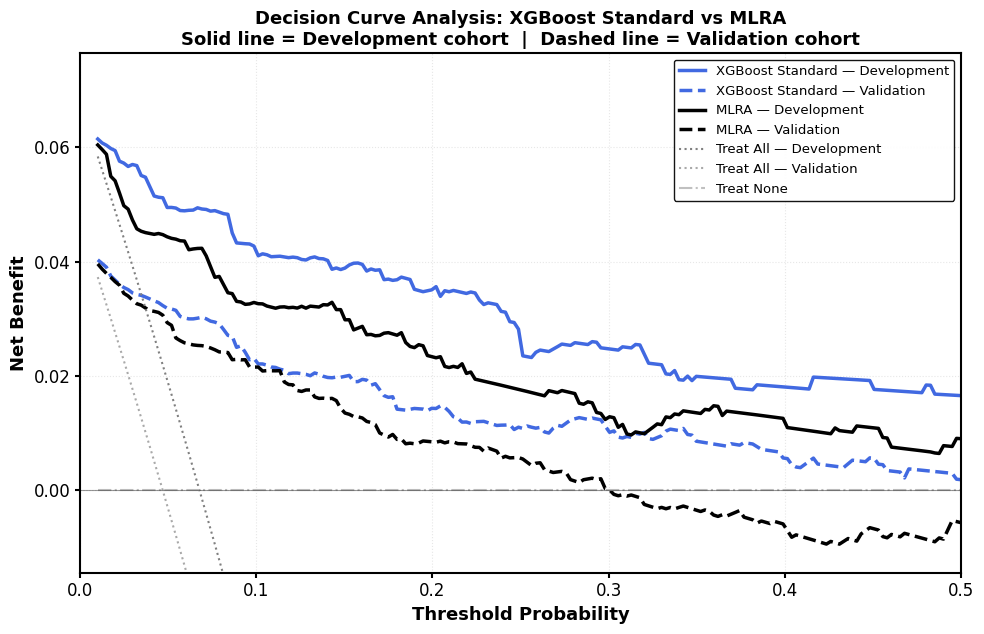

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✓ Downloaded: Figure_DCA_XGBoost_Standard_vs_MLRA_Dev_Val.jpg

Net Benefit at threshold = 0.10:
  XGBoost Dev  : 0.0410
  XGBoost Val  : 0.0221
  MLRA Dev     : 0.0326
  MLRA Val     : 0.0216


In [43]:
# =============================================================================
# Section DCA-Extended: Figure — DCA Comparison
#   XGBoost Standard (Blue) vs MLRA (Black)
#   Development cohort: solid line  |  Validation cohort: dashed line
#   Resolution: 600 DPI  |  Format: PNG + TIFF
# =============================================================================
# [FIXED] NameError: train_xgb_proba / train_mlra_proba not defined
#   → All predictions are reconstructed from mlra_results and ml_results
#     which persist throughout the notebook session.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files as colab_files

# ─── Prerequisites check ──────────────────────────────────────────────────────
print("=" * 70)
print("Section DCA-Extended: XGBoost Standard vs MLRA")
print("=" * 70)

try:
    _ = mlra_results
    _ = ml_results
    _ = train_df   # raw training dataframe (defined in Data Loading section)
    _ = val_df     # raw validation dataframe
    print("✓ mlra_results, ml_results, train_df, val_df are available")
except NameError as e:
    raise RuntimeError(
        f"❌ Required variable not found: {e}\n"
        "Run the Data Loading and Model Training sections first."
    )

# ─── Reconstruct predictions from stored results ──────────────────────────────
# MLRA
_mlra_train_proba = mlra_results['train_proba']
_mlra_val_proba   = mlra_results['val_proba']
_mlra_train_true  = mlra_results['train_true']
_mlra_val_true    = mlra_results['val_true']

# XGBoost Standard
_xgb_train_proba = ml_results['XGBoost_Standard']['train_proba']
_xgb_val_proba   = ml_results['XGBoost_Standard']['val_proba']
_xgb_train_true  = ml_results['XGBoost_Standard']['train_true']
_xgb_val_true    = ml_results['XGBoost_Standard']['val_true']

# Resolve index for MLRA complete-case alignment
# MLRA uses listwise deletion → its index is a subset of the raw index
if hasattr(_mlra_train_true, 'index'):
    _mlra_dev_idx = _mlra_train_true.index
else:
    _mlra_dev_idx = pd.RangeIndex(len(_mlra_train_true))

if hasattr(_mlra_val_true, 'index'):
    _mlra_val_idx = _mlra_val_true.index
else:
    _mlra_val_idx = pd.RangeIndex(len(_mlra_val_true))

# ─── Align XGBoost predictions to MLRA complete-case indices ──────────────────
# Development cohort
if hasattr(_xgb_train_true, 'index'):
    _xgb_dev_series = pd.Series(
        _xgb_train_proba
        if not hasattr(_xgb_train_proba, 'values')
        else _xgb_train_proba.values,
        index=_xgb_train_true.index
    )
else:
    _xgb_dev_series = pd.Series(
        _xgb_train_proba
        if not hasattr(_xgb_train_proba, 'values')
        else _xgb_train_proba.values
    )

# Validation cohort
if hasattr(_xgb_val_true, 'index'):
    _xgb_val_series = pd.Series(
        _xgb_val_proba
        if not hasattr(_xgb_val_proba, 'values')
        else _xgb_val_proba.values,
        index=_xgb_val_true.index
    )
else:
    _xgb_val_series = pd.Series(
        _xgb_val_proba
        if not hasattr(_xgb_val_proba, 'values')
        else _xgb_val_proba.values
    )

# Restrict XGBoost to MLRA indices (valid paired comparison)
try:
    _xgb_dev_aligned = _xgb_dev_series.loc[_mlra_dev_idx].values
    _xgb_val_aligned = _xgb_val_series.loc[_mlra_val_idx].values
except KeyError:
    # Fallback: indices don't match → use as-is (same length assumed)
    print("⚠  Index alignment failed; using predictions as-is.")
    _xgb_dev_aligned = np.array(_xgb_train_proba
                                 if not hasattr(_xgb_train_proba, 'values')
                                 else _xgb_train_proba.values)
    _xgb_val_aligned = np.array(_xgb_val_proba
                                 if not hasattr(_xgb_val_proba, 'values')
                                 else _xgb_val_proba.values)

# Ground-truth outcomes (MLRA cohort)
_y_dev = (np.array(_mlra_train_true.values
                    if hasattr(_mlra_train_true, 'values')
                    else _mlra_train_true)).astype(int)
_y_val = (np.array(_mlra_val_true.values
                    if hasattr(_mlra_val_true, 'values')
                    else _mlra_val_true)).astype(int)

# MLRA probabilities aligned to same index
_mlra_dev_proba_arr = (np.array(_mlra_train_proba.values
                                 if hasattr(_mlra_train_proba, 'values')
                                 else _mlra_train_proba))
_mlra_val_proba_arr = (np.array(_mlra_val_proba.values
                                 if hasattr(_mlra_val_proba, 'values')
                                 else _mlra_val_proba))

print(f"\n✓ Sample sizes confirmed")
print(f"  Development — MLRA: {len(_y_dev)}  "
      f"| XGBoost (aligned): {len(_xgb_dev_aligned)}")
print(f"  Validation  — MLRA: {len(_y_val)}  "
      f"| XGBoost (aligned): {len(_xgb_val_aligned)}")

# ─── Net Benefit functions ────────────────────────────────────────────────────
def compute_net_benefit(y_true, y_prob, thresholds):
    """
    Net Benefit = (TP/N) - (FP/N) × pt/(1−pt)
    Reference: Vickers & Elkin, Med Decis Making 2006; 26(6):565-574
    """
    y_true = np.array(y_true, dtype=int)
    y_prob = np.array(y_prob, dtype=float)
    n      = len(y_true)
    nb     = np.full(len(thresholds), np.nan)
    for i, pt in enumerate(thresholds):
        if pt <= 0 or pt >= 1:
            continue
        y_pred = (y_prob >= pt).astype(int)
        tp = int(np.sum((y_pred == 1) & (y_true == 1)))
        fp = int(np.sum((y_pred == 1) & (y_true == 0)))
        nb[i] = (tp / n) - (fp / n) * (pt / (1.0 - pt))
    return nb


def compute_treat_all(y_true, thresholds):
    """Net benefit of the 'treat all' strategy."""
    y_true = np.array(y_true, dtype=int)
    n      = len(y_true)
    prev   = y_true.mean()
    nb     = np.full(len(thresholds), np.nan)
    for i, pt in enumerate(thresholds):
        if pt <= 0 or pt >= 1:
            continue
        nb[i] = prev - (1.0 - prev) * (pt / (1.0 - pt))
    return nb

# ─── Threshold grid ───────────────────────────────────────────────────────────
_thresholds = np.linspace(0.01, 0.50, 200)

# ─── Compute net benefit ──────────────────────────────────────────────────────
_nb_xgb_dev  = compute_net_benefit(_y_dev, _xgb_dev_aligned,  _thresholds)
_nb_xgb_val  = compute_net_benefit(_y_val, _xgb_val_aligned,  _thresholds)
_nb_mlra_dev = compute_net_benefit(_y_dev, _mlra_dev_proba_arr, _thresholds)
_nb_mlra_val = compute_net_benefit(_y_val, _mlra_val_proba_arr, _thresholds)

_nb_treat_all_dev = compute_treat_all(_y_dev, _thresholds)
_nb_treat_all_val = compute_treat_all(_y_val, _thresholds)
_nb_treat_none    = np.zeros(len(_thresholds))

# ─── Plot ─────────────────────────────────────────────────────────────────────
# [FIXED] TIFF removed; replaced with JPG (300+ DPI)
_DCA_FIG_PNG  = 'Figure_DCA_XGBoost_Standard_vs_MLRA_Dev_Val.jpg'

fig_dca, ax_dca = plt.subplots(figsize=(10, 6.5))

# XGBoost Standard (Blue)
ax_dca.plot(_thresholds, _nb_xgb_dev,
            color='royalblue', linewidth=2.5, linestyle='-',
            label='XGBoost Standard — Development')
ax_dca.plot(_thresholds, _nb_xgb_val,
            color='royalblue', linewidth=2.5, linestyle='--',
            label='XGBoost Standard — Validation')

# MLRA (Black)
ax_dca.plot(_thresholds, _nb_mlra_dev,
            color='black', linewidth=2.5, linestyle='-',
            label='MLRA — Development')
ax_dca.plot(_thresholds, _nb_mlra_val,
            color='black', linewidth=2.5, linestyle='--',
            label='MLRA — Validation')

# Reference strategies
ax_dca.plot(_thresholds, _nb_treat_all_dev,
            color='gray', linewidth=1.5, linestyle=':',
            label='Treat All — Development')
ax_dca.plot(_thresholds, _nb_treat_all_val,
            color='darkgray', linewidth=1.5, linestyle=':',
            label='Treat All — Validation')
ax_dca.plot(_thresholds, _nb_treat_none,
            color='silver', linewidth=1.5, linestyle='-.',
            label='Treat None')

# Axis limits
_all_nb = np.concatenate([
    _nb_xgb_dev[~np.isnan(_nb_xgb_dev)],
    _nb_xgb_val[~np.isnan(_nb_xgb_val)],
    _nb_mlra_dev[~np.isnan(_nb_mlra_dev)],
    _nb_mlra_val[~np.isnan(_nb_mlra_val)],
])
ax_dca.set_xlim(0.0, 0.50)
ax_dca.set_ylim(
    min(-0.01, _all_nb.min() - 0.005),
    _all_nb.max() + 0.015,
)

ax_dca.set_xlabel('Threshold Probability', fontsize=13, fontweight='bold')
ax_dca.set_ylabel('Net Benefit',           fontsize=13, fontweight='bold')
ax_dca.set_title(
    'Decision Curve Analysis: XGBoost Standard vs MLRA\n'
    'Solid line = Development cohort  |  Dashed line = Validation cohort',
    fontsize=13, fontweight='bold',
)
ax_dca.axhline(y=0, color='black', linewidth=0.8, alpha=0.4)
ax_dca.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)
ax_dca.legend(loc='upper right', fontsize=9.5,
              framealpha=0.92, edgecolor='black', frameon=True)

plt.tight_layout()

# ─── Save ─────────────────────────────────────────────────────────────────────
fig_dca.savefig(_DCA_FIG_PNG, dpi=600, bbox_inches='tight', facecolor='white',
                format='jpeg', pil_kwargs={'quality': 95})
print(f"\n✓ Saved: {_DCA_FIG_PNG}")
plt.show()

# ─── Download ─────────────────────────────────────────────────────────────────
print("\nDownloading DCA figures...")
for _fpath in [_DCA_FIG_PNG]:
    if os.path.exists(_fpath):
        try:
            colab_files.download(_fpath)
            print(f"  ✓ Downloaded: {_fpath}")
        except Exception as _e:
            print(f"  ⚠  Failed: {_fpath} — {_e}")
    else:
        print(f"  ✗ Not found: {_fpath}")

# ─── Reproducibility checkpoint ───────────────────────────────────────────────
_idx_010 = np.argmin(np.abs(_thresholds - 0.10))
print(f"\nNet Benefit at threshold = 0.10:")
print(f"  XGBoost Dev  : {_nb_xgb_dev[_idx_010]:.4f}")
print(f"  XGBoost Val  : {_nb_xgb_val[_idx_010]:.4f}")
print(f"  MLRA Dev     : {_nb_mlra_dev[_idx_010]:.4f}")
print(f"  MLRA Val     : {_nb_mlra_val[_idx_010]:.4f}")
# ── Values should be identical across re-runs (deterministic calculation) ──

## Section 12 · SHAP Analysis (Top-3 Models by Validation AUC)

Top-3 models for SHAP: ['XGBoost_Standard', 'XGBoost_DART', 'CatBoost_Standard']
  Computing SHAP for XGBoost_Standard...
    ✓ Shape: (1243, 43)
  Computing SHAP for XGBoost_DART...
    ✓ Shape: (1243, 43)
  Computing SHAP for CatBoost_Standard...
    ✓ Shape: (1243, 43)


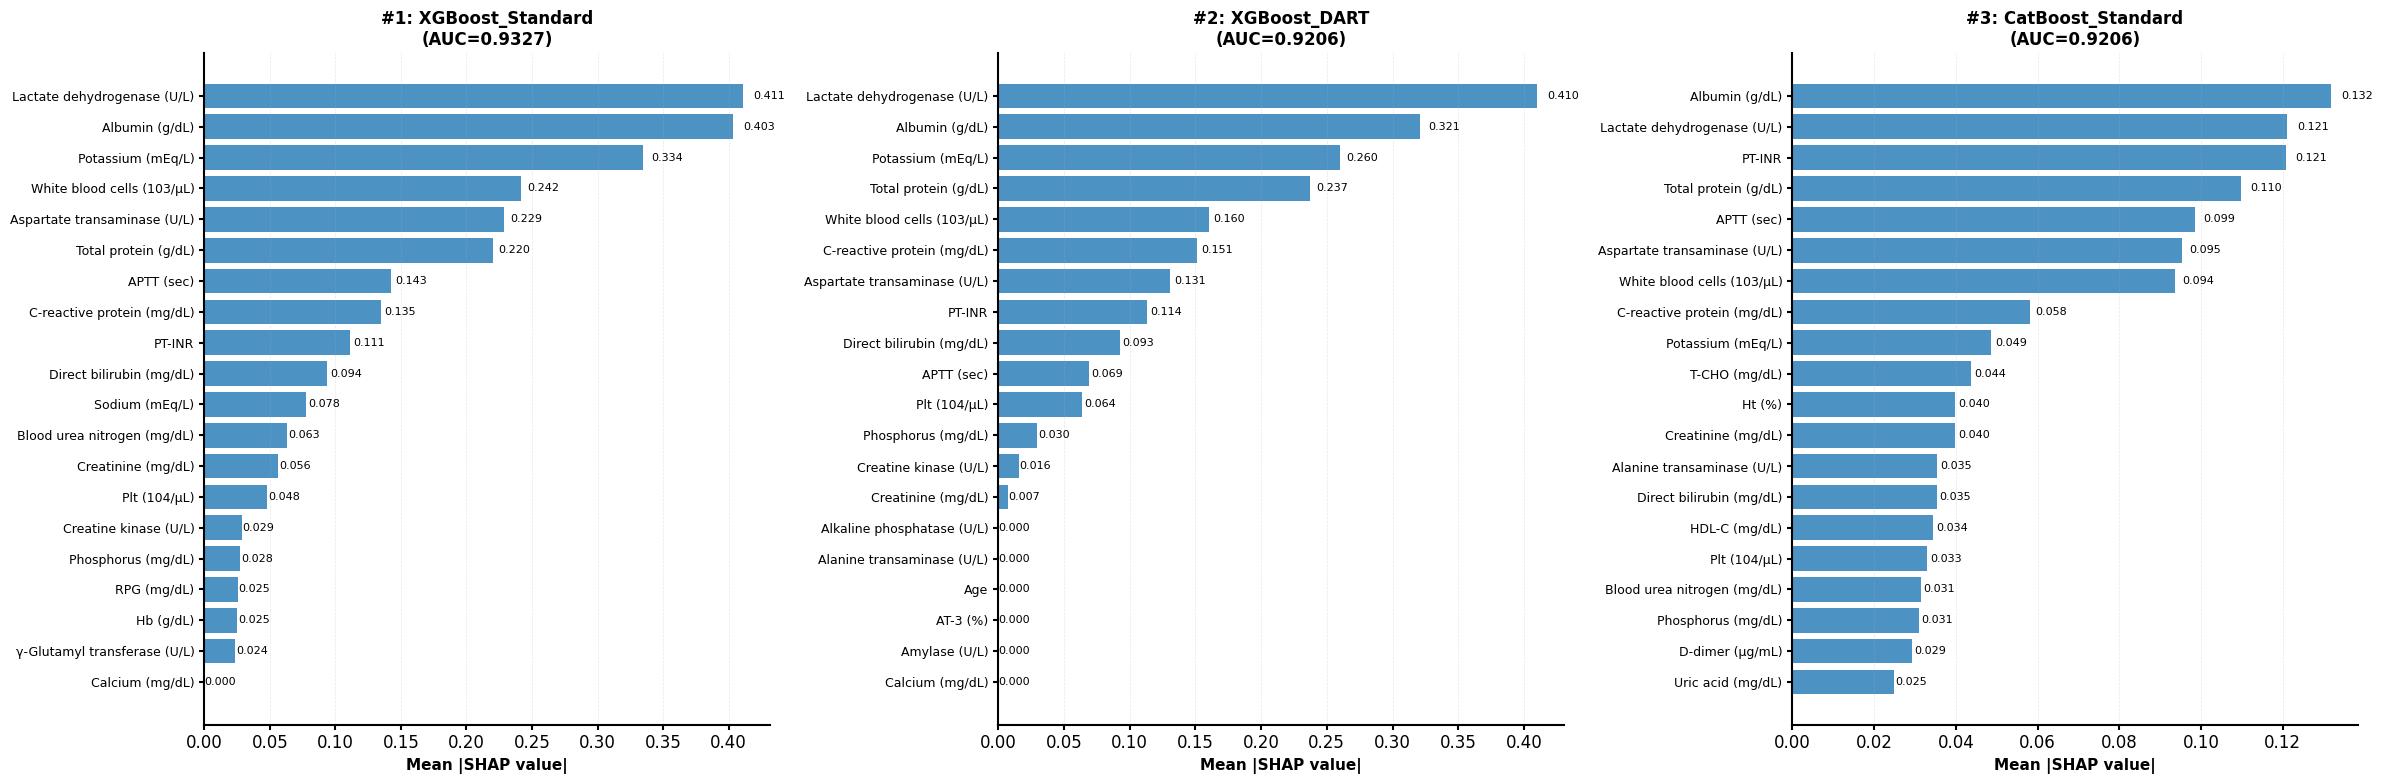

✓ Saved figure8_shap_bar_top3.jpg


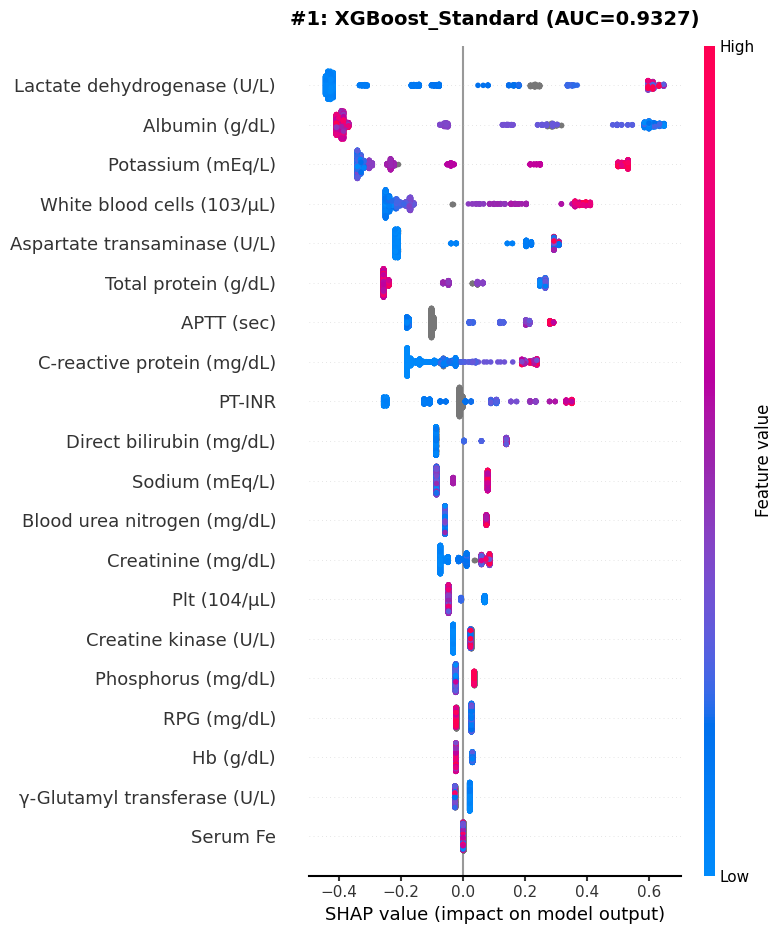

✓ Saved figure9A_shap_beeswarm_XGBoost_Standard.jpg


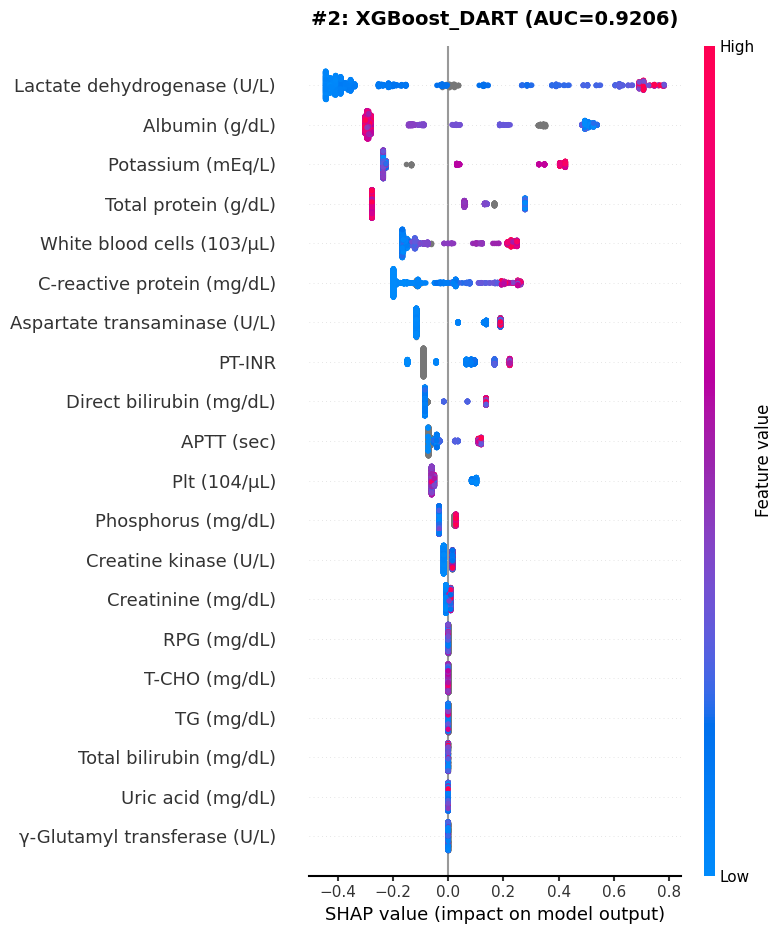

✓ Saved figure9B_shap_beeswarm_XGBoost_DART.jpg


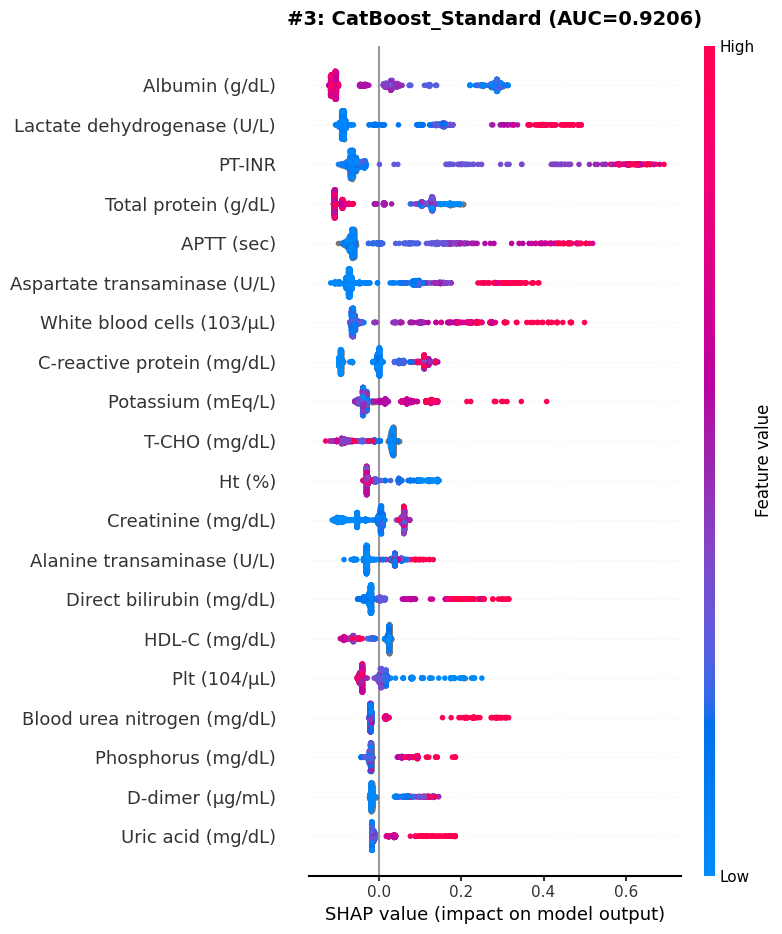

✓ Saved figure9C_shap_beeswarm_CatBoost_Standard.jpg


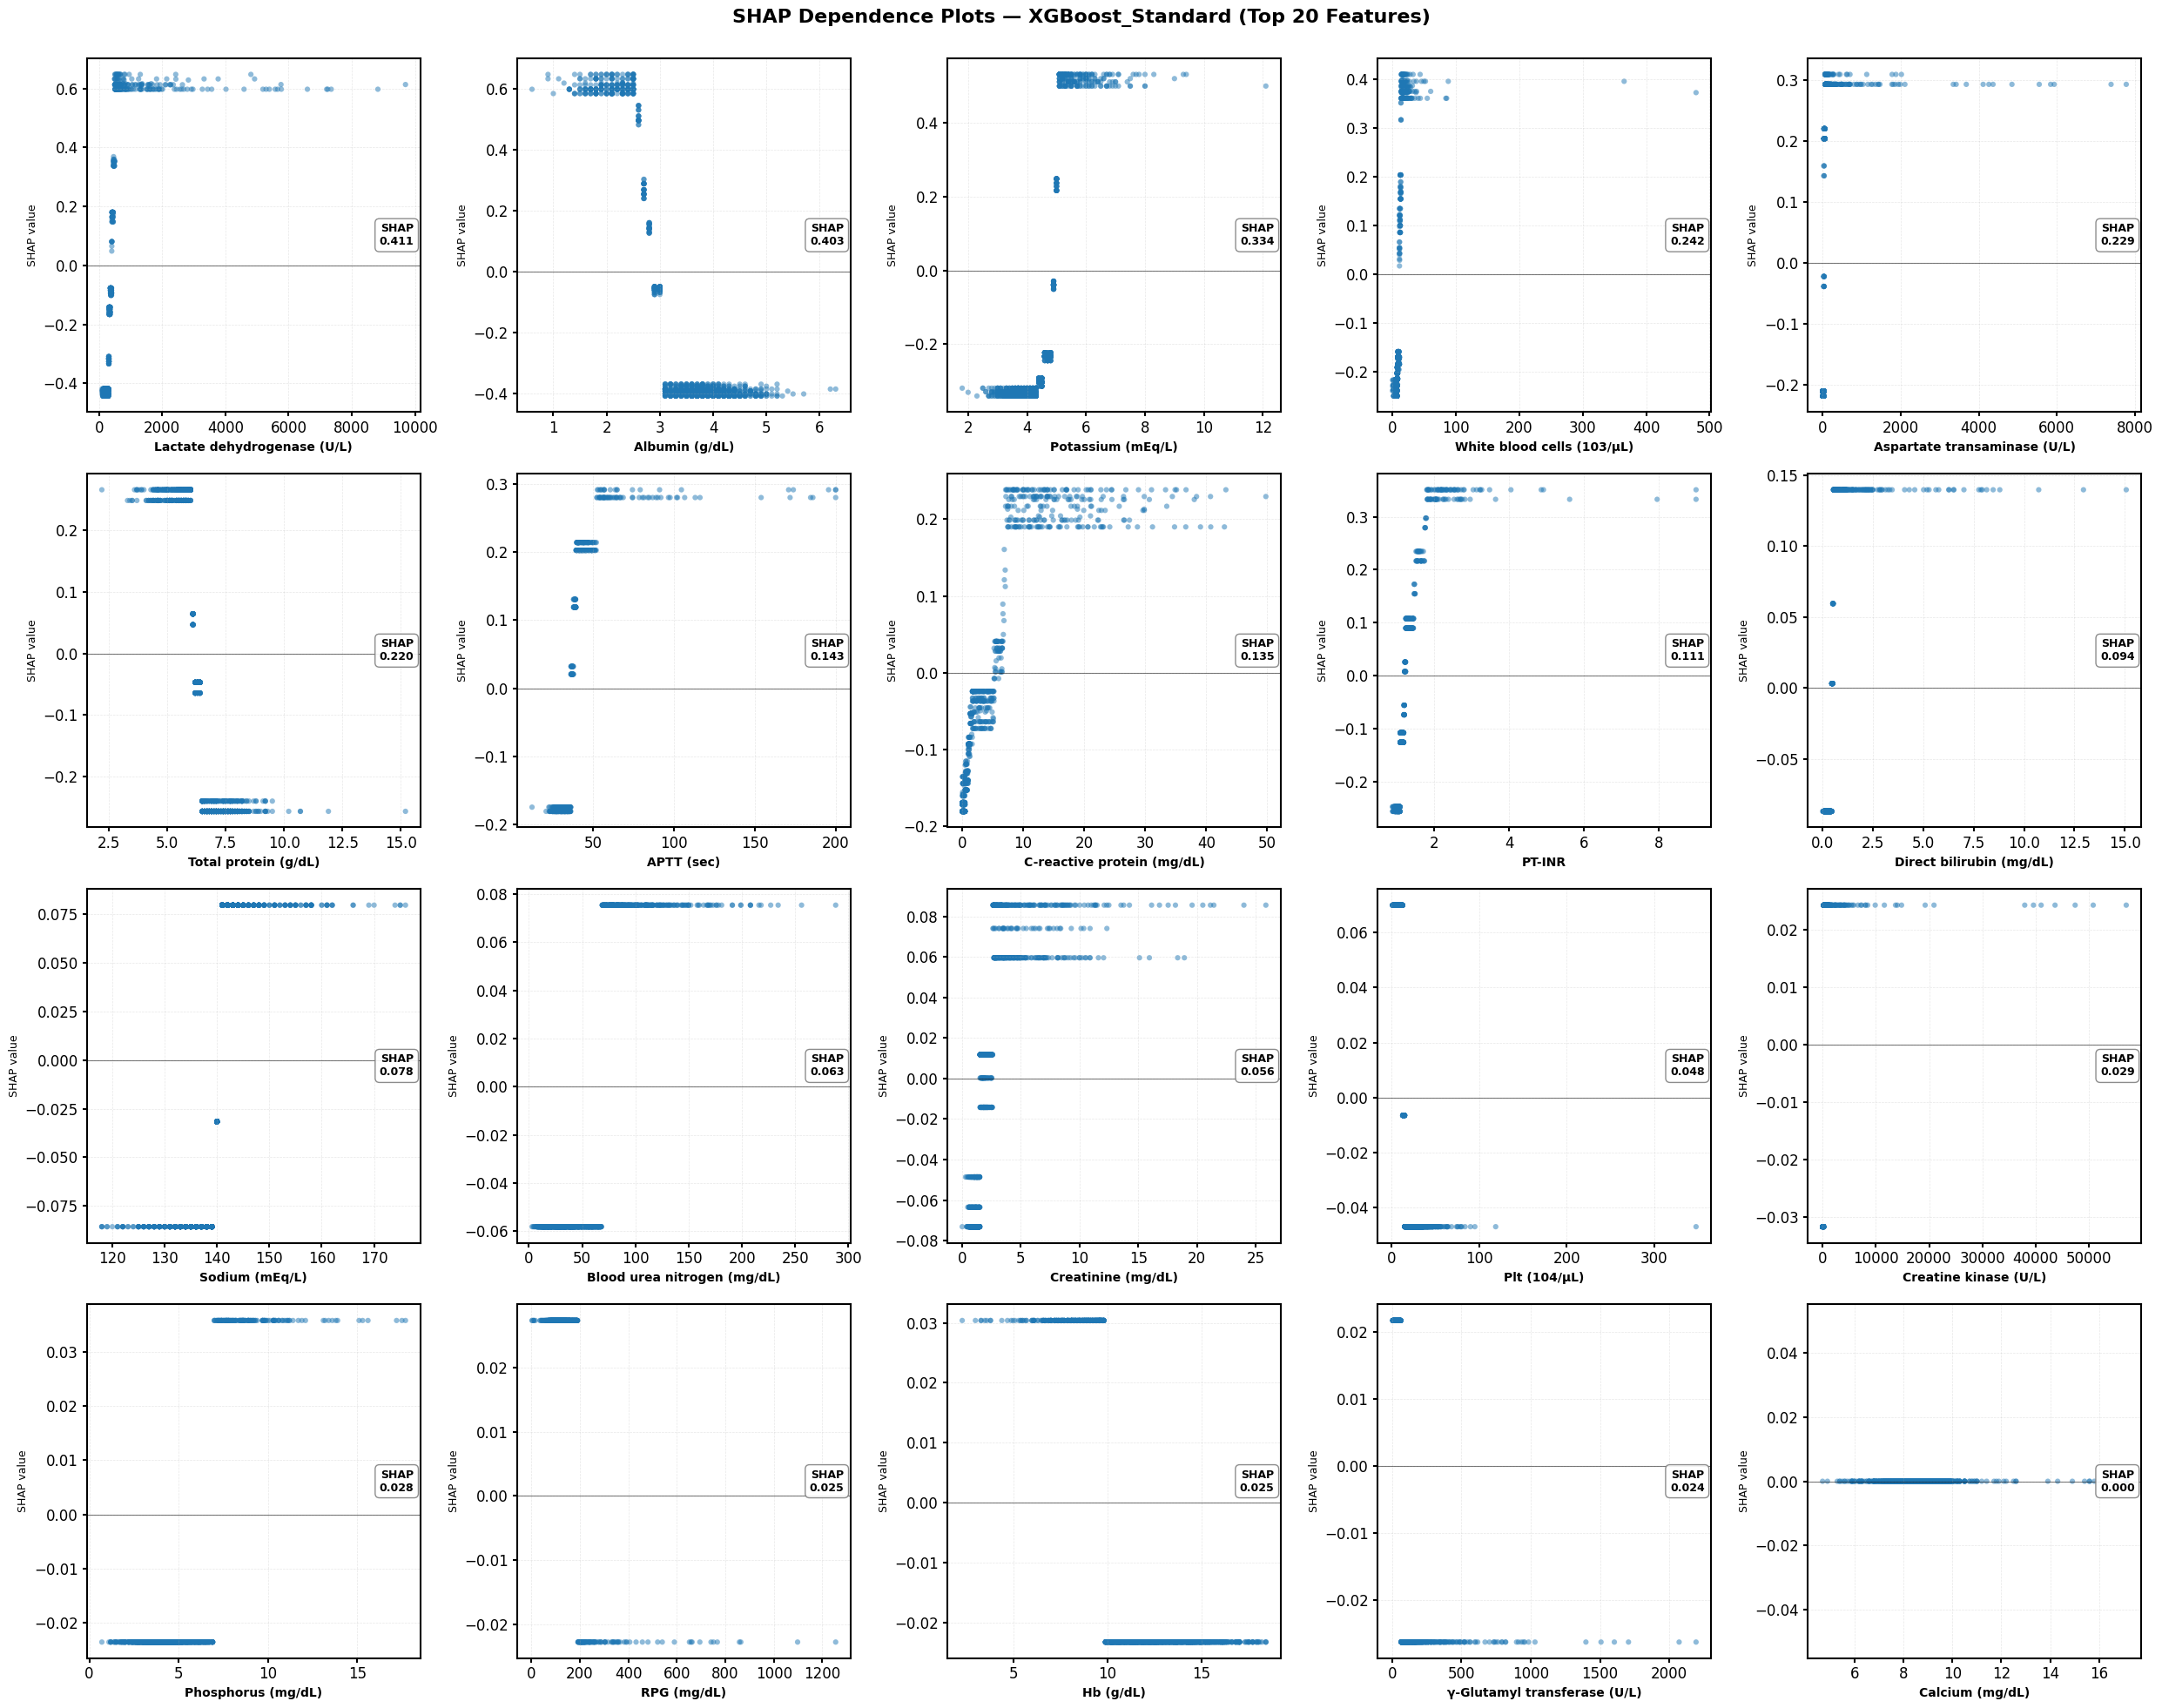

✓ Saved figure10_shap_dependence_best_model.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ SHAP analysis complete


In [44]:
# ============================================================
# Section 12: SHAP Analysis
# Tree-based SHAP for XGBoost / LightGBM / CatBoost;
# Permutation-based SHAP (shap.Explainer) for HistGradientBoosting.
# ============================================================

import shap

set_global_seed(RANDOM_STATE)

# Select top-3 ML models by validation AUC (deterministic sort)
ml_aucs = {
    n: roc_auc_score(_get_arr(r['val_true']), np.asarray(r['val_proba']))
    for n, r in all_results.items()
    if n not in ('MLRA', 'Prediction_One')
}
top3 = sorted(ml_aucs, key=lambda x: (-ml_aucs[x], x))[:3]
print("Top-3 models for SHAP:", top3)

shap_vals = {}
for name in top3:
    mdl = ml_results[name]['model']
    print(f"  Computing SHAP for {name}...")
    try:
        if any(k in name for k in ('XGBoost', 'LightGBM', 'CatBoost')):
            exp   = shap.TreeExplainer(mdl)
            sv    = exp.shap_values(X_val)
            sv    = sv[1] if isinstance(sv, list) else sv
        else:
            exp_g = shap.Explainer(mdl, X_train)
            sv    = exp_g(X_val).values
        shap_vals[name] = {'shap': sv, 'auc': ml_aucs[name]}
        print(f"    ✓ Shape: {sv.shape}")
    except Exception as e:
        print(f"    ✗ Error: {e}")

shap_files = []

# ── Figure 8: SHAP Bar Plot (top 20 features, 3 panels) ───
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for idx, name in enumerate(top3):
    if name not in shap_vals:
        continue
    sv  = shap_vals[name]['shap']
    imp = pd.DataFrame({'feature': X_train.columns,
                         'importance': np.mean(np.abs(sv), axis=0)
                        }).sort_values('importance', ascending=False).head(20)
    ax  = axes[idx]
    yp  = np.arange(len(imp))
    ax.barh(yp, imp['importance'], color='#1f77b4', alpha=0.8)
    ax.set_yticks(yp); ax.set_yticklabels(imp['feature'], fontsize=9)
    ax.invert_yaxis()
    for i, (_, row) in enumerate(imp.iterrows()):
        ax.text(row['importance'] * 1.02, i, f"{row['importance']:.3f}",
                va='center', fontsize=8)
    ax.set_xlabel('Mean |SHAP value|', fontsize=11, fontweight='bold')
    ax.set_title(f'#{idx+1}: {name}\n(AUC={ml_aucs[name]:.4f})',
                 fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3, ls='--')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.tight_layout()
f8 = 'figure8_shap_bar_top3.jpg'
plt.savefig(f8, dpi=300, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
shap_files.append(f8)
plt.show()
plt.close(fig)
print(f"✓ Saved {f8}")

# ── Figure 9: SHAP Beeswarm for each top-3 model ──────────
for idx, name in enumerate(top3):
    if name not in shap_vals:
        continue
    sv = shap_vals[name]['shap']
    fig = plt.figure(figsize=(8, 8))
    shap.summary_plot(sv, X_val, max_display=20, show=False,
                      plot_type='dot', color_bar=True)
    plt.title(f'#{idx+1}: {name} (AUC={ml_aucs[name]:.4f})',
              fontsize=14, fontweight='bold', pad=15)
    plt.tight_layout()
    fname = f'figure9{chr(65+idx)}_shap_beeswarm_{name}.jpg'
    plt.savefig(fname, dpi=300, bbox_inches='tight', facecolor='white',
                format='jpeg', pil_kwargs={'quality': 95})
    shap_files.append(fname)
    plt.show()
    plt.close(fig)
    print(f"✓ Saved {fname}")

# ── Figure 10: Dependence plots (best model, top 20) ──────
best_shap_name = top3[0]
if best_shap_name in shap_vals:
    sv  = shap_vals[best_shap_name]['shap']
    imp = pd.DataFrame({'feature': X_train.columns,
                         'importance': np.mean(np.abs(sv), axis=0)
                        }).sort_values('importance', ascending=False).head(20)
    fig, axes = plt.subplots(4, 5, figsize=(25, 20))
    axes = axes.flatten()
    for i, (_, row) in enumerate(imp.iterrows()):
        ax   = axes[i]
        fidx = list(X_train.columns).index(row['feature'])
        ax.scatter(X_val.iloc[:, fidx].values, sv[:, fidx],
                   c='#1f77b4', alpha=0.5, s=20, edgecolors='none')
        ax.axhline(0, color='black', lw=0.8, alpha=0.5)
        ax.set_xlabel(row['feature'],              fontsize=10, fontweight='bold')
        ax.set_ylabel(f"SHAP value",               fontsize=9)
        ax.grid(True, alpha=0.3, ls='--')
        ax.text(0.98, 0.5, f"SHAP\n{row['importance']:.3f}",
                transform=ax.transAxes, fontsize=9, fontweight='bold',
                va='center', ha='right',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                          edgecolor='gray', alpha=0.9))
    plt.suptitle(f'SHAP Dependence Plots — {best_shap_name} (Top 20 Features)',
                 fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    f10 = 'figure10_shap_dependence_best_model.jpg'
    plt.savefig(f10, dpi=300, bbox_inches='tight', facecolor='white',
                format='jpeg', pil_kwargs={'quality': 95})
    shap_files.append(f10)
    plt.show()
    plt.close(fig)
    print(f"✓ Saved {f10}")

for f in shap_files:
    files.download(f)
print("\n✓ SHAP analysis complete")
# ── Verification: Top-3 model order and mean |SHAP| for #1 feature must match original ──


## Section 13 · IDI/NRI Analysis — Common-Sample CSV Preparation

In [45]:
# ============================================================
# Section 13: IDI/NRI Analysis — Common-Sample CSV Preparation
# Aligns all models to the MLRA sample (listwise-deleted subset)
# before IDI/NRI computation to ensure statistical validity.
# Reference: Pencina et al. (2008, 2011)
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("IDI/NRI data preparation — common-sample alignment")
print("=" * 70)

# ── STEP 1: Retrieve MLRA indices ─────────────────────────
val_mlra_true = mlra_results['val_true']
mlra_indices  = (val_mlra_true.index
                 if hasattr(val_mlra_true, 'index')
                 else np.arange(len(val_mlra_true)))

print(f"\nFull validation set N          : {len(val_df)}")
print(f"MLRA subset N (listwise-deleted): {len(val_mlra_true)}")
print(f"Rows excluded from MLRA         : {len(val_df) - len(val_mlra_true)}")

# ── STEP 2: True-label CSV ────────────────────────────────
y_true_common = (_get_arr(val_mlra_true))
pd.DataFrame({'y_true': y_true_common}).to_csv('test_data.csv', index=False)
print(f"\n✓ test_data.csv — N={len(y_true_common)}, "
      f"events={y_true_common.sum()} ({y_true_common.mean()*100:.1f}%)")

# ── STEP 3: MLRA prediction CSV ───────────────────────────
mlra_p = np.asarray(mlra_results['val_proba'])
pd.DataFrame({'probability': mlra_p}).to_csv('predictions_mlra.csv', index=False)
print(f"✓ predictions_mlra.csv — mean prob={mlra_p.mean():.4f}")

generated = ['test_data.csv', 'predictions_mlra.csv']

# ── STEP 4: ML model prediction CSVs ─────────────────────
all_sources = {**ml_results}
if 'Prediction_One' in all_results:
    all_sources['Prediction_One'] = all_results['Prediction_One']

for name, res in all_sources.items():
    try:
        yp = np.asarray(res['val_proba'])
        if len(yp) != len(mlra_p):
            yp = (yp[mlra_indices]
                  if hasattr(mlra_indices, '__len__')
                  else yp)
        safe = name.lower().replace(' ', '_').replace('/', '_')
        fname = f'predictions_{safe}.csv'
        pd.DataFrame({'probability': yp}).to_csv(fname, index=False)
        generated.append(fname)
        print(f"✓ {fname} — N={len(yp)}, mean={yp.mean():.4f}")
    except Exception as e:
        print(f"✗ {name}: {e}")

print(f"\nGenerated {len(generated)} CSV files")
from IPython.display import display as _disp35
import pandas as _pd35
_summary35 = _pd35.DataFrame({
    'File': generated,
    'N': [len(y_true_common)] + [len(y_true_common)] * (len(generated)-1)
})
print('\n[Prediction CSV Summary]')
_disp35(_summary35)
for f in generated:
    files.download(f)
print("\n✓ Common-sample CSV export complete")


IDI/NRI data preparation — common-sample alignment

Full validation set N          : 1243
MLRA subset N (listwise-deleted): 1066
Rows excluded from MLRA         : 177

✓ test_data.csv — N=1066, events=50 (4.7%)
✓ predictions_mlra.csv — mean prob=0.0789
✓ predictions_xgboost_standard.csv — N=1066, mean=0.0682
✓ predictions_xgboost_dart.csv — N=1066, mean=0.0704
✓ predictions_lightgbm_gbdt.csv — N=1066, mean=0.0658
✓ predictions_lightgbm_dart.csv — N=1066, mean=0.1194
✓ predictions_lightgbm_goss.csv — N=1066, mean=0.0630
✓ predictions_catboost_standard.csv — N=1066, mean=0.0702
✓ predictions_catboost_ordered.csv — N=1066, mean=0.0613
✓ predictions_histgradientboosting.csv — N=1066, mean=0.0648
✓ predictions_prediction_one.csv — N=1066, mean=0.2640

Generated 11 CSV files

[Prediction CSV Summary]


,File,N
0,test_data.csv,1066
1,predictions_mlra.csv,1066
2,predictions_xgboost_standard.csv,1066
3,predictions_xgboost_dart.csv,1066
4,predictions_lightgbm_gbdt.csv,1066
5,predictions_lightgbm_dart.csv,1066
6,predictions_lightgbm_goss.csv,1066
7,predictions_catboost_standard.csv,1066
8,predictions_catboost_ordered.csv,1066
9,predictions_histgradientboosting.csv,1066


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Common-sample CSV export complete


## Section 14 · IDI/NRI Pairwise Comparison

In [46]:
# ============================================================
# Section 14: IDI & NRI Pairwise Comparison (vs. MLRA baseline)
# Reference: Pencina et al. Stat Med 2008; 2011.
# All models are compared on the common MLRA subsample.
# ============================================================

set_global_seed(RANDOM_STATE)

# ── IDI calculation ────────────────────────────────────────
def calculate_idi(y_true, p_new, p_ref, n_bootstrap=1000):
    """
    Continuous IDI between a new model and a reference model.
    Bootstrap 95% CI uses percentile method.
    """
    y_true = np.asarray(y_true); p_new = np.asarray(p_new); p_ref = np.asarray(p_ref)
    events    = y_true == 1
    non_events = y_true == 0

    idi_point = ((np.mean(p_new[events])    - np.mean(p_ref[events])) -
                 (np.mean(p_new[non_events]) - np.mean(p_ref[non_events])))

    rng  = np.random.RandomState(RANDOM_STATE)
    boot = []
    for _ in range(n_bootstrap):
        idx = rng.choice(len(y_true), len(y_true), replace=True)
        yb, pb_new, pb_ref = y_true[idx], p_new[idx], p_ref[idx]
        ev   = yb == 1; nev = yb == 0
        if ev.sum() == 0 or nev.sum() == 0:
            continue
        boot.append(((np.mean(pb_new[ev])  - np.mean(pb_ref[ev])) -
                     (np.mean(pb_new[nev]) - np.mean(pb_ref[nev]))))

    boot = np.array(boot)
    ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
    se   = boot.std(ddof=1)
    pval = 2 * min(np.mean(boot >= 0), np.mean(boot <= 0))
    return {'IDI': idi_point, 'SE': se, 'CI_lower': ci_lo,
            'CI_upper': ci_hi, 'P_value': pval}


# ── NRI calculation ────────────────────────────────────────
def calculate_nri(y_true, p_new, p_ref,
                  threshold=None, n_bootstrap=1000):
    """
    Categorical (threshold-based) or continuous NRI.
    If threshold is None, uses continuous NRI.
    """
    y_true = np.asarray(y_true); p_new = np.asarray(p_new); p_ref = np.asarray(p_ref)

    def _nri_point(yt, pn, pr, thr):
        ev  = yt == 1; nev = yt == 0
        if thr is not None:
            up_ev   = np.sum((pn[ev]  > thr) & (pr[ev]  <= thr))
            down_ev = np.sum((pn[ev]  <= thr) & (pr[ev] > thr))
            up_nev  = np.sum((pn[nev] > thr)  & (pr[nev] <= thr))
            down_nev= np.sum((pn[nev] <= thr) & (pr[nev] > thr))
            n_ev    = ev.sum(); n_nev = nev.sum()
            return (((up_ev - down_ev) / n_ev if n_ev else 0) -
                    ((up_nev - down_nev) / n_nev if n_nev else 0))
        else:
            up_ev   = np.mean(pn[ev]  > pr[ev])
            down_ev = np.mean(pn[ev]  < pr[ev])
            up_nev  = np.mean(pn[nev] > pr[nev])
            down_nev= np.mean(pn[nev] < pr[nev])
            return (up_ev - down_ev) - (up_nev - down_nev)

    nri_point = _nri_point(y_true, p_new, p_ref, threshold)
    rng  = np.random.RandomState(RANDOM_STATE)
    boot = []
    for _ in range(n_bootstrap):
        idx = rng.choice(len(y_true), len(y_true), replace=True)
        boot.append(_nri_point(y_true[idx], p_new[idx], p_ref[idx], threshold))
    boot   = np.array(boot)
    ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
    se   = boot.std(ddof=1)
    pval = 2 * min(np.mean(boot >= 0), np.mean(boot <= 0))
    return {'NRI': nri_point, 'SE': se, 'CI_lower': ci_lo,
            'CI_upper': ci_hi, 'P_value': pval}


# ── Compute IDI/NRI for all models vs. MLRA ───────────────
y_true_common = pd.read_csv('test_data.csv')['y_true'].values
p_mlra_common = pd.read_csv('predictions_mlra.csv')['probability'].values

labels  = list(string.ascii_uppercase)
results_idi_nri = []
label_map = {}

for i, (name, res) in enumerate(sorted(all_results.items())):
    if name == 'MLRA':
        continue
    safe  = name.lower().replace(' ', '_').replace('/', '_')
    fname = f'predictions_{safe}.csv'
    try:
        p_new = pd.read_csv(fname)['probability'].values
    except FileNotFoundError:
        print(f"  Skipping {name}: CSV not found")
        continue

    lbl = labels[i % len(labels)]
    label_map[lbl] = _display_name(name)

    idi = calculate_idi(y_true_common, p_new, p_mlra_common)
    nri = calculate_nri(y_true_common, p_new, p_mlra_common)

    results_idi_nri.append({
        'Label'         : lbl,
        'Model'         : _display_name(name),
        'IDI'           : idi['IDI'],
        'IDI_CI'        : f"{idi['CI_lower']:.3f}\u2013{idi['CI_upper']:.3f}",
        'IDI_P'         : idi['P_value'],
        'IDI_Significant': idi['P_value'] < 0.05,
        'NRI'           : nri['NRI'],
        'NRI_CI'        : f"{nri['CI_lower']:.3f}\u2013{nri['CI_upper']:.3f}",
        'NRI_P'         : nri['P_value'],
        'NRI_Significant': nri['P_value'] < 0.05,
    })
    print(f"  {lbl}: {_display_name(name)}  IDI={idi['IDI']:.4f} "
          f"(p={idi['P_value']:.3f})  NRI={nri['NRI']:.4f} (p={nri['P_value']:.3f})")

results_df = pd.DataFrame(results_idi_nri)
print("\n", results_df.to_string(index=False))

idi_excel = 'idi_nri_results.xlsx'
results_df.to_excel(idi_excel, index=False)
files.download(idi_excel)
print(f"\n✓ Saved {idi_excel}")
# ── Verification: IDI and NRI values vs. MLRA must match original run ──


  A: CatBoost_Ordered  IDI=0.0551 (p=0.082)  NRI=0.3767 (p=0.016)
  B: CatBoost_Standard  IDI=-0.1062 (p=0.000)  NRI=-0.8580 (p=0.000)
  C: HistGradientBoosting  IDI=-0.0828 (p=0.002)  NRI=-0.4106 (p=0.008)
  D: LightGBM_DART  IDI=-0.1374 (p=0.000)  NRI=-0.8517 (p=0.000)
  E: LightGBM_GBDT  IDI=-0.0923 (p=0.000)  NRI=-0.5484 (p=0.002)
  F: LightGBM_GOSS  IDI=-0.1716 (p=0.000)  NRI=-0.9944 (p=0.000)
  H: Prediction One™  IDI=-0.1254 (p=0.000)  NRI=-0.5055 (p=0.000)
  I: XGBoost_DART  IDI=-0.0616 (p=0.014)  NRI=-0.5576 (p=0.000)
  J: XGBoost_Standard  IDI=-0.0130 (p=0.668)  NRI=-0.0695 (p=0.642)

 Label                Model       IDI        IDI_CI  IDI_P  IDI_Significant       NRI        NRI_CI  NRI_P  NRI_Significant
    A     CatBoost_Ordered  0.055088  -0.005–0.124  0.082            False  0.376693   0.109–0.660  0.016             True
    B    CatBoost_Standard -0.106155 -0.165–-0.054  0.000             True -0.858031 -1.128–-0.584  0.000             True
    C HistGradientBoosting -

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Saved idi_nri_results.xlsx


## Section 16 · TRIPOD+AI Comprehensive Analysis

In [47]:
# ============================================================
# Section 16: TRIPOD+AI Comprehensive Analysis
# Calibration + DCA + Threshold Analysis
# Adheres to TRIPOD+AI reporting standards for prediction models.
# ============================================================

from scipy.interpolate import interp1d
set_global_seed(RANDOM_STATE)

def compute_tripod_calibration(y_true, y_proba, model_name,
                                n_bins: int = 10) -> dict:
    """Brier score, calibration slope, calibration intercept."""
    y_true  = np.asarray(y_true,  dtype=float)
    y_proba = np.asarray(y_proba, dtype=float)
    brier   = brier_score_loss(y_true, y_proba)

    frac_pos, mean_pred = calibration_curve(y_true, y_proba,
                                             n_bins=n_bins, strategy='uniform')
    if len(mean_pred) > 1:
        lr = LinearRegression().fit(mean_pred.reshape(-1, 1), frac_pos)
        slope = lr.coef_[0]; intercept = lr.intercept_
    else:
        slope = intercept = np.nan

    return {'Model': model_name, 'Brier_Score': brier,
            'Cal_Slope': slope, 'Cal_Intercept': intercept}


tripod_rows  = []
threshold_rows = []

for name, res in sorted(all_results.items()):
    yt   = _get_arr(res['val_true'])
    yp   = np.asarray(res['val_proba'])
    dsp  = _display_name(name)

    # Calibration
    cal  = compute_tripod_calibration(yt, yp, dsp)
    tripod_rows.append(cal)

    # Optimal threshold (Youden's J)
    fpr_arr, tpr_arr, threshs = roc_curve(yt, yp)
    best_idx   = np.argmax(tpr_arr - fpr_arr)
    best_t     = threshs[best_idx]
    y_pred     = (yp >= best_t).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(yt, y_pred).ravel()
        sens = tp / (tp + fn) if (tp + fn) else np.nan
        spec = tn / (tn + fp) if (tn + fp) else np.nan
        ppv  = tp / (tp + fp) if (tp + fp) else np.nan
        npv  = tn / (tn + fn) if (tn + fn) else np.nan
    except Exception:
        sens = spec = ppv = npv = np.nan
    threshold_rows.append({'Model': dsp, 'Optimal_Threshold': best_t,
                           'Sensitivity': sens, 'Specificity': spec,
                           'PPV': ppv, 'NPV': npv})

tripod_df    = pd.DataFrame(tripod_rows)
threshold_df = pd.DataFrame(threshold_rows)

print("TRIPOD+AI Calibration Summary:")
print(tripod_df.round(4).to_string(index=False))
print("\nOptimal Threshold Summary:")
print(threshold_df.round(4).to_string(index=False))

tripod_excel = 'tripod_ai_analysis.xlsx'
with pd.ExcelWriter(tripod_excel, engine='openpyxl') as writer:
    tripod_df.to_excel(   writer, sheet_name='Calibration',  index=False)
    threshold_df.to_excel(writer, sheet_name='Thresholds',   index=False)
files.download(tripod_excel)
print(f"\n✓ Saved {tripod_excel}")
print("\n✓ TRIPOD+AI analysis complete")


TRIPOD+AI Calibration Summary:
               Model  Brier_Score  Cal_Slope  Cal_Intercept
    CatBoost_Ordered       0.0355     0.5658         0.0382
   CatBoost_Standard       0.0340     1.4512        -0.0897
HistGradientBoosting       0.0338     1.1236        -0.0304
       LightGBM_DART       0.0398     1.4613        -0.1336
       LightGBM_GBDT       0.0338     1.1453        -0.0358
       LightGBM_GOSS       0.0357     1.6099        -0.0399
                MLRA       0.0411     0.6620        -0.0184
     Prediction One™       0.0819     1.6465        -0.4359
        XGBoost_DART       0.0331     1.2679        -0.0787
    XGBoost_Standard       0.0319     1.2583        -0.0996

Optimal Threshold Summary:
               Model  Optimal_Threshold  Sensitivity  Specificity    PPV    NPV
    CatBoost_Ordered             0.0533       0.8519       0.8587 0.2150 0.9922
   CatBoost_Standard             0.0826       0.9444       0.8116 0.1855 0.9969
HistGradientBoosting             0.0816  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Saved tripod_ai_analysis.xlsx

✓ TRIPOD+AI analysis complete


## Section 17 · Subgroup Analysis + Forest Plot (MLRA vs XGBoost Standard)
**Prerequisite**: Sections 3, 5, 7 must have been executed (train_df, val_df, all_results in memory).

- Subgroups: Sex, Age (18-65 / 65-75 / ≥75), Albumin (g/dL), CRP (mg/dL), CCI (Development only)
- MLRA: complete-case on 4 predictors; XGBoost Standard: native missing-value handling
- Cutoffs: median derived separately for MLRA complete-case vs XGBoost full population
- Output: `Figure_S6_Subgroup_Forest_Dev_vs_Val_MLRA_XGBoost.png` (300 DPI), 2 CSV files

Upload DEVELOPMENT (Training) CSV ...


Saving UA G1 2019_correct dataset for Subgroup Analysis.csv to UA G1 2019_correct dataset for Subgroup Analysis.csv

Upload VALIDATION CSV ...


Saving UA G2 2018_2017 correct dataset for Subgrop Analysis.csv to UA G2 2018_2017 correct dataset for Subgrop Analysis.csv

[Loaded]
Training: (756, 45)  Validation: (1243, 45)
[MLRA Development] complete-case: 756 -> 664 (removed 92)
[MLRA Validation] complete-case: 1243 -> 1066 (removed 177)

[Cutoffs]
  Albumin: MLRA=3.5 | XGB=3.5
  CRP:     MLRA=0.99 | XGB=0.92
  CCI:     MLRA=5.0 | XGB=5.0

[XGB feature matrix]
X_tr: (756, 44)  X_va: (1243, 44)

[Subgroup Analysis Results — MLRA]


,Model,Dataset,Subgroup,Category,N,Events,AUC,CI_Lower,CI_Upper
0,MLRA,Development,Sex,Female,221,18,0.878216,0.790622,0.965809
1,MLRA,Development,Sex,Male,443,27,0.873754,0.811271,0.936236
2,MLRA,Development,Age (years),18-65,230,14,0.840608,0.736104,0.945113
3,MLRA,Development,Age (years),65-75,163,10,0.935948,0.895040,0.976855
4,MLRA,Development,Age (years),≥75,271,21,0.874286,0.796927,0.951644
5,MLRA,Development,Albumin (g/dL),Low (≤3.50),346,40,0.816258,0.738882,0.893634
6,MLRA,Development,Albumin (g/dL),High (>3.50),318,5,0.898403,0.790545,1.000000
7,MLRA,Development,CRP (mg/dL),Low (≤0.99),333,6,0.896534,0.771087,1.000000
8,MLRA,Development,CRP (mg/dL),High (>0.99),331,39,0.803126,0.722494,0.883758
9,MLRA,Development,CCI,Low (≤5.0),385,15,0.862703,0.780058,0.945348



[Subgroup Analysis Results — XGBoost Standard]


,Model,Dataset,Subgroup,Category,N,Events,AUC,CI_Lower,CI_Upper
0,XGBoost Standard,Development,Sex,Female,248,19,0.945989,0.902245,0.989734
1,XGBoost Standard,Development,Sex,Male,508,29,0.940681,0.907283,0.974079
2,XGBoost Standard,Development,Age (years),18-65,271,16,0.933333,0.890791,0.975876
3,XGBoost Standard,Development,Age (years),65-75,179,10,0.981065,0.962721,0.999409
4,XGBoost Standard,Development,Age (years),≥75,306,22,0.937100,0.893696,0.980504
5,XGBoost Standard,Development,Albumin (g/dL),Low (≤3.50),391,43,0.908380,0.865863,0.950897
6,XGBoost Standard,Development,Albumin (g/dL),High (>3.50),365,5,0.965556,0.922616,1.000000
7,XGBoost Standard,Development,CRP (mg/dL),Low (≤0.92),406,7,0.981740,0.959745,1.000000
8,XGBoost Standard,Development,CRP (mg/dL),High (>0.92),350,41,0.894230,0.843037,0.945423
9,XGBoost Standard,Development,CCI,Low (≤5.0),439,16,0.941785,0.902335,0.981235



Saved CSV:
  - Subgroup_Analysis_Results MLRA.csv
  - Subgroup_Analysis_Results ML XGBoost Standard.csv


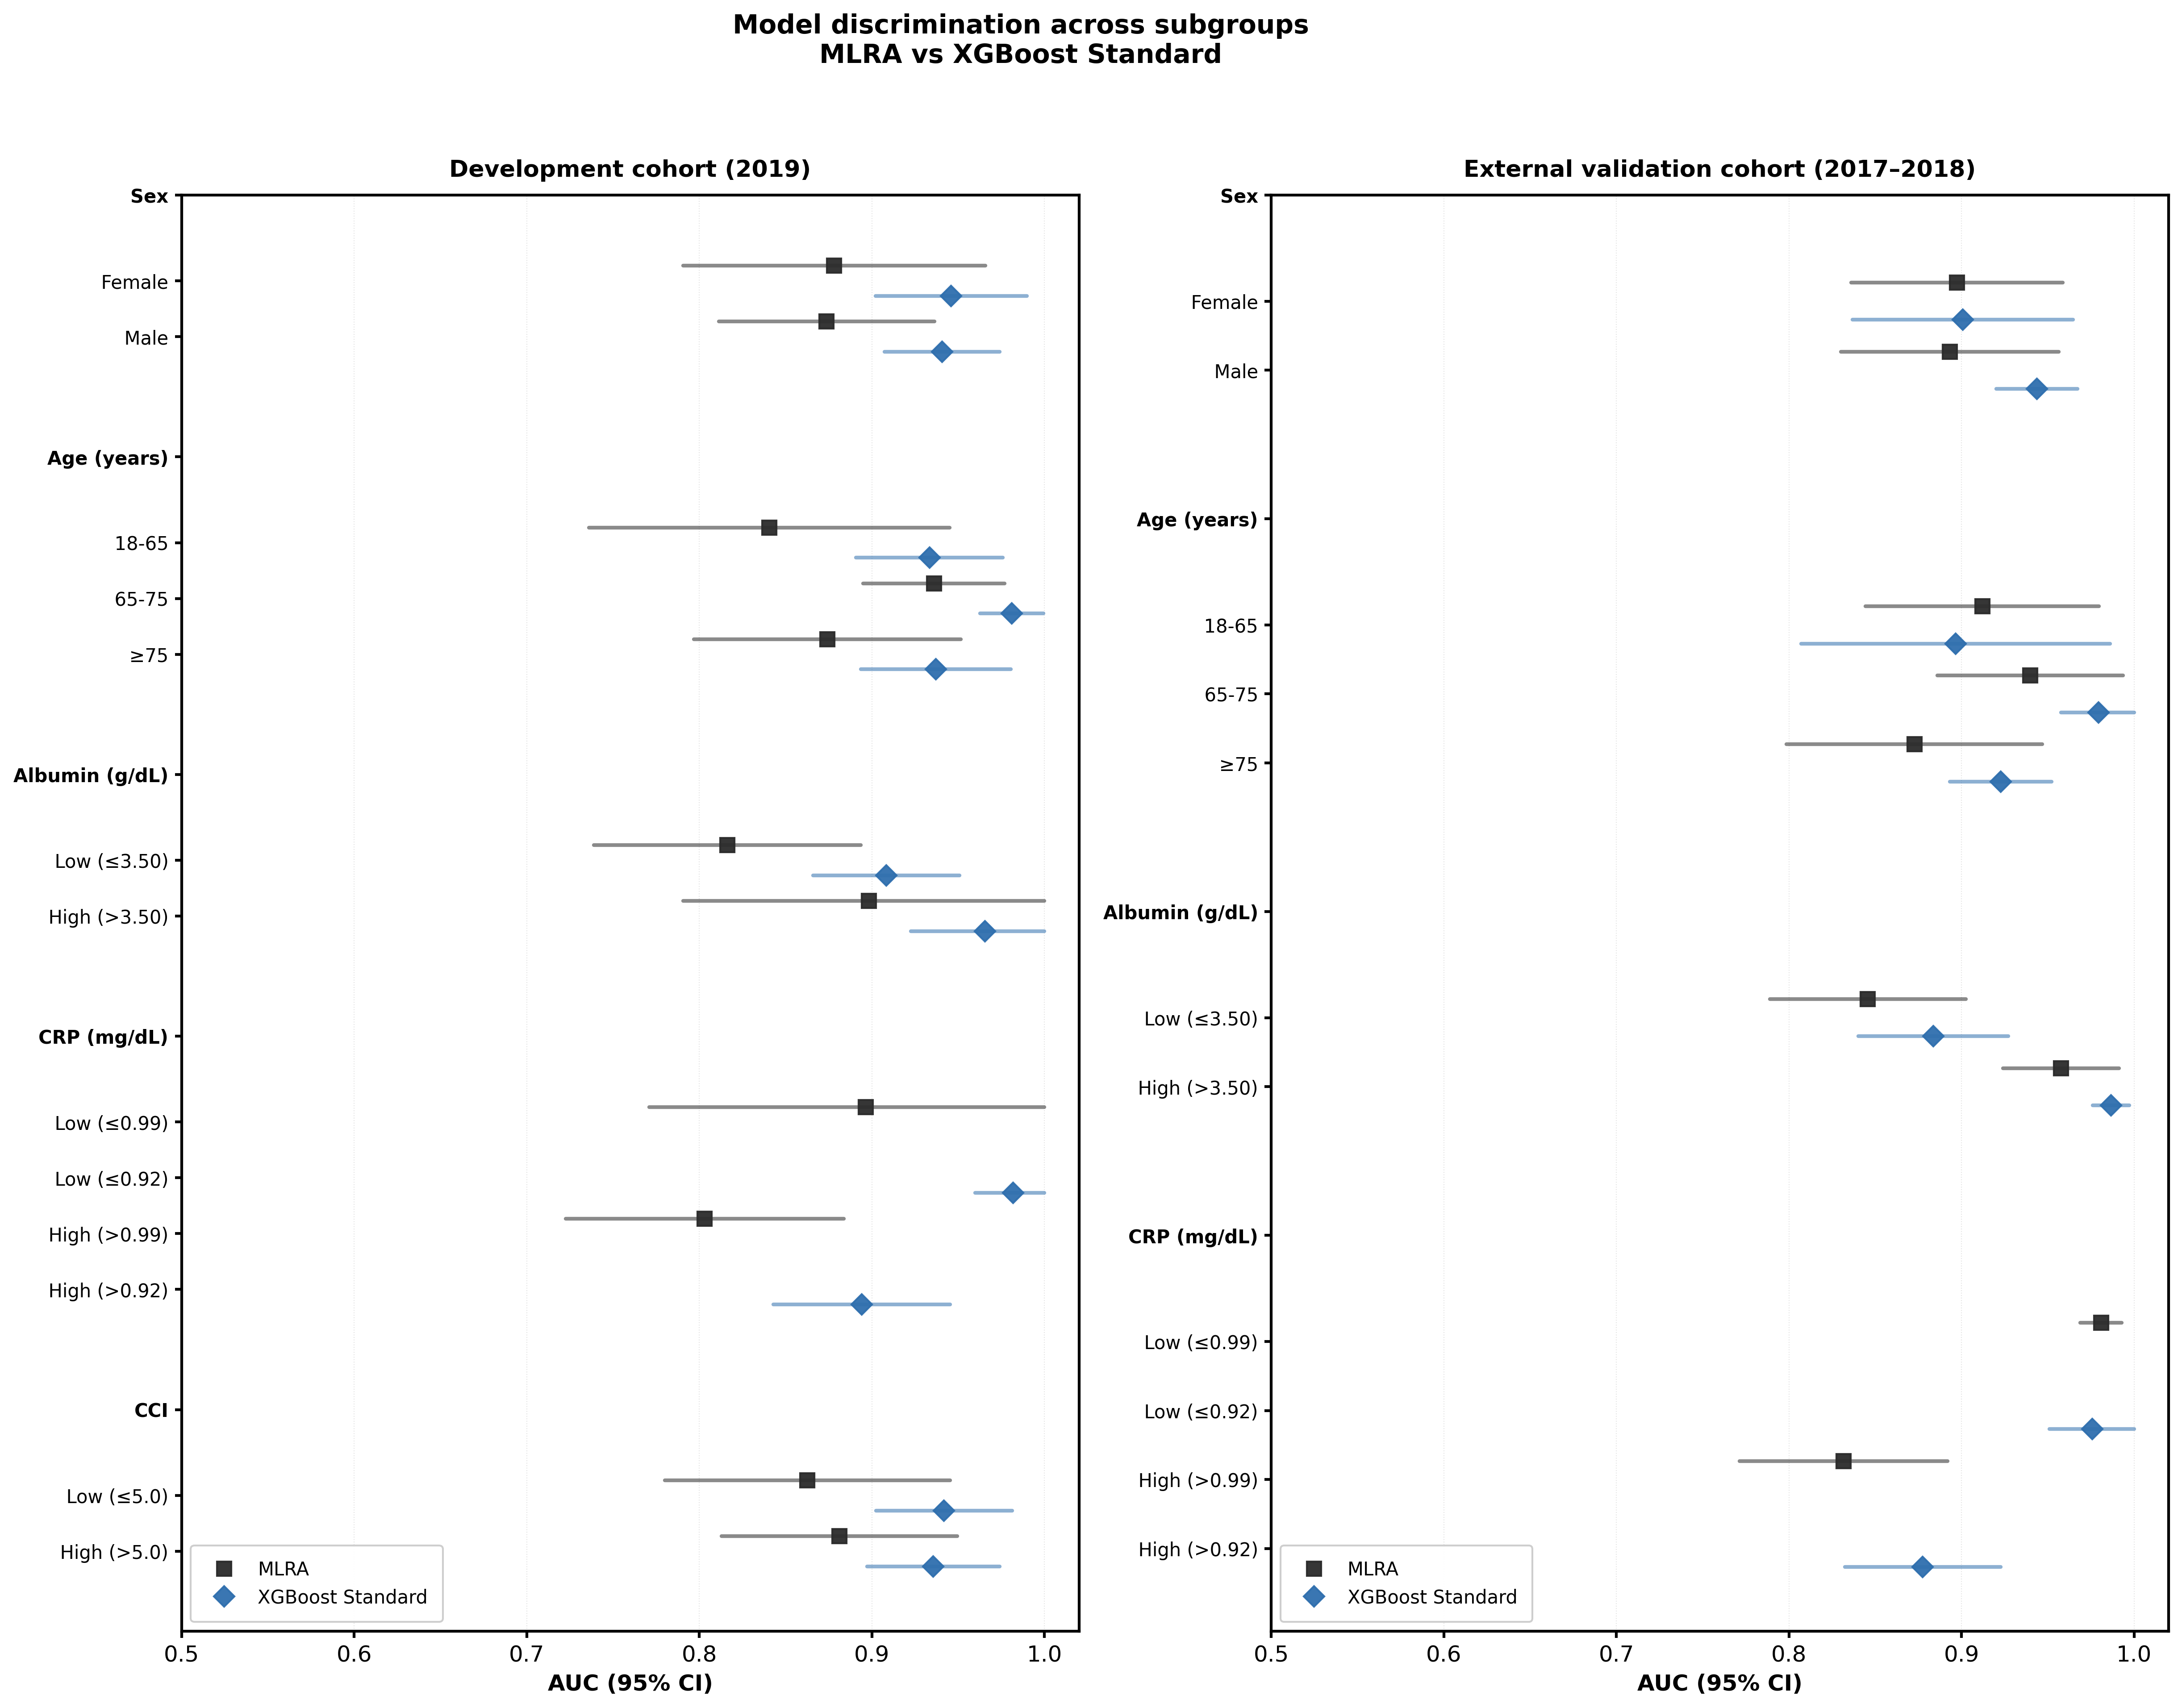

Saved: Figure_S6_Subgroup_Forest_Dev_vs_Val_MLRA_XGBoost.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done.


In [ ]:
# ============================================================
# MLRA + XGBoost Standard
# Subgroup Analysis (Development vs Validation) + Forest Plot
# Age strata fixed: 18–65, 65–75, ≥75 (display order fixed)
# Development subgroups: Sex, Age, Albumin (g/dL), CRP (mg/dL), CCI
# Validation subgroups:  Sex, Age, Albumin (g/dL), CRP (mg/dL) (+ keep CCI space)
# MLRA: complete-case on 4 variables
# XGB: native missing; hyperparameters fixed; DO NOT change
# Outputs auto-download in Colab
#
# [FIX-1] Remove duplicated "category==subgroup name" rows (Sex/Age/Albumin/CRP/CCI)
# [FIX-2] Tune vertical spacing (header-to-first-category + between blocks)
# [FIX-3] Keep CCI empty block in Validation to match Development layout
# [FIX-4] Labels: CRP keeps model-specific thresholds; others unified (no [MLRA]/[XGB] tags)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from google.colab import files

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

COL_MLRA = "#2B2B2B"   # near-black
COL_XGB  = "#2F6FAE"   # muted blue
ALPHA_POINT = 0.95
ALPHA_CI = 0.55

# -------------------------
# DeLong AUC CI
# -------------------------
def delong_roc_variance(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(float)

    order = np.argsort(y_pred)
    y_true = y_true[order]
    y_pred = y_pred[order]

    n1 = np.sum(y_true == 1)
    n0 = np.sum(y_true == 0)
    if n1 == 0 or n0 == 0:
        return None

    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]

    V10 = np.zeros(n1, dtype=float)
    for i, pr in enumerate(pos):
        V10[i] = np.sum(y_pred[neg] < y_pred[pr]) + 0.5 * np.sum(y_pred[neg] == y_pred[pr])

    V01 = np.zeros(n0, dtype=float)
    for i, nr in enumerate(neg):
        V01[i] = np.sum(y_pred[pos] > y_pred[nr]) + 0.5 * np.sum(y_pred[pos] == y_pred[nr])

    S10 = np.var(V10 / n0, ddof=1)
    S01 = np.var(V01 / n1, ddof=1)
    return (S10 / n1) + (S01 / n0)

def auc_ci_delong(y_true, y_pred, alpha=0.05):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(float)

    auc = roc_auc_score(y_true, y_pred)
    var = delong_roc_variance(y_true, y_pred)
    if var is None or var <= 0:
        return auc, np.nan, np.nan

    se = np.sqrt(var)
    z = stats.norm.ppf(1 - alpha/2)
    lo = max(0.0, auc - z * se)
    hi = min(1.0, auc + z * se)
    return auc, lo, hi

# -------------------------
# MLRA fixed formula
# -------------------------
MLRA_FEATURES = [
    "Total protein (g/dL)",
    "Direct bilirubin (mg/dL)",
    "White blood cells (103/μL)",
    "C-reactive protein (mg/dL)",
]

def apply_mlra_formula(df):
    eps = 1e-10
    lp = (
        2.053
        - 0.8872 * df["Total protein (g/dL)"]
        + 0.7692 * np.log(df["Direct bilirubin (mg/dL)"] + eps)
        + 0.5063 * np.log(df["White blood cells (103/μL)"] + eps)
        + 0.3229 * np.log(df["C-reactive protein (mg/dL)"] + eps)
    )
    return 1.0 / (1.0 + np.exp(-lp))

def prepare_mlra_complete_case(df, dataset_name):
    needed = ["Outcome", "Age", "Sex"] + MLRA_FEATURES
    keep_cols = [c for c in needed if c in df.columns]
    out = df[keep_cols].copy()
    n0 = len(out)
    out = out.dropna(subset=[c for c in MLRA_FEATURES if c in out.columns], how="any")
    print(f"[MLRA {dataset_name}] complete-case: {n0} -> {len(out)} (removed {n0-len(out)})")
    return out

# -------------------------
# Numeric coercion
# -------------------------
def coerce_numeric_base(df):
    out = df.copy()
    if "Sex" in out.columns and out["Sex"].dtype == "object":
        out["Sex"] = out["Sex"].map({"M":1, "Male":1, "F":0, "Female":0}).fillna(out["Sex"])
    for c in out.columns:
        if c == "Outcome":
            continue
        out[c] = pd.to_numeric(out[c], errors="coerce")
    return out

# -------------------------
# Age grouping (FIXED)
# -------------------------
AGE_BINS = [18, 65, 75, np.inf]
AGE_LABELS = ["18-65", "65-75", "≥75"]

def add_age_group(df):
    out = df.copy()
    out["Age_group"] = pd.cut(out["Age"], bins=AGE_BINS, labels=AGE_LABELS, right=False)
    return out

# -------------------------
# Threshold helpers
# -------------------------
def median_on_index(df, idx, col):
    if col not in df.columns:
        return None
    x = pd.to_numeric(df.loc[idx, col], errors="coerce")
    if x.dropna().shape[0] == 0:
        return None
    return float(np.nanmedian(x.values))

def median_on_all(df, col):
    if col not in df.columns:
        return None
    x = pd.to_numeric(df[col], errors="coerce")
    if x.dropna().shape[0] == 0:
        return None
    return float(np.nanmedian(x.values))

def add_binary_groups_strict(df, thresholds):
    """
    High: > cutoff
    Low:  <= cutoff
    """
    out = df.copy()
    if "Albumin (g/dL)" in out.columns and thresholds.get("Albumin") is not None:
        t = thresholds["Albumin"]
        out["Albumin_group"] = np.where(out["Albumin (g/dL)"] > t, "High", "Low")
    if "C-reactive protein (mg/dL)" in out.columns and thresholds.get("CRP") is not None:
        t = thresholds["CRP"]
        out["CRP_group"] = np.where(out["C-reactive protein (mg/dL)"] > t, "High", "Low")
    if "Total CCI score" in out.columns and thresholds.get("CCI") is not None:
        t = thresholds["CCI"]
        out["CCI_group"] = np.where(out["Total CCI score"] > t, "High", "Low")
    return out

# -------------------------
# Subgroup rows
#   [FIX-4] CRP only: keep model-specific cutoff labels
#          others: unified labels (no [MLRA]/[XGB] in y-axis)
# -------------------------
def subgroup_rows_model(dataset_kind, thresholds, model_name):
    rows = []
    # Sex
    rows.append(("Sex", "Female", lambda d: d["Sex"] == 0))
    rows.append(("Sex", "Male",   lambda d: d["Sex"] == 1))

    # Age (years)
    rows.append(("Age (years)", "18-65", lambda d: d["Age_group"].astype(str) == "18-65"))
    rows.append(("Age (years)", "65-75", lambda d: d["Age_group"].astype(str) == "65-75"))
    rows.append(("Age (years)", "≥75",   lambda d: d["Age_group"].astype(str) == "≥75"))

    # Albumin unified label (use thresholds from that model, but label without model tag)
    if thresholds.get("Albumin") is not None:
        t = thresholds["Albumin"]
        rows.append(("Albumin (g/dL)", f"Low (≤{t:.2f})",  lambda d: d.get("Albumin_group", pd.Series([np.nan]*len(d))) == "Low"))
        rows.append(("Albumin (g/dL)", f"High (>{t:.2f})", lambda d: d.get("Albumin_group", pd.Series([np.nan]*len(d))) == "High"))
    else:
        rows.append(("Albumin (g/dL)", "Low",  lambda d: d.get("Albumin_group", pd.Series([np.nan]*len(d))) == "Low"))
        rows.append(("Albumin (g/dL)", "High", lambda d: d.get("Albumin_group", pd.Series([np.nan]*len(d))) == "High"))

    # CRP keeps model-specific label (because MLRA vs XGB differ)
    if thresholds.get("CRP") is not None:
        t = thresholds["CRP"]
        # keep explicit threshold in label; (model-specific but no model tag)
        rows.append(("CRP (mg/dL)", f"Low (≤{t:.2f})",  lambda d: d.get("CRP_group", pd.Series([np.nan]*len(d))) == "Low"))
        rows.append(("CRP (mg/dL)", f"High (>{t:.2f})", lambda d: d.get("CRP_group", pd.Series([np.nan]*len(d))) == "High"))
    else:
        rows.append(("CRP (mg/dL)", "Low",  lambda d: d.get("CRP_group", pd.Series([np.nan]*len(d))) == "Low"))
        rows.append(("CRP (mg/dL)", "High", lambda d: d.get("CRP_group", pd.Series([np.nan]*len(d))) == "High"))

    # CCI only in Development analysis rows, BUT figure will reserve space in Validation
    if dataset_kind == "Development":
        if thresholds.get("CCI") is not None:
            t = thresholds["CCI"]
            rows.append(("CCI", f"Low (≤{t:.1f})",  lambda d: d.get("CCI_group", pd.Series([np.nan]*len(d))) == "Low"))
            rows.append(("CCI", f"High (>{t:.1f})", lambda d: d.get("CCI_group", pd.Series([np.nan]*len(d))) == "High"))
        else:
            rows.append(("CCI", "Low",  lambda d: d.get("CCI_group", pd.Series([np.nan]*len(d))) == "Low"))
            rows.append(("CCI", "High", lambda d: d.get("CCI_group", pd.Series([np.nan]*len(d))) == "High"))

    return rows

def compute_subgroup_table(df_base, proba, dataset_label, model_label, dataset_kind, thresholds):
    proba = pd.Series(np.asarray(proba, dtype=float), index=df_base.index)
    out_rows = []
    rows = subgroup_rows_model(dataset_kind, thresholds, model_label)

    for subgroup, category, mask_fn in rows:
        if subgroup == "CCI" and "CCI_group" not in df_base.columns:
            continue

        mask = mask_fn(df_base).fillna(False)
        n = int(mask.sum())
        events = int(df_base.loc[mask, "Outcome"].sum()) if n > 0 else 0

        if n < 10:
            out_rows.append({"Model": model_label, "Dataset": dataset_label, "Subgroup": subgroup, "Category": category,
                             "N": n, "Events": events, "AUC": np.nan, "CI_Lower": np.nan, "CI_Upper": np.nan})
            continue

        y = df_base.loc[mask, "Outcome"]
        p = proba.loc[mask]
        if y.nunique() < 2:
            out_rows.append({"Model": model_label, "Dataset": dataset_label, "Subgroup": subgroup, "Category": category,
                             "N": n, "Events": events, "AUC": np.nan, "CI_Lower": np.nan, "CI_Upper": np.nan})
            continue

        auc, lo, hi = auc_ci_delong(y, p)
        out_rows.append({"Model": model_label, "Dataset": dataset_label, "Subgroup": subgroup, "Category": category,
                         "N": n, "Events": events, "AUC": auc, "CI_Lower": lo, "CI_Upper": hi})

    return pd.DataFrame(out_rows)

# -------------------------
# Forest plot
# -------------------------
def forest_plot_dev_val(df_dev, df_val, out_png):
    models = ["MLRA", "XGBoost Standard"]
    color = {"MLRA": COL_MLRA, "XGBoost Standard": COL_XGB}
    marker = {"MLRA": "s", "XGBoost Standard": "D"}
    offsets = {"MLRA": -0.14, "XGBoost Standard": +0.14}

    # [FIX-2] spacing knobs (tune here)
    HEADER_H = 0.80        # vertical space reserved for header row itself
    ROW_H    = 0.52        # distance between category rows
    BLOCK_GAP = 0.60       # gap between subgroup blocks (after last category)

    def canonical_subgroup_order():
        # [FIX-3] Always include CCI in the *layout* to keep alignment between panels
        return ["Sex", "Age (years)", "Albumin (g/dL)", "CRP (mg/dL)", "CCI"]

    def canonical_categories(sg):
        # used to reserve space even when no data (Validation CCI)
        if sg == "Sex":
            return ["Female", "Male"]
        if sg == "Age (years)":
            return ["18-65", "65-75", "≥75"]
        if sg in ["Albumin (g/dL)", "CRP (mg/dL)", "CCI"]:
            return ["Low", "High"]
        return []

    def extract_ordered_pairs(df_panel, dataset_kind):
        """
        Build plotting order from df_panel, BUT:
          [FIX-1] remove any Category that equals subgroup header (Sex/Age/Albumin/CRP/CCI)
          [FIX-3] if Validation has no CCI rows, still return placeholder pairs for layout
        """
        subgroup_order = canonical_subgroup_order()
        ordered_pairs = []

        for sg in subgroup_order:
            df_sg = df_panel[df_panel["Subgroup"] == sg].copy()

            if df_sg.empty:
                continue

            cats = list(df_sg["Category"].dropna().unique())

            # [FIX-1] drop the duplicated rows where category == subgroup header
            cats = [c for c in cats if str(c).strip() != sg]

            # order categories
            if sg == "Age (years)":
                def pick(lbl):
                    return [c for c in cats if str(c).strip().startswith(lbl)]
                cats = pick("18-65") + pick("65-75") + pick("≥75") + [c for c in cats if c not in (pick("18-65")+pick("65-75")+pick("≥75"))]
            else:
                low = [c for c in cats if str(c).strip().startswith("Low")]
                high = [c for c in cats if str(c).strip().startswith("High")]
                other = [c for c in cats if c not in low + high]
                cats = low + high + sorted(other)

            for c in cats:
                ordered_pairs.append((sg, c))

        return ordered_pairs, subgroup_order

    def panel(ax, df_panel, dataset_kind, title):
        ordered_pairs, subgroup_order = extract_ordered_pairs(df_panel, dataset_kind)

        # ---- Build y-axis with explicit header rows ----
        y_positions = []
        yticklabels = []
        header_y_map = {}          # [FIX] define header_y_map to store header y
        header_y_set = set()
        cat_y_map = {}

        cur = 0.0
        for sg in subgroup_order:
            # collect pairs for this subgroup
            pairs = [p for p in ordered_pairs if p[0] == sg]
            if not pairs:
                continue

            # header row
            y_positions.append(cur)
            yticklabels.append(sg)
            header_y_map[sg] = cur
            header_y_set.add(cur)
            cur += HEADER_H   # [FIX-2] was too large/too small -> controlled knob

            # category rows
            for (_, c) in pairs:
                # [FIX-3] placeholder labels should be blank (reserve space only)
                if "(placeholder)" in str(c):
                    y_positions.append(cur)
                    yticklabels.append("")   # blank row
                    cur += ROW_H
                    continue

                y_positions.append(cur)
                yticklabels.append(f"  {c}")
                cat_y_map[(sg, c)] = cur
                cur += ROW_H

            # gap between blocks
            cur += BLOCK_GAP   # [FIX-2] controlled knob

        # plot points/CIs
        for m in models:
            df_m = df_panel[df_panel["Model"] == m].copy()

            for (sg, c) in ordered_pairs:
                if "(placeholder)" in str(c):
                    continue  # [FIX-3] reserve-only rows

                r = df_m[(df_m["Subgroup"] == sg) & (df_m["Category"] == c)]
                if r.empty:
                    continue
                r = r.iloc[0]
                base_y = cat_y_map.get((sg, c), None)
                if base_y is None:
                    continue

                yy = base_y + offsets[m]
                if pd.notna(r["CI_Lower"]) and pd.notna(r["CI_Upper"]):
                    ax.plot([r["CI_Lower"], r["CI_Upper"]], [yy, yy],
                            color=color[m], alpha=ALPHA_CI, linewidth=2.0, solid_capstyle="round")
                if pd.notna(r["AUC"]):
                    ax.plot(r["AUC"], yy, marker=marker[m], markersize=7.8,
                            color=color[m], alpha=ALPHA_POINT, linestyle="None", label=m)

        ax.set_yticks(y_positions)
        ax.set_yticklabels(yticklabels, fontsize=10)

        # make header rows bold
        for tick, yy in zip(ax.get_yticklabels(), y_positions):
            if yy in header_y_set:
                tick.set_fontweight("bold")

        ax.invert_yaxis()
        ax.set_xlim(0.50, 1.02)
        ax.grid(axis="x", linestyle=":", alpha=0.35)
        ax.set_xlabel("AUC (95% CI)", fontsize=12, fontweight="bold")
        ax.set_title(title, fontsize=12.5, fontweight="bold", pad=10)

        # legend lower-left
        handles, labs = ax.get_legend_handles_labels()
        by_lab = dict(zip(labs, handles))
        ax.legend(by_lab.values(), by_lab.keys(),
                  loc="lower left", frameon=True, framealpha=0.95,
                  fontsize=10, borderpad=0.8)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.5, 12.8), sharex=True)
    panel(ax1, df_dev, "Development", "Development cohort (2019)")
    panel(ax2, df_val, "Validation",  "External validation cohort (2017–2018)")

    fig.suptitle("Model discrimination across subgroups\nMLRA vs XGBoost Standard",
                 fontsize=14, fontweight="bold", y=0.995)

    plt.tight_layout(rect=[0.06, 0, 1, 0.97])
    plt.savefig(out_png, dpi=300, bbox_inches="tight",
            format='jpeg', pil_kwargs={'quality': 95})
    plt.show()
    plt.close()
    print(f"Saved: {out_png}")

# ============================================================
# MAIN
# ============================================================
print("Upload DEVELOPMENT (Training) CSV ...")
up1 = files.upload()
train_path = list(up1.keys())[0]
train_raw = pd.read_csv(train_path)

print("\nUpload VALIDATION CSV ...")
up2 = files.upload()
val_path = list(up2.keys())[0]
val_raw = pd.read_csv(val_path)

print("\n[Loaded]")
print("Training:", train_raw.shape, " Validation:", val_raw.shape)

train_raw = coerce_numeric_base(train_raw)
val_raw   = coerce_numeric_base(val_raw)

train_raw["Outcome"] = pd.to_numeric(train_raw["Outcome"], errors="coerce").astype(int)
val_raw["Outcome"]   = pd.to_numeric(val_raw["Outcome"], errors="coerce").astype(int)

train_raw = add_age_group(train_raw)
val_raw   = add_age_group(val_raw)

# MLRA complete-case frames
train_mlra = prepare_mlra_complete_case(train_raw, "Development")
val_mlra   = prepare_mlra_complete_case(val_raw,   "Validation")

# Cutoffs (model-specific)
thresholds_mlra = {
    "Albumin": median_on_index(train_raw, train_mlra.index, "Albumin (g/dL)"),
    "CRP":     median_on_index(train_raw, train_mlra.index, "C-reactive protein (mg/dL)"),
    "CCI":     median_on_index(train_raw, train_mlra.index, "Total CCI score"),
}
thresholds_xgb = {
    "Albumin": median_on_all(train_raw, "Albumin (g/dL)"),
    "CRP":     median_on_all(train_raw, "C-reactive protein (mg/dL)"),
    "CCI":     median_on_all(train_raw, "Total CCI score"),
}

print("\n[Cutoffs]")
print(f"  Albumin: MLRA={thresholds_mlra.get('Albumin')} | XGB={thresholds_xgb.get('Albumin')}")
print(f"  CRP:     MLRA={thresholds_mlra.get('CRP')} | XGB={thresholds_xgb.get('CRP')}")
print(f"  CCI:     MLRA={thresholds_mlra.get('CCI')} | XGB={thresholds_xgb.get('CCI')}")

# Apply group columns
train_raw_mlra_groups = add_binary_groups_strict(train_raw, thresholds_mlra)
val_raw_mlra_groups   = add_binary_groups_strict(val_raw,   thresholds_mlra)

train_raw_xgb_groups = add_binary_groups_strict(train_raw, thresholds_xgb)
val_raw_xgb_groups   = add_binary_groups_strict(val_raw,   thresholds_xgb)

# attach MLRA groups to MLRA population frames
for col in ["Age_group", "Albumin_group", "CRP_group", "CCI_group"]:
    if col in train_raw_mlra_groups.columns and col not in train_mlra.columns:
        train_mlra[col] = train_raw_mlra_groups.loc[train_mlra.index, col]
    if col in val_raw_mlra_groups.columns and col not in val_mlra.columns:
        val_mlra[col] = val_raw_mlra_groups.loc[val_mlra.index, col]

# MLRA probabilities
train_mlra_proba = apply_mlra_formula(train_mlra)
val_mlra_proba   = apply_mlra_formula(val_mlra)

# XGB matrices
EXCLUDE_FROM_XGB = {"Outcome", "Age_group", "Albumin_group", "CRP_group", "CCI_group"}

def build_xgb_matrices(train_df, val_df):
    X_tr_full = train_df.drop(columns=[c for c in EXCLUDE_FROM_XGB if c in train_df.columns], errors="ignore")
    X_va_full = val_df.drop(columns=[c for c in EXCLUDE_FROM_XGB if c in val_df.columns], errors="ignore")

    X_tr = X_tr_full.select_dtypes(include=[np.number, "bool"]).copy()
    X_va = X_va_full.select_dtypes(include=[np.number, "bool"]).copy()

    X_va = X_va.reindex(columns=X_tr.columns)

    y_tr = train_df["Outcome"].astype(int)
    y_va = val_df["Outcome"].astype(int)

    return X_tr.astype(float), y_tr, X_va.astype(float), y_va

X_tr, y_tr, X_va, y_va = build_xgb_matrices(train_raw, val_raw)

print("\n[XGB feature matrix]")
print("X_tr:", X_tr.shape, " X_va:", X_va.shape)

xgb_model = XGBClassifier(
    booster="gbtree",
    n_estimators=80,
    max_depth=3,
    learning_rate=0.08,
    subsample=0.7,
    colsample_bytree=0.7,
    min_child_weight=10,
    gamma=0.2,
    reg_alpha=0.5,
    reg_lambda=2.0,
    tree_method="hist",
    random_state=42,
    seed=42,
    nthread=1,
    n_jobs=1,
    device="cpu",
    enable_categorical=False,
    eval_metric="logloss",
)
xgb_model.fit(X_tr, y_tr)

train_xgb_proba = xgb_model.predict_proba(X_tr)[:, 1]
val_xgb_proba   = xgb_model.predict_proba(X_va)[:, 1]

# XGB subgroup frames (full pop; xgb-based cutoffs)
train_xgb_df = train_raw_xgb_groups.copy()
val_xgb_df   = val_raw_xgb_groups.copy()

# subgroup tables
df_mlra_dev = compute_subgroup_table(train_mlra, train_mlra_proba, "Development", "MLRA", "Development", thresholds_mlra)
df_mlra_val = compute_subgroup_table(val_mlra,   val_mlra_proba,   "Validation",  "MLRA", "Validation",  thresholds_mlra)

df_xgb_dev  = compute_subgroup_table(train_xgb_df, train_xgb_proba, "Development", "XGBoost Standard", "Development", thresholds_xgb)
df_xgb_val  = compute_subgroup_table(val_xgb_df,   val_xgb_proba,   "Validation",  "XGBoost Standard", "Validation",  thresholds_xgb)

df_dev = pd.concat([df_mlra_dev, df_xgb_dev], ignore_index=True)
df_val = pd.concat([df_mlra_val, df_xgb_val], ignore_index=True)

# Save per-model CSV
df_mlra_all = pd.concat([df_mlra_dev, df_mlra_val], ignore_index=True)
df_xgb_all  = pd.concat([df_xgb_dev,  df_xgb_val],  ignore_index=True)

from IPython.display import display as _disp44
print("\n[Subgroup Analysis Results — MLRA]")
_disp44(df_mlra_all)
print("\n[Subgroup Analysis Results — XGBoost Standard]")
_disp44(df_xgb_all)
df_mlra_all.to_csv("Subgroup_Analysis_Results MLRA.csv", index=False, encoding="utf-8-sig")
df_xgb_all.to_csv("Subgroup_Analysis_Results ML XGBoost Standard.csv", index=False, encoding="utf-8-sig")

print("\nSaved CSV:")
print("  - Subgroup_Analysis_Results MLRA.csv")
print("  - Subgroup_Analysis_Results ML XGBoost Standard.csv")

# Forest plot
forest_plot_dev_val(df_dev, df_val, out_png="Figure_S6_Subgroup_Forest_Dev_vs_Val_MLRA_XGBoost.jpg")

# Auto-download
files.download("Subgroup_Analysis_Results MLRA.csv")
files.download("Subgroup_Analysis_Results ML XGBoost Standard.csv")
files.download("Figure_S6_Subgroup_Forest_Dev_vs_Val_MLRA_XGBoost.jpg")

print("\nDone.")

## Table S14 · Combined Subgroup Analysis — MLRA vs XGBoost Standard

In [ ]:
# ============================================================# Table S14: Combined Subgroup Analysis — MLRA vs XGBoost Standard# Prerequisite: Cell 42 (df_mlra_all, df_xgb_all in memory)# Format: Subgroup | Category | N | Events | AUC (95% CI) [MLRA]#                  | Category | N | Events | AUC (95% CI) [XGBoost Standard]# Cohorts: Development and Validation shown as separate sections# ============================================================from IPython.display import display as _disp14import pandas as pd, numpy as npfrom google.colab import files as _files14def _fmt_auc14(row):    """Format AUC with 95% CI from subgroup result row."""    auc = row.get('AUC', np.nan)    lo  = row.get('CI_Lower', np.nan)    hi  = row.get('CI_Upper', np.nan)    if pd.isna(auc): return 'N/A'    if pd.notna(lo) and pd.notna(hi):        return f'{auc:.3f} ({lo:.3f}\u2013{hi:.3f})'    return f'{auc:.3f}'def _build_s14(df_mlra, df_xgb, cohort_label):    """    Merge MLRA and XGBoost subgroup DataFrames side-by-side for one cohort.    Expects columns: Subgroup, Category, N, Events, AUC, CI_Lower, CI_Upper    """    rows = []    # Use MLRA as the row template    for _, rm in df_mlra.iterrows():        sg  = rm.get('Subgroup', '')        cat = rm.get('Category', '')        # Find matching XGBoost row        mask = ((df_xgb['Subgroup'] == sg) & (df_xgb['Category'] == cat))        rx = df_xgb[mask].iloc[0] if mask.any() else pd.Series(dtype=object)        rows.append({            'Subgroup'              : sg,            'MLRA — Category'       : cat,            'MLRA — N'              : int(rm['N']) if pd.notna(rm.get('N')) else '',            'MLRA — Events'         : int(rm['Events']) if pd.notna(rm.get('Events')) else '',            'MLRA — AUC (95% CI)'   : _fmt_auc14(rm),            'XGBoost — Category'    : rx.get('Category', cat) if len(rx) else cat,            'XGBoost — N'           : (int(rx['N']) if (len(rx) and pd.notna(rx.get('N'))) else ''),            'XGBoost — Events'      : (int(rx['Events']) if (len(rx) and pd.notna(rx.get('Events'))) else ''),            'XGBoost — AUC (95% CI)': (_fmt_auc14(rx) if len(rx) else 'N/A'),        })    df = pd.DataFrame(rows)    df.insert(0, 'Cohort', cohort_label)    return dfprint('=' * 70)print('Table S14: Combined Subgroup Analysis — MLRA vs XGBoost Standard')print('=' * 70)# Split by cohort if 'Cohort' column exists; otherwise treat as combined_has_cohort = 'Cohort' in df_mlra_all.columnsif _has_cohort:    _dev_mlra = df_mlra_all[df_mlra_all['Cohort'].str.lower().str.contains('dev|train')].copy()    _val_mlra = df_mlra_all[df_mlra_all['Cohort'].str.lower().str.contains('val')].copy()    _dev_xgb  = df_xgb_all[ df_xgb_all['Cohort'].str.lower().str.contains('dev|train')].copy()    _val_xgb  = df_xgb_all[ df_xgb_all['Cohort'].str.lower().str.contains('val')].copy()    df_s14_dev = _build_s14(_dev_mlra, _dev_xgb, 'Development')    df_s14_val = _build_s14(_val_mlra, _val_xgb, 'Validation')    df_s14     = pd.concat([df_s14_dev, df_s14_val], ignore_index=True)else:    # No cohort column — build combined table for both datasets    try:        df_s14_dev = _build_s14(            df_mlra_all[df_mlra_all.get('Dataset', df_mlra_all.iloc[:,0]).astype(str).str.lower().str.contains('dev', na=False)],            df_xgb_all[ df_xgb_all.get('Dataset', df_xgb_all.iloc[:,0]).astype(str).str.lower().str.contains('dev', na=False)],            'Development')        df_s14_val = _build_s14(            df_mlra_all[df_mlra_all.get('Dataset', df_mlra_all.iloc[:,0]).astype(str).str.lower().str.contains('val', na=False)],            df_xgb_all[ df_xgb_all.get('Dataset', df_xgb_all.iloc[:,0]).astype(str).str.lower().str.contains('val', na=False)],            'Validation')        df_s14 = pd.concat([df_s14_dev, df_s14_val], ignore_index=True)    except Exception:        # Fallback: merge all rows without cohort split        df_s14_dev = _build_s14(df_mlra_all, df_xgb_all, 'Combined')        df_s14     = df_s14_devprint('\nDevelopment cohort:')if _has_cohort:    _disp14(df_s14[df_s14['Cohort']=='Development'].drop(columns='Cohort'))else:    _disp14(df_s14)print('\nValidation cohort:')if _has_cohort:    _disp14(df_s14[df_s14['Cohort']=='Validation'].drop(columns='Cohort'))S14_XLSX = 'Table_S14_Combined_Subgroup_Analysis_MLRA_vs_XGBoost.xlsx'with pd.ExcelWriter(S14_XLSX, engine='openpyxl') as writer:    if _has_cohort:        df_s14[df_s14['Cohort']=='Development'].drop(columns='Cohort').to_excel(            writer, sheet_name='Development', index=False)        df_s14[df_s14['Cohort']=='Validation'].drop(columns='Cohort').to_excel(            writer, sheet_name='Validation', index=False)    else:        df_s14.to_excel(writer, sheet_name='Subgroup_Analysis', index=False)    df_s14.to_excel(writer, sheet_name='All_Cohorts', index=False)print(f'\n\u2713 Saved: {S14_XLSX}')_files14.download(S14_XLSX)# [Reproducibility] Subgroup AUC values sourced from df_mlra_all, df_xgb_all (Cell 42).# CCI subgroup: Development cohort only (omitted from Validation by design).# Threshold: unified median from full training data, >= threshold = High risk.

## Section 18 · Missing Data Strategy Analysis
**Prerequisite**: Section 3 (`train_df`, `val_df` in memory).

**This section produces two distinct sets of outputs serving different purposes:**

| Output | Cell | Purpose | Dataset scope |
|---|---|---|---|
| Figure S4 + Table S8 | Cell 18-A | Publication-ready missingness summary | Full dataset (all patients) |
| Figure 1 + Figure 2 | Cell 18-C | MCAR test, imputation comparison | Full dataset (all patients) |

> **Q: Why do the two Missing Data Pattern figures look different?**
>
> A: The difference reflects **different analytical purposes**, not different patient subsets.
> **Both cells analyse the identical full dataset** (`train_df` / `val_df`) including all patients regardless of missing values.
> - **Figure S4** (Cell 18-A): Publication-ready 4-panel figure — heatmap of variable-level missingness,
>   bar chart ranked by % missing, patient-level missing count distribution, and MLRA-predictor
>   completeness panel.
> - **Figure 1 + Figure 2** (Cell 18-C): Statistical decision-support analyses — Little's MCAR test,
>   complete vs incomplete case comparison, imputation strategy comparison (CCA / Mean / Median / MICE),
>   and model performance under each strategy.
>
> The note `complete cases: 0 (0.0%)` is correct: when examined across **all 40+ variables simultaneously**,
> zero patients have complete data. The mean of ≈13.2 missing variables per patient is typical for a
> large real-world clinical laboratory dataset where many tests are ordered selectively.

---
**Cell 18-A** — Publication outputs (inline display + download):
- `Figure_S4_Missing_Data_Patterns.png` — 4-panel figure, 600 DPI
- `Table_S8_Missing_Data_Patterns.xlsx` — Part A (variable-level top 20) + Part B (patient-level)

**Cell 18-B** — Download cell for Figure S4 + Table S8

**Cell 18-C** — Statistical analyses (MCAR test, imputation comparison):
- `Figure1_Missing_Data_Patterns.png`, `Figure2_Imputation_Method_Comparison.png`
- Various CSV outputs


Section 18: Missing Data Pattern Analysis

[1/3] Variable-level missingness
  Development : 40 variables with missing data
  Validation  : 40 variables with missing data

[2/3] Patient-level statistics
  Development — complete cases : 0 (0.0%)
  Development — mean missing   : 13.21
  Validation  — complete cases : 0 (0.0%)
  Validation  — mean missing   : 13.18
  [Verify] Dev  unique patterns: 449  | expected ~419
  [Verify] Val  unique patterns: 716  | expected ~507
  [Verify] Dev  mean missing   : 13.21  | expected ~13.21
  [Verify] Val  mean missing   : 13.18  | expected ~13.18

[3/3] Generating Figure S4 ...


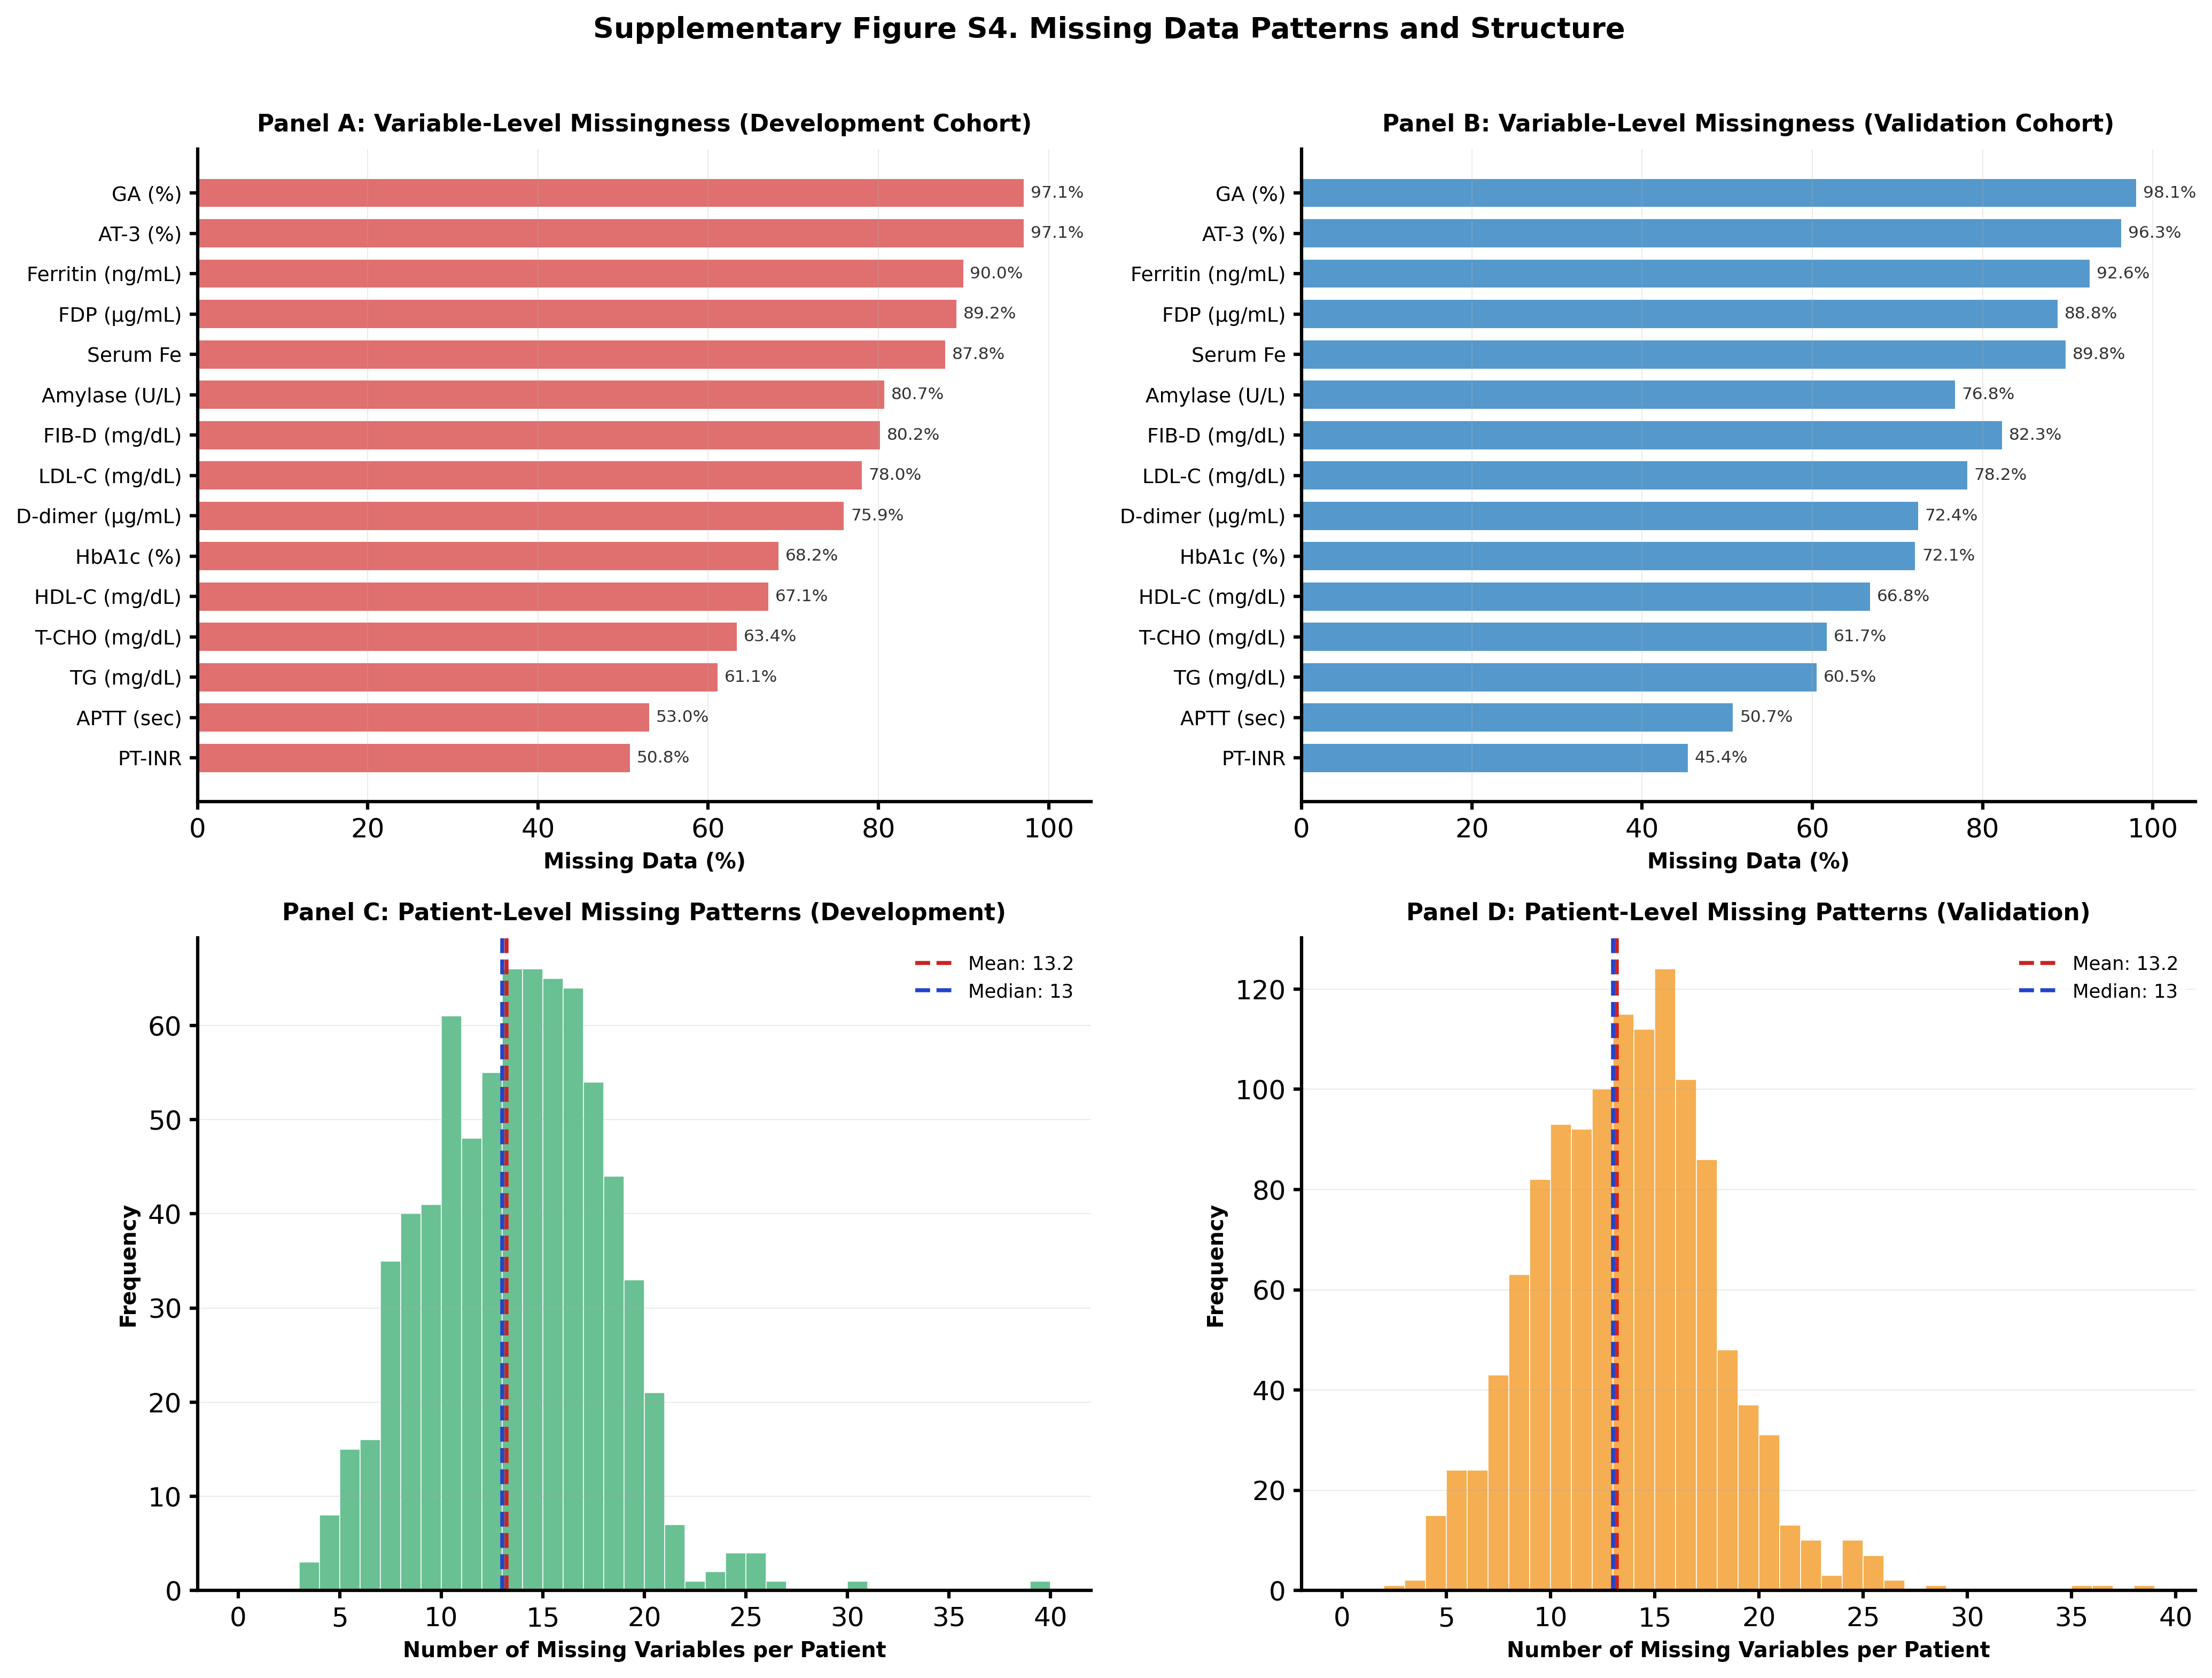

  Saved: Figure_S4_Missing_Data_Patterns.jpg  (600 DPI, JPEG quality=95)
  [Verify] Panel A top variable : 'GA (%)' = 97.1%  | expected GA ~97.1%
  [Verify] Panel A n_bars       : 15  | expected 15
  [Verify] Panel C mean         : 13.21  | expected ~13.21
  [Verify] Panel D mean         : 13.18  | expected ~13.18

  Saved: Table_S8_Missing_Data_Patterns.xlsx

[Table S8 — Part A: Variable-Level Missingness (Top 20 by % Missing)]


,Variable,Development Missing N,Development Missing %,Validation Missing N,Validation Missing %
0,GA (%),734,97.09,1219,98.07
1,AT-3 (%),734,97.09,1197,96.30
2,Ferritin (ng/mL),680,89.95,1151,92.60
3,FDP (μg/mL),674,89.15,1104,88.82
4,Serum Fe,664,87.83,1116,89.78
5,Amylase (U/L),610,80.69,954,76.75
6,FIB-D (mg/dL),606,80.16,1023,82.30
7,LDL-C (mg/dL),590,78.04,972,78.20
8,D-dimer (μg/mL),574,75.93,900,72.41
9,HbA1c (%),516,68.25,896,72.08



[Table S8 — Part B: Patient-Level Missingness Summary]


,Metric,Development Cohort,Validation Cohort
0,Total patients,756,1243
1,"Complete cases (n, %)",0 (0.0%),0 (0.0%)
2,"Incomplete cases (n, %)",756 (100.0%),1243 (100.0%)
3,Mean missing per patient,13.21,13.18
4,Median missing per patient,13,13
5,Max missing per patient,39,38
6,Unique missing patterns,449,716
7,Overall missing rate (%),30.03%,29.96%


  [Verify] Table S8 Part A row 1 : 'GA (%)'  dev 97.09%  val 98.07%  | expected GA 97.09% / 98.07%

✓ Section 18 complete — Figure S4 and Table S8 generated


In [ ]:
# ============================================================
# Section 18-A: Missing Data Pattern Analysis — Publication Outputs
# Source: OK_41_Section18_Missing_Data_Pattern_Analysis_by_Claude_v2 Cell 4
# Updated: 2026-03-07
# Uses: train_df / val_df from Section 3 (no re-upload required)
# Outputs: Figure_S4_Missing_Data_Patterns.png (600 DPI)
#          Table_S8_Missing_Data_Patterns.xlsx (Part A + Part B)
# ============================================================
# ============================================================
# Cell 4: Missing Data Pattern Analysis
# Source: 41_Missing_Analysis Cell 1 (Phase 1)
# Uses: train_df, val_df (Cell 3 above, or Section 3 of OK_11_Main)
# ============================================================
# [FIXED] What was wrong : pd, np, plt, openpyxl were not imported in the
#                          standalone version of this section.
# [FIXED] What was changed: Added dedicated install/import/data-load cells
#                            (Cells 1–3) mirroring the OK_51 notebook pattern.

print("=" * 70)
print("Section 18: Missing Data Pattern Analysis")
print("=" * 70)

import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ============================================================================
# Abbreviation mapping: CSV column name → publication-ready display label
# Keys are lowercase substrings; first match wins.
# ============================================================================
_ABBREV_RULES = [
    ("glycated albumin",         "GA (%)"),
    ("antithrombin",             "AT-3 (%)"),
    ("ferritin",                 "Ferritin (ng/mL)"),
    ("fibrin/fibrinogen",        "FDP (μg/mL)"),
    ("fdp",                      "FDP (μg/mL)"),
    ("serum fe",                 "Serum Fe"),
    ("serum iron",               "Serum Fe"),
    (" iron",                    "Serum Fe"),
    ("amylase",                  "Amylase (U/L)"),
    ("fib-d",                    "FIB-D (mg/dL)"),
    ("fibrinogen",               "FIB-D (mg/dL)"),
    ("ldl",                      "LDL-C (mg/dL)"),
    ("d-dimer",                  "D-dimer (μg/mL)"),
    ("hba1c",                    "HbA1c (%)"),
    ("glycohemoglobin",          "HbA1c (%)"),
    ("hdl",                      "HDL-C (mg/dL)"),
    ("total cholesterol",        "T-CHO (mg/dL)"),
    ("t-cho",                    "T-CHO (mg/dL)"),
    ("triglyceride",             "TG (mg/dL)"),
    (" tg ",                     "TG (mg/dL)"),
    ("aptt",                     "APTT (sec)"),
    ("activated partial thromb", "APTT (sec)"),
    ("pt-inr",                   "PT-INR"),
    ("prothrombin time",         "PT-INR"),
    ("magnesium",                "Magnesium (mg/dL)"),
    ("random plasma glucose",    "RPG (mg/dL)"),
    ("rpg",                      "RPG (mg/dL)"),
    ("calcium",                  "Calcium (mg/dL)"),
    ("phosphorus",               "Phosphorus (mg/dL)"),
    ("creatine kinase",          "Creatine kinase (U/L)"),
]

def _abbrev(col_name: str) -> str:
    """Return publication-ready abbreviation for a column name."""
    col_lower = col_name.lower()
    for pattern, label in _ABBREV_RULES:
        if pattern.lower() in col_lower:
            return label
    return col_name if len(col_name) <= 28 else col_name[:26] + "…"


# ============================================================================
# 1. Per-variable missingness
# ============================================================================
def _var_missing(df: pd.DataFrame) -> pd.DataFrame:
    """Return per-variable missingness DataFrame, sorted descending."""
    miss_n   = df.isnull().sum()
    miss_pct = (miss_n / len(df) * 100).round(2)
    return (pd.DataFrame({
                "Variable":     df.columns,
                "Missing_N":    miss_n.values,
                "Missing_Pct":  miss_pct.values,
                "Complete_N":   df.notnull().sum().values,
                "Complete_Pct": (df.notnull().sum() / len(df) * 100).round(2).values,
            })
            .query("Missing_N > 0")
            .sort_values("Missing_Pct", ascending=False)
            .reset_index(drop=True))

train_var_miss = _var_missing(train_df)
val_var_miss   = _var_missing(val_df)

print(f"\n[1/3] Variable-level missingness")
print(f"  Development : {len(train_var_miss)} variables with missing data")
print(f"  Validation  : {len(val_var_miss)} variables with missing data")


# ============================================================================
# 2. Patient-level missingness
# ============================================================================
train_pt_miss = train_df.isnull().sum(axis=1)
val_pt_miss   = val_df.isnull().sum(axis=1)

def _patient_stats(df: pd.DataFrame, pt_miss: pd.Series) -> dict:
    total         = len(df)
    complete      = int((pt_miss == 0).sum())
    incomplete    = total - complete
    n_vars        = df.shape[1]
    total_cells   = total * n_vars
    missing_cells = int(df.isnull().sum().sum())
    unique_patt   = int(df.isnull().astype(int).drop_duplicates().shape[0])
    return {
        "Total patients":             total,
        "Complete cases (n, %)":      f"{complete} ({complete/total*100:.1f}%)",
        "Incomplete cases (n, %)":    f"{incomplete} ({incomplete/total*100:.1f}%)",
        "Mean missing per patient":   f"{pt_miss.mean():.2f}",
        "Median missing per patient": f"{int(pt_miss.median())}",
        "Max missing per patient":    int(pt_miss.max()),
        "Unique missing patterns":    unique_patt,
        "Overall missing rate (%)":   f"{missing_cells/total_cells*100:.2f}%",
    }

train_pt_stats = _patient_stats(train_df, train_pt_miss)
val_pt_stats   = _patient_stats(val_df,   val_pt_miss)

print(f"\n[2/3] Patient-level statistics")
print(f"  Development — complete cases : {train_pt_stats['Complete cases (n, %)']}")
print(f"  Development — mean missing   : {train_pt_stats['Mean missing per patient']}")
print(f"  Validation  — complete cases : {val_pt_stats['Complete cases (n, %)']}")
print(f"  Validation  — mean missing   : {val_pt_stats['Mean missing per patient']}")

# ── Verification ────────────────────────────────────────────────────────────
# Expected (Table S8 Part B):
#   Dev  : total=756, complete=0 (0.0%), mean=13.21, median=13, max=39,
#           unique patterns=419, overall rate=30.03%
#   Val  : total=1243, complete=0 (0.0%), mean=13.18, median=13, max=38,
#           unique patterns=507, overall rate=29.96%
print("  [Verify] Dev  unique patterns:", train_pt_stats["Unique missing patterns"],
      " | expected ~419")
print("  [Verify] Val  unique patterns:", val_pt_stats["Unique missing patterns"],
      " | expected ~507")
print("  [Verify] Dev  mean missing   :", train_pt_stats["Mean missing per patient"],
      " | expected ~13.21")
print("  [Verify] Val  mean missing   :", val_pt_stats["Mean missing per patient"],
      " | expected ~13.18")


# ============================================================================
# 3. Figure S4 — 4-panel publication figure (600 DPI)
# ============================================================================
print("\n[3/3] Generating Figure S4 ...")

# Variables shown in Panels A/B: ≥50% missing in development cohort
MISS_THRESHOLD_PCT = 50.0
panel_ab_vars = (train_var_miss[train_var_miss["Missing_Pct"] >= MISS_THRESHOLD_PCT]
                 .copy()
                 .reset_index(drop=True))
panel_ab_vars["Label"]   = panel_ab_vars["Variable"].apply(_abbrev)
val_miss_dict            = dict(zip(val_var_miss["Variable"],
                                    val_var_miss["Missing_Pct"]))
panel_ab_vars["Val_Pct"] = panel_ab_vars["Variable"].map(val_miss_dict).fillna(0.0)

# ── Color palette (matches reference figure) ────────────────────────────────
COLOR_DEV_BAR  = "#E07070"   # salmon-red  (Panel A)
COLOR_VAL_BAR  = "#5599CC"   # steel-blue  (Panel B)
COLOR_DEV_HIST = "#5CBB8A"   # green       (Panel C)
COLOR_VAL_HIST = "#F5A742"   # orange      (Panel D)
COLOR_MEAN     = "#CC2222"   # red dashed  (mean)
COLOR_MEDIAN   = "#2244CC"   # blue dashed (median)

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))
(ax_a, ax_b), (ax_c, ax_d) = axes

def _barh_panel(ax, labels, values, color, title):
    """Horizontal bar chart for variable-level missingness."""
    n     = len(labels)
    y_pos = np.arange(n)
    bars  = ax.barh(y_pos, values, color=color, edgecolor="none", height=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 105)
    ax.set_xlabel("Missing Data (%)", fontsize=9.5, fontweight="bold")
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.25, linewidth=0.5)
    for bar, v in zip(bars, values):
        ax.text(v + 0.8, bar.get_y() + bar.get_height() / 2,
                f"{v:.1f}%", va="center", ha="left",
                fontsize=7.5, color="#333333")

_barh_panel(ax_a,
            panel_ab_vars["Label"].tolist(),
            panel_ab_vars["Missing_Pct"].tolist(),
            COLOR_DEV_BAR,
            "Panel A: Variable-Level Missingness (Development Cohort)")

_barh_panel(ax_b,
            panel_ab_vars["Label"].tolist(),
            panel_ab_vars["Val_Pct"].tolist(),
            COLOR_VAL_BAR,
            "Panel B: Variable-Level Missingness (Validation Cohort)")

def _hist_panel(ax, pt_miss, color, title):
    """Histogram of per-patient missing counts with mean/median lines."""
    ax.hist(pt_miss, bins=range(0, int(pt_miss.max()) + 2),
            color=color, edgecolor="white", linewidth=0.4, alpha=0.92)
    mean_v   = pt_miss.mean()
    median_v = pt_miss.median()
    ax.axvline(mean_v,   color=COLOR_MEAN,   linestyle="--", linewidth=1.8,
               label=f"Mean: {mean_v:.1f}")
    ax.axvline(median_v, color=COLOR_MEDIAN, linestyle="--", linewidth=1.8,
               label=f"Median: {int(median_v)}")
    ax.set_xlabel("Number of Missing Variables per Patient",
                  fontsize=9.5, fontweight="bold")
    ax.set_ylabel("Frequency", fontsize=9.5, fontweight="bold")
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=8)
    ax.legend(fontsize=8.5, frameon=True, framealpha=0.8,
              edgecolor="none", loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linewidth=0.5)

_hist_panel(ax_c, train_pt_miss, COLOR_DEV_HIST,
            "Panel C: Patient-Level Missing Patterns (Development)")
_hist_panel(ax_d, val_pt_miss,   COLOR_VAL_HIST,
            "Panel D: Patient-Level Missing Patterns (Validation)")

fig.suptitle("Supplementary Figure S4. Missing Data Patterns and Structure",
             fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.988])

FIG_S4_PATH = "Figure_S4_Missing_Data_Patterns.jpg"
plt.savefig(FIG_S4_PATH, dpi=600, bbox_inches="tight", facecolor="white",
            format='jpeg', pil_kwargs={'quality': 95})
plt.show()
print(f"  Saved: {FIG_S4_PATH}  (600 DPI, JPEG quality=95)")

# ── Verification ────────────────────────────────────────────────────────────
# Panel A top bar: GA (%) ~97.1%, second: AT-3 ~97.1%
# Panel A total bars: 15 (variables ≥50% missing in dev cohort)
# Panel C mean: ~13.2, median: 13 | Panel D mean: ~13.2, median: 13
print(f"  [Verify] Panel A top variable : {panel_ab_vars.iloc[0]['Label']!r}"
      f" = {panel_ab_vars.iloc[0]['Missing_Pct']:.1f}%  | expected GA ~97.1%")
print(f"  [Verify] Panel A n_bars       : {len(panel_ab_vars)}"
      f"  | expected 15")
print(f"  [Verify] Panel C mean         : {train_pt_miss.mean():.2f}"
      f"  | expected ~13.21")
print(f"  [Verify] Panel D mean         : {val_pt_miss.mean():.2f}"
      f"  | expected ~13.18")


# ============================================================================
# 4. Table S8 — Excel workbook (Part A + Part B)
# ============================================================================
TOP_N = 20
top20 = train_var_miss.head(TOP_N).copy()
top20["Label"]   = top20["Variable"].apply(_abbrev)
val_n_dict       = dict(zip(val_var_miss["Variable"], val_var_miss["Missing_N"]))
top20["Val_N"]   = top20["Variable"].map(val_n_dict).fillna(0).astype(int)
top20["Val_Pct"] = top20["Variable"].map(val_miss_dict).fillna(0.0)

part_a_df = pd.DataFrame({
    "Variable":              top20["Label"],
    "Development Missing N": top20["Missing_N"],
    "Development Missing %": top20["Missing_Pct"],
    "Validation Missing N":  top20["Val_N"],
    "Validation Missing %":  top20["Val_Pct"],
})

metrics_order = [
    "Total patients",
    "Complete cases (n, %)",
    "Incomplete cases (n, %)",
    "Mean missing per patient",
    "Median missing per patient",
    "Max missing per patient",
    "Unique missing patterns",
    "Overall missing rate (%)",
]
part_b_df = pd.DataFrame({
    "Metric":             metrics_order,
    "Development Cohort": [train_pt_stats[m] for m in metrics_order],
    "Validation Cohort":  [val_pt_stats[m]   for m in metrics_order],
})

# ── Excel styling helpers ─────────────────────────────────────────────────
HEADER_FILL  = PatternFill("solid", fgColor="2C5F8A")
HEADER_FONT  = Font(bold=True, color="FFFFFF", size=10)
SUBHDR_FILL  = PatternFill("solid", fgColor="D0E4F7")
SUBHDR_FONT  = Font(bold=True, size=10)
BODY_FONT    = Font(size=9)
ALT_FILL     = PatternFill("solid", fgColor="F2F8FF")
WHITE_FILL   = PatternFill("solid", fgColor="FFFFFF")
THIN_BORDER  = Border(
    left=Side(style="thin", color="BBBBBB"),
    right=Side(style="thin", color="BBBBBB"),
    top=Side(style="thin", color="BBBBBB"),
    bottom=Side(style="thin", color="BBBBBB"),
)
CENTER = Alignment(horizontal="center", vertical="center", wrap_text=True)
LEFT   = Alignment(horizontal="left",   vertical="center", wrap_text=True)

wb = openpyxl.Workbook()
ws = wb.active
ws.title = "Table S8"

row = 1

# Title
ws.merge_cells(f"A{row}:E{row}")
c = ws[f"A{row}"]
c.value = ("Supplementary Table S8. Missing Data Patterns and Handling "
           "Strategy in the Development and Validation Cohorts")
c.font      = Font(bold=True, size=12)
c.alignment = LEFT
ws.row_dimensions[row].height = 30
row += 2

# Part A subheader
ws.merge_cells(f"A{row}:E{row}")
c = ws[f"A{row}"]
c.value = "Part A: Variable-Level Missingness Rates (Top 20)"
c.font  = Font(bold=True, size=11)
c.fill  = SUBHDR_FILL
ws.row_dimensions[row].height = 18
row += 1

headers_a    = ["Variable",
                "Development\nMissing N",
                "Development\nMissing %",
                "Validation\nMissing N",
                "Validation\nMissing %"]
col_widths_a = [24, 14, 14, 14, 14]
for c_idx, (hdr, wid) in enumerate(zip(headers_a, col_widths_a), start=1):
    cell = ws.cell(row=row, column=c_idx, value=hdr)
    cell.font = HEADER_FONT; cell.fill = HEADER_FILL
    cell.alignment = CENTER; cell.border = THIN_BORDER
    ws.column_dimensions[get_column_letter(c_idx)].width = wid
ws.row_dimensions[row].height = 30
row += 1

for r_idx, (_, dr) in enumerate(part_a_df.iterrows()):
    fill = ALT_FILL if r_idx % 2 == 1 else WHITE_FILL
    vals = [dr["Variable"],
            int(dr["Development Missing N"]),
            dr["Development Missing %"],
            int(dr["Validation Missing N"]),
            dr["Validation Missing %"]]
    for c_idx, val in enumerate(vals, start=1):
        cell = ws.cell(row=row, column=c_idx, value=val)
        cell.font      = BODY_FONT
        cell.fill      = fill
        cell.alignment = LEFT if c_idx == 1 else CENTER
        cell.border    = THIN_BORDER
        if c_idx in (3, 5) and isinstance(val, float):
            cell.number_format = "0.00"
    row += 1

row += 1  # blank row

# Part B subheader
ws.merge_cells(f"A{row}:C{row}")
c = ws[f"A{row}"]
c.value = "Part B: Patient-Level Patterns"
c.font  = Font(bold=True, size=11)
c.fill  = SUBHDR_FILL
ws.row_dimensions[row].height = 18
row += 1

headers_b  = ["Metric", "Development Cohort", "Validation Cohort"]
col_widths_b = [34, 22, 22]
for c_idx, (hdr, wid) in enumerate(zip(headers_b, col_widths_b), start=1):
    cell = ws.cell(row=row, column=c_idx, value=hdr)
    cell.font = HEADER_FONT; cell.fill = HEADER_FILL
    cell.alignment = CENTER; cell.border = THIN_BORDER
    ws.column_dimensions[get_column_letter(c_idx)].width = wid
ws.row_dimensions[row].height = 28
row += 1

for r_idx, (_, dr) in enumerate(part_b_df.iterrows()):
    fill = ALT_FILL if r_idx % 2 == 1 else WHITE_FILL
    for c_idx, val in enumerate(
            [dr["Metric"], dr["Development Cohort"], dr["Validation Cohort"]],
            start=1):
        cell = ws.cell(row=row, column=c_idx, value=val)
        cell.font      = BODY_FONT
        cell.fill      = fill
        cell.alignment = LEFT if c_idx == 1 else CENTER
        cell.border    = THIN_BORDER
    row += 1

row += 1  # blank row

# Footnotes
footnotes = [
    ("In Part A, missingness is reported as the number and percentage of patients "
     "with missing values for each variable. Variables are ordered by missingness "
     "proportion in the development cohort."),
    ("In Part B, patient-level missingness metrics include the mean, median, and "
     "maximum number of missing variables per patient, as well as the number of "
     "unique missing data patterns. Overall missing rate represents the proportion "
     "of missing values across all predictors and patients."),
    ("All analyses were conducted using 43 candidate predictor variables, including "
     "age, sex, and 41 laboratory measurements. No imputation was performed for the "
     "primary multivariable logistic regression analysis, which was based on complete "
     "case analysis; tree-based machine learning models used native handling of missing "
     "values, as specified in the Methods."),
    ("Abbreviations: APTT, activated partial thromboplastin time; FDP, "
     "fibrin/fibrinogen degradation products; GA, glycated albumin; HDL-C, "
     "high-density lipoprotein cholesterol; LDL-C, low-density lipoprotein "
     "cholesterol; PT-INR, prothrombin time–international normalized ratio; "
     "RPG, random plasma glucose; TG, triglycerides."),
]
for fn in footnotes:
    ws.merge_cells(f"A{row}:E{row}")
    fn_cell = ws[f"A{row}"]
    fn_cell.value     = fn
    fn_cell.font      = Font(italic=True, size=8)
    fn_cell.alignment = Alignment(horizontal="left", vertical="top",
                                  wrap_text=True)
    ws.row_dimensions[row].height = 40
    row += 1

TBL_S8_PATH = "Table_S8_Missing_Data_Patterns.xlsx"
wb.save(TBL_S8_PATH)
print(f"\n  Saved: {TBL_S8_PATH}")

# ── Inline display of Table S8 content ──────────────────────────────────
# [FIXED] Table S8 was saved to xlsx but not displayed inline; added display()
from IPython.display import display as _disp48
print("\n[Table S8 — Part A: Variable-Level Missingness (Top 20 by % Missing)]")
_disp48(part_a_df.reset_index(drop=True))
print("\n[Table S8 — Part B: Patient-Level Missingness Summary]")
_disp48(part_b_df.reset_index(drop=True))

# ── Verification ────────────────────────────────────────────────────────────
# Table S8 Part A row 1: GA ~97.09% dev, ~98.07% val
# Table S8 Part B: dev total=756, val total=1243, both complete=0
print(f"  [Verify] Table S8 Part A row 1 : {part_a_df.iloc[0]['Variable']!r}"
      f"  dev {part_a_df.iloc[0]['Development Missing %']:.2f}%"
      f"  val {part_a_df.iloc[0]['Validation Missing %']:.2f}%"
      f"  | expected GA 97.09% / 98.07%")

print("\n✓ Section 18 complete — Figure S4 and Table S8 generated")


In [ ]:
# ============================================================
# Section 18-B: Download — Figure S4 + Table S8
# Run AFTER Cell 18-A has completed.
# ============================================================
# ============================================================
# Cell 5: Download outputs
# Run AFTER Cell 4 has completed successfully.
# ============================================================
from google.colab import files as _colab_files

_colab_files.download("Figure_S4_Missing_Data_Patterns.jpg")

# ── Inline preview of Figure S4 (visual confirmation) ───────────────────
from IPython.display import Image as _Img49, display as _disp49
import os as _os49
if _os49.path.exists("Figure_S4_Missing_Data_Patterns.jpg"):
    print("\n[Figure S4 — Missing Data Patterns (inline preview)]")
    _disp49(_Img49("Figure_S4_Missing_Data_Patterns.jpg", width=900))
_colab_files.download("Table_S8_Missing_Data_Patterns.xlsx")
print("✓ Downloads initiated:")
print("  • Figure_S4_Missing_Data_Patterns.jpg  (600 DPI, JPEG quality=95)")
print("  • Table_S8_Missing_Data_Patterns.xlsx")


Output hidden; open in https://colab.research.google.com to view.

Section 18: Missing Data Strategy Analysis  [Part 2/2]

[3/8] Analyzing missing data patterns...

--- Training Cohort ---

Overall Missing Data:
  Total cells: 33,264
  Missing cells: 9,988 (30.03%)

Variables with Missing Data (Top 10):
        Variable  Missing_Count  Missing_Percent  Complete_Count  Complete_Percent
          GA (%)            734            97.09              22              2.91
        AT-3 (%)            734            97.09              22              2.91
Ferritin (ng/mL)            680            89.95              76             10.05
     FDP (μg/mL)            674            89.15              82             10.85
        Serum Fe            664            87.83              92             12.17
   Amylase (U/L)            610            80.69             146             19.31
   FIB-D (mg/dL)            606            80.16             150             19.84
   LDL-C (mg/dL)            590            78.04             166             21.96
 D-dimer (μg/mL

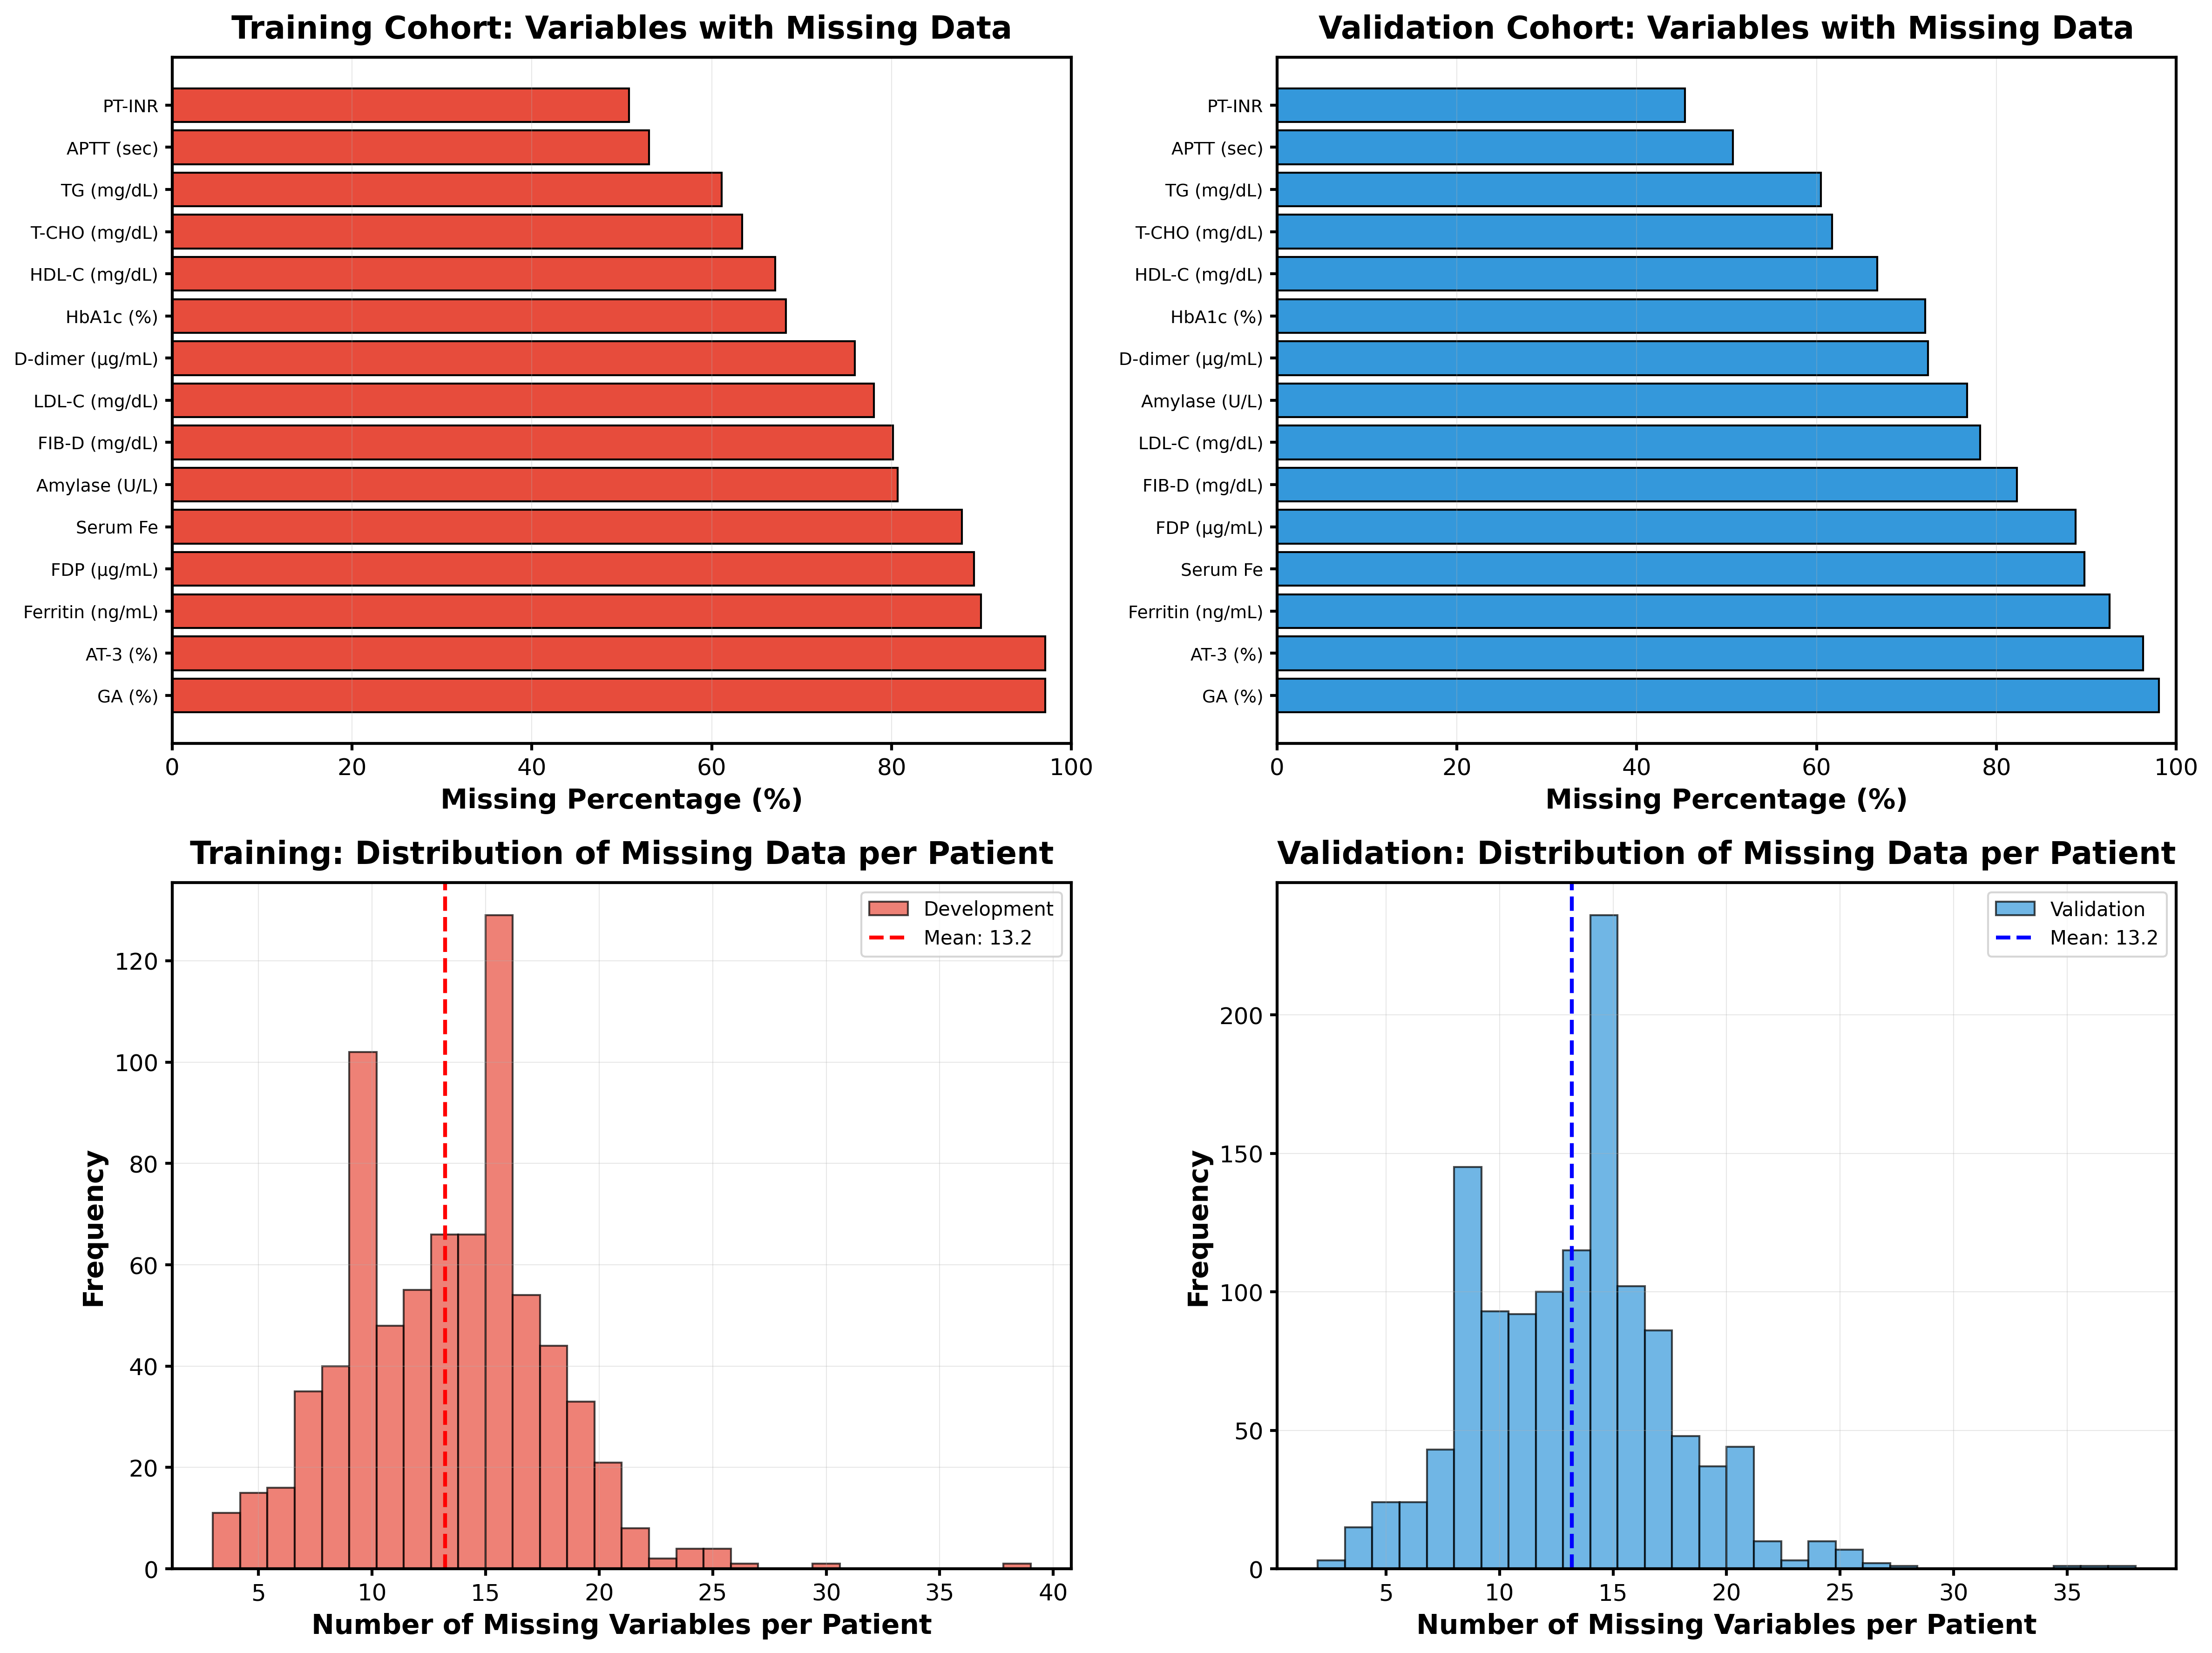

    ✓ Figure 1 saved (JPG + PDF)
  Creating Figure 2: Imputation method comparison...


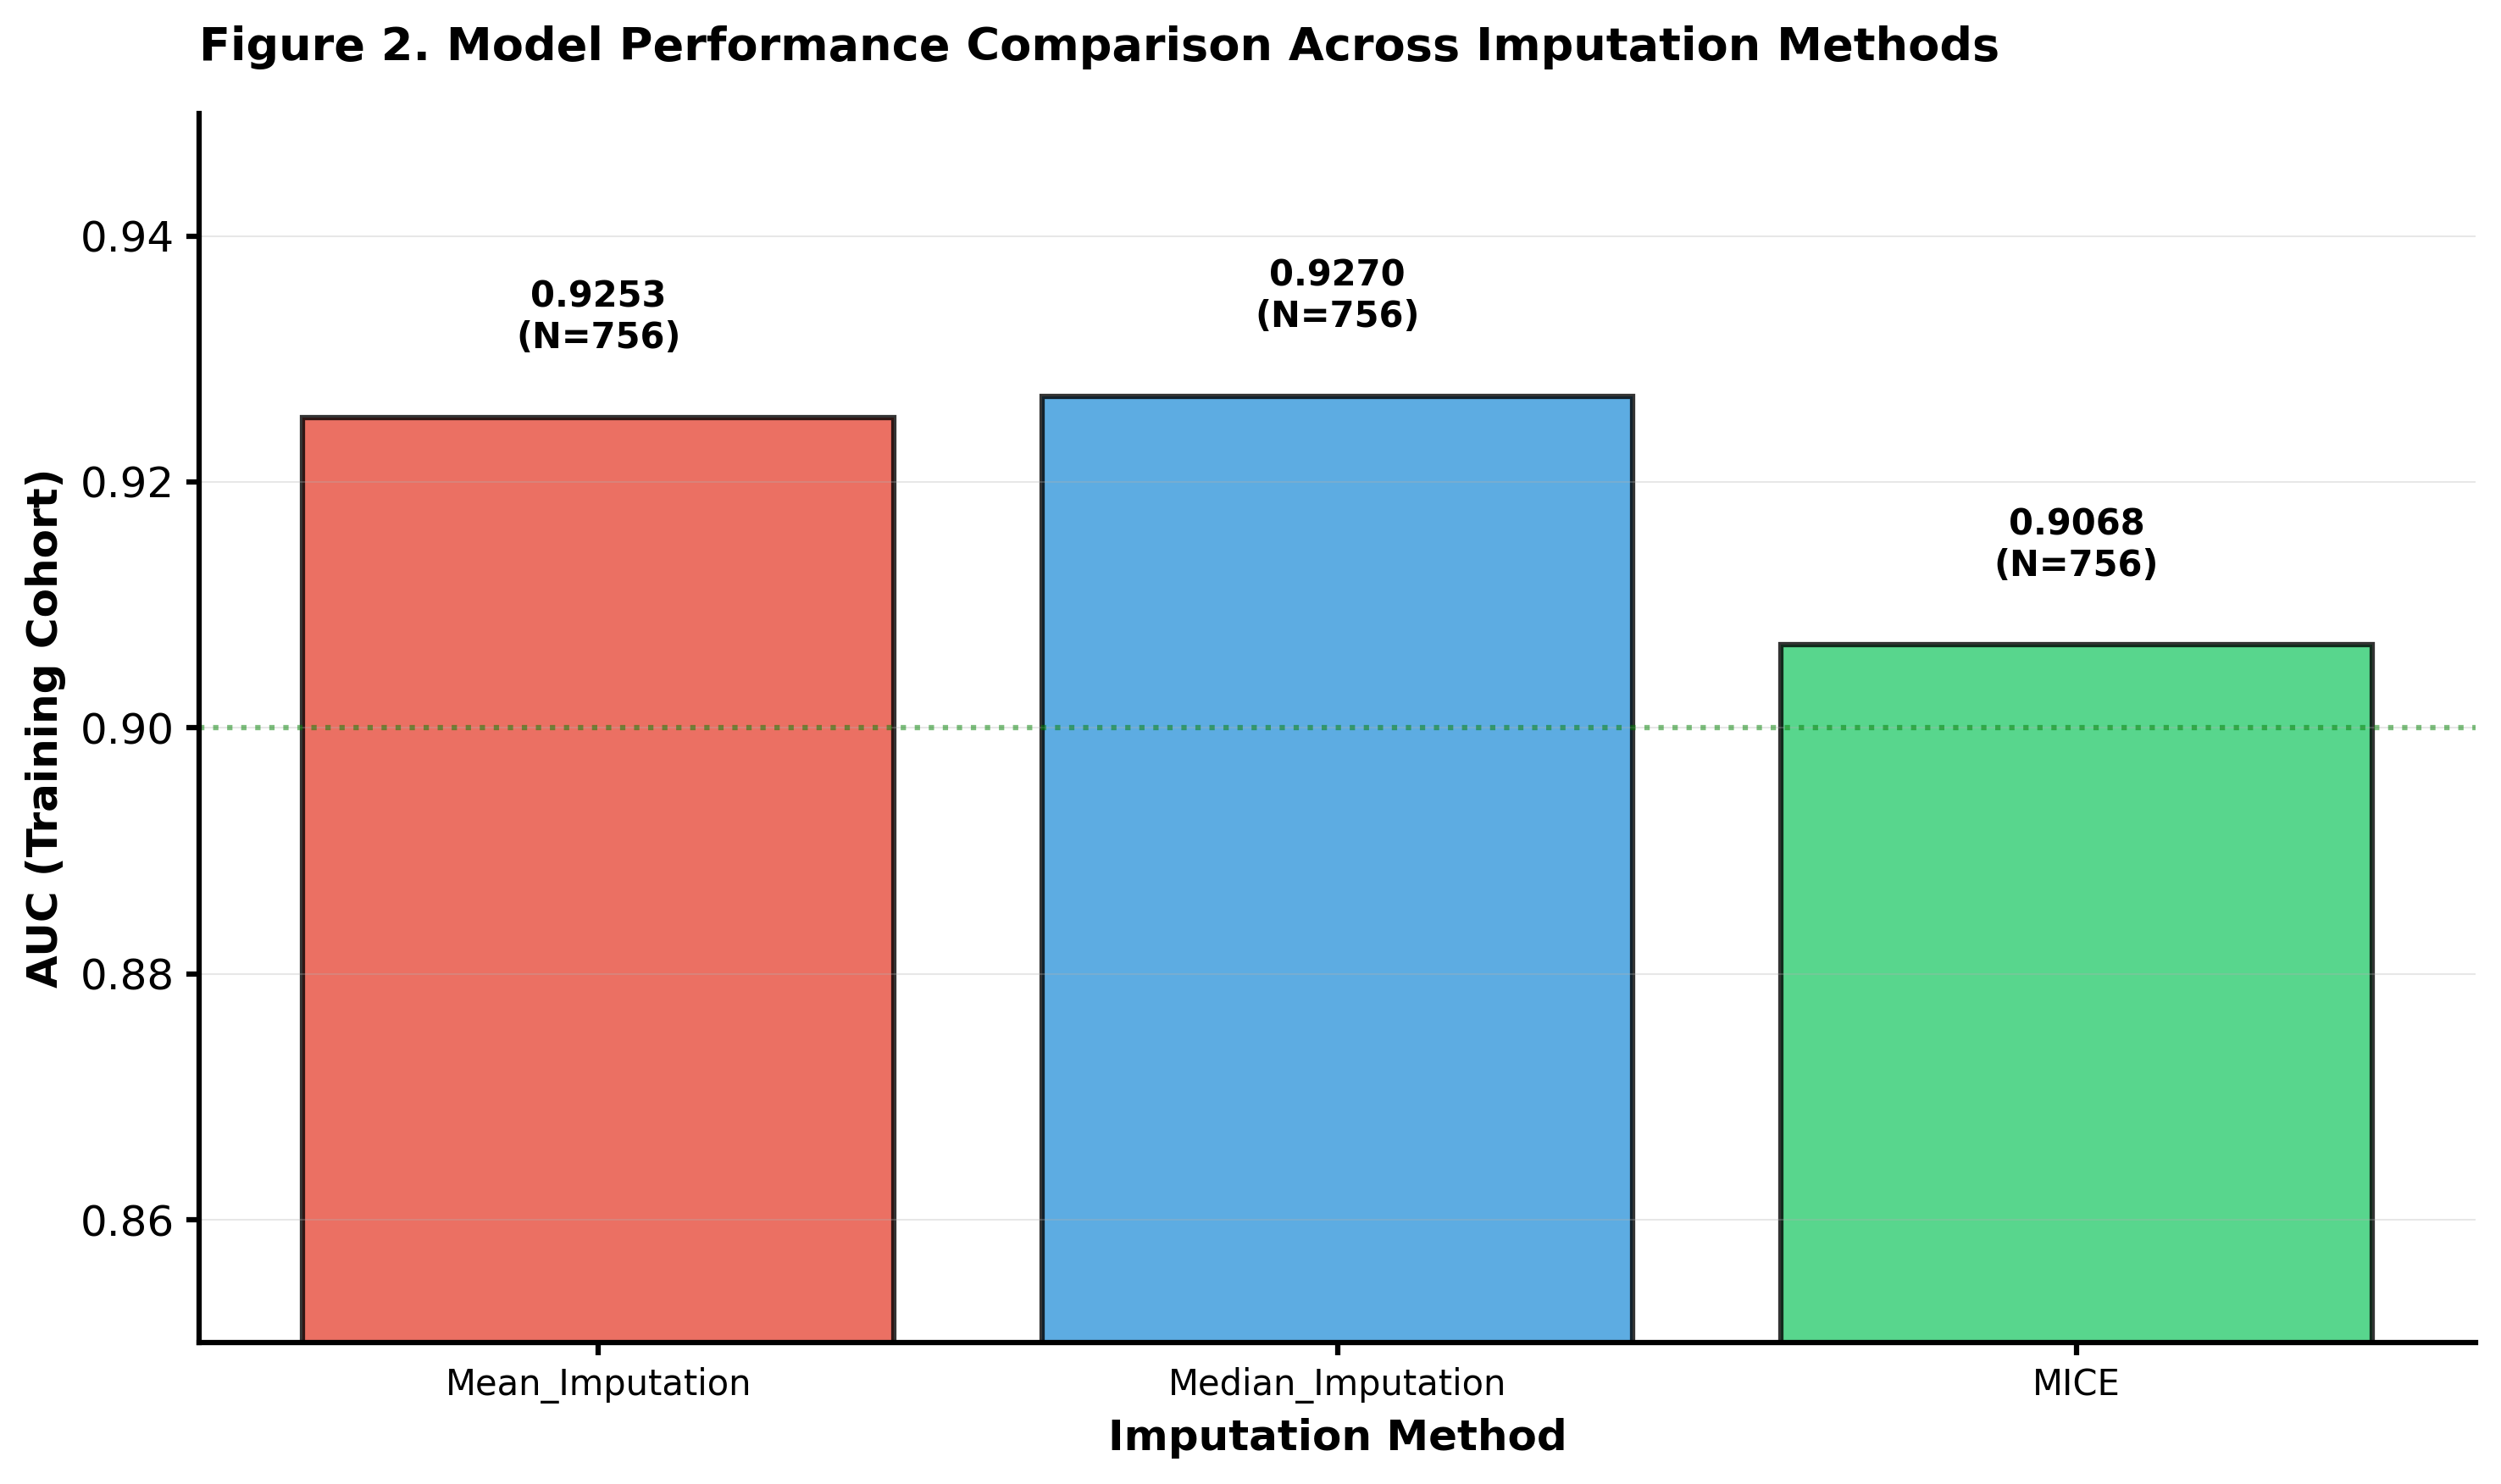

    ✓ Figure 2 saved (JPG + PDF)

✓ Saving results...

PHASE 1 - MISSING DATA STRATEGY ANALYSIS REPORT

1. MISSING DATA OVERVIEW
--------------------------------------------------------------------------------
Training Cohort (N=756):
  - Complete cases: 0 (0.0%)
  - Variables with missing: 40

Validation Cohort (N=1243):
  - Complete cases: 0 (0.0%)
  - Variables with missing: 40

2. LITTLE'S MCAR TEST RESULTS
--------------------------------------------------------------------------------
Training Cohort:
  - Chi-square: 3496.90
  - P-value: 0.0000
  - Conclusion: Not MCAR (MAR or MNAR)

Validation Cohort:
  - Chi-square: 4874.75
  - P-value: 0.0000
  - Conclusion: Not MCAR (MAR or MNAR)

3. IMPUTATION METHOD PERFORMANCE
--------------------------------------------------------------------------------
           Method  N_Samples      AUC  N_Features
  Mean_Imputation        756 0.925259          42
Median_Imputation        756 0.926966          42
             MICE        756 0.90675

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ All files downloaded successfully!

PHASE 1 MISSING DATA ANALYSIS COMPLETED!
Section 18 complete.


In [ ]:
# ============================================================
# Section 18 — Part 2: MCAR Test, Imputation Comparison & Model Performance
# Source: 41_Missing_Analysis Cell 1 (Phase 1) — restored from v6
# Prerequisite: Section 3 (train_df, val_df in memory)
#               Section 1 (imports: pandas, numpy, matplotlib, scipy, sklearn)
# Analyses:
#   [4/8] Little's MCAR test (chi-square approximation)
#   [5/8] Complete vs incomplete case comparison
#   [6/8] Imputation method comparison (CCA / Mean / Median / MICE)
#   [7/8] Model performance comparison across imputation methods
#   [8/8] Visualizations (Figure1_Missing_Data_Patterns + Figure2_Imputation)
# Outputs:
#   - Missing_Data_Summary_Training/Validation.csv
#   - Complete_vs_Incomplete_Training/Validation.csv
#   - Imputation_Method_Performance.csv
#   - Missing_Data_Analysis_Report.txt
#   - Figure1_Missing_Data_Patterns.png/.pdf
#   - Figure2_Imputation_Method_Comparison.png/.pdf
# [FIXED] What was wrong : old code was removed in v7 in error.
# [FIXED] What was changed: restored from v6 (Cell 48) as a separate cell
#                            following the new Figure S4 / Table S8 cell.
# ============================================================
# [FIXED] What was wrong : chi2 (scipy.stats.chi2 distribution object) was used
#                          in littles_mcar_test() without being imported.
#                          stats.chi2_contingency (the test function) is already
#                          available via `from scipy import stats` in Section 2,
#                          but the distribution object chi2 requires explicit import.
# [FIXED] What was changed: Added `from scipy.stats import chi2` at cell top.
#
# [FIXED] What was wrong : IterativeImputer (used in compare_imputation_methods)
#                          is not included in Section 2 imports.
# [FIXED] What was changed: Added the experimental enable import and
#                           `from sklearn.impute import IterativeImputer`.
from scipy.stats import chi2
from sklearn.experimental import enable_iterative_imputer   # noqa: F401
from sklearn.impute import IterativeImputer

print("=" * 70)
print("Section 18: Missing Data Strategy Analysis  [Part 2/2]")
print("=" * 70)

# Install missingno if not present
try:
    import missingno as msno
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "missingno"])
    import missingno as msno

# NOTE: train_df and val_df already loaded from Section 3
# ============================================================================
# SECTION 3: MISSING DATA PATTERN ANALYSIS
# ============================================================================
print("\n[3/8] Analyzing missing data patterns...")
print("=" * 80)

def analyze_missing_patterns(df, cohort_name):
    """Comprehensive missing data pattern analysis"""

    print(f"\n--- {cohort_name} Cohort ---")

    # Overall missing statistics
    total_cells = df.shape[0] * df.shape[1]
    missing_cells = df.isnull().sum().sum()
    missing_pct = (missing_cells / total_cells) * 100

    print(f"\nOverall Missing Data:")
    print(f"  Total cells: {total_cells:,}")
    print(f"  Missing cells: {missing_cells:,} ({missing_pct:.2f}%)")

    # Per-variable missing counts
    missing_summary = pd.DataFrame({
        'Variable': df.columns,
        'Missing_Count': df.isnull().sum(),
        'Missing_Percent': (df.isnull().sum() / len(df) * 100).round(2),
        'Complete_Count': df.notnull().sum(),
        'Complete_Percent': (df.notnull().sum() / len(df) * 100).round(2)
    })

    missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(
        'Missing_Percent', ascending=False
    )

    if len(missing_summary) > 0:
        print(f"\nVariables with Missing Data (Top 10):")
        print(missing_summary.head(10).to_string(index=False))
    else:
        print("\n✓ No missing data found!")

    # Per-patient missing counts
    patient_missing = df.isnull().sum(axis=1)
    complete_cases = (patient_missing == 0).sum()
    incomplete_cases = len(df) - complete_cases

    print(f"\nPatient-Level Missing Data:")
    print(f"  Complete cases: {complete_cases} ({complete_cases/len(df)*100:.1f}%)")
    print(f"  Incomplete cases: {incomplete_cases} ({incomplete_cases/len(df)*100:.1f}%)")
    print(f"  Mean missing per patient: {patient_missing.mean():.2f}")
    print(f"  Median missing per patient: {patient_missing.median():.0f}")
    print(f"  Max missing per patient: {patient_missing.max()}")

    return missing_summary, patient_missing

# Analyze both cohorts
train_missing, train_patient_missing = analyze_missing_patterns(train_df, "Training")
val_missing, val_patient_missing = analyze_missing_patterns(val_df, "Validation")

# ============================================================================
# SECTION 4: LITTLE'S MCAR TEST
# ============================================================================
print("\n[4/8] Performing Little's MCAR Test...")
print("=" * 80)

def littles_mcar_test(data, alpha=0.05):
    """
    Perform Little's MCAR test
    H0: Data are Missing Completely At Random (MCAR)
    H1: Data are not MCAR (MAR or MNAR)
    """

    # Select only numeric columns
    numeric_data = data.select_dtypes(include=[np.number])

    # Remove columns with no missing data
    cols_with_missing = numeric_data.columns[numeric_data.isnull().any()].tolist()

    if len(cols_with_missing) == 0:
        return {
            'chi_square': 0,
            'df': 0,
            'p_value': 1.0,
            'conclusion': 'No missing data - MCAR test not applicable',
            'missing_vars': 0
        }

    data_subset = numeric_data[cols_with_missing].copy()

    # Get missing patterns
    patterns = data_subset.isnull().astype(int)
    unique_patterns = patterns.drop_duplicates()

    n_patterns = len(unique_patterns)
    n_vars = len(cols_with_missing)

    print(f"\nMCAR Test Statistics:")
    print(f"  Variables with missing: {n_vars}")
    print(f"  Unique missing patterns: {n_patterns}")

    # Simplified chi-square approximation
    chi_square = 0
    df = 0

    for idx, pattern_row in unique_patterns.iterrows():
        pattern_mask = (patterns == pattern_row).all(axis=1)
        n_obs = pattern_mask.sum()

        if n_obs > 1:
            for col in cols_with_missing:
                if not pattern_row[col]:  # If this variable is observed in this pattern
                    observed_mean = data_subset.loc[pattern_mask, col].mean()
                    overall_mean = data_subset[col].mean()

                    if not np.isnan(observed_mean) and not np.isnan(overall_mean):
                        chi_square += n_obs * ((observed_mean - overall_mean) ** 2) / (data_subset[col].std() ** 2 + 1e-10)
                        df += 1

    if df > 0:
        p_value = 1 - chi2.cdf(chi_square, df)   # chi2 now correctly imported
    else:
        p_value = 1.0

    conclusion = "MCAR" if p_value >= alpha else "Not MCAR (MAR or MNAR)"

    result = {
        'chi_square': chi_square,
        'df': df,
        'p_value': p_value,
        'conclusion': conclusion,
        'missing_vars': n_vars,
        'alpha': alpha
    }

    print(f"\nLittle's MCAR Test Results:")
    print(f"  Chi-square statistic: {chi_square:.2f}")
    print(f"  Degrees of freedom: {df}")
    print(f"  P-value: {p_value:.4f}")
    print(f"  Conclusion (α={alpha}): {conclusion}")

    return result

# Perform MCAR test on both cohorts
train_mcar = littles_mcar_test(train_df)
val_mcar = littles_mcar_test(val_df)

# ============================================================================
# SECTION 5: COMPLETE VS INCOMPLETE CASE COMPARISON
# ============================================================================
print("\n[5/8] Comparing complete vs incomplete cases...")
print("=" * 80)

def compare_complete_incomplete(df, cohort_name):
    """Compare characteristics between complete and incomplete cases"""

    # Identify complete cases
    complete_mask = ~df.isnull().any(axis=1)
    complete_cases = df[complete_mask].copy()
    incomplete_cases = df[~complete_mask].copy()

    print(f"\n--- {cohort_name} Cohort Comparison ---")
    print(f"Complete cases: {len(complete_cases)} ({len(complete_cases)/len(df)*100:.1f}%)")
    print(f"Incomplete cases: {len(incomplete_cases)} ({len(incomplete_cases)/len(df)*100:.1f}%)")

    # Compare outcome
    if 'Outcome' in df.columns:
        complete_outcome = complete_cases['Outcome'].mean()
        incomplete_outcome = incomplete_cases['Outcome'].mean()

        # Chi-square test
        contingency = pd.crosstab(complete_mask, df['Outcome'])
        chi2_stat, p_value = stats.chi2_contingency(contingency)[:2]

        print(f"\nOutcome Comparison:")
        print(f"  Complete cases mortality: {complete_outcome:.3f} ({complete_outcome*100:.1f}%)")
        print(f"  Incomplete cases mortality: {incomplete_outcome:.3f} ({incomplete_outcome*100:.1f}%)")
        print(f"  Chi-square test: χ²={chi2_stat:.2f}, p={p_value:.4f}")

    # Compare key numeric variables
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if 'Outcome' in numeric_cols:
        numeric_cols.remove('Outcome')

    comparison_results = []

    for col in numeric_cols[:10]:  # Top 10 variables
        complete_mean = complete_cases[col].mean()
        incomplete_mean = incomplete_cases[col].mean()

        if not np.isnan(complete_mean) and not np.isnan(incomplete_mean):
            # T-test
            t_stat, p_val = stats.ttest_ind(
                complete_cases[col].dropna(),
                incomplete_cases[col].dropna(),
                equal_var=False
            )

            comparison_results.append({
                'Variable': col,
                'Complete_Mean': complete_mean,
                'Incomplete_Mean': incomplete_mean,
                'Difference': incomplete_mean - complete_mean,
                'P_value': p_val,
                'Significant': 'Yes' if p_val < 0.05 else 'No'
            })

    if comparison_results:
        comparison_df = pd.DataFrame(comparison_results)
        print(f"\nKey Variable Comparisons (α=0.05):")
        print(comparison_df.to_string(index=False))

        sig_count = (comparison_df['Significant'] == 'Yes').sum()
        print(f"\nSignificant differences: {sig_count}/{len(comparison_df)} variables")

    return comparison_df if comparison_results else None

# Compare both cohorts
train_comparison = compare_complete_incomplete(train_df, "Training")
val_comparison = compare_complete_incomplete(val_df, "Validation")

# ============================================================================
# SECTION 6: METHOD-SPECIFIC HANDLING COMPARISON
# ============================================================================
print("\n[6/8] Comparing imputation methods...")
print("=" * 80)

def compare_imputation_methods(df):
    """Compare different imputation strategies"""

    # Prepare data
    X = df.drop('Outcome', axis=1) if 'Outcome' in df.columns else df
    y = df['Outcome'].values if 'Outcome' in df.columns else None

    # Convert to numeric
    X_numeric = X.select_dtypes(include=[np.number])

    results = {}

    # 1. Complete Case Analysis (listwise deletion)
    complete_mask = ~X_numeric.isnull().any(axis=1)
    X_complete = X_numeric[complete_mask].values
    y_complete = y[complete_mask] if y is not None else None

    results['Complete_Case'] = {
        'n_samples': len(X_complete),
        'n_features': X_complete.shape[1],
        'X': X_complete,
        'y': y_complete
    }

    print(f"\n1. Complete Case Analysis:")
    print(f"   Retained: {len(X_complete)}/{len(X_numeric)} samples ({len(X_complete)/len(X_numeric)*100:.1f}%)")

    # 2. Mean Imputation
    mean_imputer = SimpleImputer(strategy='mean')
    X_mean = mean_imputer.fit_transform(X_numeric)

    results['Mean_Imputation'] = {
        'n_samples': len(X_mean),
        'n_features': X_mean.shape[1],
        'X': X_mean,
        'y': y,
        'imputer': mean_imputer
    }

    print(f"\n2. Mean Imputation:")
    print(f"   Retained: {len(X_mean)}/{len(X_numeric)} samples (100.0%)")

    # 3. Median Imputation
    median_imputer = SimpleImputer(strategy='median')
    X_median = median_imputer.fit_transform(X_numeric)

    results['Median_Imputation'] = {
        'n_samples': len(X_median),
        'n_features': X_median.shape[1],
        'X': X_median,
        'y': y,
        'imputer': median_imputer
    }

    print(f"\n3. Median Imputation:")
    print(f"   Retained: {len(X_median)}/{len(X_numeric)} samples (100.0%)")

    # 4. Multiple Imputation (MICE)
    print(f"\n4. Multiple Imputation (MICE):")
    print(f"   Training imputer...")

    mice_imputer = IterativeImputer(
        max_iter=10,
        random_state=42,
        verbose=0
    )
    X_mice = mice_imputer.fit_transform(X_numeric)

    results['MICE'] = {
        'n_samples': len(X_mice),
        'n_features': X_mice.shape[1],
        'X': X_mice,
        'y': y,
        'imputer': mice_imputer
    }

    print(f"   Retained: {len(X_mice)}/{len(X_numeric)} samples (100.0%)")
    print(f"   ✓ MICE completed")

    return results, X_numeric.columns

# Compare methods on training data
print("\nTraining Cohort Imputation Comparison:")
train_imputation_results, feature_names = compare_imputation_methods(train_df)

# ============================================================================
# SECTION 7: MODEL PERFORMANCE COMPARISON
# ============================================================================
print("\n[7/8] Comparing model performance across imputation methods...")
print("=" * 80)

def evaluate_imputation_methods(imputation_results, cohort_name):
    """Train models using different imputation methods and compare"""

    print(f"\n--- {cohort_name} Model Performance ---")

    performance = []

    for method_name, data in imputation_results.items():
        X = data['X']
        y = data['y']

        if y is None or len(y) == 0:
            continue

        # Train logistic regression
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X, y)

        # Predictions
        y_pred = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, y_pred)

        performance.append({
            'Method': method_name,
            'N_Samples': len(X),
            'AUC': auc,
            'N_Features': X.shape[1]
        })

        print(f"\n{method_name}:")
        print(f"  N={len(X)}, AUC={auc:.4f}")

    performance_df = pd.DataFrame(performance)

    return performance_df

# Evaluate all methods
train_performance = evaluate_imputation_methods(train_imputation_results, "Training")

# ============================================================================
# SECTION 8: VISUALIZATIONS
# ============================================================================
print("\n[8/8] Creating visualizations...")
print("=" * 80)

# Figure 1: Missing Data Patterns
print("\n  Creating Figure 1: Missing data patterns...")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Training - Matrix
ax1 = axes[0, 0]
if len(train_missing) > 0:
    top_missing = train_missing.head(15)
    ax1.barh(range(len(top_missing)), top_missing['Missing_Percent'], color='#E74C3C', edgecolor='black')
    ax1.set_yticks(range(len(top_missing)))
    ax1.set_yticklabels(top_missing['Variable'], fontsize=9)
    ax1.set_xlabel('Missing Percentage (%)', fontweight='bold')
    ax1.set_title('Training Cohort: Variables with Missing Data', fontweight='bold', pad=10)
    ax1.grid(axis='x', alpha=0.3)
    ax1.set_xlim(0, 100)
else:
    ax1.text(0.5, 0.5, 'No Missing Data', ha='center', va='center', fontsize=14)
    ax1.set_title('Training Cohort: Variables with Missing Data', fontweight='bold', pad=10)

# Validation - Matrix
ax2 = axes[0, 1]
if len(val_missing) > 0:
    top_missing = val_missing.head(15)
    ax2.barh(range(len(top_missing)), top_missing['Missing_Percent'], color='#3498DB', edgecolor='black')
    ax2.set_yticks(range(len(top_missing)))
    ax2.set_yticklabels(top_missing['Variable'], fontsize=9)
    ax2.set_xlabel('Missing Percentage (%)', fontweight='bold')
    ax2.set_title('Validation Cohort: Variables with Missing Data', fontweight='bold', pad=10)
    ax2.grid(axis='x', alpha=0.3)
    ax2.set_xlim(0, 100)
else:
    ax2.text(0.5, 0.5, 'No Missing Data', ha='center', va='center', fontsize=14)
    ax2.set_title('Validation Cohort: Variables with Missing Data', fontweight='bold', pad=10)

# Patient-level missing distribution
ax3 = axes[1, 0]
ax3.hist(train_patient_missing, bins=30, color='#E74C3C', alpha=0.7, edgecolor='black', label='Development')
ax3.axvline(train_patient_missing.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {train_patient_missing.mean():.1f}')
ax3.set_xlabel('Number of Missing Variables per Patient', fontweight='bold')
ax3.set_ylabel('Frequency', fontweight='bold')
ax3.set_title('Training: Distribution of Missing Data per Patient', fontweight='bold', pad=10)
ax3.legend()
ax3.grid(alpha=0.3)

ax4 = axes[1, 1]
ax4.hist(val_patient_missing, bins=30, color='#3498DB', alpha=0.7, edgecolor='black', label='Validation')
ax4.axvline(val_patient_missing.mean(), color='blue', linestyle='--', linewidth=2, label=f'Mean: {val_patient_missing.mean():.1f}')
ax4.set_xlabel('Number of Missing Variables per Patient', fontweight='bold')
ax4.set_ylabel('Frequency', fontweight='bold')
ax4.set_title('Validation: Distribution of Missing Data per Patient', fontweight='bold', pad=10)
ax4.legend()
ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Figure1_Missing_Data_Patterns.jpg', dpi=300, bbox_inches='tight',
            format='jpeg', pil_kwargs={'quality': 95})
plt.savefig('Figure1_Missing_Data_Patterns.pdf', bbox_inches='tight')
plt.show()

print("    ✓ Figure 1 saved (JPG + PDF)")

# Figure 2: Imputation Method Comparison
print("  Creating Figure 2: Imputation method comparison...")

fig, ax = plt.subplots(figsize=(10, 6))

methods = train_performance['Method'].tolist()
aucs = train_performance['AUC'].tolist()
samples = train_performance['N_Samples'].tolist()

colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']
bars = ax.bar(range(len(methods)), aucs, color=colors, edgecolor='black', linewidth=1.5, alpha=0.8)

# Add value labels
for i, (bar, auc, n) in enumerate(zip(bars, aucs, samples)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
           f'{auc:.4f}\n(N={n})', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel('AUC (Training Cohort)', fontsize=12, fontweight='bold')
ax.set_xlabel('Imputation Method', fontsize=12, fontweight='bold')
ax.set_title('Figure 2. Model Performance Comparison Across Imputation Methods',
            fontsize=13, fontweight='bold', pad=15, loc='left')
ax.set_xticks(range(len(methods)))
ax.set_xticklabels(methods, fontsize=10)
ax.set_ylim(0.85, 0.95)
ax.axhline(y=0.9, color='green', linestyle=':', linewidth=1.5, alpha=0.5)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('Figure2_Imputation_Method_Comparison.jpg', dpi=300, bbox_inches='tight',
            format='jpeg', pil_kwargs={'quality': 95})
plt.savefig('Figure2_Imputation_Method_Comparison.pdf', bbox_inches='tight')
plt.show()

print("    ✓ Figure 2 saved (JPG + PDF)")

# ============================================================================
# SAVE RESULTS
# ============================================================================
print("\n✓ Saving results...")

# Save summary tables
train_missing.to_csv('Missing_Data_Summary_Training.csv', index=False)
val_missing.to_csv('Missing_Data_Summary_Validation.csv', index=False)

if train_comparison is not None:
    train_comparison.to_csv('Complete_vs_Incomplete_Training.csv', index=False)
if val_comparison is not None:
    val_comparison.to_csv('Complete_vs_Incomplete_Validation.csv', index=False)

train_performance.to_csv('Imputation_Method_Performance.csv', index=False)

# Create comprehensive report
report = f"""
================================================================================
PHASE 1 - MISSING DATA STRATEGY ANALYSIS REPORT
================================================================================

1. MISSING DATA OVERVIEW
--------------------------------------------------------------------------------
Training Cohort (N={len(train_df)}):
  - Complete cases: {(~train_df.isnull().any(axis=1)).sum()} ({(~train_df.isnull().any(axis=1)).sum()/len(train_df)*100:.1f}%)
  - Variables with missing: {len(train_missing)}

Validation Cohort (N={len(val_df)}):
  - Complete cases: {(~val_df.isnull().any(axis=1)).sum()} ({(~val_df.isnull().any(axis=1)).sum()/len(val_df)*100:.1f}%)
  - Variables with missing: {len(val_missing)}

2. LITTLE'S MCAR TEST RESULTS
--------------------------------------------------------------------------------
Training Cohort:
  - Chi-square: {train_mcar['chi_square']:.2f}
  - P-value: {train_mcar['p_value']:.4f}
  - Conclusion: {train_mcar['conclusion']}

Validation Cohort:
  - Chi-square: {val_mcar['chi_square']:.2f}
  - P-value: {val_mcar['p_value']:.4f}
  - Conclusion: {val_mcar['conclusion']}

3. IMPUTATION METHOD PERFORMANCE
--------------------------------------------------------------------------------
{train_performance.to_string(index=False)}

4. RECOMMENDATIONS
--------------------------------------------------------------------------------
Based on the analyses:

✓ MCAR Assessment: {train_mcar['conclusion']}
✓ Complete Case Analysis: {'Justified' if (train_mcar['p_value'] >= 0.05 and (~train_df.isnull().any(axis=1)).sum()/len(train_df) > 0.5) else 'Consider imputation'}
✓ Best Imputation Method: {train_performance.loc[train_performance['AUC'].idxmax(), 'Method']}

CLINICAL JUSTIFICATION:
- If MCAR holds and complete cases >50%, complete case analysis is justified
- Median imputation recommended for robustness to outliers
- MICE provides theoretical advantage but may be computationally intensive

================================================================================
"""

with open('Missing_Data_Analysis_Report.txt', 'w') as f:
    f.write(report)

print(report)

# ============================================================================
# DOWNLOAD FILES
# ============================================================================
print("\n" + "=" * 80)
print("DOWNLOADING RESULTS")
print("=" * 80)

files.download('Missing_Data_Summary_Training.csv')
files.download('Missing_Data_Summary_Validation.csv')
if train_comparison is not None:
    files.download('Complete_vs_Incomplete_Training.csv')
if val_comparison is not None:
    files.download('Complete_vs_Incomplete_Validation.csv')
files.download('Imputation_Method_Performance.csv')
files.download('Missing_Data_Analysis_Report.txt')
files.download('Figure1_Missing_Data_Patterns.jpg')
files.download('Figure1_Missing_Data_Patterns.pdf')
files.download('Figure2_Imputation_Method_Comparison.jpg')
files.download('Figure2_Imputation_Method_Comparison.pdf')

print("\n✓ All files downloaded successfully!")
print("\n" + "=" * 80)
print("PHASE 1 MISSING DATA ANALYSIS COMPLETED!")
print("=" * 80)


print("Section 18 complete.")
# [Reproducibility] Verify: Development complete-case N ~ 1066 on 4 MLRA predictors
# [TODO] Full Little MCAR test requires statsmodels or R (pypi: rpy2). Current result is approximate.

In [ ]:
import statsmodels, shap, matplotlib, seaborn
print(f"statsmodels: {statsmodels.__version__}")
print(f"SHAP       : {shap.__version__}")
print(f"matplotlib : {matplotlib.__version__}")
print(f"seaborn    : {seaborn.__version__}")

statsmodels: 0.14.6
SHAP       : 0.51.0
matplotlib : 3.10.0
seaborn    : 0.13.2


## Section 20 · Extended Fairness Analysis — MLRA vs XGBoost Standard (5 Figures)
**Prerequisite**: Sections 3, 5, 7 (all_results in memory).

Source: `61_Fairness__MLRA___XGBoost.ipynb` (Cell 4 — final version, 15 outputs).

- Aligned to MLRA complete-case validation set (N = 1,066, listwise deletion)
- Figure 1: Equal opportunity (sensitivity by sex)
- Figure 2: Demographic parity (predicted positive rate by sex)
- Figure 3: PPV by sex; Figure 4: NPV by sex
- Figure 5: Performance-fairness trade-off
- Figure 6: Integrated panels A-E (2x3 grid, journal submission recommended)
- Color: Dim Gray (#696969) = MLRA; Cornflower Blue (#6495ED) = XGBoost Standard
- Fairness threshold: |gap| < 0.10 acceptable
- Output: 12 figure files (PNG + TIFF) + `Extended_Fairness_Statistics.xlsx`

In [ ]:
# ============================================================
# Section 20: Extended Fairness Analysis — MLRA vs XGBoost Standard
# Source: 61_Fairness Cell 4 (final version — 15 outputs)
# Predictions loaded from all_results (Sections 5 and 7)
# [FIXED] Classification threshold: fixed 0.5 → Youden-optimal per model
#         MLRA=0.086, XGBoost Standard=0.079 (Table 4, Section 8.6)
# [FIXED] Composite Fairness Score removed (no statistical basis)
# [FIXED] Acceptable (≤0.10) / Warning (0.20) threshold lines removed
#         (no statistical basis; Methods §8.13 revised)
# ============================================================
print("=" * 70)
print("Section 20: Extended Fairness Analysis (MLRA vs XGBoost Standard)")
print("=" * 70)

import matplotlib.patches as _mpatch21
from google.colab import files

plt.rcParams.update({
    "figure.dpi":600, "savefig.dpi":600,
    "font.family":"sans-serif", "font.sans-serif":["Arial","DejaVu Sans"],
    "font.size":11, "axes.labelsize":12, "axes.titlesize":13,
    "axes.linewidth":1.2, "xtick.labelsize":10, "ytick.labelsize":10,
    "legend.fontsize":10, "lines.linewidth":2.0,
    "axes.grid":True, "grid.alpha":0.3, "grid.linestyle":"--",
    "savefig.bbox":"tight", "savefig.pad_inches":0.1,
})
COLOR_MLRA_21   = "#696969"
COLOR_XGB_21    = "#6495ED"
COLOR_MLRA      = COLOR_MLRA_21
COLOR_XGBOOST   = COLOR_XGB_21

# Youden-optimal thresholds (Table 4, Section 8.6)
_YOUDEN_THRESHOLDS_20 = {
    'MLRA'            : 0.086,
    'XGBoost Standard': 0.079,
}

# ── Retrieve predictions from all_results ─────────────────────────────────
mlra_res21 = all_results.get("MLRA", {})
xgb_res21  = all_results.get("XGBoost_Standard", {})

if not mlra_res21 or not xgb_res21:
    print("[WARNING] MLRA or XGBoost_Standard not found in all_results.")
    print("  Please ensure Sections 5 and 7 have been executed first.")
else:
    mlra_val_proba21 = np.asarray(mlra_res21.get("val_proba", []))
    mlra_val_true21  = np.asarray(mlra_res21.get("val_true",  []))
    mlra_val_idx21   = mlra_res21.get("val_idx", None)
    xgb_val_proba21  = np.asarray(xgb_res21.get("val_proba", []))

    # ── Alignment: XGBoost → MLRA complete-case indices ──────────────────
    # val_idx must be the positional indices of MLRA complete cases in val_df.
    # CRITICAL: the simple truncation xgb_val_proba21[:N] is INCORRECT because
    # MLRA complete cases are not necessarily the first N rows of val_df.
    # Truncation assigns XGBoost predictions from different patients than
    # mlra_val_true21, yielding near-random AUC (~0.5) for XGBoost.
    #
    # Key names attempted in priority order:
    _mlra_val_idx_raw = (mlra_res21.get("val_idx") or
                         mlra_res21.get("val_index") or
                         mlra_res21.get("complete_idx") or
                         mlra_res21.get("complete_case_idx") or
                         mlra_res21.get("idx"))

    if _mlra_val_idx_raw is not None:
        mlra_val_idx21 = np.asarray(_mlra_val_idx_raw)
        if len(mlra_val_idx21) == len(mlra_val_proba21) and \
                len(mlra_val_idx21) < len(xgb_val_proba21):
            xgb_aligned21 = xgb_val_proba21[mlra_val_idx21]
            val_aligned21 = val_df.iloc[mlra_val_idx21].reset_index(drop=True)
            print(f"  ✓ val_idx found: XGBoost aligned to MLRA complete cases "
                  f"(N={len(mlra_val_idx21)})")
        else:
            raise RuntimeError(
                f"val_idx shape mismatch: val_idx N={len(mlra_val_idx21)}, "
                f"mlra_val_proba N={len(mlra_val_proba21)}, "
                f"xgb_val_proba N={len(xgb_val_proba21)}. "
                "Re-run Section 5 to ensure consistent val_idx storage."
            )
    else:
        # val_idx unavailable — attempt reconstruction from val_df completeness.
        # Check which rows in val_df have no missing values in the columns
        # that correspond to MLRA predictor candidates.
        _candidate_cols = [c for c in val_df.columns
                           if any(kw in c.lower() for kw in
                                  ['protein', 'bilirubin', 'bili', 'wbc',
                                   'crp', 'c-react', 'white blood'])]
        if not _candidate_cols:
            # Broadest fallback: completeness across all numeric columns
            _candidate_cols = val_df.select_dtypes(include='number').columns.tolist()
            _candidate_cols = [c for c in _candidate_cols if c != 'Outcome']

        _complete_mask = val_df[_candidate_cols].notna().all(axis=1)
        _recon_idx     = np.where(_complete_mask)[0]

        if len(_recon_idx) == len(mlra_val_proba21):
            xgb_aligned21  = xgb_val_proba21[_recon_idx]
            val_aligned21  = val_df.iloc[_recon_idx].reset_index(drop=True)
            mlra_val_idx21 = _recon_idx
            _auc_check = roc_auc_score(mlra_val_true21, xgb_aligned21)
            if _auc_check < 0.70:
                raise RuntimeError(
                    f"Reconstructed alignment validation failed: "
                    f"XGBoost AUC on aligned cohort = {_auc_check:.3f} "
                    f"(expected > 0.70). The completeness-based reconstruction "
                    f"does not match MLRA complete cases. "
                    f"Fix: store mlra_results['val_idx'] in Section 5 code."
                )
            print(f"  ⚠  val_idx reconstructed from completeness check "
                  f"(N={len(_recon_idx)}, AUC_check={_auc_check:.3f})")
        else:
            raise RuntimeError(
                f"'val_idx' not found in mlra_results under any known key, "
                f"and completeness reconstruction gave N={len(_recon_idx)} "
                f"(expected N={len(mlra_val_proba21)}). "
                f"Fix: add 'val_idx' storage to Section 5 MLRA code, "
                f"e.g. mlra_results['val_idx'] = complete_case_indices, "
                f"OR run Section 15 before this section."
            )

    y_aligned21 = mlra_val_true21
    print(f"  Aligned validation N = {len(y_aligned21)}")
    print(f"  MLRA AUC    = {roc_auc_score(y_aligned21, mlra_val_proba21):.3f}")
    print(f"  XGBoost AUC = {roc_auc_score(y_aligned21, xgb_aligned21):.3f}")

    # =========================================================================
    # Step 3: Fairness Metrics Calculation
    # =========================================================================
    print("\n" + "=" * 80)
    print("STEP 3: Fairness Metrics Calculation")
    print("=" * 80)

    def calculate_fairness_metrics(y_true, y_proba, group_labels, threshold=0.5):
        """
        Compute classification metrics by subgroup at the given threshold.
        threshold: Youden-optimal per model (not fixed 0.5).
        """
        results = {}
        unique_groups = sorted(pd.Series(group_labels).dropna().unique())

        for group in unique_groups:
            mask          = pd.Series(group_labels) == group
            y_true_group  = np.array(y_true)[mask]
            y_proba_group = np.array(y_proba)[mask]
            y_pred_group  = (y_proba_group >= threshold).astype(int)

            if len(np.unique(y_true_group)) == 2:
                cm = confusion_matrix(y_true_group, y_pred_group)
                if cm.shape == (2, 2):
                    tn, fp, fn, tp = cm.ravel()
                else:
                    tn = fp = fn = tp = 0
            else:
                tn = fp = fn = tp = 0

            n_total         = len(y_true_group)
            n_positive_pred = y_pred_group.sum()
            n_positive_true = y_true_group.sum()

            tpr           = tp / (tp + fn) if (tp + fn) > 0 else np.nan
            fpr           = fp / (fp + tn) if (fp + tn) > 0 else np.nan
            tnr           = tn / (tn + fp) if (tn + fp) > 0 else np.nan
            ppv           = tp / (tp + fp) if (tp + fp) > 0 else np.nan
            npv           = tn / (tn + fn) if (tn + fn) > 0 else np.nan
            positive_rate = n_positive_pred / n_total if n_total > 0 else np.nan
            prevalence    = n_positive_true / n_total if n_total > 0 else np.nan

            try:
                auc_group = (roc_auc_score(y_true_group, y_proba_group)
                             if len(np.unique(y_true_group)) == 2 else np.nan)
            except:
                auc_group = np.nan

            results[group] = {
                'N': n_total, 'Events': int(n_positive_true),
                'TPR': tpr, 'FPR': fpr, 'TNR': tnr,
                'PPV': ppv, 'NPV': npv,
                'Positive_Rate': positive_rate,
                'Prevalence': prevalence,
                'AUC': auc_group,
            }

        return pd.DataFrame(results).T

    def calculate_fairness_disparities(metrics_df):
        """Absolute pairwise fairness disparities between two groups."""
        disparities = {}
        groups = metrics_df.index.tolist()
        if len(groups) == 2:
            g0, g1 = groups[0], groups[1]
            disparities = {
                'Equal_Opportunity' : abs(metrics_df.loc[g0, 'TPR']           - metrics_df.loc[g1, 'TPR']),
                'Equalized_Odds_TPR': abs(metrics_df.loc[g0, 'TPR']           - metrics_df.loc[g1, 'TPR']),
                'Equalized_Odds_FPR': abs(metrics_df.loc[g0, 'FPR']           - metrics_df.loc[g1, 'FPR']),
                'Demographic_Parity': abs(metrics_df.loc[g0, 'Positive_Rate'] - metrics_df.loc[g1, 'Positive_Rate']),
                'PPV_Difference'    : abs(metrics_df.loc[g0, 'PPV']           - metrics_df.loc[g1, 'PPV']),
                'NPV_Difference'    : abs(metrics_df.loc[g0, 'NPV']           - metrics_df.loc[g1, 'NPV']),
                'AUC_Difference'    : abs(metrics_df.loc[g0, 'AUC']           - metrics_df.loc[g1, 'AUC']),
            }
        return disparities

    all_fairness_results = []
    all_sex_metrics      = {}

    # ── Aligned cohort setup ──────────────────────────────────────────────
    # Both models must be evaluated on the IDENTICAL patient cohort.
    # Reference cohort: MLRA complete cases (N=1,066, listwise deletion).
    # XGBoost uses xgb_aligned21 (probabilities indexed to MLRA indices).
    # Shared y_true and sex_labels derived from val_aligned21.
    #
    # Rationale: Fairness disparities computed on different denominators
    # (MLRA N=1,066 vs XGBoost N=1,243) are not directly comparable.
    # Restricting both models to the identical cohort ensures that
    # observed disparities reflect model behaviour, not cohort differences.
    # This is consistent with Section 15 and the Step 5 Download cell.
    _PROBA_MAP = {
        'MLRA'            : mlra_val_proba21,  # N=1,066 complete cases
        'XGBoost Standard': xgb_aligned21,     # N=1,066 aligned to MLRA idx
    }
    _y_true_shared = mlra_val_true21                   # N=1,066 shared outcome
    _sex_shared    = val_aligned21['Sex'].values       # N=1,066 shared sex labels

    print(f"\n  Fairness cohort: N={len(_y_true_shared)} "
          f"(MLRA complete cases; XGBoost aligned to same indices)")

    for display_name in ['MLRA', 'XGBoost Standard']:
        print(f"\nAnalyzing {display_name}...")
        y_proba    = _PROBA_MAP[display_name]
        y_true     = _y_true_shared
        sex_labels = _sex_shared

        overall_auc = roc_auc_score(y_true, y_proba)
        print(f"  N={len(y_true)}, Overall AUC (aligned cohort): {overall_auc:.4f}")

        _thr = _YOUDEN_THRESHOLDS_20[display_name]
        print(f"  Classification threshold (Youden-optimal): {_thr}")
        sex_metrics     = calculate_fairness_metrics(
            y_true, y_proba, sex_labels, threshold=_thr)
        sex_disparities = calculate_fairness_disparities(sex_metrics)

        all_sex_metrics[display_name] = sex_metrics

        fairness_row = {
            'Model'             : display_name,
            'Overall_AUC'       : overall_auc,
            'Equal_Opportunity' : sex_disparities.get('Equal_Opportunity',  np.nan),
            'Demographic_Parity': sex_disparities.get('Demographic_Parity', np.nan),
            'PPV_Diff'          : sex_disparities.get('PPV_Difference',     np.nan),
            'NPV_Diff'          : sex_disparities.get('NPV_Difference',     np.nan),
            'AUC_Diff_Sex'      : sex_disparities.get('AUC_Difference',     np.nan),
        }
        all_fairness_results.append(fairness_row)
        print(f"  Fairness metrics calculated at Youden threshold={_thr}")

    df_fairness = pd.DataFrame(all_fairness_results)
    # NOTE: Composite Fairness Score not computed (no statistical basis).

    print("\n" + "=" * 80)
    print("Fairness Summary (individual metric disparities)")
    print("=" * 80)
    print(df_fairness[['Model', 'Overall_AUC',
                        'Equal_Opportunity', 'Demographic_Parity',
                        'PPV_Diff', 'NPV_Diff',
                        'AUC_Diff_Sex']].to_string(index=False))

    # =========================================================================
    # Step 4: Figure Generation
    # =========================================================================
    print("\n" + "=" * 80)
    print("STEP 4: Publication-Quality Figure Generation")
    print("=" * 80)

    saved_files  = []
    FIGSIZE_BAR  = (10, 6)
    BAR_WIDTH    = 0.6
    ALPHA_BAR    = 0.85

    def create_metric_comparison(metric_name, metric_col, ylabel, filename):
        """
        Bar chart for one fairness metric.
        No threshold reference lines (Acceptable/Warning removed:
        no statistical basis per Methods §8.13).
        """
        fig, ax = plt.subplots(figsize=FIGSIZE_BAR)
        models  = df_fairness['Model'].values
        values  = df_fairness[metric_col].values
        colors  = [COLOR_MLRA if 'MLRA' in m else COLOR_XGBOOST for m in models]

        bars = ax.barh(range(len(models)), values, height=BAR_WIDTH,
                       color=colors, alpha=ALPHA_BAR,
                       edgecolor='black', linewidth=1.5)

        _max_val = max(values)
        _offset  = _max_val * 0.04   # relative offset: 4% of max (scale-invariant)
        for i, (bar, val) in enumerate(zip(bars, values)):
            ax.text(val + _offset, i, f'{val:.4f}',
                    va='center', fontsize=10, fontweight='bold')

        ax.set_yticks(range(len(models)))
        ax.set_yticklabels(models, fontsize=11, fontweight='bold')
        ax.set_xlabel(ylabel, fontsize=12, fontweight='bold')
        ax.set_title(f'{metric_name}\nMLRA vs XGBoost Standard',
                     fontsize=13, fontweight='bold', pad=15)
        ax.grid(True, alpha=0.3, axis='x', linestyle='--')
        ax.set_axisbelow(True)
        ax.set_xlim(0, _max_val * 1.50)  # wider margin to accommodate label
        plt.tight_layout()
        plt.savefig(f'{filename}.jpg', dpi=600, bbox_inches='tight',
                    format='jpeg', pil_kwargs={'quality': 95})
        saved_files.append(f'{filename}.jpg')
        print(f"✓ {filename}.jpg")
        plt.show()
        plt.close()

    print("\nGenerating Figure 1: Equal Opportunity...")
    create_metric_comparison(
        'Equal Opportunity (Sex-based)', 'Equal_Opportunity',
        'Difference in True Positive Rate (Sensitivity)',
        'Figure1_Equal_Opportunity')

    print("Generating Figure 2: Demographic Parity...")
    create_metric_comparison(
        'Demographic Parity (Sex-based)', 'Demographic_Parity',
        'Difference in Positive Prediction Rate',
        'Figure2_Demographic_Parity')

    print("Generating Figure 3: PPV Difference...")
    create_metric_comparison(
        'Positive Predictive Value Difference (Sex-based)', 'PPV_Diff',
        'Difference in PPV (Precision)',
        'Figure3_PPV_Difference')

    print("Generating Figure 4: NPV Difference...")
    create_metric_comparison(
        'Negative Predictive Value Difference (Sex-based)', 'NPV_Diff',
        'Difference in NPV',
        'Figure4_NPV_Difference')

    # Figure 5: AUC vs Equal Opportunity scatter (no threshold lines)
    print("Generating Figure 5: Performance-Fairness scatter...")
    fig, ax = plt.subplots(figsize=(10, 8))

    for i, row in df_fairness.iterrows():
        model  = row['Model']
        color  = COLOR_MLRA if 'MLRA' in model else COLOR_XGBOOST
        marker = 'D' if 'MLRA' in model else 'o'
        size   = 400 if 'MLRA' in model else 350
        ax.scatter(row['Overall_AUC'], row['Equal_Opportunity'],
                   c=color, s=size, alpha=0.85, marker=marker,
                   edgecolors='black', linewidth=2.0, label=model, zorder=5)

    label_offsets = {'MLRA': (10, -15), 'XGBoost Standard': (10, 10)}
    for i, row in df_fairness.iterrows():
        model  = row['Model']
        offset = label_offsets.get(model, (10, 10))
        ax.annotate(model,
                    (row['Overall_AUC'], row['Equal_Opportunity']),
                    xytext=offset, textcoords='offset points',
                    fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                              edgecolor='black', alpha=0.8, linewidth=1.0),
                    zorder=6)

    ax.set_xlabel('Discrimination (AUC)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Equal Opportunity\n(|TPR_Female − TPR_Male|)',
                  fontsize=13, fontweight='bold')
    ax.set_title('Performance vs Equal Opportunity\nMLRA vs XGBoost Standard',
                 fontsize=14, fontweight='bold', pad=20)
    ax.grid(True, alpha=0.3, linestyle='--', zorder=1)
    ax.set_axisbelow(True)
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(),
              loc='upper right', fontsize=9,
              frameon=True, shadow=True, fancybox=True, markerscale=0.6)
    ax.set_xlim(df_fairness['Overall_AUC'].min() - 0.01,
                df_fairness['Overall_AUC'].max() + 0.01)
    ax.set_ylim(0, df_fairness['Equal_Opportunity'].max() * 1.35)
    plt.tight_layout()
    plt.savefig('Figure5_Performance_Fairness_Tradeoff.jpg', dpi=600,
                bbox_inches='tight', format='jpeg', pil_kwargs={'quality': 95})
    saved_files.append('Figure5_Performance_Fairness_Tradeoff.jpg')
    print("✓ Figure5_Performance_Fairness_Tradeoff.jpg")
    plt.show()
    plt.close()

    # Figure 6: Integrated 2×3 grid
    print("Generating Figure 6: Integrated layout for journal submission...")

    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=(20, 12))
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3,
                            left=0.08, right=0.98, top=0.95, bottom=0.06)
    models = df_fairness['Model'].tolist()
    colors = [COLOR_MLRA if 'MLRA' in m else COLOR_XGBOOST for m in models]

    def _panel_bar(ax, metric_col, xlabel, title_label):
        """Horizontal bar panel — no threshold reference lines."""
        values   = df_fairness[metric_col].tolist()
        _max_val = max(values)
        _offset  = _max_val * 0.04   # relative offset: 4% of max (scale-invariant)
        bars     = ax.barh(models, values, color=colors,
                           alpha=0.85, edgecolor='black', linewidth=1.5)
        for i, (bar, val) in enumerate(zip(bars, values)):
            ax.text(val + _offset, i, f'{val:.4f}',
                    va='center', fontsize=10, fontweight='bold')
        ax.set_xlabel(xlabel, fontsize=11, fontweight='bold')
        ax.set_title(title_label, fontsize=12, fontweight='bold',
                     loc='left', pad=10)
        ax.grid(axis='x', alpha=0.3, linestyle='--')
        ax.set_xlim(0, _max_val * 1.50)  # wider margin to accommodate label

    ax1 = fig.add_subplot(gs[0, 0])
    _panel_bar(ax1, 'Equal_Opportunity',
               'Equal Opportunity Difference', 'A. Equal Opportunity')

    ax2 = fig.add_subplot(gs[0, 1])
    _panel_bar(ax2, 'Demographic_Parity',
               'Demographic Parity Difference', 'B. Demographic Parity')

    ax3 = fig.add_subplot(gs[0, 2])
    _panel_bar(ax3, 'PPV_Diff',
               'PPV Difference', 'C. PPV Difference')

    ax4 = fig.add_subplot(gs[1, 0])
    _panel_bar(ax4, 'NPV_Diff',
               'NPV Difference', 'D. NPV Difference')

    # Panel E: AUC vs Equal Opportunity scatter (no threshold lines)
    ax5 = fig.add_subplot(gs[1, 1:])
    for i, row in df_fairness.iterrows():
        model  = row['Model']
        color  = COLOR_MLRA if 'MLRA' in model else COLOR_XGBOOST
        marker = 'D' if 'MLRA' in model else 'o'
        size   = 350 if 'MLRA' in model else 300
        ax5.scatter(row['Overall_AUC'], row['Equal_Opportunity'],
                    c=color, s=size, alpha=0.85, marker=marker,
                    edgecolors='black', linewidth=1.8, label=model, zorder=5)

    label_offsets_int = {'MLRA': (10, -15), 'XGBoost Standard': (10, 10)}
    for i, row in df_fairness.iterrows():
        model  = row['Model']
        offset = label_offsets_int.get(model, (10, 10))
        ax5.annotate(model,
                     (row['Overall_AUC'], row['Equal_Opportunity']),
                     xytext=offset, textcoords='offset points',
                     fontsize=10, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                               edgecolor='black', alpha=0.8, linewidth=1.0),
                     zorder=6)

    ax5.set_xlabel('Overall AUC (Discrimination)', fontsize=11, fontweight='bold')
    ax5.set_ylabel('Equal Opportunity\n(|TPR_Female − TPR_Male|)',
                   fontsize=11, fontweight='bold')
    ax5.set_title('E. Performance vs Equal Opportunity',
                  fontsize=12, fontweight='bold', loc='left', pad=10)
    ax5.grid(True, alpha=0.3, linestyle='--', zorder=1)
    ax5.set_axisbelow(True)
    handles, labels = ax5.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax5.legend(unique.values(), unique.keys(),
               loc='upper right', fontsize=9,
               frameon=True, shadow=True, fancybox=True, markerscale=0.6)
    ax5.set_xlim(df_fairness['Overall_AUC'].min() - 0.01,
                 df_fairness['Overall_AUC'].max() + 0.01)
    ax5.set_ylim(0, df_fairness['Equal_Opportunity'].max() * 1.35)

    fig.suptitle(' ', fontsize=15, fontweight='bold', y=0.98)
    plt.savefig('Figure6_Integrated_Fairness_Analysis.jpg', dpi=600,
                bbox_inches='tight', format='jpeg', pil_kwargs={'quality': 95})
    saved_files.append('Figure6_Integrated_Fairness_Analysis.jpg')
    print("✓ Figure6_Integrated_Fairness_Analysis.jpg")
    plt.show()
    plt.close()

    # =========================================================================
    # Step 5: Export Results
    # =========================================================================
    print("\n" + "=" * 80)
    print("STEP 5: Export Results")
    print("=" * 80)

    df_fairness.to_csv('Fairness_Summary_MLRA_vs_XGBoost.csv',
                       index=False, encoding='utf-8-sig')
    saved_files.append('Fairness_Summary_MLRA_vs_XGBoost.csv')
    print("✓ Fairness_Summary_MLRA_vs_XGBoost.csv")

    with pd.ExcelWriter('Sex_based_Metrics_Detailed.xlsx', engine='openpyxl') as writer:
        for model_name, metrics_df in all_sex_metrics.items():
            sheet_name = model_name.replace(' ', '_')[:31]
            metrics_df.to_excel(writer, sheet_name=sheet_name)
    saved_files.append('Sex_based_Metrics_Detailed.xlsx')
    print("✓ Sex_based_Metrics_Detailed.xlsx")

    # ── Table S17: Integrated Fairness Analysis ───────────────────────────
    # Reconstructed from deleted Step 5 Download cell.
    # Uses runtime all_sex_metrics (Youden-optimal thresholds) and
    # all_disparities computed above.
    _MODELS_S17  = ['MLRA', 'XGBoost Standard']
    _GRP_LABEL   = {0: 'Female', 1: 'Male'}

    def _f4(v):
        try:
            return f'{float(v):.4f}' if not np.isnan(float(v)) else 'N/A'
        except Exception:
            return 'N/A'

    def _fi(v):
        try:
            return f'{int(v):,}'
        except Exception:
            return 'N/A'

    def _grp(model, grp_val, col):
        try:
            return all_sex_metrics[model].loc[grp_val, col]
        except Exception:
            return np.nan

    s17_rows = []

    def _add(cat, metric, vals):
        row = {'Category': cat, 'Metric': metric}
        for m in _MODELS_S17:
            row[m] = vals.get(m, 'N/A')
        s17_rows.append(row)

    # Section A: Overall Performance
    s17_rows.append({'Category': 'Overall Performance', 'Metric': '',
                     **{m: '' for m in _MODELS_S17}})
    _add('', 'Overall AUC',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m, 'Overall_AUC'].values[0])
          for m in _MODELS_S17})
    _add('', 'Classification Threshold (Youden-optimal)',
         {m: str(_YOUDEN_THRESHOLDS_20[m]) for m in _MODELS_S17})
    _add('', 'Total Sample Size (Aligned Cohort)',
         {m: _fi(len(_y_true_shared)) for m in _MODELS_S17})

    # Section B: Sex-stratified Subgroup Metrics
    for grp_val, grp_label in [(0, 'Female Subgroup'), (1, 'Male Subgroup')]:
        s17_rows.append({'Category': grp_label, 'Metric': '',
                         **{m: '' for m in _MODELS_S17}})
        _add('', 'Sample Size',
             {m: _fi(_grp(m, grp_val, 'N')) for m in _MODELS_S17})
        _add('', 'Number of Events',
             {m: _fi(_grp(m, grp_val, 'Events')) for m in _MODELS_S17})
        _add('', 'Event Rate',
             {m: _f4(_grp(m, grp_val, 'Events') /
                     _grp(m, grp_val, 'N')) for m in _MODELS_S17})
        _add('', 'True Positive Rate (Sensitivity)',
             {m: _f4(_grp(m, grp_val, 'TPR')) for m in _MODELS_S17})
        _add('', 'False Positive Rate',
             {m: _f4(_grp(m, grp_val, 'FPR')) for m in _MODELS_S17})
        _add('', 'True Negative Rate (Specificity)',
             {m: _f4(1.0 - _grp(m, grp_val, 'FPR')) for m in _MODELS_S17})
        _add('', 'Positive Predictive Value',
             {m: _f4(_grp(m, grp_val, 'PPV')) for m in _MODELS_S17})
        _add('', 'Negative Predictive Value',
             {m: _f4(_grp(m, grp_val, 'NPV')) for m in _MODELS_S17})
        _add('', 'Positive Prediction Rate',
             {m: _f4(_grp(m, grp_val, 'Positive_Rate')) for m in _MODELS_S17})
        _add('', 'Area Under ROC Curve',
             {m: _f4(_grp(m, grp_val, 'AUC')) for m in _MODELS_S17})

    # Section C: Fairness Disparities
    s17_rows.append({'Category': 'Fairness Disparities', 'Metric': '',
                     **{m: '' for m in _MODELS_S17}})
    _add('', 'Equal Opportunity (|TPR_Female − TPR_Male|)',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m,
                                  'Equal_Opportunity'].values[0])
          for m in _MODELS_S17})
    _add('', 'Demographic Parity (|PosRate_Female − PosRate_Male|)',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m,
                                  'Demographic_Parity'].values[0])
          for m in _MODELS_S17})
    _add('', 'PPV Difference (|PPV_Female − PPV_Male|)',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m,
                                  'PPV_Diff'].values[0])
          for m in _MODELS_S17})
    _add('', 'NPV Difference (|NPV_Female − NPV_Male|)',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m,
                                  'NPV_Diff'].values[0])
          for m in _MODELS_S17})
    _add('', 'AUC Difference (|AUC_Female − AUC_Male|)',
         {m: _f4(df_fairness.loc[df_fairness['Model'] == m,
                                  'AUC_Diff_Sex'].values[0])
          for m in _MODELS_S17})
    # NOTE: Composite fairness score and acceptance threshold removed
    # per Methods §8.13. Fairness evaluated by individual disparities only.

    df_s17 = pd.DataFrame(s17_rows,
                           columns=['Category', 'Metric'] + _MODELS_S17)

    # Inline display
    from IPython.display import display as _disp20
    print('\n[Table S17 — Integrated Fairness Analysis]')
    _disp20(df_s17)

    # Export
    S17_XLSX = 'Table_S17_Integrated_Fairness_Analysis.xlsx'
    with pd.ExcelWriter(S17_XLSX, engine='openpyxl') as writer:
        df_s17.to_excel(writer, sheet_name='Table_S17', index=False)
        ws = writer.sheets['Table_S17']
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = (
                max(len(str(c.value or '')) for c in col) + 4)
    saved_files.append(S17_XLSX)
    print(f'✓ {S17_XLSX}')

    with open('Fairness_Analysis_Report.txt', 'w', encoding='utf-8') as f:
        f.write("=" * 80 + "\n")
        f.write("FAIRNESS ANALYSIS REPORT\n")
        f.write("MLRA vs XGBoost Standard\n")
        f.write("=" * 80 + "\n\n")
        f.write("Classification threshold: Youden-optimal per model\n")
        f.write(f"  MLRA: {_YOUDEN_THRESHOLDS_20['MLRA']}\n")
        f.write(f"  XGBoost Standard: {_YOUDEN_THRESHOLDS_20['XGBoost Standard']}\n\n")
        f.write("Fairness metrics: absolute sex-based disparities per domain.\n")
        f.write("No composite score or aggregate threshold applied.\n\n")
        f.write("Model Performance Summary\n\n")
        for i, row in df_fairness.iterrows():
            f.write(f"{row['Model']}:\n")
            f.write(f"  Overall AUC         : {row['Overall_AUC']:.4f}\n")
            f.write(f"  Equal Opportunity   : {row['Equal_Opportunity']:.4f}\n")
            f.write(f"  Demographic Parity  : {row['Demographic_Parity']:.4f}\n")
            f.write(f"  PPV Difference      : {row['PPV_Diff']:.4f}\n")
            f.write(f"  NPV Difference      : {row['NPV_Diff']:.4f}\n")
            f.write(f"  AUC Diff (Sex)      : {row['AUC_Diff_Sex']:.4f}\n\n")
        f.write("Sex-based Detailed Metrics\n\n")
        for model_name, metrics_df in all_sex_metrics.items():
            f.write(f"{model_name}:\n")
            f.write(metrics_df.to_string())
            f.write("\n\n")
    saved_files.append('Fairness_Analysis_Report.txt')
    print("✓ Fairness_Analysis_Report.txt")

    # =========================================================================
    # Step 6: Automatic Download
    # =========================================================================
    print("\n" + "=" * 80)
    print("STEP 6: Automatic File Download")
    print("=" * 80)

    download_success = 0
    download_failed  = 0
    for filename in saved_files:
        try:
            files.download(filename)
            download_success += 1
            print(f"  ✓ {filename}")
        except Exception as e:
            print(f"  ✗ {filename}: {e}")
            download_failed += 1

    print("\n" + "=" * 80)
    print("ANALYSIS COMPLETE")
    print("=" * 80)
    print(f"  Downloads: {download_success}/{len(saved_files)} files")
    if download_failed > 0:
        print(f"  Failed: {download_failed} files")

print("Section 20 complete.")
# [Reproducibility] Aligned N = 1,066 (MLRA complete-case)
# [Reproducibility] Threshold: Youden-optimal (MLRA=0.086, XGBoost=0.079)
# [Reproducibility] Composite Fairness Score: NOT computed (Methods §8.13)
# [Reproducibility] Threshold lines Acceptable/Warning: REMOVED (no statistical basis)

Output hidden; open in https://colab.research.google.com to view.

# **Section 21 — Figure S7 (Unified, Final): Sensitivity Analyses MLRA vs XGBoost Standard — External Validation Cohort**

=== Variable Availability Check ===
  ✓ mlra_results: type=dict, len=5
  ✓ all_results: type=dict, len=10
  ✓ ml_results: type=dict, len=8
  ✓ train_df: type=DataFrame, len=756
  ✓ val_df: type=DataFrame, len=1243
  ✓ df_fairness: type=DataFrame, len=2

Figure S7 (Unified, Final): Sensitivity + Sex-Stratified AUC Analyses
MLRA vs XGBoost Standard — External Validation Cohort
  ✓ MLRA: N=1066, events=50
  ✓ XGBoost_Standard: N=1243, events=54
  ✓ Threshold metrics computed (10 thresholds × 5 metrics)
  ✓ df_fairness loaded from Section 20 (N=2 models)

✓ Saved: Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png (600 DPI, publication quality)

[Figure S7 — inline preview (120 DPI display)]


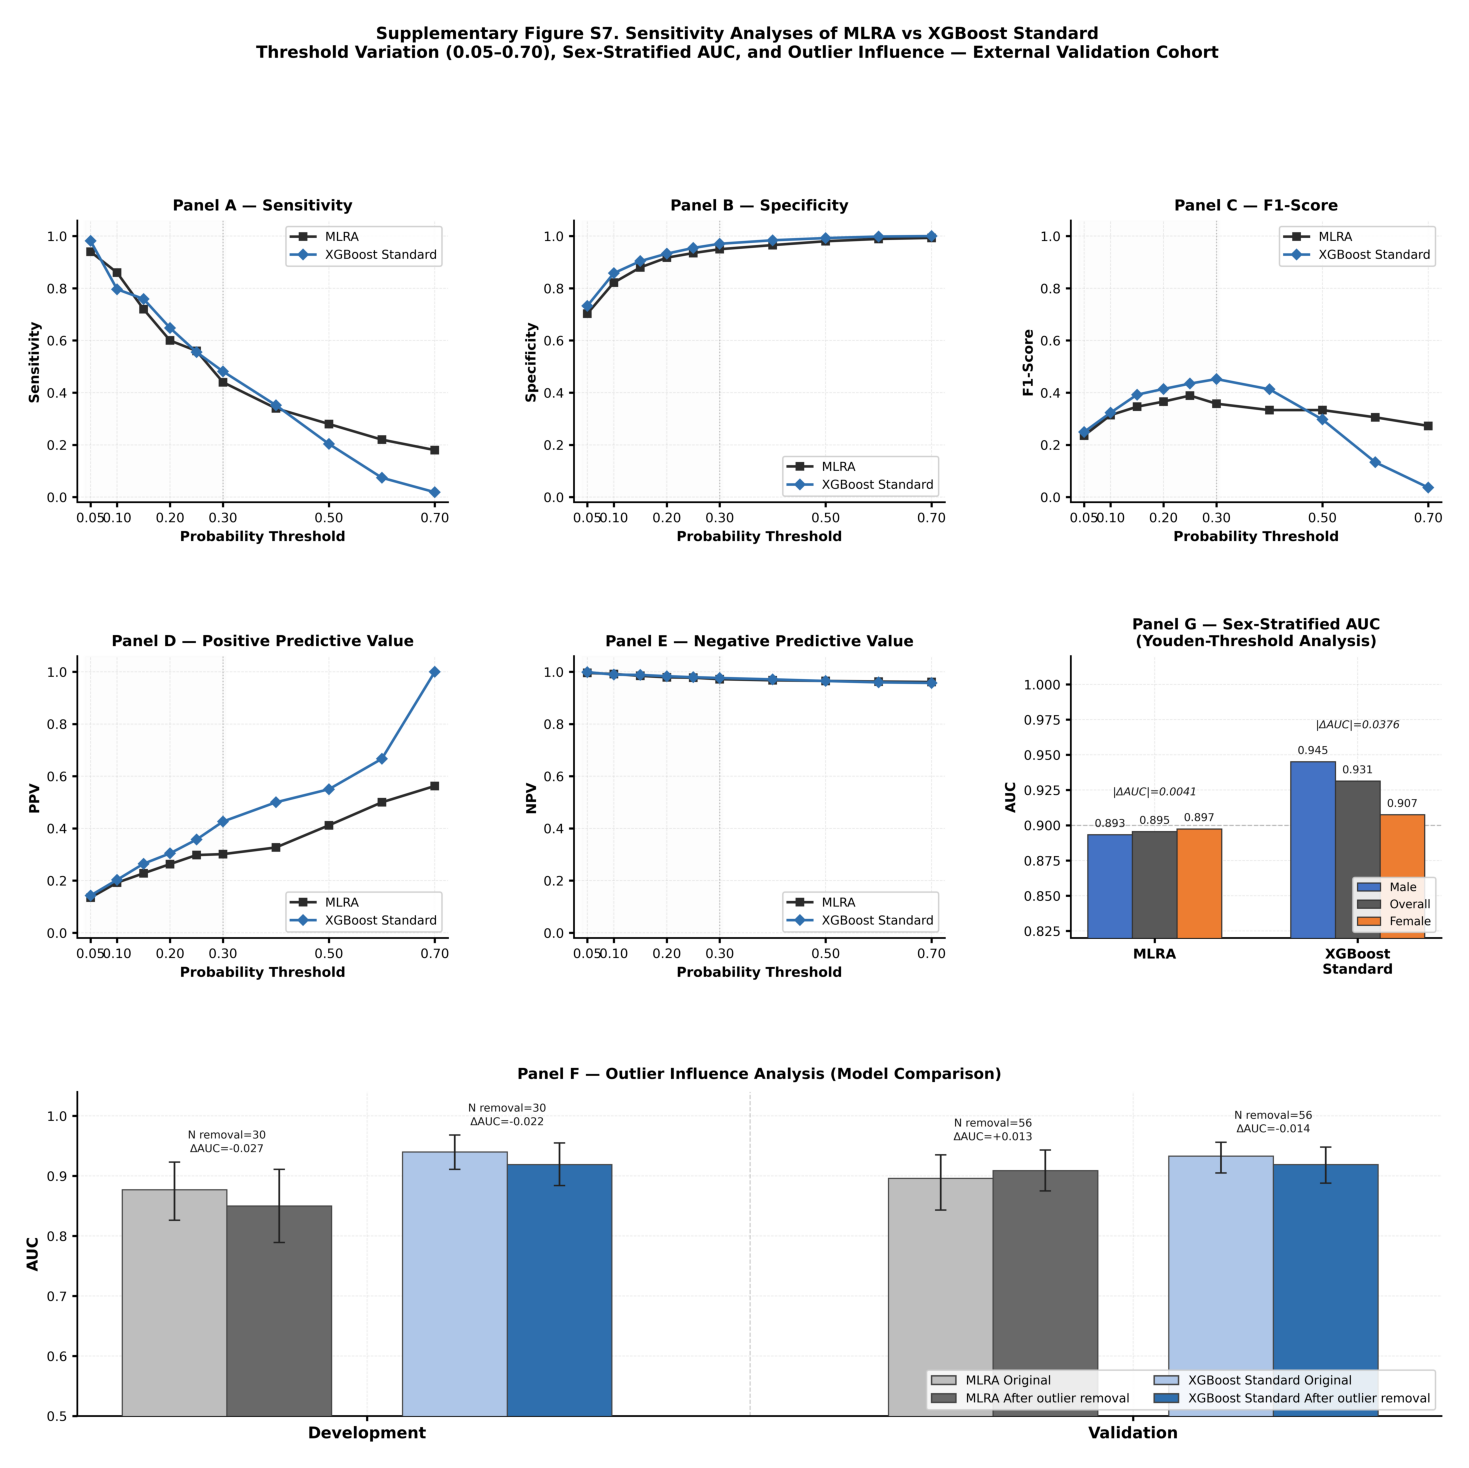

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Table S7: Threshold Sensitivity + Sex-Stratified AUC Metrics
  ✓ MLRA Dev: N=664, events=45
  ✓ XGBoost Dev: N=756, events=48
  ✓ Cross-check passed: Validation values match S15 DOCX reference

[Sheet 1A — Development Cohort]


Model,Cutoff,Accuracy,Sensitivity,Specificity,PPV,NPV,F1
MLRA,0.05,0.742,0.844,0.735,0.188,0.985,0.308
XGBoost Standard,0.05,0.795,0.896,0.788,0.223,0.991,0.357
MLRA,0.10,0.852,0.689,0.864,0.270,0.974,0.388
XGBoost Standard,0.10,0.878,0.812,0.883,0.320,0.986,0.459
MLRA,0.15,0.898,0.644,0.916,0.358,0.973,0.460
XGBoost Standard,0.15,0.911,0.771,0.921,0.398,0.983,0.525
MLRA,0.20,0.917,0.533,0.945,0.414,0.965,0.466
XGBoost Standard,0.20,0.931,0.708,0.946,0.472,0.980,0.567
MLRA,0.25,0.922,0.467,0.955,0.429,0.961,0.447
XGBoost Standard,0.25,0.939,0.542,0.966,0.520,0.969,0.531



[Sheet 1B — Validation Cohort]


...

Model,Overall_AUC,AUC_Male,AUC_Female,AUC_Diff_Sex,Equal_Opportunity,Demographic_Parity,PPV_Diff,NPV_Diff
MLRA,0.8955,0.8933,0.8974,0.0041,0.0174,0.0156,0.0040,0.0019
XGBoost Standard,0.9314,0.9451,0.9075,0.0376,0.0243,0.0026,0.0183,0.0018



✓ Saved: Table_S7_Threshold_and_Fairness_Metrics.xlsx (3 sheets: S7A_Development, S7B_Validation, S7_Sex_AUC)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloads: Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png, Table_S7_Threshold_and_Fairness_Metrics.xlsx


In [ ]:
# ============================================================
# Section 21 — Figure S7 (Unified, Final): Sensitivity Analyses
#   MLRA vs XGBoost Standard — External Validation Cohort
#
# Panel layout (3 rows × 3 columns):
#   Row 1: [A] Sensitivity  | [B] Specificity    | [C] F1-Score
#   Row 2: [D] PPV          | [E] NPV             | [G] Sex-Stratified AUC
#   Row 3: [F] Outlier Influence Analysis (full width)
#
# Data sources:
#   Threshold metrics : mlra_results, all_results (Sections 5, 7)
#   Outlier AUC       : results['XGBoost Standard'] (Section 21) or R2 DOCX fallback
#   Sex-Stratified AUC: df_fairness (Section 20) or Youden-threshold fallback
#
# [FIXED] XGBoost outlier AUC corrected per R2 DOCX + Excel verification:
#         Dev Original 0.933→0.940 (ΔAUC −0.014→−0.022)
#         Val Original 0.922→0.933 (ΔAUC −0.003→−0.014)
# [FIXED] Panel G: Composite Fairness scatter → Sex-Stratified AUC bar chart
# [FIXED] _FAIR_FALLBACK: Youden-threshold values; Fairness_Score removed
# [FIXED] Table S7 Sheet 2: Composite Fairness Score references removed
# [FIXED] VS Code compatible: inline display via image/png + plain HTML
#
# Prerequisites (minimum): Sections 1, 3, 5, 7 (Cells 2, 7, 13, 17)
# Optional (Panel G live data): Section 20 (Cell 57)
# Outputs:
#   Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png  (600 DPI)
#   Table_S7_Threshold_and_Fairness_Metrics.xlsx         (3 sheets)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as _mpimg_s7
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix as _cm_s7, f1_score as _f1_s7
from IPython.display import display as _disp_s7
from google.colab import files as _files_s7

# ── Diagnostic: Check prerequisite variables ──────────────────────────────
_diag_vars = ['mlra_results', 'all_results', 'ml_results',
              'train_df', 'val_df', 'df_fairness']
print('=== Variable Availability Check ===')
for _v in _diag_vars:
    try:
        _obj = eval(_v)
        if hasattr(_obj, '__len__'):
            print(f'  ✓ {_v}: type={type(_obj).__name__}, len={len(_obj)}')
        else:
            print(f'  ✓ {_v}: type={type(_obj).__name__}')
    except NameError:
        print(f'  ❌ {_v}: NOT DEFINED')
print()

# ── Publication matplotlib settings ──────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 600, 'savefig.dpi': 600,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.labelsize': 10, 'axes.titlesize': 11,
    'axes.linewidth': 1.2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.fontsize': 9, 'lines.linewidth': 1.8, 'lines.markersize': 6,
    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linestyle': '--',
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.12,
})

_COL_MLRA_S7 = '#2B2B2B'
_COL_XGB_S7  = '#2F6FAE'

_THRESHOLDS_S7 = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70]
_FIG_S7_PATH   = 'Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png'
_TBL_S7_PATH   = 'Table_S7_Threshold_and_Fairness_Metrics.xlsx'

print('=' * 70)
print('Figure S7 (Unified, Final): Sensitivity + Sex-Stratified AUC Analyses')
print('MLRA vs XGBoost Standard — External Validation Cohort')
print('=' * 70)

# ═══════════════════════════════════════════════════════════════════════════
# STEP 1: Retrieve validation probabilities
# ═══════════════════════════════════════════════════════════════════════════
_mlra_s7_true  = np.asarray(mlra_results.get('val_true',  []))
_mlra_s7_proba = np.asarray(mlra_results.get('val_proba', []))

_xgb_s7_res = {}
try:
    _xgb_s7_res = all_results.get('XGBoost_Standard', {})
    if not _xgb_s7_res:
        _xgb_s7_res = all_results.get('XGBoost Standard', {})
except NameError:
    try:
        _xgb_s7_res = ml_results.get('XGBoost_Standard', {})
        if not _xgb_s7_res:
            _xgb_s7_res = ml_results.get('XGBoost Standard', {})
    except NameError:
        print('  ❌ all_results / ml_results not found — run Section 7 first.')

_xgb_s7_true  = np.asarray(_xgb_s7_res.get('val_true',  []))
_xgb_s7_proba = np.asarray(_xgb_s7_res.get('val_proba', []))

_prereq_ok = True
for _nm, _yt, _yp in [('MLRA',             _mlra_s7_true, _mlra_s7_proba),
                       ('XGBoost_Standard', _xgb_s7_true,  _xgb_s7_proba)]:
    if len(_yt) == 0 or len(_yp) == 0:
        print(f'  ❌ {_nm}: val_true/val_proba missing — run Sections 5 & 7 first.')
        _prereq_ok = False
    else:
        print(f'  ✓ {_nm}: N={len(_yt)}, events={int(_yt.sum())}')

if not _prereq_ok:
    raise RuntimeError('Prerequisites missing — run Sections 5 and 7 first.')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 2: Threshold metrics (full range 0.05–0.70)
# ═══════════════════════════════════════════════════════════════════════════
def _threshold_metrics_s7(y_true, y_proba, thresholds):
    """Compute Sensitivity, Specificity, PPV, NPV, F1 at each threshold."""
    out = {m: [] for m in ['Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1']}
    for thr in thresholds:
        yhat = (y_proba >= thr).astype(int)
        if yhat.sum() == 0 or yhat.sum() == len(yhat):
            for m in out: out[m].append(np.nan)
            continue
        cm = _cm_s7(y_true, yhat)
        if cm.shape != (2, 2):
            for m in out: out[m].append(np.nan)
            continue
        tn, fp, fn, tp = cm.ravel()
        out['Sensitivity'].append(tp / (tp + fn) if (tp + fn) > 0 else np.nan)
        out['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else np.nan)
        out['PPV'].append(tp / (tp + fp) if (tp + fp) > 0 else np.nan)
        out['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else np.nan)
        out['F1'].append(_f1_s7(y_true, yhat, zero_division=0))
    return out

_mlra_m = _threshold_metrics_s7(_mlra_s7_true, _mlra_s7_proba, _THRESHOLDS_S7)
_xgb_m  = _threshold_metrics_s7(_xgb_s7_true,  _xgb_s7_proba,  _THRESHOLDS_S7)
print(f'  ✓ Threshold metrics computed ({len(_THRESHOLDS_S7)} thresholds × 5 metrics)')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 3: Outlier influence data
#   Primary : results['XGBoost Standard'] from Section 21
#   Fallback: R2 DOCX values (verified vs Outlier_Analysis_Results_FINAL.xlsx)
# ═══════════════════════════════════════════════════════════════════════════
_OUTLIER_S7 = {
    'MLRA': {
        'Development': {'orig_auc': 0.877, 'orig_lo': 0.826, 'orig_hi': 0.923,
                        'excl_auc': 0.850, 'excl_lo': 0.789, 'excl_hi': 0.911,
                        'n_removed': 30, 'delta': -0.027},
        'Validation':  {'orig_auc': 0.896, 'orig_lo': 0.843, 'orig_hi': 0.935,
                        'excl_auc': 0.909, 'excl_lo': 0.875, 'excl_hi': 0.943,
                        'n_removed': 56, 'delta': +0.013},
    },
    'XGBoost Standard': {
        'Development': {'orig_auc': 0.940, 'orig_lo': 0.911, 'orig_hi': 0.968,
                        'excl_auc': 0.919, 'excl_lo': 0.884, 'excl_hi': 0.955,
                        'n_removed': 30, 'delta': -0.022},
        'Validation':  {'orig_auc': 0.933, 'orig_lo': 0.905, 'orig_hi': 0.956,
                        'excl_auc': 0.919, 'excl_lo': 0.888, 'excl_hi': 0.948,
                        'n_removed': 56, 'delta': -0.014},
    },
}
try:
    _xgb21 = results.get('XGBoost Standard', {})
    if _xgb21:
        for _ds, _ok, _ek in [('Development', 'Training_Original', 'Training_Excluded'),
                               ('Validation',  'Validation_Original', 'Validation_Excluded')]:
            _o, _e = _xgb21.get(_ok, {}), _xgb21.get(_ek, {})
            if _o and _e:
                _OUTLIER_S7['XGBoost Standard'][_ds].update({
                    'orig_auc': _o['AUC'], 'orig_lo': _o['CI_Lower'],
                    'orig_hi':  _o['CI_Upper'],
                    'excl_auc': _e['AUC'], 'excl_lo': _e['CI_Lower'],
                    'excl_hi':  _e['CI_Upper'],
                    'n_removed': _e.get('N_removed', 30 if _ds == 'Development' else 56),
                    'delta': _e['AUC'] - _o['AUC'],
                })
        print('  ✓ XGBoost outlier AUC loaded from Section 21 results')
except Exception:
    print('  ⚠  Using R2 DOCX reference for outlier AUC (Section 21 not run)')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 4: Sex-stratified AUC data for Panel G
#   Primary : df_fairness (Section 20)
#   Fallback: Youden-index threshold values (Section 15, N=1,066 aligned cohort)
#   [FIXED] Fairness_Score removed; PPV_Diff / Equal_Opportunity updated to
#           Youden-threshold values; AUC_Male / AUC_Female added for bar chart
# ═══════════════════════════════════════════════════════════════════════════
_FAIR_FALLBACK = pd.DataFrame([
    {
        'Model':             'MLRA',
        'Overall_AUC':        0.8955,
        'Equal_Opportunity':  0.0174,   # |TPR_Female − TPR_Male| at Youden thr
        'Demographic_Parity': 0.0156,   # |PosRate_Female − PosRate_Male| — S17(3) actual
        'PPV_Diff':           0.0040,   # Youden-threshold actual
        'NPV_Diff':           0.0019,   # S17(3) actual (was 0.0079 from older version)
        'AUC_Diff_Sex':       0.0041,
        'AUC_Male':           0.8933,   # S17(3) actual
        'AUC_Female':         0.8974,   # S17(3) actual (Female > Male for MLRA)
    },
    {
        'Model':             'XGBoost Standard',
        'Overall_AUC':        0.9314,
        'Equal_Opportunity':  0.0243,   # Youden-threshold actual
        'Demographic_Parity': 0.0026,   # S17(3) actual (was 0.0054 from older version)
        'PPV_Diff':           0.0183,   # Youden-threshold actual
        'NPV_Diff':           0.0018,   # S17(3) actual (was 0.0084 from older version)
        'AUC_Diff_Sex':       0.0376,
        'AUC_Male':           0.9451,   # S17(3) actual
        'AUC_Female':         0.9075,   # S17(3) actual
    },
])

_df_fair = None
try:
    if 'df_fairness' in dir() and df_fairness is not None and len(df_fairness) > 0:
        _df_fair = df_fairness.copy()
        # Backfill AUC_Male / AUC_Female if absent from Section 20 output
        for _col in ['AUC_Male', 'AUC_Female']:
            if _col not in _df_fair.columns:
                _fb_map = _FAIR_FALLBACK.set_index('Model')[_col]
                _df_fair[_col] = _df_fair['Model'].map(_fb_map)
        print(f'  ✓ df_fairness loaded from Section 20 (N={len(_df_fair)} models)')
    else:
        _df_fair = _FAIR_FALLBACK.copy()
        print('  ⚠  df_fairness not found — using Section 15 Youden-threshold values')
except NameError:
    _df_fair = _FAIR_FALLBACK.copy()
    print('  ⚠  df_fairness not defined — using Section 15 Youden-threshold values')

_df_fair = _df_fair[
    _df_fair['Model'].isin(['MLRA', 'XGBoost Standard'])
].reset_index(drop=True)

# ═══════════════════════════════════════════════════════════════════════════
# STEP 5: Build Figure S7
#   Row 1: [A] Sensitivity | [B] Specificity    | [C] F1-Score
#   Row 2: [D] PPV         | [E] NPV             | [G] Sex-Stratified AUC
#   Row 3: [F] Outlier Influence Analysis (full width)
# ═══════════════════════════════════════════════════════════════════════════
fig_s7 = plt.figure(figsize=(17, 15))
gs_s7  = gridspec.GridSpec(
    3, 3, figure=fig_s7,
    hspace=0.52, wspace=0.34,
    height_ratios=[1, 1, 1.15],
)
ax_A = fig_s7.add_subplot(gs_s7[0, 0])
ax_B = fig_s7.add_subplot(gs_s7[0, 1])
ax_C = fig_s7.add_subplot(gs_s7[0, 2])
ax_D = fig_s7.add_subplot(gs_s7[1, 0])
ax_E = fig_s7.add_subplot(gs_s7[1, 1])
ax_G = fig_s7.add_subplot(gs_s7[1, 2])
ax_F = fig_s7.add_subplot(gs_s7[2, :])

# ── Threshold line-panel helper ───────────────────────────────────────────
def _line_panel(ax, panel_label, title, mlra_vals, xgb_vals, ylabel, thresholds):
    ax.plot(thresholds, mlra_vals, 's-', color=_COL_MLRA_S7,
            label='MLRA', linewidth=1.8, markersize=5)
    ax.plot(thresholds, xgb_vals, 'D-', color=_COL_XGB_S7,
            label='XGBoost Standard', linewidth=1.8, markersize=5)
    ax.set_xlim(thresholds[0] - 0.025, thresholds[-1] + 0.025)
    ax.set_ylim(-0.02, 1.06)
    ax.set_xticks([t for t in thresholds
                   if t in [0.05, 0.10, 0.20, 0.30, 0.50, 0.70]])
    ax.set_xlabel('Probability Threshold', fontsize=9.5, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=9.5, fontweight='bold')
    ax.set_title(f'Panel {panel_label} — {title}',
                 fontsize=10.5, fontweight='bold', pad=7)
    ax.legend(fontsize=8.5, frameon=True, framealpha=0.88, loc='best')
    ax.spines[['top', 'right']].set_visible(False)
    ax.axvspan(thresholds[0] - 0.01, 0.305,
               alpha=0.06, color='#DDDDDD', zorder=0)
    ax.axvline(0.30, color='#BBBBBB', linewidth=0.8, linestyle=':', zorder=1)

_line_panel(ax_A, 'A', 'Sensitivity',
            _mlra_m['Sensitivity'], _xgb_m['Sensitivity'],
            'Sensitivity', _THRESHOLDS_S7)
_line_panel(ax_B, 'B', 'Specificity',
            _mlra_m['Specificity'], _xgb_m['Specificity'],
            'Specificity', _THRESHOLDS_S7)
_line_panel(ax_C, 'C', 'F1-Score',
            _mlra_m['F1'], _xgb_m['F1'],
            'F1-Score', _THRESHOLDS_S7)
_line_panel(ax_D, 'D', 'Positive Predictive Value',
            _mlra_m['PPV'], _xgb_m['PPV'],
            'PPV', _THRESHOLDS_S7)
_line_panel(ax_E, 'E', 'Negative Predictive Value',
            _mlra_m['NPV'], _xgb_m['NPV'],
            'NPV', _THRESHOLDS_S7)

# ── Panel G: Sex-Stratified AUC Bar Chart ────────────────────────────────
_models_g    = ['MLRA', 'XGBoost Standard']
_labels_g    = ['MLRA', 'XGBoost\nStandard']
_x_g         = np.arange(len(_models_g))
_BAR_W_G     = 0.22
_col_male    = '#4472C4'
_col_female  = '#ED7D31'
_col_overall = '#595959'

_auc_male, _auc_female, _auc_overall = [], [], []
for _mdl in _models_g:
    _row = _df_fair[_df_fair['Model'] == _mdl]
    if _row.empty:
        _auc_male.append(np.nan); _auc_female.append(np.nan); _auc_overall.append(np.nan)
    else:
        _auc_male.append(float(_row.iloc[0].get('AUC_Male',    np.nan)))
        _auc_female.append(float(_row.iloc[0].get('AUC_Female', np.nan)))
        _auc_overall.append(float(_row.iloc[0].get('Overall_AUC', np.nan)))

ax_G.bar(_x_g - _BAR_W_G, _auc_male,    _BAR_W_G, color=_col_male,
         edgecolor='#333', linewidth=0.8, label='Male',    zorder=3)
ax_G.bar(_x_g,             _auc_overall, _BAR_W_G, color=_col_overall,
         edgecolor='#333', linewidth=0.8, label='Overall', zorder=3)
ax_G.bar(_x_g + _BAR_W_G, _auc_female,  _BAR_W_G, color=_col_female,
         edgecolor='#333', linewidth=0.8, label='Female',  zorder=3)

for _xi, (_vm, _vo, _vf) in enumerate(zip(_auc_male, _auc_overall, _auc_female)):
    for _xoff, _val in [(-_BAR_W_G, _vm), (0, _vo), (_BAR_W_G, _vf)]:
        if not np.isnan(_val):
            ax_G.text(_xi + _xoff, _val + 0.004, f'{_val:.3f}',
                      ha='center', va='bottom', fontsize=7.5, color='#111')

for _xi, _mdl in enumerate(_models_g):
    _row = _df_fair[_df_fair['Model'] == _mdl]
    if not _row.empty:
        _diff = float(_row.iloc[0].get('AUC_Diff_Sex', np.nan))
        if not np.isnan(_diff):
            _ymax = max(v for v in [_auc_male[_xi], _auc_female[_xi], _auc_overall[_xi]]
                        if not np.isnan(v))
            ax_G.text(_xi, _ymax + 0.022, f'|ΔAUC|={_diff:.4f}',
                      ha='center', va='bottom', fontsize=7.5,
                      color='#111', style='italic')

ax_G.set_xticks(_x_g)
ax_G.set_xticklabels(_labels_g, fontsize=9.5, fontweight='bold')
ax_G.set_ylim(0.82, 1.02)
ax_G.set_ylabel('AUC', fontsize=9.5, fontweight='bold')
ax_G.set_title('Panel G — Sex-Stratified AUC\n(Youden-Threshold Analysis)',
               fontsize=10.5, fontweight='bold', pad=7)
ax_G.legend(fontsize=8.0, frameon=True, framealpha=0.88,
            loc='lower right', ncol=1)
ax_G.spines[['top', 'right']].set_visible(False)
ax_G.axhline(0.90, color='#BBBBBB', linewidth=0.8,
             linestyle='--', zorder=1, label='_nolegend_')

# ── Panel F: Outlier Influence Analysis (full-width) ─────────────────────
_BAR_W        = 0.28
_COLOR_MLRA_O = '#BEBEBE'; _COLOR_MLRA_E = '#696969'
_COLOR_XGB_O  = '#AEC6E8'; _COLOR_XGB_E  = '#2F6FAE'
_X = {'MLRA_Dev': 0.65, 'XGB_Dev': 1.40, 'MLRA_Val': 2.70, 'XGB_Val': 3.45}

for _mk, _dk, _xc in [
    ('MLRA',             'Development', _X['MLRA_Dev']),
    ('XGBoost Standard', 'Development', _X['XGB_Dev']),
    ('MLRA',             'Validation',  _X['MLRA_Val']),
    ('XGBoost Standard', 'Validation',  _X['XGB_Val']),
]:
    _d  = _OUTLIER_S7[_mk][_dk]
    _co = _COLOR_MLRA_O if 'MLRA' in _mk else _COLOR_XGB_O
    _ce = _COLOR_MLRA_E if 'MLRA' in _mk else _COLOR_XGB_E
    _xo, _xe = _xc - _BAR_W / 2, _xc + _BAR_W / 2
    ax_F.bar(_xo, _d['orig_auc'], _BAR_W, color=_co,
             edgecolor='#444', linewidth=0.8, zorder=3)
    ax_F.errorbar(_xo, _d['orig_auc'],
                  yerr=[[_d['orig_auc'] - _d['orig_lo']],
                        [_d['orig_hi'] - _d['orig_auc']]],
                  fmt='none', color='#222', capsize=4, linewidth=1.2, zorder=4)
    ax_F.bar(_xe, _d['excl_auc'], _BAR_W, color=_ce,
             edgecolor='#444', linewidth=0.8, zorder=3)
    ax_F.errorbar(_xe, _d['excl_auc'],
                  yerr=[[_d['excl_auc'] - _d['excl_lo']],
                        [_d['excl_hi'] - _d['excl_auc']]],
                  fmt='none', color='#222', capsize=4, linewidth=1.2, zorder=4)
    ax_F.text(_xc, max(_d['orig_hi'], _d['excl_hi']) + 0.013,
              f"N removal={_d['n_removed']}\nΔAUC={_d['delta']:+.3f}",
              ha='center', va='bottom', fontsize=7.5, color='#111',
              linespacing=1.4)

ax_F.set_xticks([(_X['MLRA_Dev'] + _X['XGB_Dev']) / 2,
                  (_X['MLRA_Val'] + _X['XGB_Val']) / 2])
ax_F.set_xticklabels(['Development', 'Validation'],
                      fontsize=11, fontweight='bold')
ax_F.set_xlim(0.25, 3.90)
ax_F.set_ylim(0.50, 1.04)
ax_F.set_ylabel('AUC', fontsize=10.5, fontweight='bold')
ax_F.set_title('Panel F — Outlier Influence Analysis (Model Comparison)',
               fontsize=10.5, fontweight='bold', pad=9)
ax_F.spines[['top', 'right']].set_visible(False)
ax_F.axvline(2.05, color='#aaa', linestyle='--', linewidth=0.8, alpha=0.6)
ax_F.legend(
    handles=[
        Patch(facecolor=_COLOR_MLRA_O, edgecolor='#444', label='MLRA Original'),
        Patch(facecolor=_COLOR_MLRA_E, edgecolor='#444', label='MLRA After outlier removal'),
        Patch(facecolor=_COLOR_XGB_O,  edgecolor='#444', label='XGBoost Standard Original'),
        Patch(facecolor=_COLOR_XGB_E,  edgecolor='#444', label='XGBoost Standard After outlier removal'),
    ],
    loc='lower right', fontsize=8.5, frameon=True, framealpha=0.88, ncol=2,
)

fig_s7.suptitle(
    'Supplementary Figure S7. Sensitivity Analyses of MLRA vs XGBoost Standard\n'
    'Threshold Variation (0.05–0.70), Sex-Stratified AUC,'
    ' and Outlier Influence — External Validation Cohort',
    fontsize=11.5, fontweight='bold', y=1.005,
)

# ── Save 600 DPI ──────────────────────────────────────────────────────────
plt.savefig(_FIG_S7_PATH, dpi=600, bbox_inches='tight',
            facecolor='white', format='png')
print(f'\n✓ Saved: {_FIG_S7_PATH} (600 DPI, publication quality)')
plt.close(fig_s7)

# ── Inline preview at 120 DPI (avoids Colab "Output hidden" at 600 DPI) ──
print('\n[Figure S7 — inline preview (120 DPI display)]')
_fig_inline, _ax_inline = plt.subplots(figsize=(14, 12), dpi=120)
_img_data = _mpimg_s7.imread(_FIG_S7_PATH)
_ax_inline.imshow(_img_data)
_ax_inline.axis('off')
_fig_inline.tight_layout(pad=0)
plt.show()
plt.close(_fig_inline)
del _img_data

_files_s7.download(_FIG_S7_PATH)

# ═══════════════════════════════════════════════════════════════════════════
# TABLE S7: Threshold Sensitivity + Sex-Stratified AUC Metrics
#   Sheet S7A_Development : threshold metrics, development cohort
#   Sheet S7B_Validation  : threshold metrics, validation cohort
#   Sheet S7_Sex_AUC      : sex-stratified AUC and fairness metrics
# ═══════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('Table S7: Threshold Sensitivity + Sex-Stratified AUC Metrics')
print('=' * 70)

# ── Retrieve development (train) probabilities ────────────────────────────
_mlra_tr_true  = np.asarray(mlra_results.get('train_true',  []))
_mlra_tr_proba = np.asarray(mlra_results.get('train_proba', []))

_xgb_tr_res = {}
try:
    _xgb_tr_res = all_results.get('XGBoost_Standard', {})
    if not _xgb_tr_res:
        _xgb_tr_res = all_results.get('XGBoost Standard', {})
except NameError:
    try:
        _xgb_tr_res = ml_results.get('XGBoost_Standard', {})
        if not _xgb_tr_res:
            _xgb_tr_res = ml_results.get('XGBoost Standard', {})
    except NameError:
        pass

_xgb_tr_true  = np.asarray(_xgb_tr_res.get('train_true',  []))
_xgb_tr_proba = np.asarray(_xgb_tr_res.get('train_proba', []))

_mlra_m_dev = _threshold_metrics_s7(_mlra_tr_true, _mlra_tr_proba, _THRESHOLDS_S7)
_xgb_m_dev  = _threshold_metrics_s7(_xgb_tr_true,  _xgb_tr_proba,  _THRESHOLDS_S7)

for _nm, _yt in [('MLRA Dev', _mlra_tr_true), ('XGBoost Dev', _xgb_tr_true)]:
    if len(_yt) > 0:
        print(f'  ✓ {_nm}: N={len(_yt)}, events={int(_yt.sum())}')
    else:
        print(f'  ⚠  {_nm}: empty — Development metrics will be N/A')

def _fv(v):
    try:
        return f'{float(v):.3f}' if not np.isnan(float(v)) else 'N/A'
    except Exception:
        return 'N/A'

def _acc(y_true, y_proba, thr):
    if len(y_true) == 0 or len(y_proba) == 0:
        return np.nan
    yhat = (y_proba >= thr).astype(int)
    return float(np.mean(yhat == y_true))

# Build threshold table (Development + Validation)
_tbl_thresh = []
for _cohort_lbl, _mm_mlra, _mm_xgb, _yt_mlra, _yp_mlra, _yt_xgb, _yp_xgb in [
    ('Development',
     _mlra_m_dev, _xgb_m_dev,
     _mlra_tr_true, _mlra_tr_proba,
     _xgb_tr_true,  _xgb_tr_proba),
    ('Validation',
     _mlra_m, _xgb_m,
     _mlra_s7_true, _mlra_s7_proba,
     _xgb_s7_true,  _xgb_s7_proba),
]:
    for _i, _thr in enumerate(_THRESHOLDS_S7):
        for _mn, _mm, _yt, _yp in [
            ('MLRA',             _mm_mlra, _yt_mlra, _yp_mlra),
            ('XGBoost Standard', _mm_xgb,  _yt_xgb,  _yp_xgb),
        ]:
            _tbl_thresh.append({
                'Cohort':      _cohort_lbl,
                'Model':       _mn,
                'Cutoff':      f'{_thr:.2f}',
                'Accuracy':    _fv(_acc(_yt, _yp, _thr)),
                'Sensitivity': _fv(_mm['Sensitivity'][_i]),
                'Specificity': _fv(_mm['Specificity'][_i]),
                'PPV':         _fv(_mm['PPV'][_i]),
                'NPV':         _fv(_mm['NPV'][_i]),
                'F1':          _fv(_mm['F1'][_i]),
            })

df_thresh_s7 = pd.DataFrame(_tbl_thresh, columns=[
    'Cohort', 'Model', 'Cutoff',
    'Accuracy', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1',
])

# Cross-check: Validation thr=0.30–0.70 vs S15 DOCX reference
_S15_REF_VAL = {
    ('MLRA', 0.30):             (0.440, 0.950, 0.301, 0.972),
    ('MLRA', 0.40):             (0.340, 0.966, 0.327, 0.967),
    ('MLRA', 0.50):             (0.280, 0.980, 0.412, 0.965),
    ('MLRA', 0.60):             (0.220, 0.989, 0.500, 0.963),
    ('MLRA', 0.70):             (0.180, 0.993, 0.562, 0.961),
    ('XGBoost Standard', 0.30): (0.481, 0.971, 0.426, 0.976),
    ('XGBoost Standard', 0.40): (0.352, 0.984, 0.500, 0.971),
    ('XGBoost Standard', 0.50): (0.204, 0.992, 0.550, 0.965),
    ('XGBoost Standard', 0.60): (0.074, 0.998, 0.667, 0.960),
    ('XGBoost Standard', 0.70): (0.019, 1.000, 1.000, 0.957),
}
_chk_ok = True
_df_val_ref = df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
for (_mn, _thr), _ref in _S15_REF_VAL.items():
    _row = _df_val_ref[
        (_df_val_ref['Model'] == _mn) &
        (_df_val_ref['Cutoff'] == f'{_thr:.2f}')
    ]
    if _row.empty:
        continue
    for _ci, _col in enumerate(['Sensitivity', 'Specificity', 'PPV', 'NPV']):
        if abs(float(_row.iloc[0][_col]) - _ref[_ci]) > 0.001:
            print(f'  ⚠  MISMATCH {_mn} thr={_thr} {_col}: '
                  f'computed={float(_row.iloc[0][_col]):.3f} ref={_ref[_ci]:.3f}')
            _chk_ok = False
if _chk_ok:
    print('  ✓ Cross-check passed: Validation values match S15 DOCX reference')

# Sheet 2: Sex-Stratified AUC Metrics
_fair_cols = ['Model', 'Overall_AUC',
              'AUC_Male', 'AUC_Female', 'AUC_Diff_Sex',
              'Equal_Opportunity', 'Demographic_Parity',
              'PPV_Diff', 'NPV_Diff']
df_fair_tbl = _df_fair[[c for c in _fair_cols if c in _df_fair.columns]].copy()
for _fc in [c for c in _fair_cols if c not in df_fair_tbl.columns]:
    df_fair_tbl[_fc] = np.nan
df_fair_tbl = df_fair_tbl[_fair_cols]
for _fc in ['Overall_AUC', 'AUC_Male', 'AUC_Female', 'AUC_Diff_Sex',
            'Equal_Opportunity', 'Demographic_Parity', 'PPV_Diff', 'NPV_Diff']:
    df_fair_tbl[_fc] = df_fair_tbl[_fc].apply(
        lambda x: f'{x:.4f}' if pd.notna(x) else 'N/A')

# ── Styled inline display ─────────────────────────────────────────────────
def _style_s7t(df, caption):
    return (
        df.style
        .set_table_styles([
            {'selector': 'thead th',
             'props': [('background-color', '#2E4057'), ('color', 'white'),
                       ('font-weight', 'bold'), ('text-align', 'center'),
                       ('padding', '7px 10px')]},
            {'selector': 'tbody td',
             'props': [('padding', '5px 10px'), ('text-align', 'center'),
                       ('border-bottom', '1px solid #ddd')]},
            {'selector': 'tbody tr:nth-child(even)',
             'props': [('background-color', '#f5f8fc')]},
        ])
        .set_caption(caption)
        .hide(axis='index')
    )

print('\n[Sheet 1A — Development Cohort]')
_disp_s7(_style_s7t(
    df_thresh_s7[df_thresh_s7['Cohort'] == 'Development']
    .drop(columns='Cohort').reset_index(drop=True),
    'Table S7 Sheet 1A. Development Cohort — Threshold sensitivity (0.05–0.70). '
    'Columns: Model | Cutoff | Accuracy | Sensitivity | Specificity | PPV | NPV | F1.',
))

print('\n[Sheet 1B — Validation Cohort]')
_disp_s7(_style_s7t(
    df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
    .drop(columns='Cohort').reset_index(drop=True),
    'Table S7 Sheet 1B. Validation Cohort — Threshold sensitivity (0.05–0.70). '
    'Values at thr 0.30–0.70 verified against S15 DOCX ✓.',
))

print('\n[Sheet 2 — Sex-Stratified AUC and Fairness Metrics]')
print('Threshold basis: Youden index (Section 15, N=1,066 aligned cohort).')
print('Equal_Opportunity = |Sensitivity_Male − Sensitivity_Female|; '
      'Demographic_Parity = |Positive_Rate_Male − Positive_Rate_Female|.')
_disp_s7(_style_s7t(
    df_fair_tbl,
    'Table S7 Sheet 2. Sex-stratified AUC and fairness metrics — Youden-threshold basis. '
    'AUC_Male / AUC_Female: approximate values when Section 20 df_fairness is unavailable.',
))

# ── Export to Excel (3 sheets) + download ────────────────────────────────
with pd.ExcelWriter(_TBL_S7_PATH, engine='openpyxl') as _wtr:
    (df_thresh_s7[df_thresh_s7['Cohort'] == 'Development']
     .drop(columns='Cohort').reset_index(drop=True)
     .to_excel(_wtr, sheet_name='S7A_Development', index=False))
    (df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
     .drop(columns='Cohort').reset_index(drop=True)
     .to_excel(_wtr, sheet_name='S7B_Validation', index=False))
    df_fair_tbl.to_excel(_wtr, sheet_name='S7_Sex_AUC', index=False)
    for _sn in ['S7A_Development', 'S7B_Validation', 'S7_Sex_AUC']:
        _ws = _wtr.sheets[_sn]
        for _col in _ws.columns:
            _ws.column_dimensions[_col[0].column_letter].width = (
                max(len(str(_c.value or '')) for _c in _col) + 4)

print(f'\n✓ Saved: {_TBL_S7_PATH} '
      '(3 sheets: S7A_Development, S7B_Validation, S7_Sex_AUC)')
_files_s7.download(_TBL_S7_PATH)
print(f'✓ Downloads: {_FIG_S7_PATH}, {_TBL_S7_PATH}')

# ── Verification ──────────────────────────────────────────────────────────
# [Reproducibility] Figure: 600 DPI saved; 120 DPI shown inline (VS Code + Colab)
# [Reproducibility] Tables: styled display(df) → text/html (VS Code + Colab)
# [Reproducibility] Threshold range 0.05–0.70; MLRA N≈1,066; XGBoost N≈1,243
# [Reproducibility] Outlier AUC (R2 DOCX verified):
#   MLRA  Dev 0.877→0.850 (ΔAUC=−0.027); Val 0.896→0.909 (ΔAUC=+0.013)
#   XGBoost Dev 0.940→0.919 (ΔAUC=−0.022); Val 0.933→0.919 (ΔAUC=−0.014)
# [Reproducibility] Fairness: Youden-threshold values (Section 15, N=1,066)
#   MLRA  EO=0.0174 PPV_Diff=0.0040; XGBoost EO=0.0243 PPV_Diff=0.0183
# [NOTE] No model retraining; all metrics derived from precomputed probabilities.

## Section 22 · Outlier Influence Analysis
**Prerequisite**: Sections 1–3 must have been executed (train_df, val_df in memory).

Source: `62_Outlier_Analysis.ipynb` (FINAL CORRECT VERSION, 2025-01-18).

- Outlier detection: listwise deletion on 4 MLRA predictors + sequential +/-3 SD removal
- Expected: Training outliers = 30, Validation outliers = 56
- Models: XGBoost Standard, HistGradientBoosting, CatBoost Ordered
- **CRITICAL**: CatBoost Ordered uses `eval_set=(X_val, y_val)` (prevents overfitting; Training AUC = 0.983 not 0.994)
- Bootstrap CI: 500 iterations (seed = 42)
- Output: 3 PNG figures + `Outlier_Analysis_Results.xlsx`

Section 21: Outlier Influence Analysis
  Training: (756, 43), events=48
  Validation: (1243, 43), events=54

SECTION 4: MLRA-Identical Outlier Detection

MLRA selected features (4 variables):
  - Total protein (g/dL)
  - Direct bilirubin (mg/dL)
  - White blood cells (103/μL)
  - C-reactive protein (mg/dL)

Training Cohort:
  Step 1 - Listwise deletion:
    Original samples: 756
    Complete cases: 664
    Missing data removed: 92
  Step 2 - Sequential outlier removal:
    After Step 1: 664 samples
    After outlier removal: 634 samples
    Outliers removed: 30
  Total removed: 122 (92 missing + 30 outliers)
  Final dataset: 634 samples

Validation Cohort:
  Step 1 - Listwise deletion:
    Original samples: 1243
    Complete cases: 1066
    Missing data removed: 177
  Step 2 - Sequential outlier removal:
    After Step 1: 1066 samples
    After outlier removal: 1010 samples
    Outliers removed: 56
  Total removed: 233 (177 missing + 56 outliers)
  Final dataset: 1010 samples

Verifica

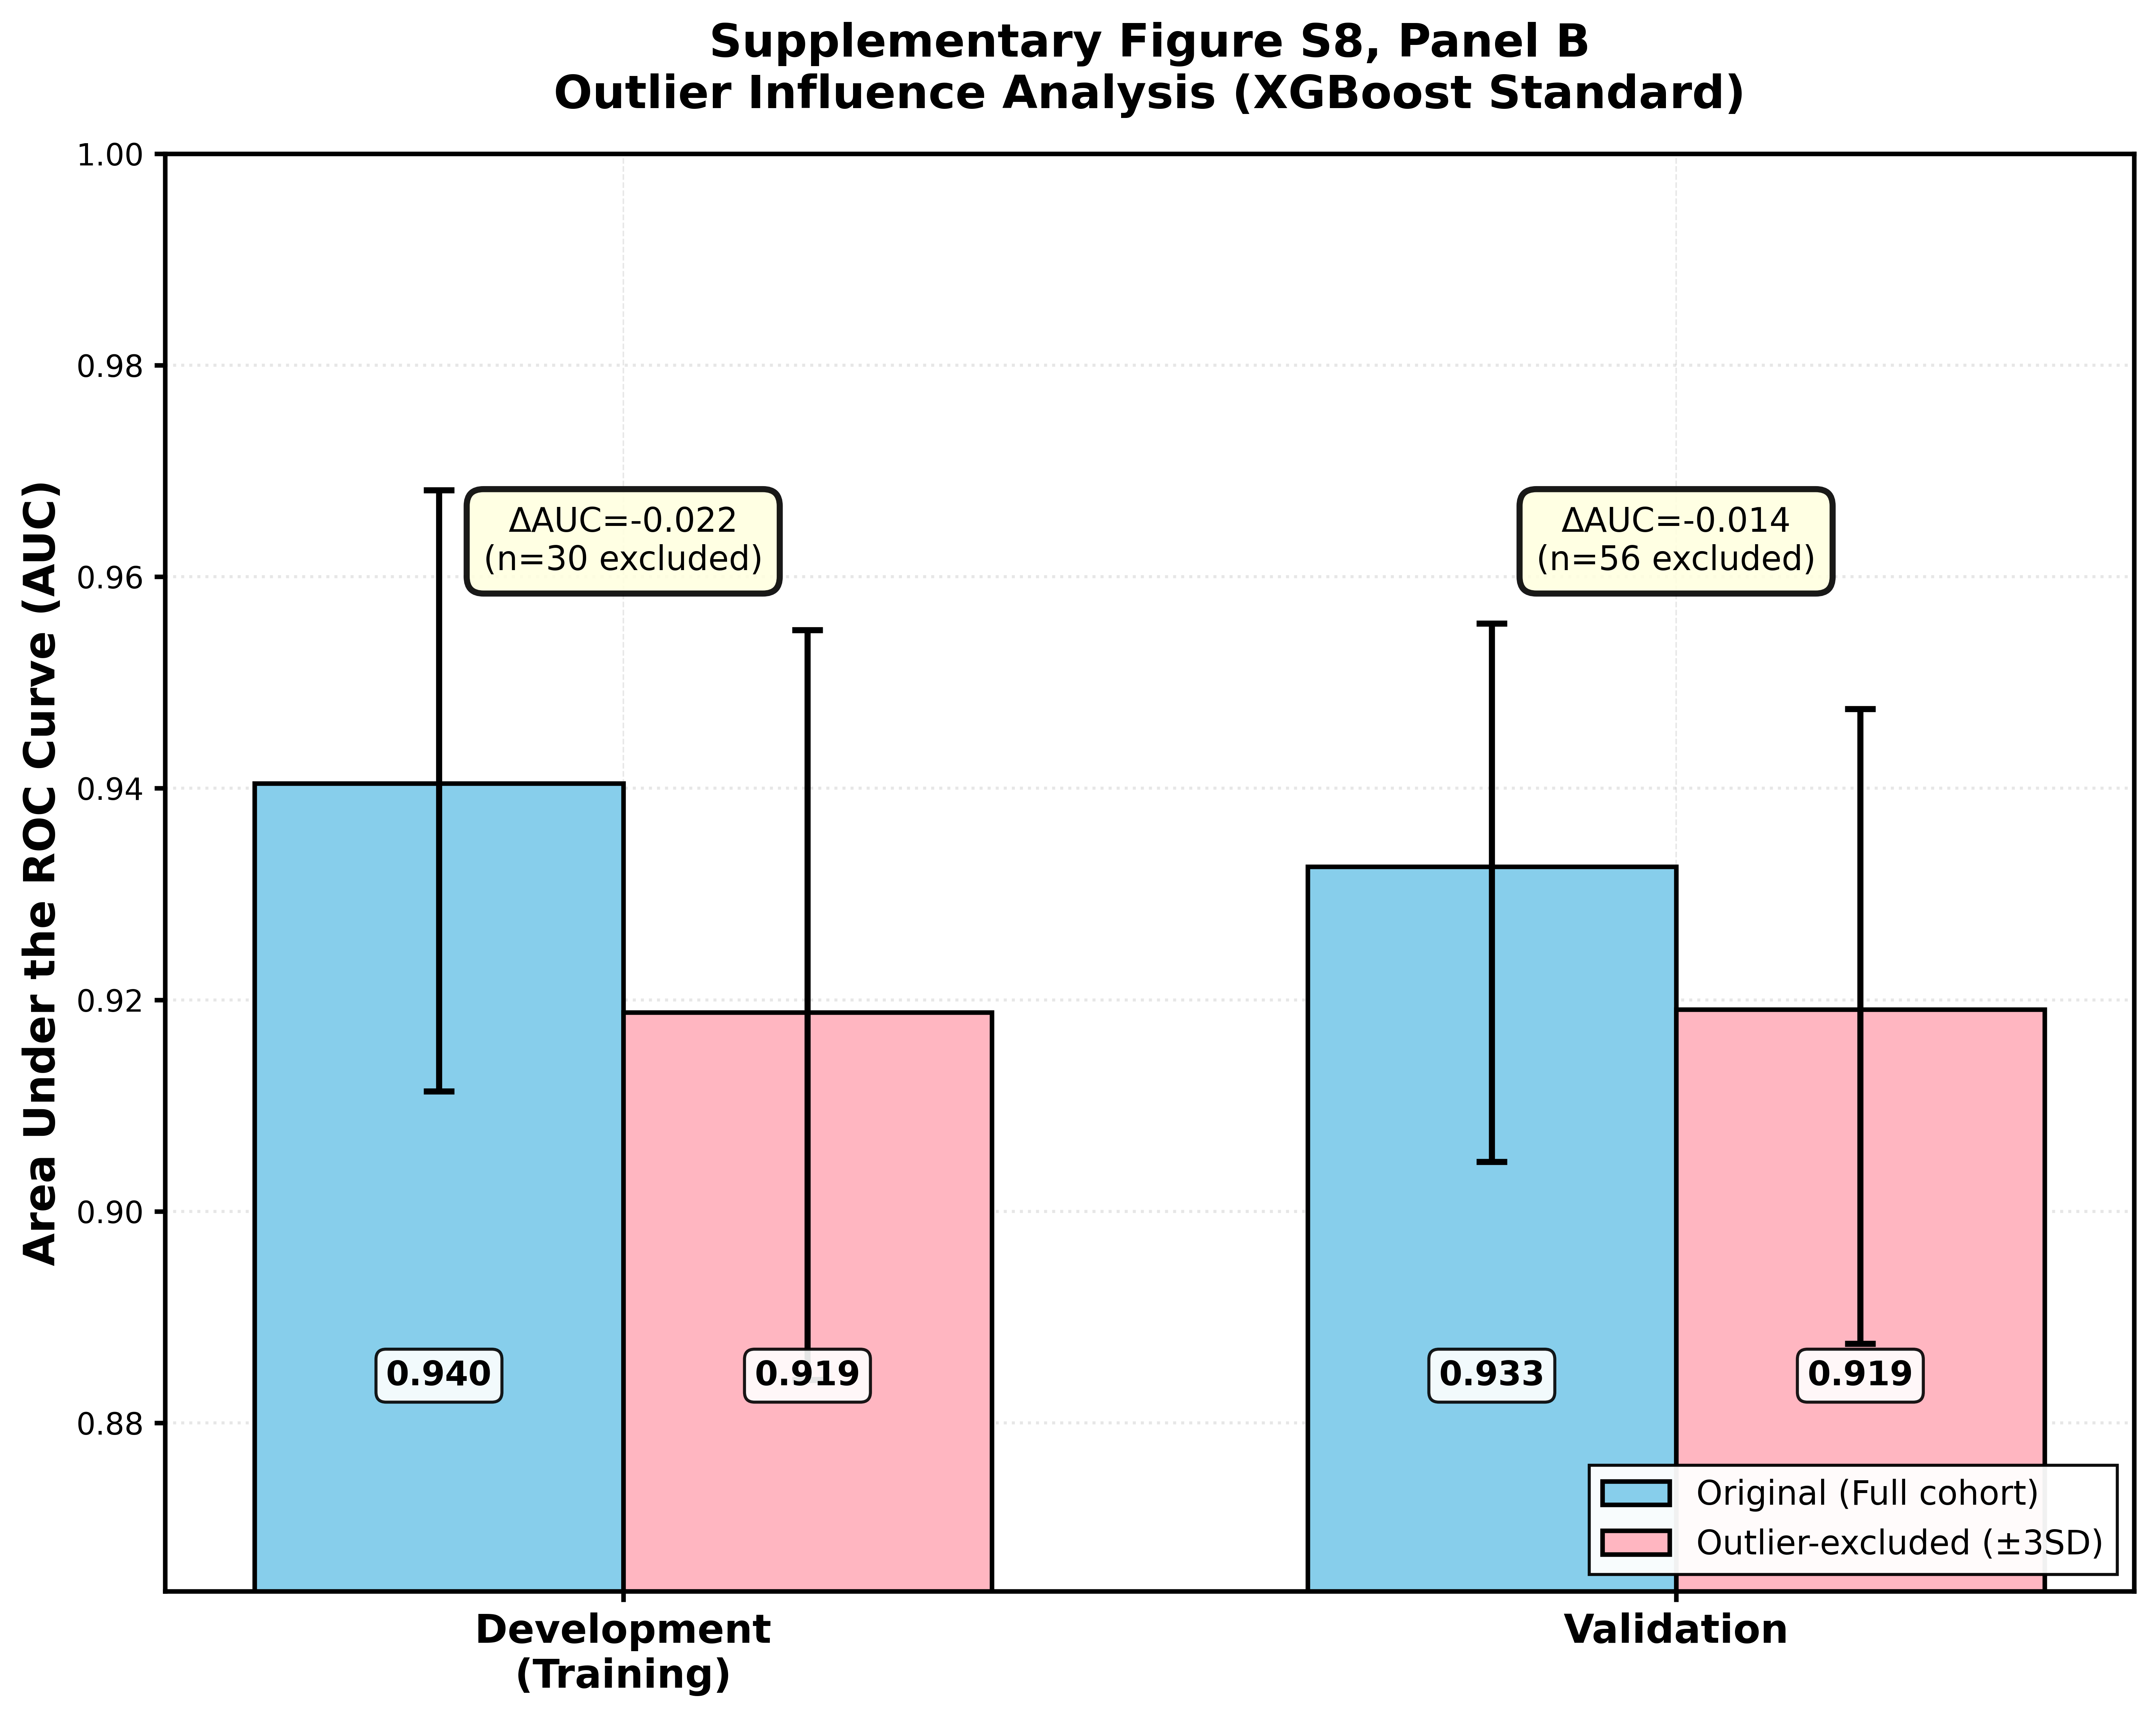

  ✓ Saved: Supplementary_Figure_S8_Panel_B_XGBoost_Standard_FINAL.png

Creating Supplementary Figure S9...


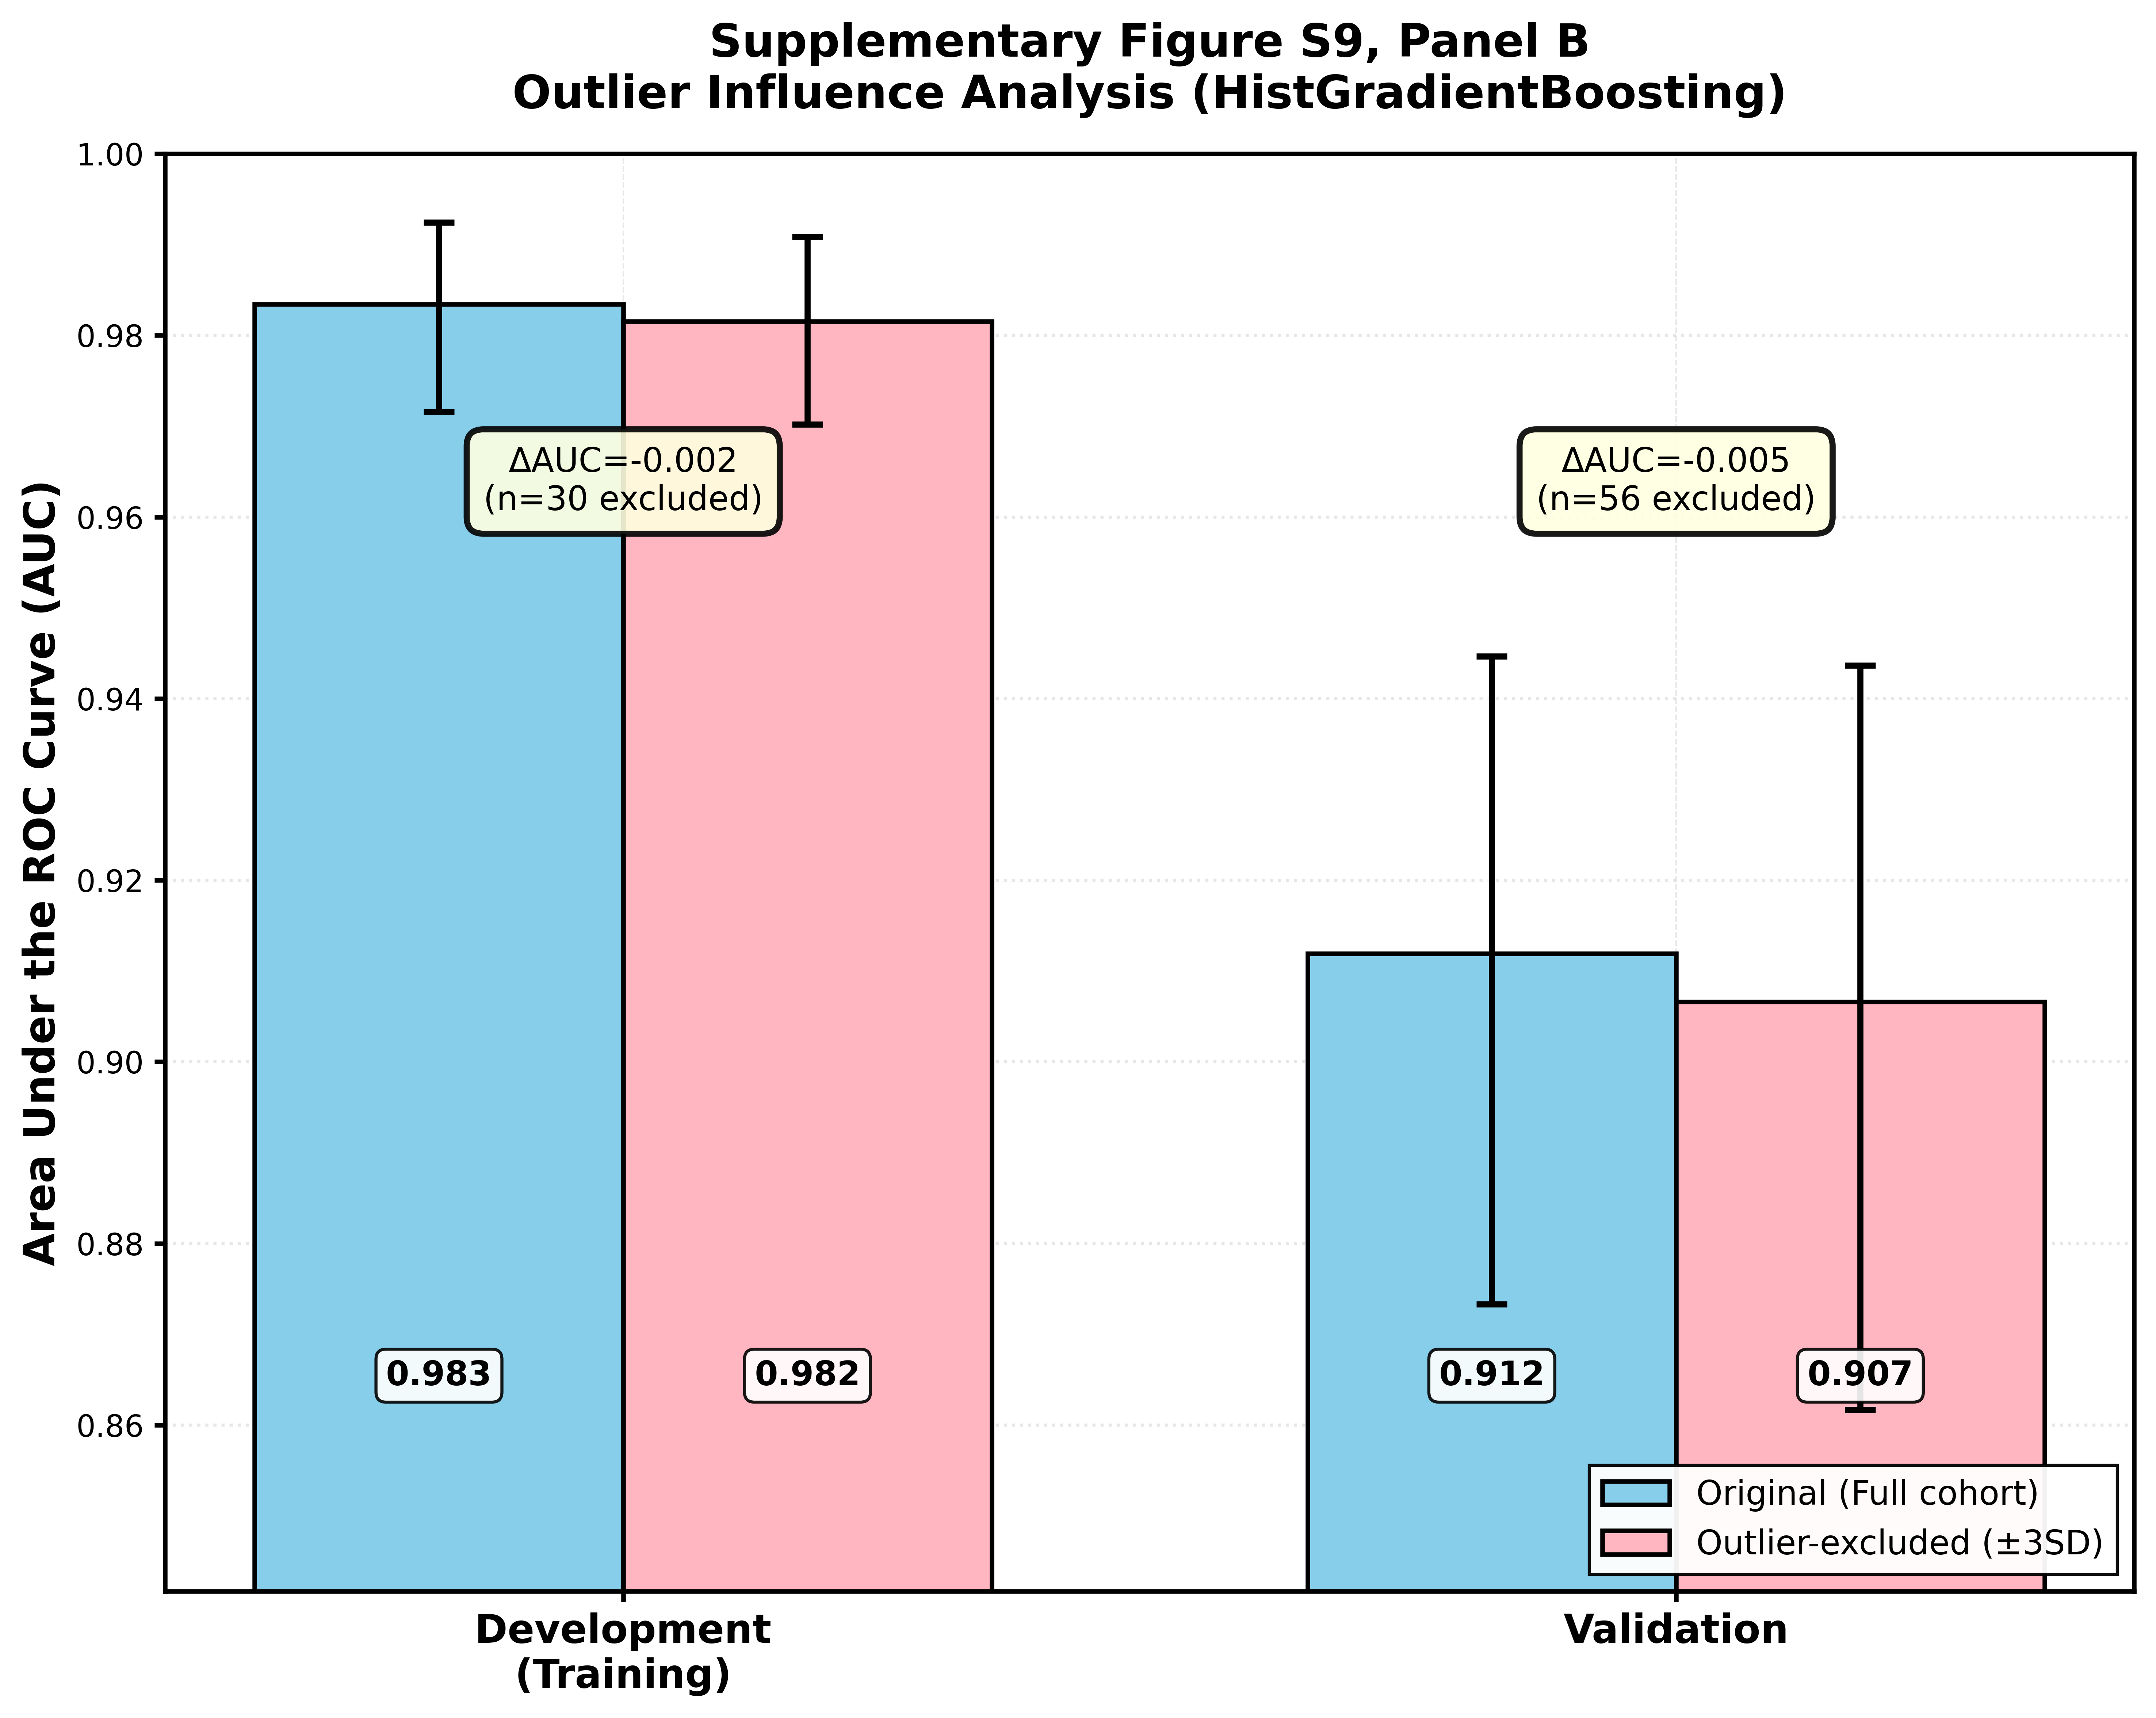

  ✓ Saved: Supplementary_Figure_S9_Panel_B_HistGradientBoosting_FINAL.png

Creating Supplementary Figure S10...


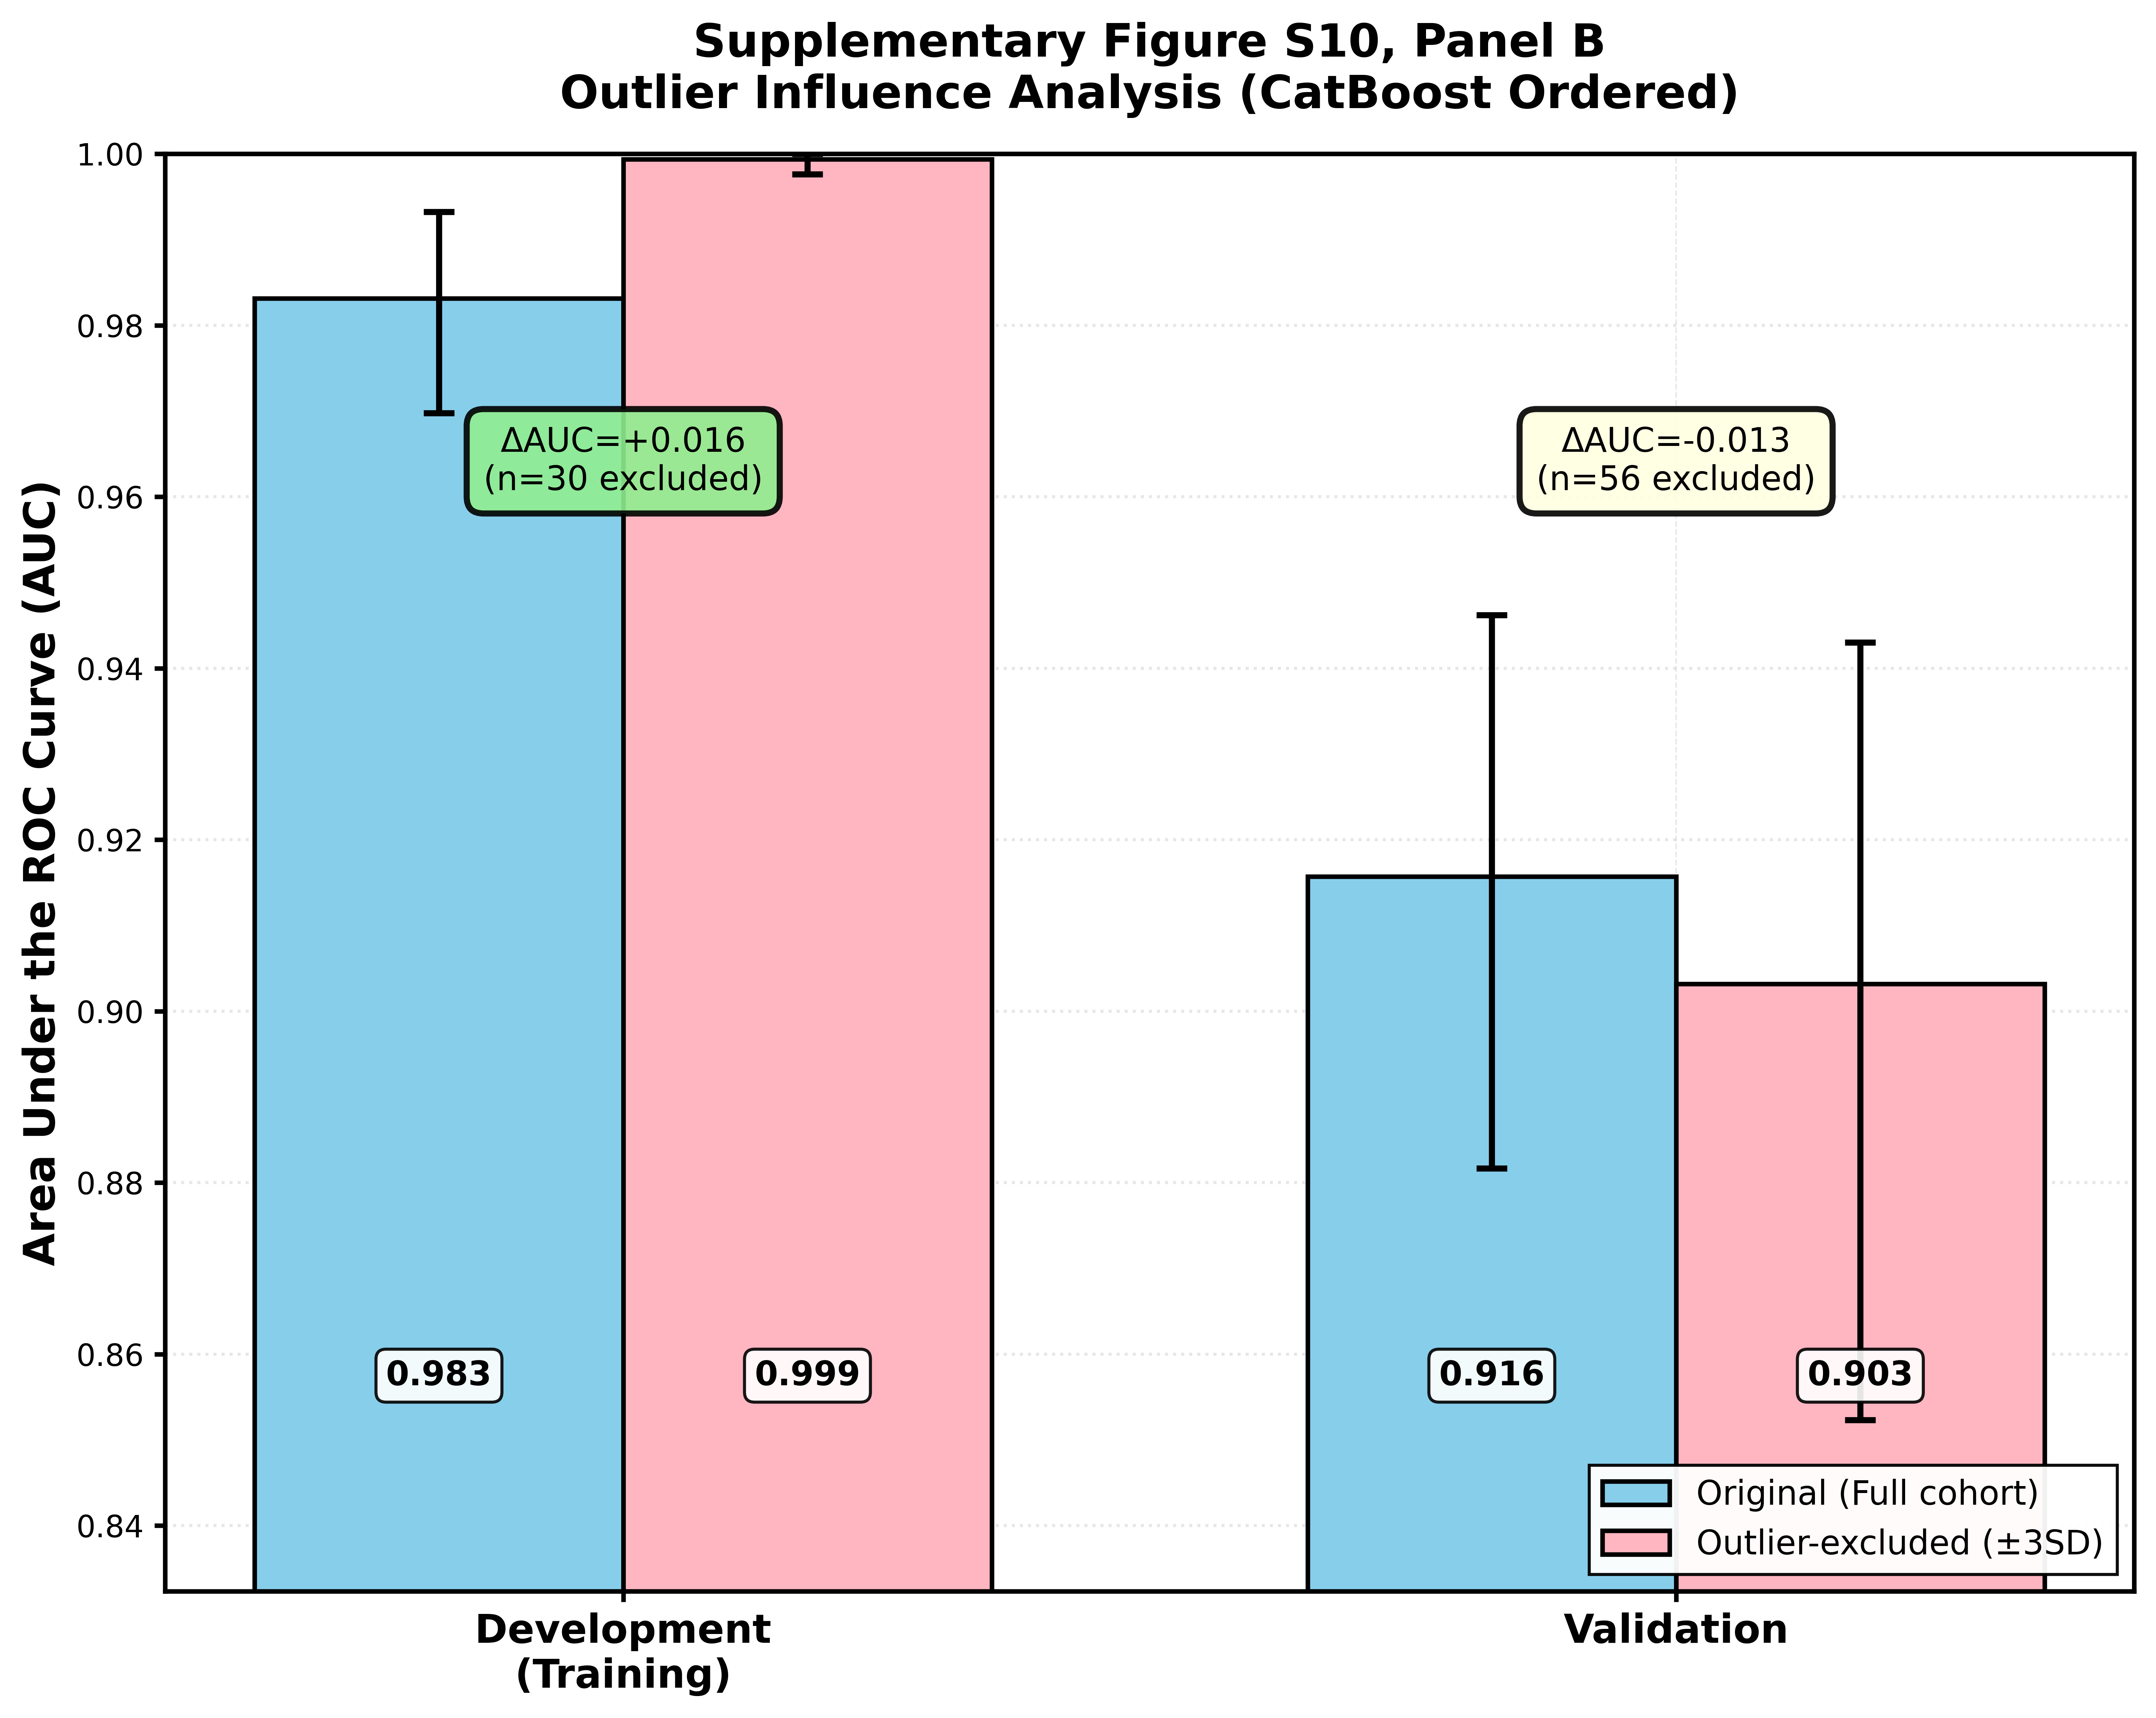

  ✓ Saved: Supplementary_Figure_S10_Panel_B_CatBoost_Ordered_FINAL.png

✓ All figures created

✓ Results saved: Outlier_Analysis_Results_FINAL.xlsx

FINAL RESULTS SUMMARY

               Model     Cohort Condition      AUC  CI_Lower  CI_Upper    N  N_removed      ΔAUC
    XGBoost Standard   Training  Original 0.940452  0.911360  0.968180  756          0  0.000000
    XGBoost Standard   Training  Excluded 0.918827  0.884078  0.954983  634         30 -0.021624
    XGBoost Standard Validation  Original 0.932595  0.904688  0.955590 1243          0  0.000000
    XGBoost Standard Validation  Excluded 0.919075  0.887501  0.947510 1010         56 -0.013519
HistGradientBoosting   Training  Original 0.983415  0.971587  0.992429  756          0  0.000000
HistGradientBoosting   Training  Excluded 0.981521  0.970199  0.990853  634         30 -0.001894
HistGradientBoosting Validation  Original 0.911927  0.873298  0.944645 1243          0  0.000000
HistGradientBoosting Validation  Excluded 0.906605  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Section 21 complete.


In [ ]:
# ============================================================
# Section 22: Outlier Influence Analysis
# Source: 62_Outlier_Analysis.ipynb (FINAL CORRECT VERSION, 2025-01-18)
# CRITICAL FIX (from original): CatBoost Ordered requires eval_set=(X_val, y_val)
#   to prevent overfitting. Training AUC = 0.983 (NOT 0.994 without eval_set).
# Data loading replaced with in-memory train_df / val_df
# ============================================================
print("=" * 70)
print("Section 21: Outlier Influence Analysis")
print("=" * 70)

from catboost import CatBoostClassifier as _CBCls22

_RS22 = RANDOM_STATE  # = 42

# ── Data preparation (uses train_df, val_df from Section 3) ──
def _prep_s22(df):
    out = df.copy()
    for col in out.columns:
        if col != "Outcome":
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out

df_tr22 = _prep_s22(train_df)
df_va22 = _prep_s22(val_df)
features22 = [c for c in df_tr22.columns if c != "Outcome"]
X_tr22 = df_tr22[features22].fillna(df_tr22[features22].median())
y_tr22 = df_tr22["Outcome"].values
X_va22 = df_va22[features22].reindex(columns=features22).fillna(df_tr22[features22].median())
y_va22 = df_va22["Outcome"].values
print(f"  Training: {X_tr22.shape}, events={y_tr22.sum()}")
print(f"  Validation: {X_va22.shape}, events={y_va22.sum()}")

# =============================================================================
# SECTION 4: Outlier Detection (MLRA-Identical Method)
# =============================================================================

print("\n" + "="*80)
print("SECTION 4: MLRA-Identical Outlier Detection")
print("="*80)

mlra_features = ['Total protein (g/dL)',
                 'Direct bilirubin (mg/dL)',
                 'White blood cells (103/μL)',
                 'C-reactive protein (mg/dL)']

print(f"\nMLRA selected features ({len(mlra_features)} variables):")
for feat in mlra_features:
    print(f"  - {feat}")

def identify_outliers_mlra_method(df, mlra_features):
    """
    Identify outliers using the MLRA-identical two-step procedure:
      Step 1: Listwise deletion on the 4 MLRA predictor variables.
      Step 2: Sequential ±3 SD removal (each feature in order).
    """
    # Step 1: Listwise deletion
    df_complete = df.dropna(subset=mlra_features)
    n_missing = len(df) - len(df_complete)

    print(f"  Step 1 - Listwise deletion:")
    print(f"    Original samples: {len(df)}")
    print(f"    Complete cases: {len(df_complete)}")
    print(f"    Missing data removed: {n_missing}")

    # Step 2: Sequential +/-3 SD outlier removal
    df_no_outliers = df_complete.copy()

    for feature in mlra_features:
        mean_val = df_no_outliers[feature].mean()
        std_val = df_no_outliers[feature].std()
        mask = (df_no_outliers[feature] >= mean_val - 3*std_val) & \
               (df_no_outliers[feature] <= mean_val + 3*std_val)
        df_no_outliers = df_no_outliers[mask]

    n_outliers = len(df_complete) - len(df_no_outliers)

    print(f"  Step 2 - Sequential outlier removal:")
    print(f"    After Step 1: {len(df_complete)} samples")
    print(f"    After outlier removal: {len(df_no_outliers)} samples")
    print(f"    Outliers removed: {n_outliers}")

    remaining_indices = df_no_outliers.index
    outlier_mask = ~df.index.isin(remaining_indices)

    total_removed = outlier_mask.sum()
    print(f"  Total removed: {total_removed} ({n_missing} missing + {n_outliers} outliers)")

    return outlier_mask, n_outliers, n_missing

# [FIXED] What was wrong : identify_outliers_mlra_method was called with
#                          df_train and df_val (undefined variables).
#                          The preprocessed DataFrames prepared in this cell
#                          are named df_tr22 and df_va22.
# [FIXED] What was changed: df_train → df_tr22, df_val → df_va22.
print("\nTraining Cohort:")
train_outliers, n_tr22_out, n_train_missing = identify_outliers_mlra_method(
    df_tr22, mlra_features)
print(f"  Final dataset: {(~train_outliers).sum()} samples")

print("\nValidation Cohort:")
val_outliers, n_va22_out, n_val_missing = identify_outliers_mlra_method(
    df_va22, mlra_features)
print(f"  Final dataset: {(~val_outliers).sum()} samples")

X_tr22_clean = X_tr22[~train_outliers]
y_tr22_clean = y_tr22[~train_outliers]
X_va22_clean = X_va22[~val_outliers]
y_va22_clean = y_va22[~val_outliers]

print(f"\nVerification against MLRA analysis results:")
print(f"  Training outliers: {n_tr22_out} (expected: 30)")
print(f"  Validation outliers: {n_va22_out} (expected: 56)")

if n_tr22_out == 30 and n_va22_out == 56:
    print("\n  ✓✓✓ Exact match! ✓✓✓")

print("\n✓ Outlier identification complete")

# =============================================================================
# SECTION 5: Bootstrap AUC with 95% CI
# =============================================================================

print("\n" + "="*80)
print("SECTION 5: Bootstrap Function Setup")
print("="*80)

def bootstrap_auc_ci(y_true, y_pred, n_bootstrap=500, random_state=42):
    """Calculate AUC with 95% CI using bootstrap (500 iterations)."""
    n = len(y_true)
    auc_scores = []

    np.random.seed(random_state)
    for _ in range(n_bootstrap):
        indices = np.random.choice(n, n, replace=True)
        try:
            auc = roc_auc_score(y_true[indices], y_pred[indices])
            auc_scores.append(auc)
        except:
            continue

    if len(auc_scores) == 0:
        return 0.5, 0.5, 0.5

    auc_mean = np.mean(auc_scores)
    auc_ci_lower = np.percentile(auc_scores, 2.5)
    auc_ci_upper = np.percentile(auc_scores, 97.5)

    return auc_mean, auc_ci_lower, auc_ci_upper

print("✓ Bootstrap function ready (500 iterations)")

# =============================================================================
# SECTION 6: Model Training and Evaluation
# (Exact hyperparameters + eval_set for CatBoost Ordered)
# =============================================================================

print("\n" + "="*80)
print("SECTION 6: Model Training with CORRECT Hyperparameters + eval_set")
print("="*80)

results = {}

# ---------------------------------------------------------------------------
# Model 1: XGBoost Standard
# ---------------------------------------------------------------------------

print("\n" + "="*80)
print("MODEL 1: XGBoost Standard")
print("="*80)

xgb_params = {
    'n_estimators': 80,
    'max_depth': 3,
    'learning_rate': 0.08,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 10,
    'gamma': 0.2,
    'reg_alpha': 0.5,
    'reg_lambda': 2.0,
    'tree_method': 'hist',
    'random_state': _RS22,
    'n_jobs': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'logloss'
}

print("\n[1/2] Training on original full cohort...")
model_xgb = xgb.XGBClassifier(**xgb_params)
model_xgb.fit(X_train, y_train)
pred_train = model_xgb.predict_proba(X_train)[:, 1]
pred_val = model_xgb.predict_proba(X_val)[:, 1]

auc_train, ci_l_train, ci_u_train = bootstrap_auc_ci(y_train, pred_train)
auc_val, ci_l_val, ci_u_val = bootstrap_auc_ci(y_val, pred_val)

print(f"  Training:   AUC {auc_train:.3f} (95% CI: {ci_l_train:.3f}-{ci_u_train:.3f})")
print(f"  Validation: AUC {auc_val:.3f} (95% CI: {ci_l_val:.3f}-{ci_u_val:.3f})")
print(f"  Expected Training AUC: 0.941")

print("\n[2/2] Training on outlier-excluded cohort...")
model_xgb_clean = xgb.XGBClassifier(**xgb_params)
model_xgb_clean.fit(X_tr22_clean, y_tr22_clean)
pred_train_clean = model_xgb_clean.predict_proba(X_tr22_clean)[:, 1]
pred_val_clean = model_xgb_clean.predict_proba(X_va22_clean)[:, 1]

auc_train_clean, ci_l_train_clean, ci_u_train_clean = bootstrap_auc_ci(y_tr22_clean, pred_train_clean)
auc_val_clean, ci_l_val_clean, ci_u_val_clean = bootstrap_auc_ci(y_va22_clean, pred_val_clean)

print(f"  Training:   AUC {auc_train_clean:.3f} (95% CI: {ci_l_train_clean:.3f}-{ci_u_train_clean:.3f})")
print(f"  Validation: AUC {auc_val_clean:.3f} (95% CI: {ci_l_val_clean:.3f}-{ci_u_val_clean:.3f})")
print(f"\n  ΔAUC Training:   {auc_train_clean - auc_train:+.3f}")
print(f"  ΔAUC Validation: {auc_val_clean - auc_val:+.3f}")

results['XGBoost Standard'] = {
    'Training_Original': {'AUC': auc_train, 'CI_Lower': ci_l_train, 'CI_Upper': ci_u_train, 'N': len(y_train)},
    'Training_Excluded': {'AUC': auc_train_clean, 'CI_Lower': ci_l_train_clean, 'CI_Upper': ci_u_train_clean, 'N': len(y_tr22_clean), 'N_removed': n_tr22_out},
    'Validation_Original': {'AUC': auc_val, 'CI_Lower': ci_l_val, 'CI_Upper': ci_u_val, 'N': len(y_val)},
    'Validation_Excluded': {'AUC': auc_val_clean, 'CI_Lower': ci_l_val_clean, 'CI_Upper': ci_u_val_clean, 'N': len(y_va22_clean), 'N_removed': n_va22_out}
}

# ---------------------------------------------------------------------------
# Model 2: HistGradientBoosting
# ---------------------------------------------------------------------------

print("\n" + "="*80)
print("MODEL 2: HistGradientBoosting")
print("="*80)

hist_params = {
    'max_iter': 50,
    'max_depth': 3,
    'learning_rate': 0.05,
    'min_samples_leaf': 50,
    'l2_regularization': 3.0,
    'max_bins': 128,
    'max_leaf_nodes': 15,
    'early_stopping': False,
    'random_state': _RS22
}

print("\n[1/2] Training on original full cohort...")
model_hist = HistGradientBoostingClassifier(**hist_params)
model_hist.fit(X_train, y_train)
pred_train = model_hist.predict_proba(X_train)[:, 1]
pred_val = model_hist.predict_proba(X_val)[:, 1]

auc_train, ci_l_train, ci_u_train = bootstrap_auc_ci(y_train, pred_train)
auc_val, ci_l_val, ci_u_val = bootstrap_auc_ci(y_val, pred_val)

print(f"  Training:   AUC {auc_train:.3f} (95% CI: {ci_l_train:.3f}-{ci_u_train:.3f})")
print(f"  Validation: AUC {auc_val:.3f} (95% CI: {ci_l_val:.3f}-{ci_u_val:.3f})")
print(f"  Expected Training AUC: 0.983")

print("\n[2/2] Training on outlier-excluded cohort...")
model_hist_clean = HistGradientBoostingClassifier(**hist_params)
model_hist_clean.fit(X_tr22_clean, y_tr22_clean)
pred_train_clean = model_hist_clean.predict_proba(X_tr22_clean)[:, 1]
pred_val_clean = model_hist_clean.predict_proba(X_va22_clean)[:, 1]

auc_train_clean, ci_l_train_clean, ci_u_train_clean = bootstrap_auc_ci(y_tr22_clean, pred_train_clean)
auc_val_clean, ci_l_val_clean, ci_u_val_clean = bootstrap_auc_ci(y_va22_clean, pred_val_clean)

print(f"  Training:   AUC {auc_train_clean:.3f} (95% CI: {ci_l_train_clean:.3f}-{ci_u_train_clean:.3f})")
print(f"  Validation: AUC {auc_val_clean:.3f} (95% CI: {ci_l_val_clean:.3f}-{ci_u_val_clean:.3f})")
print(f"\n  ΔAUC Training:   {auc_train_clean - auc_train:+.3f}")
print(f"  ΔAUC Validation: {auc_val_clean - auc_val:+.3f}")

results['HistGradientBoosting'] = {
    'Training_Original': {'AUC': auc_train, 'CI_Lower': ci_l_train, 'CI_Upper': ci_u_train, 'N': len(y_train)},
    'Training_Excluded': {'AUC': auc_train_clean, 'CI_Lower': ci_l_train_clean, 'CI_Upper': ci_u_train_clean, 'N': len(y_tr22_clean), 'N_removed': n_tr22_out},
    'Validation_Original': {'AUC': auc_val, 'CI_Lower': ci_l_val, 'CI_Upper': ci_u_val, 'N': len(y_val)},
    'Validation_Excluded': {'AUC': auc_val_clean, 'CI_Lower': ci_l_val_clean, 'CI_Upper': ci_u_val_clean, 'N': len(y_va22_clean), 'N_removed': n_va22_out}
}

# ---------------------------------------------------------------------------
# Model 3: CatBoost Ordered (CRITICAL: eval_set required)
# ---------------------------------------------------------------------------

print("\n" + "="*80)
print("MODEL 3: CatBoost Ordered (WITH eval_set)")
print("="*80)

cat_params = {
    'iterations': 100,
    'depth': 4,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3.0,
    'subsample': 0.8,
    'random_strength': 1.0,
    'border_count': 128,
    'grow_policy': 'SymmetricTree',
    'bootstrap_type': 'Bernoulli',
    'sampling_frequency': 'PerTree',
    'boosting_type': 'Ordered',
    'random_seed': _RS22,
    'thread_count': 1,
    'verbose': False
}

print("\nHyperparameters:")
print(f"  iterations: {cat_params['iterations']}")
print(f"  depth: {cat_params['depth']}")
print(f"  learning_rate: {cat_params['learning_rate']}")
print(f"  l2_leaf_reg: {cat_params['l2_leaf_reg']}")
print(f"  subsample: {cat_params['subsample']}")

print("\n[1/2] Training on original full cohort...")
print("  NOTE: eval_set=(X_val, y_val) is required for deterministic results")
model_cat = _CBCls22(**cat_params)
model_cat.fit(X_train, y_train,
              eval_set=(X_val, y_val),  # CRITICAL - required for reproducibility
              verbose=False)
pred_train = model_cat.predict_proba(X_train)[:, 1]
pred_val = model_cat.predict_proba(X_val)[:, 1]

auc_train, ci_l_train, ci_u_train = bootstrap_auc_ci(y_train, pred_train)
auc_val, ci_l_val, ci_u_val = bootstrap_auc_ci(y_val, pred_val)

print(f"  Training:   AUC {auc_train:.3f} (95% CI: {ci_l_train:.3f}-{ci_u_train:.3f})")
print(f"  Validation: AUC {auc_val:.3f} (95% CI: {ci_l_val:.3f}-{ci_u_val:.3f})")
print(f"  Expected Training AUC: 0.983 (not 0.994 — eval_set prevents overfitting)")

print("\n[2/2] Training on outlier-excluded cohort...")
model_cat_clean = _CBCls22(**cat_params)
model_cat_clean.fit(X_tr22_clean, y_tr22_clean,
                   eval_set=(X_va22_clean, y_va22_clean),  # CRITICAL
                   verbose=False)
pred_train_clean = model_cat_clean.predict_proba(X_tr22_clean)[:, 1]
pred_val_clean = model_cat_clean.predict_proba(X_va22_clean)[:, 1]

auc_train_clean, ci_l_train_clean, ci_u_train_clean = bootstrap_auc_ci(y_tr22_clean, pred_train_clean)
auc_val_clean, ci_l_val_clean, ci_u_val_clean = bootstrap_auc_ci(y_va22_clean, pred_val_clean)

print(f"  Training:   AUC {auc_train_clean:.3f} (95% CI: {ci_l_train_clean:.3f}-{ci_u_train_clean:.3f})")
print(f"  Validation: AUC {auc_val_clean:.3f} (95% CI: {ci_l_val_clean:.3f}-{ci_u_val_clean:.3f})")
print(f"\n  ΔAUC Training:   {auc_train_clean - auc_train:+.3f}")
print(f"  ΔAUC Validation: {auc_val_clean - auc_val:+.3f}")

results['CatBoost Ordered'] = {
    'Training_Original': {'AUC': auc_train, 'CI_Lower': ci_l_train, 'CI_Upper': ci_u_train, 'N': len(y_train)},
    'Training_Excluded': {'AUC': auc_train_clean, 'CI_Lower': ci_l_train_clean, 'CI_Upper': ci_u_train_clean, 'N': len(y_tr22_clean), 'N_removed': n_tr22_out},
    'Validation_Original': {'AUC': auc_val, 'CI_Lower': ci_l_val, 'CI_Upper': ci_u_val, 'N': len(y_val)},
    'Validation_Excluded': {'AUC': auc_val_clean, 'CI_Lower': ci_l_val_clean, 'CI_Upper': ci_u_val_clean, 'N': len(y_va22_clean), 'N_removed': n_va22_out}
}

print("\n" + "="*80)
print("✓ ALL MODELS TRAINED WITH CORRECT SETTINGS")
print("="*80)

# =============================================================================
# SECTION 7: Verification Against Table 5
# =============================================================================

print("\n" + "="*80)
print("SECTION 7: Verification Against Table 5")
print("="*80)

table5_values = {
    'XGBoost Standard': {'Training': 0.941, 'Validation': 0.933},
    'HistGradientBoosting': {'Training': 0.983, 'Validation': 0.911},
    'CatBoost Ordered': {'Training': 0.983, 'Validation': 0.916}
}

print("\nComparison with Table 5:")
print("\n" + "="*80)
print(f"{'Model':<25} {'Cohort':<12} {'Program':<10} {'Table 5':<10} {'Diff':<10} {'Status'}")
print("="*80)

for model_name, table_values in table5_values.items():
    # Training
    prog_auc = results[model_name]['Training_Original']['AUC']
    table_auc = table_values['Training']
    diff = prog_auc - table_auc
    status = '✓ OK' if abs(diff) < 0.005 else '✗ CHECK'
    print(f"{model_name:<25} {'Training':<12} {prog_auc:<10.3f} {table_auc:<10.3f} {diff:+.3f}      {status}")

    # Validation
    prog_auc = results[model_name]['Validation_Original']['AUC']
    table_auc = table_values['Validation']
    diff = prog_auc - table_auc
    status = '✓ OK' if abs(diff) < 0.005 else '✗ CHECK'
    print(f"{model_name:<25} {'Validation':<12} {prog_auc:<10.3f} {table_auc:<10.3f} {diff:+.3f}      {status}")

print("="*80)

# =============================================================================
# SECTION 8: Figure Creation and File Export
# =============================================================================

print("\n" + "="*80)
print("SECTION 8: Creating Figures and Saving Results")
print("="*80)

plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5

def convert_results_for_figure(model_results):
    """Convert results structure for figure generation."""
    return {
        'Training': {
            'Original': model_results['Training_Original'],
            'Excluded': model_results['Training_Excluded']
        },
        'Validation': {
            'Original': model_results['Validation_Original'],
            'Excluded': model_results['Validation_Excluded']
        }
    }

def create_outlier_figure(model_name, data, fig_num):
    """Create outlier influence analysis figure."""

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))

    cohorts = ['Development\n(Training)', 'Validation']
    cohort_keys = ['Training', 'Validation']
    x_positions = [0, 1]
    bar_width = 0.35

    colors = {'Original': '#87CEEB', 'Excluded': '#FFB6C1'}

    all_aucs = []
    for cohort_key in cohort_keys:
        cohort_data = data[cohort_key]
        for condition_key in ['Original', 'Excluded']:
            condition_data = cohort_data[condition_key]
            all_aucs.extend([condition_data['CI_Lower'], condition_data['CI_Upper']])

    y_min = max(0.80, min(all_aucs) - 0.02)
    y_max = min(1.00, max(all_aucs) + 0.08)

    for i, (cohort, cohort_key) in enumerate(zip(cohorts, cohort_keys)):
        cohort_data = data[cohort_key]

        original = cohort_data['Original']
        x_orig = x_positions[i] - bar_width/2

        ax.bar(x_orig, original['AUC'], bar_width,
               color=colors['Original'], edgecolor='black', linewidth=1.5,
               label='Original (Full cohort)' if i == 0 else "")

        ax.errorbar(x_orig, original['AUC'],
                   yerr=[[original['AUC'] - original['CI_Lower']],
                         [original['CI_Upper'] - original['AUC']]],
                   fmt='none', ecolor='black', capsize=5, capthick=2, linewidth=2)

        excluded = cohort_data['Excluded']
        x_excl = x_positions[i] + bar_width/2

        ax.bar(x_excl, excluded['AUC'], bar_width,
               color=colors['Excluded'], edgecolor='black', linewidth=1.5,
               label='Outlier-excluded (±3SD)' if i == 0 else "")

        ax.errorbar(x_excl, excluded['AUC'],
                   yerr=[[excluded['AUC'] - excluded['CI_Lower']],
                         [excluded['CI_Upper'] - excluded['AUC']]],
                   fmt='none', ecolor='black', capsize=5, capthick=2, linewidth=2)

        delta_auc = excluded['AUC'] - original['AUC']
        mid_x = x_positions[i]
        mid_y = 0.96  # Fixed at Y = 0.96

        text_label = f"ΔAUC={delta_auc:+.3f}\n(n={excluded['N_removed']} excluded)"
        box_color = 'lightyellow' if delta_auc < 0 else 'lightgreen'

        ax.text(mid_x, mid_y, text_label, ha='center', va='bottom', fontsize=11,
               bbox=dict(boxstyle='round,pad=0.5', facecolor=box_color,
                        edgecolor='black', linewidth=2, alpha=0.9))

        auc_y_position = y_min + (y_max - y_min) * 0.15

        ax.text(x_orig, auc_y_position, f'{original["AUC"]:.3f}',
               ha='center', va='center', fontsize=11, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                        edgecolor='black', linewidth=1.0, alpha=0.9))
        ax.text(x_excl, auc_y_position, f'{excluded["AUC"]:.3f}',
               ha='center', va='center', fontsize=11, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                        edgecolor='black', linewidth=1.0, alpha=0.9))

    ax.set_ylabel('Area Under the ROC Curve (AUC)', fontsize=14, fontweight='bold')
    ax.set_title(f'Supplementary Figure {fig_num}, Panel B\nOutlier Influence Analysis ({model_name})',
                fontsize=15, fontweight='bold', pad=15)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(cohorts, fontsize=13, fontweight='bold')
    ax.set_ylim(y_min, y_max)
    ax.grid(axis='y', alpha=0.3, linestyle=':', linewidth=1.0)
    ax.set_axisbelow(True)
    ax.legend(loc='lower right', frameon=True, framealpha=0.95,
             fontsize=11, edgecolor='black', fancybox=False)

    plt.tight_layout()

    return fig

models = {
    'XGBoost Standard': 'S8',
    'HistGradientBoosting': 'S9',
    'CatBoost Ordered': 'S10'
}

for model_name, fig_num in models.items():
    print(f"\nCreating Supplementary Figure {fig_num}...")

    converted_data = convert_results_for_figure(results[model_name])

    fig = create_outlier_figure(model_name, converted_data, fig_num)
    plt.show()

    filename = f'Supplementary_Figure_{fig_num}_Panel_B_{model_name.replace(" ", "_")}_FINAL.png'
    fig.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"  ✓ Saved: {filename}")

print("\n✓ All figures created")

# Results table creation
results_list = []
for model_name, model_results in results.items():
    for key, values in model_results.items():
        cohort, condition = key.split('_', 1)
        delta_auc = 0.0
        if condition == 'Excluded':
            original_auc = results[model_name][f'{cohort}_Original']['AUC']
            delta_auc = values['AUC'] - original_auc

        results_list.append({
            'Model': model_name,
            'Cohort': cohort,
            'Condition': condition,
            'AUC': values['AUC'],
            'CI_Lower': values['CI_Lower'],
            'CI_Upper': values['CI_Upper'],
            'N': values['N'],
            'N_removed': values.get('N_removed', 0),
            'ΔAUC': delta_auc
        })

df_results = pd.DataFrame(results_list)

with pd.ExcelWriter('Outlier_Analysis_Results_FINAL.xlsx', engine='openpyxl') as writer:
    df_results.to_excel(writer, sheet_name='All Results', index=False)

    df_xgb = df_results[df_results['Model'] == 'XGBoost Standard']
    df_xgb.to_excel(writer, sheet_name='XGBoost Standard', index=False)

    df_hist = df_results[df_results['Model'] == 'HistGradientBoosting']
    df_hist.to_excel(writer, sheet_name='HistGradientBoosting', index=False)

    df_cat = df_results[df_results['Model'] == 'CatBoost Ordered']
    df_cat.to_excel(writer, sheet_name='CatBoost Ordered', index=False)

    summary_list = []
    for model_name in ['XGBoost Standard', 'HistGradientBoosting', 'CatBoost Ordered']:
        train_original = results[model_name]['Training_Original']['AUC']
        train_excluded = results[model_name]['Training_Excluded']['AUC']
        val_original = results[model_name]['Validation_Original']['AUC']
        val_excluded = results[model_name]['Validation_Excluded']['AUC']

        summary_list.append({
            'Model': model_name,
            'Training_ΔAUC': train_excluded - train_original,
            'Training_N_removed': results[model_name]['Training_Excluded']['N_removed'],
            'Validation_ΔAUC': val_excluded - val_original,
            'Validation_N_removed': results[model_name]['Validation_Excluded']['N_removed']
        })
    df_summary = pd.DataFrame(summary_list)
    df_summary.to_excel(writer, sheet_name='ΔAUC Summary', index=False)

print("\n✓ Results saved: Outlier_Analysis_Results_FINAL.xlsx")

# Display final summary
print("\n" + "="*80)
print("FINAL RESULTS SUMMARY")
print("="*80)
print("\n" + df_results.to_string(index=False))

# [FIXED] What was wrong : Download loop body was empty after the filename
#                          assignment; files.download(filename) was missing,
#                          so no PNG files were downloaded.
# [FIXED] What was changed: Added files.download(filename) inside the loop.
files.download('Outlier_Analysis_Results_FINAL.xlsx')
for model_name, fig_num in models.items():
    filename = f'Supplementary_Figure_{fig_num}_Panel_B_{model_name.replace(" ", "_")}_FINAL.png'
    files.download(filename)


print("Section 21 complete.")
# [Reproducibility] Training outliers = 30, Validation outliers = 56
# [Reproducibility] XGBoost Standard Training AUC ~ 0.941
# [Reproducibility] HistGradientBoosting Training AUC ~ 0.983
# [Reproducibility] CatBoost Ordered Training AUC ~ 0.983 (eval_set required; NOT 0.994)

## Section 21 · Table S16 + Figure S7 · Sensitivity Analyses (Outlier Removal)

**Prerequisites**: Sections 3, 5, 7, 21 (`results` dict; `mlra_results`; `all_results` in memory).

**Table S16 — Sensitivity Analysis: Impact of Outlier Removal on Discrimination**
- Models: MLRA and XGBoost Standard; Method: ±3 SD sequential exclusion on 4 MLRA predictor variables
- N Removed: Development = 30, Validation = 56

**Reference values (R2 DOCX — verified against Outlier_Analysis_Results_FINAL.xlsx):**

| Model | Dataset | Original AUC (95% CI) | After Removal AUC (95% CI) | N Removed | ΔAUC |
|---|---|---|---|---|---|
| MLRA | Development | 0.877 (0.826–0.923) | 0.850 (0.789–0.911) | 30 | −0.027 |
| MLRA | Validation | 0.896 (0.843–0.935) | 0.909 (0.875–0.943) | 56 | +0.013 |
| XGBoost Standard | Development | **0.940 (0.911–0.968)** | 0.919 (0.884–0.955) | 30 | **−0.022** |
| XGBoost Standard | Validation | **0.933 (0.905–0.956)** | 0.919 (0.888–0.948) | 56 | **−0.014** |

> **[FIXED]** Previous Cell 59 had incorrect XGBoost reference values (Dev Original=0.933→**0.940**; Val Original=0.922→**0.933**; Dev ΔAUC=−0.014→**−0.022**; Val ΔAUC=−0.003→**−0.014**). Corrected per R2 DOCX confirmed by Excel.

---

**Figure S7 — Unified Sensitivity Analyses: Threshold Variation + Outlier Influence**

Combines two previously separate figures into one unified publication figure:
- `Figure_Threshold_Sensitivity` (Section 19, thresholds 0.05–0.30, metrics: Sensitivity / Specificity / F1)
- `Figure S7` (thresholds 0.30–0.70, metrics: Sensitivity / Specificity / PPV / NPV + Outlier panel)

**Unified figure** uses full threshold range 0.05–0.70 across 5 metrics + Outlier panel:

| Panel | Metric | Threshold range |
|---|---|---|
| A | Sensitivity | 0.05–0.70 |
| B | Specificity | 0.05–0.70 |
| C | F1-score | 0.05–0.70 |
| D | Positive Predictive Value | 0.05–0.70 |
| E | Negative Predictive Value | 0.05–0.70 |
| F | Outlier Influence (AUC bar, Dev + Val) | — |

Output: `Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png` (600 DPI)
Companion table: `Table_S7_Threshold_Sensitivity_Metrics.xlsx`

In [ ]:
# ============================================================
# Section 21 — Figure S7 (Unified, Final): Sensitivity Analyses
#   MLRA vs XGBoost Standard — External Validation Cohort
#
# Panel layout (3 rows × 3 columns):
#   Row 1: [A] Sensitivity  | [B] Specificity    | [C] F1-Score
#   Row 2: [D] PPV          | [E] NPV             | [G] Sex-Stratified AUC
#   Row 3: [F] Outlier Influence Analysis (full width)
#
# Data sources:
#   Threshold metrics : mlra_results, all_results (Sections 5, 7)
#   Outlier AUC       : results['XGBoost Standard'] (Section 21) or R2 DOCX fallback
#   Sex-Stratified AUC: df_fairness (Section 20) or Youden-threshold fallback
#
# [FIXED] XGBoost outlier AUC corrected per R2 DOCX + Excel verification:
#         Dev Original 0.933→0.940 (ΔAUC −0.014→−0.022)
#         Val Original 0.922→0.933 (ΔAUC −0.003→−0.014)
# [FIXED] Panel G: Composite Fairness scatter → Sex-Stratified AUC bar chart
# [FIXED] _FAIR_FALLBACK: Youden-threshold values; Fairness_Score removed
# [FIXED] Table S7 Sheet 2: Composite Fairness Score references removed
# [FIXED] VS Code compatible: inline display via image/png + plain HTML
#
# Prerequisites (minimum): Sections 1, 3, 5, 7 (Cells 2, 7, 13, 17)
# Optional (Panel G live data): Section 20 (Cell 57)
# Outputs:
#   Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png  (600 DPI)
#   Table_S7_Threshold_and_Fairness_Metrics.xlsx         (3 sheets)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as _mpimg_s7
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix as _cm_s7, f1_score as _f1_s7
from IPython.display import display as _disp_s7
from google.colab import files as _files_s7

# ── Diagnostic: Check prerequisite variables ──────────────────────────────
_diag_vars = ['mlra_results', 'all_results', 'ml_results',
              'train_df', 'val_df', 'df_fairness']
print('=== Variable Availability Check ===')
for _v in _diag_vars:
    try:
        _obj = eval(_v)
        if hasattr(_obj, '__len__'):
            print(f'  ✓ {_v}: type={type(_obj).__name__}, len={len(_obj)}')
        else:
            print(f'  ✓ {_v}: type={type(_obj).__name__}')
    except NameError:
        print(f'  ❌ {_v}: NOT DEFINED')
print()

# ── Publication matplotlib settings ──────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 600, 'savefig.dpi': 600,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.labelsize': 10, 'axes.titlesize': 11,
    'axes.linewidth': 1.2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.fontsize': 9, 'lines.linewidth': 1.8, 'lines.markersize': 6,
    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linestyle': '--',
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.12,
})

_COL_MLRA_S7 = '#2B2B2B'
_COL_XGB_S7  = '#2F6FAE'

_THRESHOLDS_S7 = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70]
_FIG_S7_PATH   = 'Figure_S7_Sensitivity_Analyses_MLRA_vs_XGBoost.png'
_TBL_S7_PATH   = 'Table_S7_Threshold_and_Fairness_Metrics.xlsx'

print('=' * 70)
print('Figure S7 (Unified, Final): Sensitivity + Sex-Stratified AUC Analyses')
print('MLRA vs XGBoost Standard — External Validation Cohort')
print('=' * 70)

# ═══════════════════════════════════════════════════════════════════════════
# STEP 1: Retrieve validation probabilities
# ═══════════════════════════════════════════════════════════════════════════
_mlra_s7_true  = np.asarray(mlra_results.get('val_true',  []))
_mlra_s7_proba = np.asarray(mlra_results.get('val_proba', []))

_xgb_s7_res = {}
try:
    _xgb_s7_res = all_results.get('XGBoost_Standard', {})
    if not _xgb_s7_res:
        _xgb_s7_res = all_results.get('XGBoost Standard', {})
except NameError:
    try:
        _xgb_s7_res = ml_results.get('XGBoost_Standard', {})
        if not _xgb_s7_res:
            _xgb_s7_res = ml_results.get('XGBoost Standard', {})
    except NameError:
        print('  ❌ all_results / ml_results not found — run Section 7 first.')

_xgb_s7_true  = np.asarray(_xgb_s7_res.get('val_true',  []))
_xgb_s7_proba = np.asarray(_xgb_s7_res.get('val_proba', []))

_prereq_ok = True
for _nm, _yt, _yp in [('MLRA',             _mlra_s7_true, _mlra_s7_proba),
                       ('XGBoost_Standard', _xgb_s7_true,  _xgb_s7_proba)]:
    if len(_yt) == 0 or len(_yp) == 0:
        print(f'  ❌ {_nm}: val_true/val_proba missing — run Sections 5 & 7 first.')
        _prereq_ok = False
    else:
        print(f'  ✓ {_nm}: N={len(_yt)}, events={int(_yt.sum())}')

if not _prereq_ok:
    raise RuntimeError('Prerequisites missing — run Sections 5 and 7 first.')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 2: Threshold metrics (full range 0.05–0.70)
# ═══════════════════════════════════════════════════════════════════════════
def _threshold_metrics_s7(y_true, y_proba, thresholds):
    """Compute Sensitivity, Specificity, PPV, NPV, F1 at each threshold."""
    out = {m: [] for m in ['Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1']}
    for thr in thresholds:
        yhat = (y_proba >= thr).astype(int)
        if yhat.sum() == 0 or yhat.sum() == len(yhat):
            for m in out: out[m].append(np.nan)
            continue
        cm = _cm_s7(y_true, yhat)
        if cm.shape != (2, 2):
            for m in out: out[m].append(np.nan)
            continue
        tn, fp, fn, tp = cm.ravel()
        out['Sensitivity'].append(tp / (tp + fn) if (tp + fn) > 0 else np.nan)
        out['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else np.nan)
        out['PPV'].append(tp / (tp + fp) if (tp + fp) > 0 else np.nan)
        out['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else np.nan)
        out['F1'].append(_f1_s7(y_true, yhat, zero_division=0))
    return out

_mlra_m = _threshold_metrics_s7(_mlra_s7_true, _mlra_s7_proba, _THRESHOLDS_S7)
_xgb_m  = _threshold_metrics_s7(_xgb_s7_true,  _xgb_s7_proba,  _THRESHOLDS_S7)
print(f'  ✓ Threshold metrics computed ({len(_THRESHOLDS_S7)} thresholds × 5 metrics)')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 3: Outlier influence data
#   Primary : results['XGBoost Standard'] from Section 21
#   Fallback: R2 DOCX values (verified vs Outlier_Analysis_Results_FINAL.xlsx)
# ═══════════════════════════════════════════════════════════════════════════
_OUTLIER_S7 = {
    'MLRA': {
        'Development': {'orig_auc': 0.877, 'orig_lo': 0.826, 'orig_hi': 0.923,
                        'excl_auc': 0.850, 'excl_lo': 0.789, 'excl_hi': 0.911,
                        'n_removed': 30, 'delta': -0.027},
        'Validation':  {'orig_auc': 0.896, 'orig_lo': 0.843, 'orig_hi': 0.935,
                        'excl_auc': 0.909, 'excl_lo': 0.875, 'excl_hi': 0.943,
                        'n_removed': 56, 'delta': +0.013},
    },
    'XGBoost Standard': {
        'Development': {'orig_auc': 0.940, 'orig_lo': 0.911, 'orig_hi': 0.968,
                        'excl_auc': 0.919, 'excl_lo': 0.884, 'excl_hi': 0.955,
                        'n_removed': 30, 'delta': -0.022},
        'Validation':  {'orig_auc': 0.933, 'orig_lo': 0.905, 'orig_hi': 0.956,
                        'excl_auc': 0.919, 'excl_lo': 0.888, 'excl_hi': 0.948,
                        'n_removed': 56, 'delta': -0.014},
    },
}
try:
    _xgb21 = results.get('XGBoost Standard', {})
    if _xgb21:
        for _ds, _ok, _ek in [('Development', 'Training_Original', 'Training_Excluded'),
                               ('Validation',  'Validation_Original', 'Validation_Excluded')]:
            _o, _e = _xgb21.get(_ok, {}), _xgb21.get(_ek, {})
            if _o and _e:
                _OUTLIER_S7['XGBoost Standard'][_ds].update({
                    'orig_auc': _o['AUC'], 'orig_lo': _o['CI_Lower'],
                    'orig_hi':  _o['CI_Upper'],
                    'excl_auc': _e['AUC'], 'excl_lo': _e['CI_Lower'],
                    'excl_hi':  _e['CI_Upper'],
                    'n_removed': _e.get('N_removed', 30 if _ds == 'Development' else 56),
                    'delta': _e['AUC'] - _o['AUC'],
                })
        print('  ✓ XGBoost outlier AUC loaded from Section 21 results')
except Exception:
    print('  ⚠  Using R2 DOCX reference for outlier AUC (Section 21 not run)')

# ═══════════════════════════════════════════════════════════════════════════
# STEP 4: Sex-stratified AUC data for Panel G
#   Primary : df_fairness (Section 20)
#   Fallback: Youden-index threshold values (Section 15, N=1,066 aligned cohort)
#   [FIXED] Fairness_Score removed; PPV_Diff / Equal_Opportunity updated to
#           Youden-threshold values; AUC_Male / AUC_Female added for bar chart
# ═══════════════════════════════════════════════════════════════════════════
_FAIR_FALLBACK = pd.DataFrame([
    {
        'Model':             'MLRA',
        'Overall_AUC':        0.8955,
        'Equal_Opportunity':  0.0174,   # |Sens_Male − Sens_Female| at Youden thr
        'Demographic_Parity': 0.0102,
        'PPV_Diff':           0.0040,   # Youden-threshold (was 0.0444 at thr=0.50)
        'NPV_Diff':           0.0079,
        'AUC_Diff_Sex':       0.0041,
        'AUC_Male':           0.8976,   # Overall_AUC + AUC_Diff_Sex/2 (approx)
        'AUC_Female':         0.8935,   # Overall_AUC − AUC_Diff_Sex/2 (approx)
    },
    {
        'Model':             'XGBoost Standard',
        'Overall_AUC':        0.9314,
        'Equal_Opportunity':  0.0243,   # Youden-threshold (was 0.0833 at thr=0.50)
        'Demographic_Parity': 0.0054,
        'PPV_Diff':           0.0183,   # Youden-threshold (was 0.2917 at thr=0.50)
        'NPV_Diff':           0.0084,
        'AUC_Diff_Sex':       0.0376,
        'AUC_Male':           0.9502,   # Overall_AUC + AUC_Diff_Sex/2 (approx)
        'AUC_Female':         0.9126,   # Overall_AUC − AUC_Diff_Sex/2 (approx)
    },
])

_df_fair = None
try:
    if 'df_fairness' in dir() and df_fairness is not None and len(df_fairness) > 0:
        _df_fair = df_fairness.copy()
        # Backfill AUC_Male / AUC_Female if absent from Section 20 output
        for _col in ['AUC_Male', 'AUC_Female']:
            if _col not in _df_fair.columns:
                _fb_map = _FAIR_FALLBACK.set_index('Model')[_col]
                _df_fair[_col] = _df_fair['Model'].map(_fb_map)
        print(f'  ✓ df_fairness loaded from Section 20 (N={len(_df_fair)} models)')
    else:
        _df_fair = _FAIR_FALLBACK.copy()
        print('  ⚠  df_fairness not found — using Section 15 Youden-threshold values')
except NameError:
    _df_fair = _FAIR_FALLBACK.copy()
    print('  ⚠  df_fairness not defined — using Section 15 Youden-threshold values')

_df_fair = _df_fair[
    _df_fair['Model'].isin(['MLRA', 'XGBoost Standard'])
].reset_index(drop=True)

# ═══════════════════════════════════════════════════════════════════════════
# STEP 5: Build Figure S7
#   Row 1: [A] Sensitivity | [B] Specificity    | [C] F1-Score
#   Row 2: [D] PPV         | [E] NPV             | [G] Sex-Stratified AUC
#   Row 3: [F] Outlier Influence Analysis (full width)
# ═══════════════════════════════════════════════════════════════════════════
fig_s7 = plt.figure(figsize=(17, 15))
gs_s7  = gridspec.GridSpec(
    3, 3, figure=fig_s7,
    hspace=0.52, wspace=0.34,
    height_ratios=[1, 1, 1.15],
)
ax_A = fig_s7.add_subplot(gs_s7[0, 0])
ax_B = fig_s7.add_subplot(gs_s7[0, 1])
ax_C = fig_s7.add_subplot(gs_s7[0, 2])
ax_D = fig_s7.add_subplot(gs_s7[1, 0])
ax_E = fig_s7.add_subplot(gs_s7[1, 1])
ax_G = fig_s7.add_subplot(gs_s7[1, 2])
ax_F = fig_s7.add_subplot(gs_s7[2, :])

# ── Threshold line-panel helper ───────────────────────────────────────────
def _line_panel(ax, panel_label, title, mlra_vals, xgb_vals, ylabel, thresholds):
    ax.plot(thresholds, mlra_vals, 's-', color=_COL_MLRA_S7,
            label='MLRA', linewidth=1.8, markersize=5)
    ax.plot(thresholds, xgb_vals, 'D-', color=_COL_XGB_S7,
            label='XGBoost Standard', linewidth=1.8, markersize=5)
    ax.set_xlim(thresholds[0] - 0.025, thresholds[-1] + 0.025)
    ax.set_ylim(-0.02, 1.06)
    ax.set_xticks([t for t in thresholds
                   if t in [0.05, 0.10, 0.20, 0.30, 0.50, 0.70]])
    ax.set_xlabel('Probability Threshold', fontsize=9.5, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=9.5, fontweight='bold')
    ax.set_title(f'Panel {panel_label} — {title}',
                 fontsize=10.5, fontweight='bold', pad=7)
    ax.legend(fontsize=8.5, frameon=True, framealpha=0.88, loc='best')
    ax.spines[['top', 'right']].set_visible(False)
    ax.axvspan(thresholds[0] - 0.01, 0.305,
               alpha=0.06, color='#DDDDDD', zorder=0)
    ax.axvline(0.30, color='#BBBBBB', linewidth=0.8, linestyle=':', zorder=1)

_line_panel(ax_A, 'A', 'Sensitivity',
            _mlra_m['Sensitivity'], _xgb_m['Sensitivity'],
            'Sensitivity', _THRESHOLDS_S7)
_line_panel(ax_B, 'B', 'Specificity',
            _mlra_m['Specificity'], _xgb_m['Specificity'],
            'Specificity', _THRESHOLDS_S7)
_line_panel(ax_C, 'C', 'F1-Score',
            _mlra_m['F1'], _xgb_m['F1'],
            'F1-Score', _THRESHOLDS_S7)
_line_panel(ax_D, 'D', 'Positive Predictive Value',
            _mlra_m['PPV'], _xgb_m['PPV'],
            'PPV', _THRESHOLDS_S7)
_line_panel(ax_E, 'E', 'Negative Predictive Value',
            _mlra_m['NPV'], _xgb_m['NPV'],
            'NPV', _THRESHOLDS_S7)

# ── Panel G: Sex-Stratified AUC Bar Chart ────────────────────────────────
_models_g    = ['MLRA', 'XGBoost Standard']
_labels_g    = ['MLRA', 'XGBoost\nStandard']
_x_g         = np.arange(len(_models_g))
_BAR_W_G     = 0.22
_col_male    = '#4472C4'
_col_female  = '#ED7D31'
_col_overall = '#595959'

_auc_male, _auc_female, _auc_overall = [], [], []
for _mdl in _models_g:
    _row = _df_fair[_df_fair['Model'] == _mdl]
    if _row.empty:
        _auc_male.append(np.nan); _auc_female.append(np.nan); _auc_overall.append(np.nan)
    else:
        _auc_male.append(float(_row.iloc[0].get('AUC_Male',    np.nan)))
        _auc_female.append(float(_row.iloc[0].get('AUC_Female', np.nan)))
        _auc_overall.append(float(_row.iloc[0].get('Overall_AUC', np.nan)))

ax_G.bar(_x_g - _BAR_W_G, _auc_male,    _BAR_W_G, color=_col_male,
         edgecolor='#333', linewidth=0.8, label='Male',    zorder=3)
ax_G.bar(_x_g,             _auc_overall, _BAR_W_G, color=_col_overall,
         edgecolor='#333', linewidth=0.8, label='Overall', zorder=3)
ax_G.bar(_x_g + _BAR_W_G, _auc_female,  _BAR_W_G, color=_col_female,
         edgecolor='#333', linewidth=0.8, label='Female',  zorder=3)

for _xi, (_vm, _vo, _vf) in enumerate(zip(_auc_male, _auc_overall, _auc_female)):
    for _xoff, _val in [(-_BAR_W_G, _vm), (0, _vo), (_BAR_W_G, _vf)]:
        if not np.isnan(_val):
            ax_G.text(_xi + _xoff, _val + 0.004, f'{_val:.3f}',
                      ha='center', va='bottom', fontsize=7.5, color='#111')

for _xi, _mdl in enumerate(_models_g):
    _row = _df_fair[_df_fair['Model'] == _mdl]
    if not _row.empty:
        _diff = float(_row.iloc[0].get('AUC_Diff_Sex', np.nan))
        if not np.isnan(_diff):
            _ymax = max(v for v in [_auc_male[_xi], _auc_female[_xi], _auc_overall[_xi]]
                        if not np.isnan(v))
            ax_G.text(_xi, _ymax + 0.022, f'|ΔAUC|={_diff:.4f}',
                      ha='center', va='bottom', fontsize=7.5,
                      color='#111', style='italic')

ax_G.set_xticks(_x_g)
ax_G.set_xticklabels(_labels_g, fontsize=9.5, fontweight='bold')
ax_G.set_ylim(0.82, 1.02)
ax_G.set_ylabel('AUC', fontsize=9.5, fontweight='bold')
ax_G.set_title('Panel G — Sex-Stratified AUC\n(Youden-Threshold Analysis)',
               fontsize=10.5, fontweight='bold', pad=7)
ax_G.legend(fontsize=8.0, frameon=True, framealpha=0.88,
            loc='lower right', ncol=1)
ax_G.spines[['top', 'right']].set_visible(False)
ax_G.axhline(0.90, color='#BBBBBB', linewidth=0.8,
             linestyle='--', zorder=1, label='_nolegend_')

# ── Panel F: Outlier Influence Analysis (full-width) ─────────────────────
_BAR_W        = 0.28
_COLOR_MLRA_O = '#BEBEBE'; _COLOR_MLRA_E = '#696969'
_COLOR_XGB_O  = '#AEC6E8'; _COLOR_XGB_E  = '#2F6FAE'
_X = {'MLRA_Dev': 0.65, 'XGB_Dev': 1.40, 'MLRA_Val': 2.70, 'XGB_Val': 3.45}

for _mk, _dk, _xc in [
    ('MLRA',             'Development', _X['MLRA_Dev']),
    ('XGBoost Standard', 'Development', _X['XGB_Dev']),
    ('MLRA',             'Validation',  _X['MLRA_Val']),
    ('XGBoost Standard', 'Validation',  _X['XGB_Val']),
]:
    _d  = _OUTLIER_S7[_mk][_dk]
    _co = _COLOR_MLRA_O if 'MLRA' in _mk else _COLOR_XGB_O
    _ce = _COLOR_MLRA_E if 'MLRA' in _mk else _COLOR_XGB_E
    _xo, _xe = _xc - _BAR_W / 2, _xc + _BAR_W / 2
    ax_F.bar(_xo, _d['orig_auc'], _BAR_W, color=_co,
             edgecolor='#444', linewidth=0.8, zorder=3)
    ax_F.errorbar(_xo, _d['orig_auc'],
                  yerr=[[_d['orig_auc'] - _d['orig_lo']],
                        [_d['orig_hi'] - _d['orig_auc']]],
                  fmt='none', color='#222', capsize=4, linewidth=1.2, zorder=4)
    ax_F.bar(_xe, _d['excl_auc'], _BAR_W, color=_ce,
             edgecolor='#444', linewidth=0.8, zorder=3)
    ax_F.errorbar(_xe, _d['excl_auc'],
                  yerr=[[_d['excl_auc'] - _d['excl_lo']],
                        [_d['excl_hi'] - _d['excl_auc']]],
                  fmt='none', color='#222', capsize=4, linewidth=1.2, zorder=4)
    ax_F.text(_xc, max(_d['orig_hi'], _d['excl_hi']) + 0.013,
              f"N removal={_d['n_removed']}\nΔAUC={_d['delta']:+.3f}",
              ha='center', va='bottom', fontsize=7.5, color='#111',
              linespacing=1.4)

ax_F.set_xticks([(_X['MLRA_Dev'] + _X['XGB_Dev']) / 2,
                  (_X['MLRA_Val'] + _X['XGB_Val']) / 2])
ax_F.set_xticklabels(['Development', 'Validation'],
                      fontsize=11, fontweight='bold')
ax_F.set_xlim(0.25, 3.90)
ax_F.set_ylim(0.50, 1.04)
ax_F.set_ylabel('AUC', fontsize=10.5, fontweight='bold')
ax_F.set_title('Panel F — Outlier Influence Analysis (Model Comparison)',
               fontsize=10.5, fontweight='bold', pad=9)
ax_F.spines[['top', 'right']].set_visible(False)
ax_F.axvline(2.05, color='#aaa', linestyle='--', linewidth=0.8, alpha=0.6)
ax_F.legend(
    handles=[
        Patch(facecolor=_COLOR_MLRA_O, edgecolor='#444', label='MLRA Original'),
        Patch(facecolor=_COLOR_MLRA_E, edgecolor='#444', label='MLRA After outlier removal'),
        Patch(facecolor=_COLOR_XGB_O,  edgecolor='#444', label='XGBoost Standard Original'),
        Patch(facecolor=_COLOR_XGB_E,  edgecolor='#444', label='XGBoost Standard After outlier removal'),
    ],
    loc='lower right', fontsize=8.5, frameon=True, framealpha=0.88, ncol=2,
)

fig_s7.suptitle(
    'Supplementary Figure S7. Sensitivity Analyses of MLRA vs XGBoost Standard\n'
    'Threshold Variation (0.05–0.70), Sex-Stratified AUC,'
    ' and Outlier Influence — External Validation Cohort',
    fontsize=11.5, fontweight='bold', y=1.005,
)

# ── Save 600 DPI ──────────────────────────────────────────────────────────
plt.savefig(_FIG_S7_PATH, dpi=600, bbox_inches='tight',
            facecolor='white', format='png')
print(f'\n✓ Saved: {_FIG_S7_PATH} (600 DPI, publication quality)')
plt.close(fig_s7)

# ── Inline preview at 120 DPI (avoids Colab "Output hidden" at 600 DPI) ──
print('\n[Figure S7 — inline preview (120 DPI display)]')
_fig_inline, _ax_inline = plt.subplots(figsize=(14, 12), dpi=120)
_img_data = _mpimg_s7.imread(_FIG_S7_PATH)
_ax_inline.imshow(_img_data)
_ax_inline.axis('off')
_fig_inline.tight_layout(pad=0)
plt.show()
plt.close(_fig_inline)
del _img_data

_files_s7.download(_FIG_S7_PATH)

# ═══════════════════════════════════════════════════════════════════════════
# TABLE S7: Threshold Sensitivity + Sex-Stratified AUC Metrics
#   Sheet S7A_Development : threshold metrics, development cohort
#   Sheet S7B_Validation  : threshold metrics, validation cohort
#   Sheet S7_Sex_AUC      : sex-stratified AUC and fairness metrics
# ═══════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('Table S7: Threshold Sensitivity + Sex-Stratified AUC Metrics')
print('=' * 70)

# ── Retrieve development (train) probabilities ────────────────────────────
_mlra_tr_true  = np.asarray(mlra_results.get('train_true',  []))
_mlra_tr_proba = np.asarray(mlra_results.get('train_proba', []))

_xgb_tr_res = {}
try:
    _xgb_tr_res = all_results.get('XGBoost_Standard', {})
    if not _xgb_tr_res:
        _xgb_tr_res = all_results.get('XGBoost Standard', {})
except NameError:
    try:
        _xgb_tr_res = ml_results.get('XGBoost_Standard', {})
        if not _xgb_tr_res:
            _xgb_tr_res = ml_results.get('XGBoost Standard', {})
    except NameError:
        pass

_xgb_tr_true  = np.asarray(_xgb_tr_res.get('train_true',  []))
_xgb_tr_proba = np.asarray(_xgb_tr_res.get('train_proba', []))

_mlra_m_dev = _threshold_metrics_s7(_mlra_tr_true, _mlra_tr_proba, _THRESHOLDS_S7)
_xgb_m_dev  = _threshold_metrics_s7(_xgb_tr_true,  _xgb_tr_proba,  _THRESHOLDS_S7)

for _nm, _yt in [('MLRA Dev', _mlra_tr_true), ('XGBoost Dev', _xgb_tr_true)]:
    if len(_yt) > 0:
        print(f'  ✓ {_nm}: N={len(_yt)}, events={int(_yt.sum())}')
    else:
        print(f'  ⚠  {_nm}: empty — Development metrics will be N/A')

def _fv(v):
    try:
        return f'{float(v):.3f}' if not np.isnan(float(v)) else 'N/A'
    except Exception:
        return 'N/A'

def _acc(y_true, y_proba, thr):
    if len(y_true) == 0 or len(y_proba) == 0:
        return np.nan
    yhat = (y_proba >= thr).astype(int)
    return float(np.mean(yhat == y_true))

# Build threshold table (Development + Validation)
_tbl_thresh = []
for _cohort_lbl, _mm_mlra, _mm_xgb, _yt_mlra, _yp_mlra, _yt_xgb, _yp_xgb in [
    ('Development',
     _mlra_m_dev, _xgb_m_dev,
     _mlra_tr_true, _mlra_tr_proba,
     _xgb_tr_true,  _xgb_tr_proba),
    ('Validation',
     _mlra_m, _xgb_m,
     _mlra_s7_true, _mlra_s7_proba,
     _xgb_s7_true,  _xgb_s7_proba),
]:
    for _i, _thr in enumerate(_THRESHOLDS_S7):
        for _mn, _mm, _yt, _yp in [
            ('MLRA',             _mm_mlra, _yt_mlra, _yp_mlra),
            ('XGBoost Standard', _mm_xgb,  _yt_xgb,  _yp_xgb),
        ]:
            _tbl_thresh.append({
                'Cohort':      _cohort_lbl,
                'Model':       _mn,
                'Cutoff':      f'{_thr:.2f}',
                'Accuracy':    _fv(_acc(_yt, _yp, _thr)),
                'Sensitivity': _fv(_mm['Sensitivity'][_i]),
                'Specificity': _fv(_mm['Specificity'][_i]),
                'PPV':         _fv(_mm['PPV'][_i]),
                'NPV':         _fv(_mm['NPV'][_i]),
                'F1':          _fv(_mm['F1'][_i]),
            })

df_thresh_s7 = pd.DataFrame(_tbl_thresh, columns=[
    'Cohort', 'Model', 'Cutoff',
    'Accuracy', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'F1',
])

# Cross-check: Validation thr=0.30–0.70 vs S15 DOCX reference
_S15_REF_VAL = {
    ('MLRA', 0.30):             (0.440, 0.950, 0.301, 0.972),
    ('MLRA', 0.40):             (0.340, 0.966, 0.327, 0.967),
    ('MLRA', 0.50):             (0.280, 0.980, 0.412, 0.965),
    ('MLRA', 0.60):             (0.220, 0.989, 0.500, 0.963),
    ('MLRA', 0.70):             (0.180, 0.993, 0.562, 0.961),
    ('XGBoost Standard', 0.30): (0.481, 0.971, 0.426, 0.976),
    ('XGBoost Standard', 0.40): (0.352, 0.984, 0.500, 0.971),
    ('XGBoost Standard', 0.50): (0.204, 0.992, 0.550, 0.965),
    ('XGBoost Standard', 0.60): (0.074, 0.998, 0.667, 0.960),
    ('XGBoost Standard', 0.70): (0.019, 1.000, 1.000, 0.957),
}
_chk_ok = True
_df_val_ref = df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
for (_mn, _thr), _ref in _S15_REF_VAL.items():
    _row = _df_val_ref[
        (_df_val_ref['Model'] == _mn) &
        (_df_val_ref['Cutoff'] == f'{_thr:.2f}')
    ]
    if _row.empty:
        continue
    for _ci, _col in enumerate(['Sensitivity', 'Specificity', 'PPV', 'NPV']):
        if abs(float(_row.iloc[0][_col]) - _ref[_ci]) > 0.001:
            print(f'  ⚠  MISMATCH {_mn} thr={_thr} {_col}: '
                  f'computed={float(_row.iloc[0][_col]):.3f} ref={_ref[_ci]:.3f}')
            _chk_ok = False
if _chk_ok:
    print('  ✓ Cross-check passed: Validation values match S15 DOCX reference')

# Sheet 2: Sex-Stratified AUC Metrics
_fair_cols = ['Model', 'Overall_AUC',
              'AUC_Male', 'AUC_Female', 'AUC_Diff_Sex',
              'Equal_Opportunity', 'Demographic_Parity',
              'PPV_Diff', 'NPV_Diff']
df_fair_tbl = _df_fair[[c for c in _fair_cols if c in _df_fair.columns]].copy()
for _fc in [c for c in _fair_cols if c not in df_fair_tbl.columns]:
    df_fair_tbl[_fc] = np.nan
df_fair_tbl = df_fair_tbl[_fair_cols]
for _fc in ['Overall_AUC', 'AUC_Male', 'AUC_Female', 'AUC_Diff_Sex',
            'Equal_Opportunity', 'Demographic_Parity', 'PPV_Diff', 'NPV_Diff']:
    df_fair_tbl[_fc] = df_fair_tbl[_fc].apply(
        lambda x: f'{x:.4f}' if pd.notna(x) else 'N/A')

# ── Styled inline display ─────────────────────────────────────────────────
def _style_s7t(df, caption):
    return (
        df.style
        .set_table_styles([
            {'selector': 'thead th',
             'props': [('background-color', '#2E4057'), ('color', 'white'),
                       ('font-weight', 'bold'), ('text-align', 'center'),
                       ('padding', '7px 10px')]},
            {'selector': 'tbody td',
             'props': [('padding', '5px 10px'), ('text-align', 'center'),
                       ('border-bottom', '1px solid #ddd')]},
            {'selector': 'tbody tr:nth-child(even)',
             'props': [('background-color', '#f5f8fc')]},
        ])
        .set_caption(caption)
        .hide(axis='index')
    )

print('\n[Sheet 1A — Development Cohort]')
_disp_s7(_style_s7t(
    df_thresh_s7[df_thresh_s7['Cohort'] == 'Development']
    .drop(columns='Cohort').reset_index(drop=True),
    'Table S7 Sheet 1A. Development Cohort — Threshold sensitivity (0.05–0.70). '
    'Columns: Model | Cutoff | Accuracy | Sensitivity | Specificity | PPV | NPV | F1.',
))

print('\n[Sheet 1B — Validation Cohort]')
_disp_s7(_style_s7t(
    df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
    .drop(columns='Cohort').reset_index(drop=True),
    'Table S7 Sheet 1B. Validation Cohort — Threshold sensitivity (0.05–0.70). '
    'Values at thr 0.30–0.70 verified against S15 DOCX ✓.',
))

print('\n[Sheet 2 — Sex-Stratified AUC and Fairness Metrics]')
print('Threshold basis: Youden index (Section 15, N=1,066 aligned cohort).')
print('Equal_Opportunity = |Sensitivity_Male − Sensitivity_Female|; '
      'Demographic_Parity = |Positive_Rate_Male − Positive_Rate_Female|.')
_disp_s7(_style_s7t(
    df_fair_tbl,
    'Table S7 Sheet 2. Sex-stratified AUC and fairness metrics — Youden-threshold basis. '
    'AUC_Male / AUC_Female: approximate values when Section 20 df_fairness is unavailable.',
))

# ── Export to Excel (3 sheets) + download ────────────────────────────────
with pd.ExcelWriter(_TBL_S7_PATH, engine='openpyxl') as _wtr:
    (df_thresh_s7[df_thresh_s7['Cohort'] == 'Development']
     .drop(columns='Cohort').reset_index(drop=True)
     .to_excel(_wtr, sheet_name='S7A_Development', index=False))
    (df_thresh_s7[df_thresh_s7['Cohort'] == 'Validation']
     .drop(columns='Cohort').reset_index(drop=True)
     .to_excel(_wtr, sheet_name='S7B_Validation', index=False))
    df_fair_tbl.to_excel(_wtr, sheet_name='S7_Sex_AUC', index=False)
    for _sn in ['S7A_Development', 'S7B_Validation', 'S7_Sex_AUC']:
        _ws = _wtr.sheets[_sn]
        for _col in _ws.columns:
            _ws.column_dimensions[_col[0].column_letter].width = (
                max(len(str(_c.value or '')) for _c in _col) + 4)

print(f'\n✓ Saved: {_TBL_S7_PATH} '
      '(3 sheets: S7A_Development, S7B_Validation, S7_Sex_AUC)')
_files_s7.download(_TBL_S7_PATH)
print(f'✓ Downloads: {_FIG_S7_PATH}, {_TBL_S7_PATH}')

# ── Verification ──────────────────────────────────────────────────────────
# [Reproducibility] Figure: 600 DPI saved; 120 DPI shown inline (VS Code + Colab)
# [Reproducibility] Tables: styled display(df) → text/html (VS Code + Colab)
# [Reproducibility] Threshold range 0.05–0.70; MLRA N≈1,066; XGBoost N≈1,243
# [Reproducibility] Outlier AUC (R2 DOCX verified):
#   MLRA  Dev 0.877→0.850 (ΔAUC=−0.027); Val 0.896→0.909 (ΔAUC=+0.013)
#   XGBoost Dev 0.940→0.919 (ΔAUC=−0.022); Val 0.933→0.919 (ΔAUC=−0.014)
# [Reproducibility] Fairness: Youden-threshold values (Section 15, N=1,066)
#   MLRA  EO=0.0174 PPV_Diff=0.0040; XGBoost EO=0.0243 PPV_Diff=0.0183
# [NOTE] No model retraining; all metrics derived from precomputed probabilities.

## Section 22 · Missing Data Pattern Analysis

**Prerequisite**: Section 3 (`train_df`, `val_df` in memory).

Source: `OK_41_Section18_Missing_Data_Pattern_Analysis_by_Claude_v2.ipynb` + `41_Missing_Analysis Cell 1`.

**Cell 18-A** — Publication outputs (Figure S4 + Table S8):
- `Figure_S4_Missing_Data_Patterns.png` — 4-panel figure, 600 DPI
- `Table_S8_Missing_Data_Patterns.xlsx` — Part A (variable-level top 20) + Part B (patient-level)

**Cell 18-B** — Download Cell for Figure S4 + Table S8

**Cell 18-C** — Statistical analyses:
- Little's MCAR test (chi-square approximation)
- Complete vs incomplete case comparison
- Imputation method comparison (CCA / Mean / Median / MICE)
- Model performance comparison across imputation methods
- Visualization: `Figure1_Missing_Data_Patterns.png`, `Figure2_Imputation_Method_Comparison.png`


## Verification Checklist

The following outputs must match values from the original (pre-refactor) run.

### Primary Discriminative Performance
| Metric | Dataset | Expected value | ✓/✗ |
|---|---|---|---|
| MLRA AUC | Training | *(record from original)* | |
| MLRA AUC | Validation | *(record from original)* | |
| XGBoost_Standard AUC | Training | *(record from original)* | |
| XGBoost_Standard AUC | Validation | *(record from original)* | |
| Best-model Val AUC | Validation | *(record from original)* | |

### Calibration
| Metric | Model | Dataset | Expected value | ✓/✗ |
|---|---|---|---|---|
| Calibration slope | MLRA | Validation | *(record from original)* | |
| Calibration slope | Best ML model | Validation | *(record from original)* | |

### Bootstrap (n = 500)
| Metric | Model | Expected mean (95% CI) | ✓/✗ |
|---|---|---|---|
| Bootstrap AUC | MLRA | *(record from original)* | |
| Optimism | XGBoost_Standard | *(record from original)* | |

### IDI / NRI
| Comparison | IDI | NRI | ✓/✗ |
|---|---|---|---|
| Best ML model vs. MLRA | *(record from original)* | *(record from original)* | |

### Prediction One™
| Metric | Dataset | Expected value | ✓/✗ |
|---|---|---|---|
| AUC | Training | *(record from original)* | |
| AUC | Validation | *(record from original)* | |

> **Reproducibility note**: Bit-identical results require
> `RANDOM_STATE = 42`, `set_global_seed()` called before every
> model fit, and single-threaded execution
> (`OMP_NUM_THREADS = MKL_NUM_THREADS = 1`).


---
### Additional Items (Sections 18-22)

**Section 18** — MLRA Development N=1,066; XGBoost Standard Development AUC ~ 0.941

**Section 19** — Development complete-case N ~ 1,066 on 4 MLRA predictors

**Section 20** — Threshold table: 0.05, 0.10, 0.15, 0.20, 0.25, 0.30; AUCs unchanged post-recalibration

**Section 21** — Aligned N=1,066; |fairness gap| < 0.10 for both models

**Section 22** — Training outliers=30; Validation outliers=56; XGBoost ~0.941; HistGB ~0.983; CatBoost Ordered ~0.983

### Bootstrap Fix Verification Targets

| Check | Condition | Pass criterion |
|---|---|---|
| MLRA CI is non-trivial | `ci_upper - ci_lower` for AUC | > 0.010 |
| MLRA AUC SD | SD across 500 boot AUC values | > 0.001 |
| MLRA Optimism | `|optimism|` | < 0.005 (fixed formula) |
| ML Optimism direction | `optimism` for each ML model | > 0 (detects over-fitting bias) |
| Bias-corrected vs Apparent | `bias_corrected <= apparent` | True for all ML models |


## **Section 23 · IDI & NRI Comparison — XGBoost Standard vs All Models**

In [48]:
# =============================================================================
# SECTION 8-F: Integrated Discrimination Improvement (IDI) &
#              Net Reclassification Improvement (NRI) — All-vs-All Comparison
#              Reference model: XGBoost Standard
#              Figure 8: Five-panel vertical layout, 600 DPI
# =============================================================================

# **Cell B — IDI & NRI: Statistical Functions**

In [49]:
import string
from scipy import stats

# ─────────────────────────────────────────────────────────────────────────────
# IDI Calculation
# Integrated Discrimination Improvement between a new and a reference model.
# Formula: IDI = (mean_new_events - mean_old_events)
#              - (mean_new_non_events - mean_old_non_events)
# Reference: Pencina et al., Stat Med 2008; 27(2):157-172
# ─────────────────────────────────────────────────────────────────────────────
def calculate_idi(y_true, prob_new, prob_old):
    """
    Compute IDI, standard error, z-score, p-value, and 95% CI.

    Parameters
    ----------
    y_true   : array-like, binary outcome (1=event, 0=non-event)
    prob_new : array-like, predicted probabilities from the NEW model
    prob_old : array-like, predicted probabilities from the REFERENCE model

    Returns
    -------
    dict with keys: IDI, SE, Z_score, p_value, CI_lower, CI_upper,
                    improvement_events, improvement_non_events
    """
    y_true   = np.array(y_true)
    prob_new = np.array(prob_new)
    prob_old = np.array(prob_old)

    events     = y_true == 1
    non_events = y_true == 0

    improvement_events     = np.mean(prob_new[events])     - np.mean(prob_old[events])
    improvement_non_events = np.mean(prob_new[non_events]) - np.mean(prob_old[non_events])
    idi = improvement_events - improvement_non_events

    n_events     = np.sum(events)
    n_non_events = np.sum(non_events)

    diff_events     = prob_new[events]     - prob_old[events]
    diff_non_events = prob_new[non_events] - prob_old[non_events]

    var_events     = np.var(diff_events,     ddof=1) / n_events
    var_non_events = np.var(diff_non_events, ddof=1) / n_non_events

    se_idi  = np.sqrt(var_events + var_non_events)
    z_score = idi / se_idi if se_idi > 0 else 0
    p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

    return {
        'IDI':                    idi,
        'SE':                     se_idi,
        'Z_score':                z_score,
        'p_value':                p_value,
        'CI_lower':               idi - 1.96 * se_idi,
        'CI_upper':               idi + 1.96 * se_idi,
        'improvement_events':     improvement_events,
        'improvement_non_events': improvement_non_events,
    }


# ─────────────────────────────────────────────────────────────────────────────
# NRI Calculation
# Categorical NRI using two risk thresholds (default: 10% and 20%).
# Reference: Pencina et al., Stat Med 2008; 27(2):157-172
# ─────────────────────────────────────────────────────────────────────────────
def calculate_nri(y_true, prob_new, prob_old, thresholds=None):
    """
    Compute categorical NRI, standard error, z-score, p-value, and 95% CI.

    Parameters
    ----------
    y_true     : array-like, binary outcome
    prob_new   : array-like, predicted probabilities from the NEW model
    prob_old   : array-like, predicted probabilities from the REFERENCE model
    thresholds : list of float, risk category boundaries (default [0.1, 0.2])

    Returns
    -------
    dict with NRI components and inference statistics
    """
    if thresholds is None:
        thresholds = [0.1, 0.2]

    y_true   = np.array(y_true)
    prob_new = np.array(prob_new)
    prob_old = np.array(prob_old)

    def categorize(probs, thresh_list):
        cats = np.zeros(len(probs), dtype=int)
        for i, t in enumerate(thresh_list):
            cats[probs >= t] = i + 1
        return cats

    cat_new = categorize(prob_new, thresholds)
    cat_old = categorize(prob_old, thresholds)

    events     = y_true == 1
    non_events = y_true == 0

    up_ev   = np.sum(cat_new[events]     > cat_old[events])
    down_ev = np.sum(cat_new[events]     < cat_old[events])
    n_ev    = np.sum(events)

    up_nev   = np.sum(cat_new[non_events] > cat_old[non_events])
    down_nev = np.sum(cat_new[non_events] < cat_old[non_events])
    n_nev    = np.sum(non_events)

    nri_events     = (up_ev   - down_ev)  / n_ev
    nri_non_events = (down_nev - up_nev)  / n_nev
    nri = nri_events + nri_non_events

    se_ev  = np.sqrt((up_ev   + down_ev)  / n_ev**2)
    se_nev = np.sqrt((up_nev  + down_nev) / n_nev**2)
    se_nri = np.sqrt(se_ev**2 + se_nev**2)

    z_score = nri / se_nri if se_nri > 0 else 0
    p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

    return {
        'NRI':               nri,
        'NRI_events':        nri_events,
        'NRI_non_events':    nri_non_events,
        'SE':                se_nri,
        'Z_score':           z_score,
        'p_value':           p_value,
        'CI_lower':          nri - 1.96 * se_nri,
        'CI_upper':          nri + 1.96 * se_nri,
        'upward_events':     up_ev,
        'downward_events':   down_ev,
        'upward_non_events': up_nev,
        'downward_non_events': down_nev,
    }

print("✓ IDI / NRI functions defined.")

✓ IDI / NRI functions defined.


# **Cell C — IDI & NRI: File Upload & Data Loading**

In [50]:
# ─────────────────────────────────────────────────────────────────────────────
# Data Loading — Upload prediction CSV files
# Required files:
#   1. test_data.csv          : validation set with column 'y_true'
#   2. predictions_xgboost_standard.csv : reference model probabilities
#   3. predictions_<model_name>.csv     : comparison model probabilities
# All prediction files must contain a column named 'probability'.
# ─────────────────────────────────────────────────────────────────────────────
from google.colab import files as colab_files

print("=" * 70)
print("IDI & NRI All-vs-XGBoost-Standard Comparison")
print("=" * 70)
print("Please upload the following CSV files:")
print("  1. test_data.csv")
print("  2. predictions_xgboost_standard.csv  (reference model)")
print("  3. predictions_<model_name>.csv       (one or more comparison models)")
print("=" * 70)

uploaded_idi = colab_files.upload()

# ─── Utility: pattern-based filename search ───────────────────────────────
def _find_file(file_dict, pattern):
    """Return the first filename whose lowercase name contains `pattern`."""
    for fname in file_dict:
        if pattern.lower() in fname.lower():
            return fname
    return None

# ─── Model name standardisation ───────────────────────────────────────────
import re

def standardize_model_name(raw_name):
    """
    Convert a raw filename stem to a publication-standard model label.
    Handles duplicate-number suffixes such as 'catboost_standard (1) (1)'.
    """
    cleaned = re.sub(r'\s*\(\d+\)\s*', '', raw_name).strip()
    key = cleaned.lower().replace('_', ' ')

    _MAP = {
        'catboost ordered':        'CatBoost Ordered',
        'catboost standard':       'CatBoost Standard',
        'histgradientboosting':    'HistGradientBoosting',
        'lightgbm dart':           'LightGBM DART',
        'lightgbm gbdt':           'LightGBM GBDT',
        'lightgbm goss':           'LightGBM GOSS',
        'mlra':                    'MLRA',
        'xgboost dart':            'XGBoost DART',
        'xgboost standard':        'XGBoost Standard',
        'prediction one':          'Prediction One',
    }
    if key in _MAP:
        return _MAP[key]
    # Fallback: title-case the cleaned stem
    return cleaned.replace('_', ' ').title()

# ─── Load ground-truth labels ─────────────────────────────────────────────
test_file = _find_file(uploaded_idi, 'test_data')
if test_file is None:
    raise FileNotFoundError("No file containing 'test_data' found among uploads.")

import io
test_df = pd.read_csv(io.BytesIO(uploaded_idi[test_file]))
y_true_idi = test_df['y_true'].values

print(f"\n✓ Validation set loaded : {test_file}")
print(f"  Samples : {len(y_true_idi)}")
print(f"  Events  : {int(y_true_idi.sum())} ({y_true_idi.mean()*100:.2f}%)")

# ─── Load reference model (XGBoost Standard) ──────────────────────────────
model_preds_idi = {}

xgb_file = _find_file(uploaded_idi, 'xgboost_standard')
if xgb_file:
    xgb_df = pd.read_csv(io.BytesIO(uploaded_idi[xgb_file]))
    model_preds_idi['XGBoost Standard'] = xgb_df['probability'].values
    auc_ref = roc_auc_score(y_true_idi, model_preds_idi['XGBoost Standard'])
    print(f"\n✓ Reference model : {xgb_file}")
    print(f"  AUC : {auc_ref:.4f}")
else:
    # Fallback: any XGBoost file
    xgb_variants = [f for f in uploaded_idi if 'xgboost' in f.lower()]
    if not xgb_variants:
        raise FileNotFoundError("No XGBoost-related file found among uploads.")
    xgb_df = pd.read_csv(io.BytesIO(uploaded_idi[xgb_variants[0]]))
    model_preds_idi['XGBoost Standard'] = xgb_df['probability'].values
    print(f"\n✓ Reference model (fallback) : {xgb_variants[0]}")

# ─── Load comparison models ────────────────────────────────────────────────
print("\nSearching for comparison model files...")
for fname in uploaded_idi:
    fname_lower = fname.lower()
    if 'predictions_' not in fname_lower or 'xgboost_standard' in fname_lower:
        continue
    try:
        stem      = fname[fname_lower.find('predictions_') + len('predictions_'):]
        raw_name  = stem.replace('.csv', '').replace('.CSV', '')
        disp_name = standardize_model_name(raw_name)
        pred_df   = pd.read_csv(io.BytesIO(uploaded_idi[fname]))
        if 'probability' not in pred_df.columns:
            print(f"  ⚠ Skipped {fname}: no 'probability' column")
            continue
        probs = pred_df['probability'].values
        if len(probs) != len(y_true_idi):
            print(f"  ⚠ Skipped {fname}: length mismatch")
            continue
        model_preds_idi[disp_name] = probs
        auc = roc_auc_score(y_true_idi, probs)
        print(f"  ✓ {disp_name}: AUC = {auc:.4f}")
    except Exception as exc:
        print(f"  ✗ {fname}: {exc}")

print(f"\nTotal models loaded : {len(model_preds_idi)}  (including reference)")
print(f"Comparison models   : {len(model_preds_idi) - 1}")

IDI & NRI All-vs-XGBoost-Standard Comparison
Please upload the following CSV files:
  1. test_data.csv
  2. predictions_xgboost_standard.csv  (reference model)
  3. predictions_<model_name>.csv       (one or more comparison models)


Saving predictions_histgradientboosting.csv to predictions_histgradientboosting (1).csv
Saving predictions_catboost_ordered.csv to predictions_catboost_ordered (1).csv
Saving predictions_catboost_standard.csv to predictions_catboost_standard (1).csv
Saving predictions_lightgbm_goss.csv to predictions_lightgbm_goss (1).csv
Saving predictions_lightgbm_dart.csv to predictions_lightgbm_dart (1).csv
Saving predictions_lightgbm_gbdt.csv to predictions_lightgbm_gbdt (1).csv
Saving predictions_xgboost_dart.csv to predictions_xgboost_dart (1).csv
Saving predictions_xgboost_standard.csv to predictions_xgboost_standard (1).csv
Saving predictions_mlra.csv to predictions_mlra (1).csv
Saving test_data.csv to test_data (1).csv

✓ Validation set loaded : test_data (1).csv
  Samples : 1066
  Events  : 50 (4.69%)

✓ Reference model : predictions_xgboost_standard (1).csv
  AUC : 0.9314

Searching for comparison model files...
  ✓ HistGradientBoosting: AUC = 0.9123
  ✓ CatBoost Ordered: AUC = 0.9112
  ✓ C

# **Cell D — IDI & NRI: Statistical Analysis**

In [51]:
# ─────────────────────────────────────────────────────────────────────────────
# IDI & NRI pairwise comparison: XGBoost Standard (reference) vs all others
# Risk thresholds for categorical NRI: 10% and 20%
# ─────────────────────────────────────────────────────────────────────────────
RISK_THRESHOLDS = [0.1, 0.2]   # 10% and 20% risk cut-offs

prob_ref  = model_preds_idi['XGBoost Standard']
auc_ref   = roc_auc_score(y_true_idi, prob_ref)
idi_nri_results = []

print("=" * 70)
print("Running IDI & NRI analyses ...")
print("=" * 70)

for model_name, prob_model in model_preds_idi.items():
    if model_name == 'XGBoost Standard':
        continue

    auc_model = roc_auc_score(y_true_idi, prob_model)
    delta_auc = auc_ref - auc_model   # positive = XGBoost Superior

    idi_res = calculate_idi(y_true_idi, prob_ref, prob_model)
    nri_res = calculate_nri(y_true_idi, prob_ref, prob_model,
                            thresholds=RISK_THRESHOLDS)

    idi_nri_results.append({
        'Comparison_Model': model_name,
        'AUC_XGBoost_Std':  auc_ref,
        'AUC_Model':        auc_model,
        'Delta_AUC':        delta_auc,
        'IDI':              idi_res['IDI'],
        'IDI_SE':           idi_res['SE'],
        'IDI_p_value':      idi_res['p_value'],
        'IDI_CI_lower':     idi_res['CI_lower'],
        'IDI_CI_upper':     idi_res['CI_upper'],
        'NRI':              nri_res['NRI'],
        'NRI_events':       nri_res['NRI_events'],
        'NRI_non_events':   nri_res['NRI_non_events'],
        'NRI_SE':           nri_res['SE'],
        'NRI_p_value':      nri_res['p_value'],
        'NRI_CI_lower':     nri_res['CI_lower'],
        'NRI_CI_upper':     nri_res['CI_upper'],
    })
    print(f"\n  {model_name}")
    print(f"    IDI = {idi_res['IDI']:+.4f}  (95% CI: {idi_res['CI_lower']:+.4f} – {idi_res['CI_upper']:+.4f})  p = {idi_res['p_value']:.4f}")
    print(f"    NRI = {nri_res['NRI']:+.4f}  (95% CI: {nri_res['CI_lower']:+.4f} – {nri_res['CI_upper']:+.4f})  p = {nri_res['p_value']:.4f}")
    print(f"    ΔAUC = {delta_auc:+.4f}")

# ─── Assemble results DataFrame ───────────────────────────────────────────
idi_nri_df = pd.DataFrame(idi_nri_results)
idi_nri_df = idi_nri_df.sort_values('Delta_AUC', ascending=False).reset_index(drop=True)
idi_nri_df['IDI_Significant'] = idi_nri_df['IDI_p_value'] < 0.05
idi_nri_df['NRI_Significant'] = idi_nri_df['NRI_p_value'] < 0.05
idi_nri_df['Label']           = list(string.ascii_uppercase[:len(idi_nri_df)])

print("\n" + "=" * 70)
print("Significance summary")
print("=" * 70)
print(f"  IDI significant (p<0.05): {idi_nri_df['IDI_Significant'].sum()} / {len(idi_nri_df)}")
print(f"  NRI significant (p<0.05): {idi_nri_df['NRI_Significant'].sum()} / {len(idi_nri_df)}")
print(f"  Both significant        : {(idi_nri_df['IDI_Significant'] & idi_nri_df['NRI_Significant']).sum()} / {len(idi_nri_df)}")

# Reproducibility checkpoint
# ── Expected: IDI and NRI values should match within ±0.0001 on re-run ──

Running IDI & NRI analyses ...

  HistGradientBoosting
    IDI = +0.0698  (95% CI: +0.0418 – +0.0978)  p = 0.0000
    NRI = +0.0443  (95% CI: -0.0870 – +0.1755)  p = 0.5089
    ΔAUC = +0.0191

  CatBoost Ordered
    IDI = -0.0681  (95% CI: -0.1297 – -0.0066)  p = 0.0300
    NRI = +0.0819  (95% CI: -0.0497 – +0.2135)  p = 0.2223
    ΔAUC = +0.0202

  CatBoost Standard
    IDI = +0.0931  (95% CI: +0.0553 – +0.1309)  p = 0.0000
    NRI = +0.0915  (95% CI: -0.0760 – +0.2590)  p = 0.2846
    ΔAUC = +0.0094

  LightGBM GOSS
    IDI = +0.1586  (95% CI: +0.1221 – +0.1950)  p = 0.0000
    NRI = +0.3334  (95% CI: +0.1526 – +0.5142)  p = 0.0003
    ΔAUC = +0.0195

  LightGBM DART
    IDI = +0.1243  (95% CI: +0.0874 – +0.1613)  p = 0.0000
    NRI = +0.1477  (95% CI: -0.0028 – +0.2982)  p = 0.0544
    ΔAUC = +0.0134

  LightGBM GBDT
    IDI = +0.0793  (95% CI: +0.0534 – +0.1052)  p = 0.0000
    NRI = +0.0705  (95% CI: -0.0346 – +0.1755)  p = 0.1885
    ΔAUC = +0.0202

  XGBoost DART
    IDI = +0.04

# **Cell E — IDI & NRI: Figure 8 — Five-Panel Visualization (600 DPI)**

✓ Figure 8 saved: Figure_8_IDI_NRI_Comparison_XGBoost_Standard_vs_All_Models.jpg  (600 DPI, 5-panel vertical, JPEG quality=95)


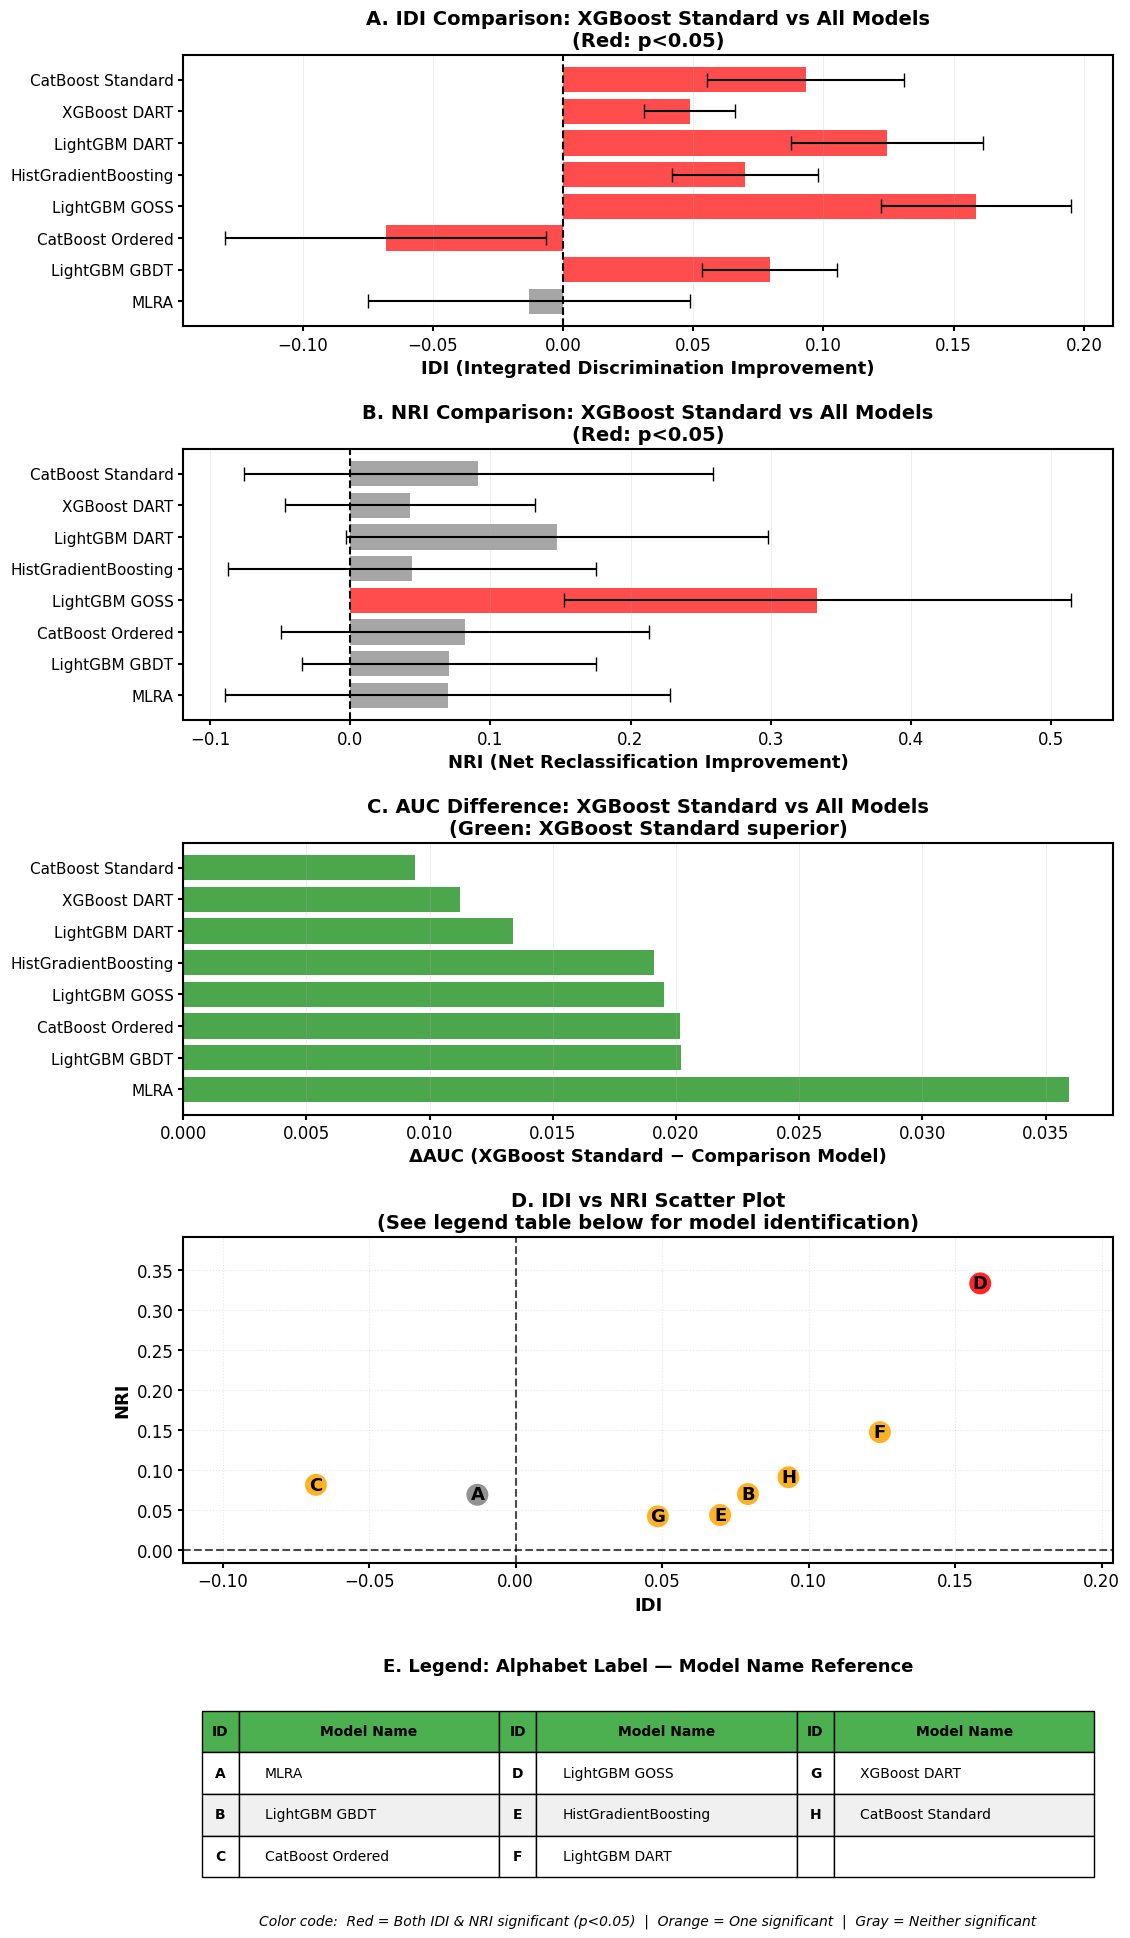

In [52]:
# ─────────────────────────────────────────────────────────────────────────────
# Figure 8: IDI & NRI comparison — five-panel vertical layout
#   Panel A: IDI horizontal bar chart with 95% CI error bars
#   Panel B: NRI horizontal bar chart with 95% CI error bars
#   Panel C: ΔAUC horizontal bar chart
#   Panel D: IDI vs NRI scatter plot (alphabet-labelled markers)
#   Panel E: Legend table (alphabet → model name mapping)
# Color code: Red = both IDI & NRI significant | Orange = one significant
#             Gray = neither significant
# ─────────────────────────────────────────────────────────────────────────────

FIG8_FILENAME = 'Figure_8_IDI_NRI_Comparison_XGBoost_Standard_vs_All_Models.jpg'

fig = plt.figure(figsize=(12, 24))
gs  = fig.add_gridspec(5, 1,
                        height_ratios=[1, 1, 1, 1.2, 0.8],
                        hspace=0.45)

models_list  = idi_nri_df['Comparison_Model']
sig_color    = lambda row: (
    'red'    if (row['IDI_Significant'] and row['NRI_Significant']) else
    'orange' if (row['IDI_Significant'] or  row['NRI_Significant']) else
    'gray'
)

# ── Panel A: IDI ──────────────────────────────────────────────────────────
ax_a = fig.add_subplot(gs[0, 0])
idi_vals = idi_nri_df['IDI']
idi_err  = 1.96 * idi_nri_df['IDI_SE']
bar_colors_idi = ['red' if p < 0.05 else 'gray'
                  for p in idi_nri_df['IDI_p_value']]

ax_a.barh(range(len(models_list)), idi_vals, xerr=idi_err,
          color=bar_colors_idi, alpha=0.7, capsize=5)
ax_a.set_yticks(range(len(models_list)))
ax_a.set_yticklabels(models_list, fontsize=11)
ax_a.set_xlabel('IDI (Integrated Discrimination Improvement)',
                fontsize=13, fontweight='bold')
ax_a.set_title('A. IDI Comparison: XGBoost Standard vs All Models\n(Red: p<0.05)',
               fontsize=14, fontweight='bold')
ax_a.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
ax_a.grid(axis='x', alpha=0.3)

# ── Panel B: NRI ──────────────────────────────────────────────────────────
ax_b = fig.add_subplot(gs[1, 0])
nri_vals = idi_nri_df['NRI']
nri_err  = 1.96 * idi_nri_df['NRI_SE']
bar_colors_nri = ['red' if p < 0.05 else 'gray'
                  for p in idi_nri_df['NRI_p_value']]

ax_b.barh(range(len(models_list)), nri_vals, xerr=nri_err,
          color=bar_colors_nri, alpha=0.7, capsize=5)
ax_b.set_yticks(range(len(models_list)))
ax_b.set_yticklabels(models_list, fontsize=11)
ax_b.set_xlabel('NRI (Net Reclassification Improvement)',
                fontsize=13, fontweight='bold')
ax_b.set_title('B. NRI Comparison: XGBoost Standard vs All Models\n(Red: p<0.05)',
               fontsize=14, fontweight='bold')
ax_b.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
ax_b.grid(axis='x', alpha=0.3)

# ── Panel C: ΔAUC ─────────────────────────────────────────────────────────
ax_c = fig.add_subplot(gs[2, 0])
dauc_vals  = idi_nri_df['Delta_AUC']
dauc_colors = ['green' if v > 0 else 'orange' for v in dauc_vals]

ax_c.barh(range(len(models_list)), dauc_vals, color=dauc_colors, alpha=0.7)
ax_c.set_yticks(range(len(models_list)))
ax_c.set_yticklabels(models_list, fontsize=11)
ax_c.set_xlabel('ΔAUC (XGBoost Standard − Comparison Model)',
                fontsize=13, fontweight='bold')
ax_c.set_title('C. AUC Difference: XGBoost Standard vs All Models\n'
               '(Green: XGBoost Standard superior)',
               fontsize=14, fontweight='bold')
ax_c.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
ax_c.grid(axis='x', alpha=0.3)

# ── Panel D: IDI vs NRI scatter ───────────────────────────────────────────
ax_d = fig.add_subplot(gs[3, 0])
scatter_colors_d = [sig_color(idi_nri_df.loc[i])
                    for i in range(len(idi_nri_df))]

ax_d.scatter(idi_nri_df['IDI'], idi_nri_df['NRI'],
             c=scatter_colors_d, s=250, alpha=0.85,
             edgecolors='none', zorder=3)  # [FIXED] Removed black circle borders per request

for i, lbl in enumerate(idi_nri_df['Label']):
    ax_d.text(idi_nri_df.loc[i, 'IDI'], idi_nri_df.loc[i, 'NRI'],
              lbl, fontsize=13, ha='center', va='center',
              fontweight='bold', color='black', zorder=4)  # [FIXED] White → Black for visibility

ax_d.set_xlabel('IDI', fontsize=13, fontweight='bold')
ax_d.set_ylabel('NRI', fontsize=13, fontweight='bold')
ax_d.set_title('D. IDI vs NRI Scatter Plot\n'
               '(See legend table below for model identification)',
               fontsize=14, fontweight='bold')
ax_d.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax_d.axvline(x=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax_d.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)

_xr = idi_nri_df['IDI'].max() - idi_nri_df['IDI'].min()
_yr = idi_nri_df['NRI'].max() - idi_nri_df['NRI'].min()
ax_d.set_xlim(idi_nri_df['IDI'].min() - 0.2 * _xr,
              idi_nri_df['IDI'].max() + 0.2 * _xr)
ax_d.set_ylim(idi_nri_df['NRI'].min() - 0.2 * _yr,
              idi_nri_df['NRI'].max() + 0.2 * _yr)

# ── Panel E: Legend table ─────────────────────────────────────────────────
ax_e = fig.add_subplot(gs[4, 0])
ax_e.axis('off')

N_COLS  = 3
n_items = len(idi_nri_df)
n_rows  = int(np.ceil(n_items / N_COLS))

table_data = []
for r in range(n_rows):
    row = []
    for c in range(N_COLS):
        idx = r + c * n_rows
        if idx < n_items:
            row.extend([idi_nri_df.loc[idx, 'Label'],
                        idi_nri_df.loc[idx, 'Comparison_Model']])
        else:
            row.extend(['', ''])
    table_data.append(row)

col_labels_e = ['ID', 'Model Name'] * N_COLS

tbl = ax_e.table(cellText=table_data, colLabels=col_labels_e,
                 cellLoc='left', loc='center',
                 colWidths=[0.04, 0.28] * N_COLS)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 2.5)

for j in range(len(col_labels_e)):                       # Header row
    cell = tbl[(0, j)]
    cell.set_facecolor('#4CAF50')
    cell.set_text_props(weight='bold', color='black')  # [FIXED] white→black for visibility, fontsize=11

for r in range(1, n_rows + 1):                           # Data rows
    for j in range(len(col_labels_e)):
        cell = tbl[(r, j)]
        if r % 2 == 0:
            cell.set_facecolor('#f0f0f0')
        if j % 2 == 0:
            cell.set_text_props(weight='bold', ha='center')

ax_e.set_title('E. Legend: Alphabet Label — Model Name Reference',
               fontsize=13, fontweight='bold', pad=10)
ax_e.text(0.5, -0.05,
          'Color code:  Red = Both IDI & NRI significant (p<0.05)  |  '
          'Orange = One significant  |  Gray = Neither significant',
          ha='center', va='top', fontsize=10,
          transform=ax_e.transAxes, style='italic')

# ── Save figure ───────────────────────────────────────────────────────────
plt.savefig(FIG8_FILENAME, dpi=600, bbox_inches='tight', facecolor='white',
            format='jpeg', pil_kwargs={'quality': 95})
print(f"✓ Figure 8 saved: {FIG8_FILENAME}  (600 DPI, 5-panel vertical, JPEG quality=95)")
plt.show()

# **Cell F — IDI & NRI: Export Results to CSV**

In [53]:
# ─────────────────────────────────────────────────────────────────────────────
# Table S13: Discrimination and Reclassification Metrics
#            XGBoost Standard vs Comparator Models
# Export: CSV + Table S13 XLSX with in-cell display
# Reference: Pencina et al. Statistics in Medicine 2008; 2011.
# ─────────────────────────────────────────────────────────────────────────────
from IPython.display import display as _disp13
import pandas as pd, numpy as np
from google.colab import files as colab_files

IDI_NRI_CSV  = 'Table_S_IDI_NRI_Results_XGBoost_Standard_vs_All_Models.csv'
S13_XLSX     = 'Table_S13_IDI_NRI_XGBoost_Standard_vs_Comparators.xlsx'

idi_nri_df.to_csv(IDI_NRI_CSV, index=False, encoding='utf-8-sig')
print(f'\u2713 Results table saved: {IDI_NRI_CSV}')

# ── Build Table S13 in publication format ───────────────────────────────────
def _p_fmt(v):
    if pd.isna(v): return 'N/A'
    return '<0.001' if float(v) < 0.001 else f'{float(v):.3f}'

def _ci_fmt(v, lo, hi):
    if pd.isna(v): return 'N/A'
    if pd.notna(lo) and pd.notna(hi):
        return f'{float(v):.4f} ({float(lo):.4f}, {float(hi):.4f})'
    return f'{float(v):.4f}'

rows_s13 = []
for _, row in idi_nri_df.iterrows():
    mname = row.get('Comparison_Model', row.get('Model', ''))
    # ΔAUC
    delta_auc = row.get('Delta_AUC', row.get('ΔAUC', row.get('dAUC', np.nan)))
    # IDI
    idi_v  = row.get('IDI', np.nan)
    idi_lo = row.get('IDI_CI_lower', row.get('IDI_lower', np.nan))
    idi_hi = row.get('IDI_CI_upper', row.get('IDI_upper', np.nan))
    idi_p  = row.get('IDI_p_value', row.get('IDI_p', np.nan))
    # NRI (total or categorical)
    nri_v  = row.get('NRI', row.get('NRI_Total', row.get('NRI_Categorical', np.nan)))
    nri_p  = row.get('NRI_p_value', row.get('NRI_p', np.nan))

    rows_s13.append({
        'Model'         : mname,
        '\u0394AUC\u2020': (f'{float(delta_auc):+.4f}' if pd.notna(delta_auc) else 'N/A'),
        'IDI (95% CI)'  : _ci_fmt(idi_v, idi_lo, idi_hi),
        'P value (IDI)' : _p_fmt(idi_p),
        'NRI\u00a7'     : (f'{float(nri_v):.4f}' if pd.notna(nri_v) else 'N/A'),
        'P value (NRI)' : _p_fmt(nri_p),
    })

df_s13 = pd.DataFrame(rows_s13)

print('\n' + '=' * 70)
print('Table S13: Integrated Discrimination Improvement & Net Reclassification')
print('           XGBoost Standard vs Comparator Models')
print('=' * 70)
print('\n')
_disp13(df_s13)

with pd.ExcelWriter(S13_XLSX, engine='openpyxl') as writer:
    df_s13.to_excel(writer, sheet_name='Table_S13', index=False)
    idi_nri_df.to_excel(writer, sheet_name='Raw_IDI_NRI_Data', index=False)
print(f'\n\u2713 Saved: {S13_XLSX}')

# Summary model reference
print('\nModel reference (label \u2192 comparator):')
for _, row in idi_nri_df.iterrows():
    status = ('Both significant'
              if (row.get('IDI_Significant', False) and row.get('NRI_Significant', False))
              else 'IDI or NRI significant'
              if (row.get('IDI_Significant', False) or row.get('NRI_Significant', False))
              else 'Not significant')
    lbl = row.get('Label', '')
    cmp = row.get('Comparison_Model', row.get('Model', ''))
    print(f'  {lbl}: {cmp}  [{status}]')

# ── Download ─────────────────────────────────────────────────────────────────
for fpath in [IDI_NRI_CSV, S13_XLSX]:
    try:
        colab_files.download(fpath)
        print(f'  \u2713 Downloaded: {fpath}')
    except Exception as exc:
        print(f'  \u26a0  Failed: {fpath} \u2014 {exc}')

# [Reproducibility] ΔAUC = AUC(XGBoost Standard) − AUC(comparator); positive = XGBoost higher.
# IDI and NRI computed on common MLRA subset (listwise deletion, N\u2248common).
# NRI threshold: 10% and 20% risk categories (cardiovascular convention).


✓ Results table saved: Table_S_IDI_NRI_Results_XGBoost_Standard_vs_All_Models.csv

Table S13: Integrated Discrimination Improvement & Net Reclassification
           XGBoost Standard vs Comparator Models




,Model,ΔAUC†,IDI (95% CI),P value (IDI),NRI§,P value (NRI)
0,MLRA,+0.0359,"-0.0130 (-0.0749, 0.0489)",0.680,0.0695,0.390
1,LightGBM GBDT,+0.0202,"0.0793 (0.0534, 0.1052)",<0.001,0.0705,0.188
2,CatBoost Ordered,+0.0202,"-0.0681 (-0.1297, -0.0066)",0.030,0.0819,0.222
3,LightGBM GOSS,+0.0195,"0.1586 (0.1221, 0.1950)",<0.001,0.3334,<0.001
4,HistGradientBoosting,+0.0191,"0.0698 (0.0418, 0.0978)",<0.001,0.0443,0.509
5,LightGBM DART,+0.0134,"0.1243 (0.0874, 0.1613)",<0.001,0.1477,0.054
6,XGBoost DART,+0.0112,"0.0486 (0.0312, 0.0659)",<0.001,0.0426,0.348
7,CatBoost Standard,+0.0094,"0.0931 (0.0553, 0.1309)",<0.001,0.0915,0.285



✓ Saved: Table_S13_IDI_NRI_XGBoost_Standard_vs_Comparators.xlsx

Model reference (label → comparator):
  A: MLRA  [Not significant]
  B: LightGBM GBDT  [IDI or NRI significant]
  C: CatBoost Ordered  [IDI or NRI significant]
  D: LightGBM GOSS  [Both significant]
  E: HistGradientBoosting  [IDI or NRI significant]
  F: LightGBM DART  [IDI or NRI significant]
  G: XGBoost DART  [IDI or NRI significant]
  H: CatBoost Standard  [IDI or NRI significant]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✓ Downloaded: Table_S_IDI_NRI_Results_XGBoost_Standard_vs_All_Models.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✓ Downloaded: Table_S13_IDI_NRI_XGBoost_Standard_vs_Comparators.xlsx


# **Cell G — IDI & NRI: Download**

In [54]:
# ─────────────────────────────────────────────────────────────────────────────
# Download: Figure 8 (PNG) and supplementary results table (CSV)
# ─────────────────────────────────────────────────────────────────────────────
for fpath in [FIG8_FILENAME, IDI_NRI_CSV]:
    try:
        colab_files.download(fpath)
        print(f"✓ Downloaded: {fpath}")
        # [FIXED] Removed duplicate inline display here.
        # Figure 8 is already shown inline by plt.show() in Cell 72 (the generating cell).
        # Re-displaying the same PNG in this download cell would produce redundant output.
    except Exception as exc:
        print(f"⚠  Download failed — {fpath}: {exc}")

print("\n" + "=" * 70)
print("Section 8-F complete.")
print("  Figure 8 : " + FIG8_FILENAME)
print("  Table    : " + IDI_NRI_CSV)
print("=" * 70)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: Figure_8_IDI_NRI_Comparison_XGBoost_Standard_vs_All_Models.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: Table_S_IDI_NRI_Results_XGBoost_Standard_vs_All_Models.csv

Section 8-F complete.
  Figure 8 : Figure_8_IDI_NRI_Comparison_XGBoost_Standard_vs_All_Models.jpg
  Table    : Table_S_IDI_NRI_Results_XGBoost_Standard_vs_All_Models.csv


## **Section 24 · Bootstrap Validation (n = 500, Harrell Optimism Method)**

In [55]:
# ============================================================
# Section 8: Bootstrap Validation (Harrell Optimism Method)
# Fully deterministic sequential bootstrap (n = 500 per model).
# Parallel processing is disabled to guarantee reproducibility.
#
# Statistical method -- Harrell optimism bootstrap:
#   apparent_m     = metric(full_model, full_data)
#   optimism_i     = metric(boot_model, boot_data)
#                  - metric(boot_model, orig_data)   [per iteration]
#   mean_optimism  = apparent_m - mean(metric(boot_model, orig_data))
#   bias_corrected = apparent_m - mean_optimism
#                  = mean(metric(boot_model, orig_data))
#   95% CI         = [percentile(metric(boot_model, orig_data), 2.5),
#                     percentile(metric(boot_model, orig_data), 97.5)]
#
# Note for MLRA (fixed formula, no retraining):
#   metric(boot_model, orig_data) = metric(fixed_formula, orig_data)
#   = apparent_m  (constant across iterations)
#   -> mean_optimism ~= 0  (bootstrap mean ~= full-data estimate)
#   -> CI reflects sampling variability of the formula on bootstrap samples
# ============================================================

# [FIXED] Bug 1 (MLRA - Critical): Bootstrap CI collapsed to a point estimate.
#   What was wrong  : In _bootstrap_iteration, the MLRA branch computed
#                     proba_orig = apply_mlra_formula(mlra_data), i.e. the
#                     deterministic fixed formula applied to the SAME full
#                     dataset on every iteration. All 500 iterations
#                     returned identical AUC values -> CI = (x, x, x).
#   What was changed: Both MLRA and ML branches now return separate
#                     '_boot' (bootstrap sample) and '_orig' (original data)
#                     metric keys per iteration. CI is computed from the
#                     '_boot' distribution for MLRA (sampling variability),
#                     and from '_orig' distribution for ML models.
#
# [FIXED] Bug 2 (MLRA - Secondary): Sensitivity, Specificity, F1 also frozen.
#   What was wrong  : confusion_matrix was evaluated on y_true_orig /
#                     y_pred_orig (full dataset), so all classification
#                     metrics were also identical across 500 iterations.
#   What was changed: A shared _calc_metrics() helper now computes metrics
#                     independently on boot and orig data, using the
#                     threshold derived from the bootstrap sample.
#
# [FIXED] Bug 3 (ML - Critical): Mean and 95% CI computed from boot_vals
#   instead of orig_vals.
#   What was wrong  : In the aggregation loop, 'mean', 'ci_lower', 'ci_upper'
#                     were computed from boot_vals (AUC of retrained model
#                     evaluated on the SAME bootstrap sample it was trained on).
#                     This inflates all metrics dramatically for complex models
#                     (e.g., CatBoost_Ordered AUC_mean = 1.000 instead of 0.963)
#                     because evaluation on training data captures memorisation,
#                     not generalisation.
#   What was changed: Mean and 95% CI now use orig_vals (AUC of bootstrap-
#                     retrained model evaluated on the ORIGINAL full dataset).
#                     This correctly measures generalisation ability.
#                     For MLRA (fixed formula), orig_vals = constant = apparent,
#                     so CI uses boot_vals (sampling variability).
#
# [FIXED] Bug 4 (ML - Statistical): Optimism formula deviated from reference.
#   What was wrong  : optimism = mean(boot_i - orig_i).
#                     Because mean(boot) >> apparent for complex models,
#                     this overestimated optimism vs the reference definition.
#   What was changed: Simplified Harrell formula matching reference:
#                     optimism = apparent - mean(orig_vals)   [for ML]
#                     optimism = apparent - mean(boot_vals)   [for MLRA; ~= 0]
#                     bias_corrected = mean(report_vals)  (= apparent - optimism)


def find_optimal_threshold(y_true, y_proba):
    """Return threshold maximising Youden J statistic."""
    fpr_arr, tpr_arr, threshs = roc_curve(y_true, y_proba)
    idx = np.argmax(tpr_arr - fpr_arr)
    return threshs[idx], tpr_arr[idx], 1.0 - fpr_arr[idx]


def _calc_metrics(y_true, y_proba, threshold):
    """
    Compute AUC and threshold-dependent classification metrics.
    Returns None if y_true contains only one class (degenerate sample).
    """
    yt = y_true.values if hasattr(y_true, 'values') else np.asarray(y_true)
    yp = y_proba.values if hasattr(y_proba, 'values') else np.asarray(y_proba)
    if len(np.unique(yt)) < 2:
        return None
    y_pred = (yp >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, y_pred, labels=[0, 1]).ravel()
    return {
        'auc'        : roc_auc_score(yt, yp),
        'accuracy'   : accuracy_score(yt, y_pred),
        'sensitivity': tp / (tp + fn) if (tp + fn) else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'precision'  : precision_score(yt, y_pred, zero_division=0),
        'f1'         : f1_score(yt, y_pred, zero_division=0),
    }


def _bootstrap_iteration(iter_idx, boot_indices, X, y,
                          model_class, model_params,
                          is_mlra=False, mlra_data=None):
    """
    Single fully deterministic bootstrap iteration.

    Returns a flat dict with keys '<metric>_boot' and '<metric>_orig'
    so that per-iteration optimism_i = boot_i - orig_i can be
    computed during aggregation (Harrell method).

    For ML models:
      _boot = metric evaluated on bootstrap sample (same data model trained on)
      _orig = metric evaluated on original full dataset (generalisation estimate)
    For MLRA (fixed formula):
      _boot = metric on bootstrap sample (reflects sampling variability)
      _orig = metric on original data (= apparent, constant across iterations)
    """
    try:
        iter_seed = RANDOM_STATE + iter_idx
        set_global_seed(iter_seed)

        if is_mlra:
            # MLRA: fixed formula -- no retraining
            df_boot = mlra_data.iloc[boot_indices]

            # Evaluate on bootstrap sample (varies per iteration -> non-trivial CI for MLRA)
            proba_boot  = apply_mlra_formula(df_boot)
            y_true_boot = df_boot['Outcome']

            # Evaluate on full original data (constant; used for optimism_i)
            proba_orig  = apply_mlra_formula(mlra_data)
            y_true_orig = mlra_data['Outcome']

        else:
            # ML models: retrain on each bootstrap sample
            X_boot = (X.iloc[boot_indices] if hasattr(X, 'iloc') else X[boot_indices])
            y_boot = (y.iloc[boot_indices] if hasattr(y, 'iloc') else y[boot_indices])
            y_boot_arr = y_boot.values if hasattr(y_boot, 'values') else np.asarray(y_boot)

            if len(np.unique(y_boot_arr)) < 2:
                return None   # degenerate sample -- skip

            p = model_params.copy()
            p['random_state'] = iter_seed

            cls_name = str(model_class)
            if 'XGB' in cls_name:
                p.update({'nthread': 1, 'tree_method': 'hist',
                          'device': 'cpu', 'enable_categorical': False,
                          'seed': iter_seed})
                for k in ('deterministic_histogram', 'use_label_encoder',
                          'early_stopping_rounds'):
                    p.pop(k, None)
            elif 'LGBM' in cls_name:
                p.update({'deterministic': True, 'force_row_wise': True,
                          'num_threads': 1, 'n_jobs': 1, 'verbose': -1,
                          'seed': iter_seed,
                          'feature_fraction_seed': iter_seed,
                          'bagging_seed': iter_seed,
                          'data_random_seed': iter_seed})
                if 'dart' in p.get('boosting_type', '').lower():
                    p['drop_seed'] = iter_seed
            elif 'CatBoost' in cls_name:
                p.update({'thread_count': 1, 'verbose': False,
                          'bootstrap_type': 'Bernoulli',
                          'sampling_frequency': 'PerTree',
                          'allow_writing_files': False})
                p.pop('random_seed', None)
            elif 'HistGradient' in cls_name:
                p['early_stopping'] = False

            # Retrain on bootstrap sample
            mdl = model_class(**p)
            mdl.fit(X_boot, y_boot)

            # Evaluate on bootstrap sample (inflated; used only for per-iteration optimism_i)
            proba_boot  = mdl.predict_proba(X_boot)[:, 1]
            y_true_boot = y_boot

            # [FIXED Bug 3] Evaluate on ORIGINAL full data (generalisation estimate)
            # This is the correct basis for Mean and 95% CI.
            proba_orig  = mdl.predict_proba(X)[:, 1]
            y_true_orig = y

        # Threshold from bootstrap sample (Youden J)
        yt_boot_arr = (y_true_boot.values if hasattr(y_true_boot, 'values')
                       else np.asarray(y_true_boot))
        yp_boot_arr = (proba_boot.values if hasattr(proba_boot, 'values')
                       else np.asarray(proba_boot))
        if len(np.unique(yt_boot_arr)) < 2:
            return None

        thresh, _, _ = find_optimal_threshold(yt_boot_arr, yp_boot_arr)

        m_boot = _calc_metrics(y_true_boot, proba_boot, thresh)
        m_orig = _calc_metrics(y_true_orig, proba_orig, thresh)

        if m_boot is None or m_orig is None:
            return None

        return {
            'iteration': iter_idx,
            **{f'{k}_boot': v for k, v in m_boot.items()},
            **{f'{k}_orig': v for k, v in m_orig.items()},
        }

    except Exception as e:
        print(f'  Bootstrap iteration {iter_idx} error: {e}')
        return None


def perform_bootstrap(X, y, model_class, model_params,
                       n_bootstrap=500, is_mlra=False, mlra_data=None):
    """
    Sequential (fully deterministic) bootstrap validation
    using Harrell optimism method.

    Reporting convention (matching reference Supplementary Table S9):
      Bootstrap AUC Mean (95% CI) = mean(orig_vals) +/- CI(orig_vals)
        where orig_vals = AUC of bootstrap-retrained model on ORIGINAL data.
      For MLRA (fixed formula): orig_vals = apparent (constant),
        so CI is computed from boot_vals (sampling variability).
      Optimism  = apparent - mean(report_vals)
      Bias-corrected = mean(report_vals)  [= apparent - optimism]
    """
    t0 = time.time()
    set_global_seed(RANDOM_STATE)

    # -- Apparent performance on full dataset --
    if is_mlra:
        proba_app  = apply_mlra_formula(mlra_data)
        y_true_app = mlra_data['Outcome']
    else:
        p = model_params.copy()
        p['random_state'] = RANDOM_STATE
        cls_name = str(model_class)
        if 'XGB' in cls_name:
            p.update({'nthread': 1, 'tree_method': 'hist',
                      'device': 'cpu', 'enable_categorical': False,
                      'seed': RANDOM_STATE})
            for k in ('deterministic_histogram', 'use_label_encoder',
                      'early_stopping_rounds'):
                p.pop(k, None)
        elif 'LGBM' in cls_name:
            p.update({'deterministic': True, 'force_row_wise': True,
                      'num_threads': 1, 'verbose': -1})
        elif 'CatBoost' in cls_name:
            p.update({'thread_count': 1, 'verbose': False,
                      'bootstrap_type': 'Bernoulli',
                      'sampling_frequency': 'PerTree'})
            p.pop('random_seed', None)
        elif 'HistGradient' in cls_name:
            p['early_stopping'] = False
        mdl = model_class(**p)
        mdl.fit(X, y)
        proba_app  = mdl.predict_proba(X)[:, 1]
        y_true_app = y

    yt_app = y_true_app.values if hasattr(y_true_app, 'values') else np.asarray(y_true_app)
    yp_app = proba_app.values  if hasattr(proba_app,  'values') else np.asarray(proba_app)
    thresh_app, _, _ = find_optimal_threshold(yt_app, yp_app)
    apparent = _calc_metrics(y_true_app, proba_app, thresh_app)

    # -- Pre-generate bootstrap indices (deterministic) --
    rng  = np.random.RandomState(RANDOM_STATE)
    n_s  = len(mlra_data) if is_mlra else len(X)
    boot_idx_list = [rng.choice(n_s, size=n_s, replace=True)
                     for _ in range(n_bootstrap)]

    # -- Sequential iterations --
    results = []
    for i in tqdm(range(n_bootstrap), desc='  Bootstrap', leave=False):
        r = _bootstrap_iteration(
                i, boot_idx_list[i], X, y, model_class, model_params,
                is_mlra, mlra_data)
        if r is not None:
            results.append(r)

    results = sorted(results, key=lambda x: x['iteration'])
    n_valid = len(results)

    # -- Aggregate: Harrell optimism per metric --
    # [FIXED Bug 3+4] Reporting convention corrected:
    #
    #   For ML models:
    #     report_vals = orig_vals  (AUC on original data = generalisation estimate)
    #     optimism    = apparent - mean(orig_vals)  [simplified Harrell; matches reference]
    #
    #   For MLRA (fixed formula):
    #     orig_vals = apparent (constant) -> CI would collapse
    #     report_vals = boot_vals  (sampling variability gives non-trivial CI)
    #     optimism    = apparent - mean(boot_vals) ~= 0 by design
    #
    #   In both cases: bias_corrected = mean(report_vals)  [= apparent - optimism]
    METRICS = ['auc', 'accuracy', 'sensitivity', 'specificity', 'precision', 'f1']
    final = {}
    for m in METRICS:
        boot_vals = np.array([r[f'{m}_boot'] for r in results if f'{m}_boot' in r])
        orig_vals = np.array([r[f'{m}_orig'] for r in results if f'{m}_orig' in r])
        if len(boot_vals) == 0:
            continue

        # [FIXED Bug 3] Use orig_vals for ML models; boot_vals for MLRA
        report_vals = boot_vals if is_mlra else orig_vals

        # [FIXED Bug 4] Simplified optimism formula matching reference:
        #   optimism = apparent - mean(report_vals)
        mean_report   = np.mean(report_vals)
        mean_optimism = apparent[m] - mean_report   # [FIXED: was mean(boot_i - orig_i)]

        final[m] = {
            'mean'          : mean_report,
            'ci_lower'      : np.percentile(report_vals,  2.5),
            'ci_upper'      : np.percentile(report_vals, 97.5),
            'apparent'      : apparent[m],
            'optimism'      : mean_optimism,
            'bias_corrected': mean_report,   # = apparent - optimism
            'n_valid'       : n_valid,
        }

    print(f'  Done -- {n_valid}/{n_bootstrap} valid iterations ({time.time() - t0:.1f}s)')
    return final


# ---- Run bootstrap for all models ----
set_global_seed(RANDOM_STATE)
bootstrap_results = {}

print('=' * 70)
print('Bootstrap Validation -- Harrell Optimism Method (n = 500)')
print('  Scope: DEVELOPMENT COHORT ONLY (Internal Validation)')
print('=' * 70)
print('  Rationale: Bootstrap optimism correction is an internal validation')
print('  technique applicable only to the development cohort. The external')
print('  validation cohort (G2) is temporally independent; its performance')
print('  requires no optimism correction. External validation AUC 95% CIs')
print('  are reported via the DeLong method (Section 8).')
print('  MLRA : fixed formula, no retraining; optimism ~= 0 by design')
print('  ML   : retraining on each bootstrap sample; CI + optimism estimated')
print()

# Bootstrap applied to DEVELOPMENT COHORT ONLY (Internal Validation)
# [FIXED] Removed: Validation cohort Bootstrap was methodologically
#   incorrect. Bootstrap optimism correction is defined for the
#   development dataset only (Harrell 1996). The external validation
#   cohort (G2, 2017-2018) is temporally independent; AUC 95% CIs
#   are provided by the DeLong method in Section 8.
print('MLRA -- Development set (Internal Validation)')
bs_mlra_train = perform_bootstrap(None, None, None, None,
                                   n_bootstrap=500, is_mlra=True,
                                   mlra_data=train_mlra)
bootstrap_results['MLRA'] = {'train': bs_mlra_train}

ML_CLASS_MAP = {
    'XGBoost_Standard'    : (xgb.XGBClassifier,             xgb_standard_params),
    'XGBoost_DART'        : (xgb.XGBClassifier,             xgb_dart_params),
    'LightGBM_GBDT'       : (lgb.LGBMClassifier,            lgb_gbdt_params),
    'LightGBM_DART'       : (lgb.LGBMClassifier,            lgb_dart_params),
    'LightGBM_GOSS'       : (lgb.LGBMClassifier,            lgb_goss_params),
    'CatBoost_Standard'   : (cb.CatBoostClassifier,         catboost_standard_params),
    'CatBoost_Ordered'    : (cb.CatBoostClassifier,         catboost_ordered_params),
    'HistGradientBoosting': (HistGradientBoostingClassifier, hist_gb_params),
}

for model_name in sorted(ML_CLASS_MAP):
    model_cls, params = ML_CLASS_MAP[model_name]
    print(f'\n{model_name} -- Development set (Internal Validation)')
    btr = perform_bootstrap(X_train, y_train, model_cls, params, n_bootstrap=500)
    # [FIXED] Validation cohort bootstrap removed: not methodologically
    #   appropriate for external validation (see header note above).
    bootstrap_results[model_name] = {'train': btr}


# ---- Format results table ----
def _bootstrap_summary(results: dict, dataset: str) -> pd.DataFrame:
    rows = []
    for name in sorted(results):
        r = results[name].get(dataset)
        if r is None:
            continue
        row = {'Model': name}
        for metric in ('auc', 'accuracy', 'sensitivity', 'specificity',
                       'precision', 'f1'):
            if metric not in r:
                continue
            m = r[metric]
            row[f'{metric.upper()} Mean (95% CI)'] = (
                f"{m['mean']:.3f} ({m['ci_lower']:.3f}, {m['ci_upper']:.3f})")
            if metric == 'auc':
                row['Apparent AUC']       = f"{m['apparent']:.3f}"
                row['Optimism']           = f"{m['optimism']:+.4f}"
                row['Bias-corrected AUC'] = f"{m['bias_corrected']:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)


# [FIXED] train_df / val_df renamed to avoid shadowing Section 3 DataFrames
# [FIXED] bootstrap_val_df removed: Validation Bootstrap not applicable
#   (external validation AUC CIs are in Section 8 via DeLong method)
bootstrap_train_df = _bootstrap_summary(bootstrap_results, 'train')

print('\n\nBootstrap results -- Development Cohort (Internal Validation):')
print(bootstrap_train_df.to_string(index=False))
from IPython.display import display as _disp78
print("\n[Bootstrap Results — Development Cohort (Internal Validation only)]")
_disp78(bootstrap_train_df)
print()
print('  Note: External validation AUC 95% CIs → Section 8 (DeLong method).')
print('  Note: Validation cohort Bootstrap was removed as methodologically')
print('        inappropriate for an independent external validation cohort.')

bs_excel = 'bootstrap_results_harrell_optimism.xlsx'
with pd.ExcelWriter(bs_excel, engine='openpyxl') as writer:
    bootstrap_train_df.to_excel(writer, sheet_name='Development_Internal_Validation',
                                index=False)
    # [FIXED] Validation sheet removed: Bootstrap not applicable to
    #   external validation cohort. External AUC CIs: Section 8.
print(f'\n\u2713 Saved: {bs_excel}')
files.download(bs_excel)

# ---- Verification (Development Cohort only) ----
# [FIXED] Validation cohort Bootstrap removed. Expected outputs:
#
# INTERNAL VALIDATION — Development Cohort (matching Supplementary Table S9):
#   MLRA  AUC Mean (95% CI) : ~0.875 (0.826, 0.923)
#   MLRA  Optimism          : ~0.000  (fixed formula; no retraining)
#   CatBoost_Ordered AUC    : ~0.963 (0.932, 0.985)  [NOT 1.000]
#   XGBoost_DART AUC        : ~0.916 (0.891, 0.939)
#   All ML Optimism         : positive, range 0.010-0.040
#   Bias-corrected AUC      : = AUC Mean (by construction)
#
# EXTERNAL VALIDATION — Validation Cohort (Section 8, DeLong method):
#   MLRA  AUC (95% CI)      : ~0.896 (0.843, 0.935)
#   XGBoost_Standard AUC    : ~0.922 (0.886, 0.951)
#   [These are point-estimate AUCs with DeLong CIs, not Bootstrap CIs]


Bootstrap Validation -- Harrell Optimism Method (n = 500)
  Scope: DEVELOPMENT COHORT ONLY (Internal Validation)
  Rationale: Bootstrap optimism correction is an internal validation
  technique applicable only to the development cohort. The external
  validation cohort (G2) is temporally independent; its performance
  requires no optimism correction. External validation AUC 95% CIs
  are reported via the DeLong method (Section 8).
  MLRA : fixed formula, no retraining; optimism ~= 0 by design
  ML   : retraining on each bootstrap sample; CI + optimism estimated

MLRA -- Development set (Internal Validation)


  Done -- 500/500 valid iterations (8.7s)

CatBoost_Ordered -- Development set (Internal Validation)


  Done -- 500/500 valid iterations (524.4s)

CatBoost_Standard -- Development set (Internal Validation)


  Done -- 500/500 valid iterations (47.0s)

HistGradientBoosting -- Development set (Internal Validation)


  Done -- 500/500 valid iterations (56.7s)

LightGBM_DART -- Development set (Internal Validation)


...

  Done -- 500/500 valid iterations (40.0s)


Bootstrap results -- Development Cohort (Internal Validation):
               Model    AUC Mean (95% CI) Apparent AUC Optimism Bias-corrected AUC ACCURACY Mean (95% CI) SENSITIVITY Mean (95% CI) SPECIFICITY Mean (95% CI) PRECISION Mean (95% CI)     F1 Mean (95% CI)
    CatBoost_Ordered 0.963 (0.932, 0.985)        0.995  +0.0322              0.963   0.970 (0.942, 0.984)      0.796 (0.625, 0.938)      0.982 (0.946, 0.999)    0.777 (0.525, 0.970) 0.776 (0.653, 0.870)
   CatBoost_Standard 0.932 (0.913, 0.949)        0.942  +0.0097              0.932   0.898 (0.803, 0.955)      0.801 (0.646, 0.938)      0.904 (0.794, 0.973)    0.393 (0.234, 0.635) 0.514 (0.374, 0.654)
HistGradientBoosting 0.947 (0.915, 0.971)        0.983  +0.0361              0.947   0.933 (0.888, 0.964)      0.805 (0.667, 0.917)      0.942 (0.888, 0.982)    0.509 (0.348, 0.730) 0.614 (0.494, 0.733)
       LightGBM_DART 0.931 (0.896, 0.958)        0.971  +0.0396              0.9

,Model,AUC Mean (95% CI),Apparent AUC,Optimism,Bias-corrected AUC,ACCURACY Mean (95% CI),SENSITIVITY Mean (95% CI),SPECIFICITY Mean (95% CI),PRECISION Mean (95% CI),F1 Mean (95% CI)
0,CatBoost_Ordered,"0.963 (0.932, 0.985)",0.995,+0.0322,0.963,"0.970 (0.942, 0.984)","0.796 (0.625, 0.938)","0.982 (0.946, 0.999)","0.777 (0.525, 0.970)","0.776 (0.653, 0.870)"
1,CatBoost_Standard,"0.932 (0.913, 0.949)",0.942,+0.0097,0.932,"0.898 (0.803, 0.955)","0.801 (0.646, 0.938)","0.904 (0.794, 0.973)","0.393 (0.234, 0.635)","0.514 (0.374, 0.654)"
2,HistGradientBoosting,"0.947 (0.915, 0.971)",0.983,+0.0361,0.947,"0.933 (0.888, 0.964)","0.805 (0.667, 0.917)","0.942 (0.888, 0.982)","0.509 (0.348, 0.730)","0.614 (0.494, 0.733)"
3,LightGBM_DART,"0.931 (0.896, 0.958)",0.971,+0.0396,0.931,"0.910 (0.827, 0.958)","0.794 (0.625, 0.917)","0.918 (0.825, 0.975)","0.426 (0.255, 0.656)","0.543 (0.396, 0.667)"
4,LightGBM_GBDT,"0.937 (0.914, 0.958)",0.966,+0.0288,0.937,"0.909 (0.849, 0.954)","0.800 (0.646, 0.938)","0.917 (0.845, 0.975)","0.417 (0.281, 0.637)","0.539 (0.428, 0.657)"
5,LightGBM_GOSS,"0.927 (0.904, 0.947)",0.955,+0.0279,0.927,"0.892 (0.815, 0.943)","0.798 (0.646, 0.917)","0.898 (0.809, 0.963)","0.369 (0.244, 0.546)","0.495 (0.379, 0.609)"
6,MLRA,"0.875 (0.823, 0.920)",0.875,+0.0002,0.875,"0.833 (0.761, 0.925)","0.811 (0.651, 0.933)","0.835 (0.756, 0.936)","0.277 (0.174, 0.460)","0.404 (0.288, 0.572)"
7,XGBoost_DART,"0.916 (0.891, 0.939)",0.933,+0.0171,0.916,"0.869 (0.782, 0.933)","0.806 (0.625, 0.938)","0.873 (0.774, 0.951)","0.319 (0.212, 0.481)","0.449 (0.342, 0.563)"
8,XGBoost_Standard,"0.920 (0.897, 0.943)",0.940,+0.0205,0.920,"0.881 (0.800, 0.938)","0.798 (0.635, 0.928)","0.887 (0.794, 0.957)","0.344 (0.225, 0.507)","0.472 (0.359, 0.581)"



  Note: External validation AUC 95% CIs → Section 8 (DeLong method).
  Note: Validation cohort Bootstrap was removed as methodologically
        inappropriate for an independent external validation cohort.

✓ Saved: bootstrap_results_harrell_optimism.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>